In [17]:
import qiskit
import qiskit_ibm_runtime
import pylatexenc

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.circuit import Parameter
from qiskit.circuit.library import UGate
from qiskit.circuit.library import RXGate
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
from qiskit.primitives import StatevectorEstimator

import numpy as np
from numpy import pi

from itertools import product

from matplotlib import pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm

# generate pop-up plot
# from pytplot import get_data
# %matplotlib tk

import logging
import itertools
from matplotlib.backends.backend_pdf import PdfPages

In [3]:
# suppress the long comment for running generate_preset_pass_manager(optimization_level=1)
qiskit_logger = logging.getLogger('qiskit')
qiskit_logger.setLevel(logging.WARNING)

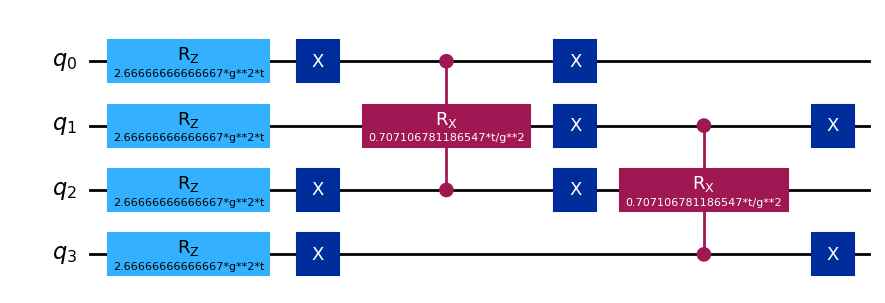

In [5]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step_new(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(theta_E/N, q)

    for i in range(1, n - 1):       
        qc.x(i - 1)
        qc.x(i + 1)
        
        controlled_rx = RXGate(theta_B/N).control(2)  # 2 control qubits
        qc.append(controlled_rx, [i - 1, i + 1, i])

        qc.x(i - 1)
        qc.x(i + 1)
        
    return qc

def N_steps_compose_new(n, N):
    one_step_circuit = one_step_new(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

n = 4
N = 1
circuit = N_steps_compose_new(n, N)
circuit.draw("mpl")

In [33]:
pauli_ops = ['I', 'X', 'Y', 'Z']
observables = [''.join(p) for p in itertools.product(pauli_ops, repeat=4)]
print(len(observables))

256


In [9]:
def plot_measurement_loop_one_observable(n, N, observable, t=1.0):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        SparsePauliOp(observable).apply_layout(isa_circuit.layout)
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, t])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = N
    return labels, values

In [11]:
def exp_val_given_T_one_axis(T=1.0, N=40, observable="ZZI", n=4, save_fig=False):
    exp_vals = []
    N_s = np.arange(1, N+1, 1)
    t_s = T / N_s
    for t, N in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable(n, N, observable, t)[1][0]
        exp_vals.append(exp_val)

    fig = plt.figure(figsize=(12, 5))
    plt.plot(N_s, exp_vals, "o-")
    plt.xlabel("N")
    plt.ylabel(f"{observable} Expectation Value")
    plt.xticks(np.arange(0, N + 1, 5))
    plt.title(f"Expectation vs N (top axis: t = 1/N)")
    plt.grid(True)   
    plt.tight_layout()
    if save_fig == True:
        plt.savefig(f"{observable}.png")
    plt.show()

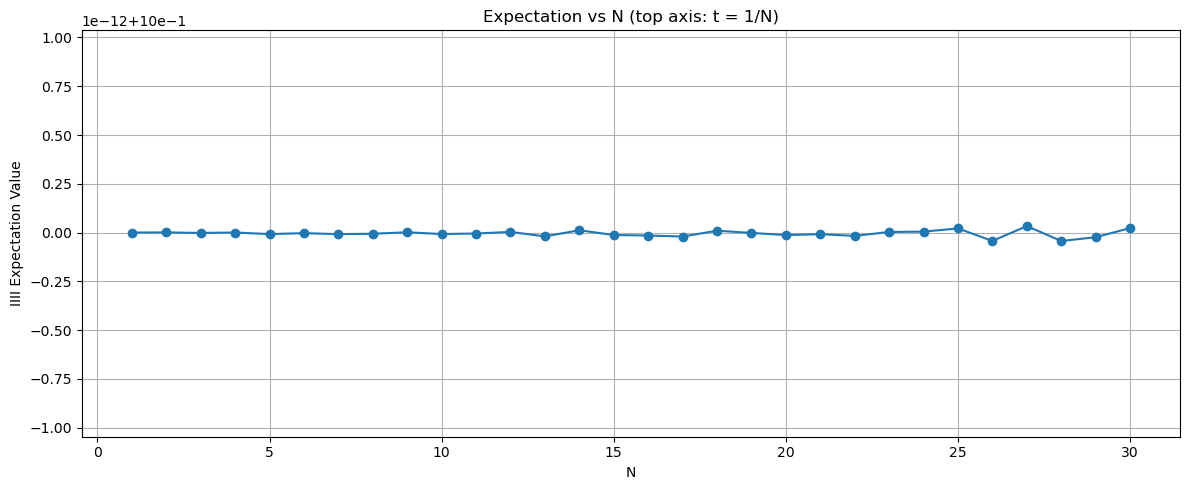

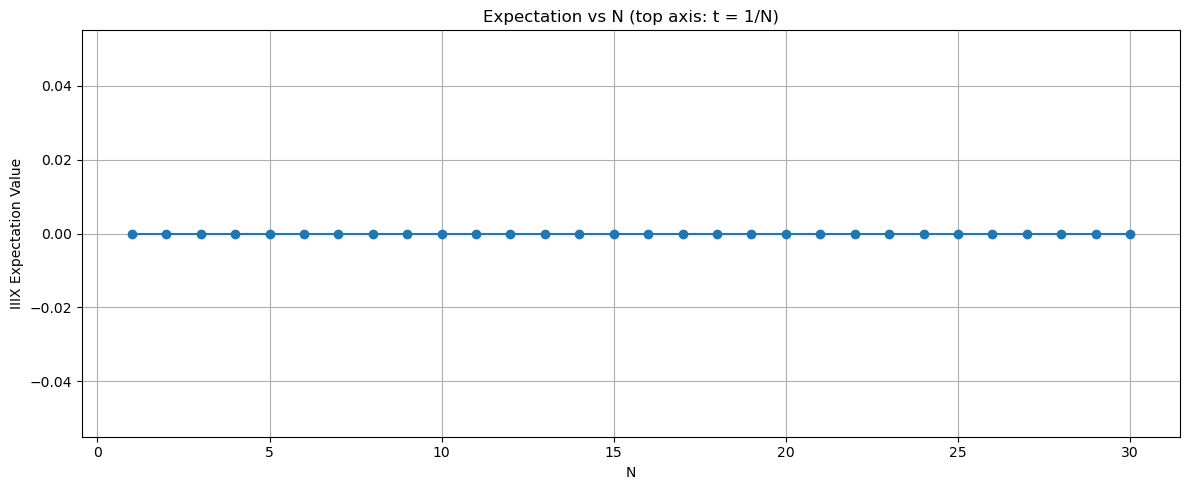

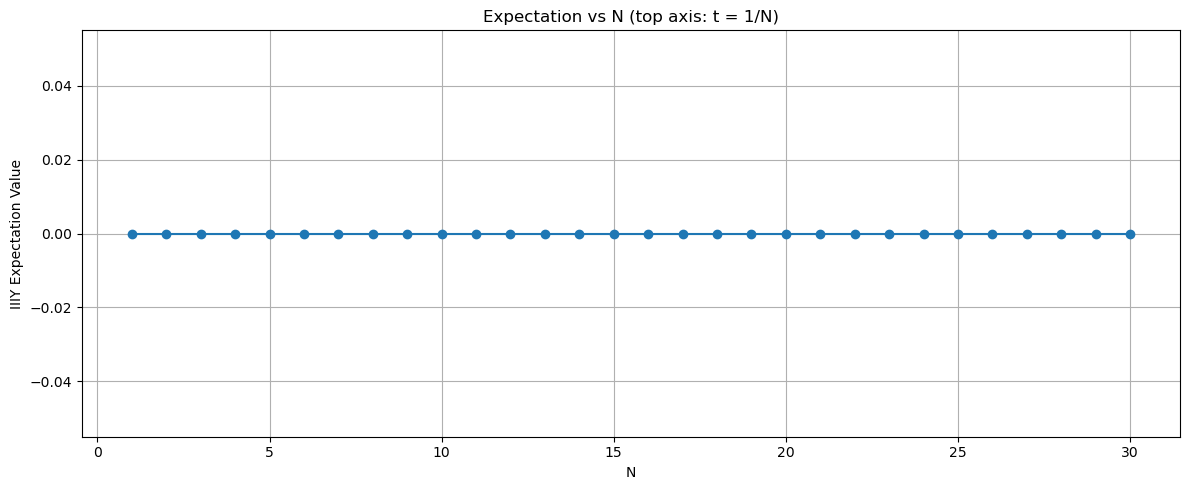

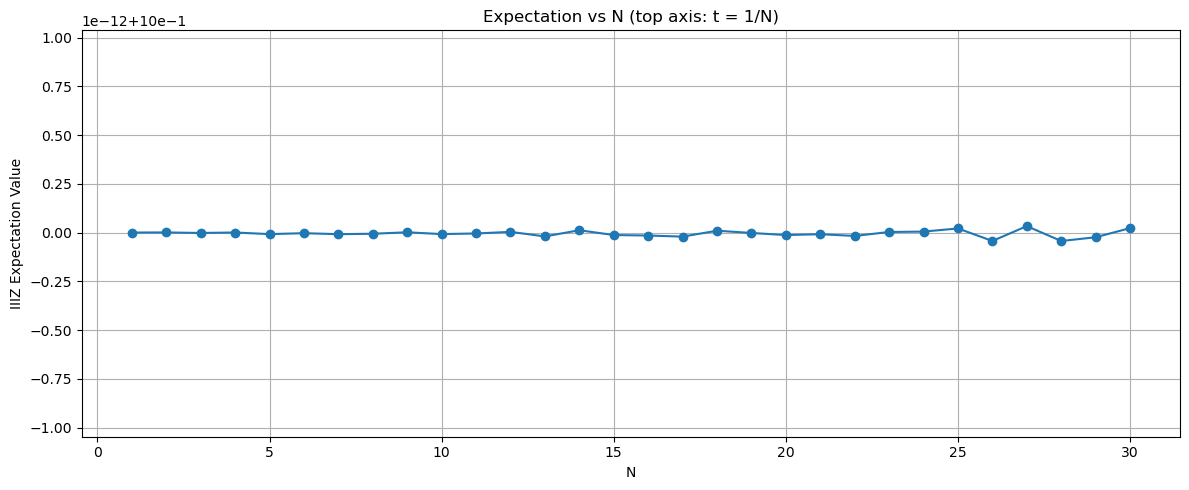

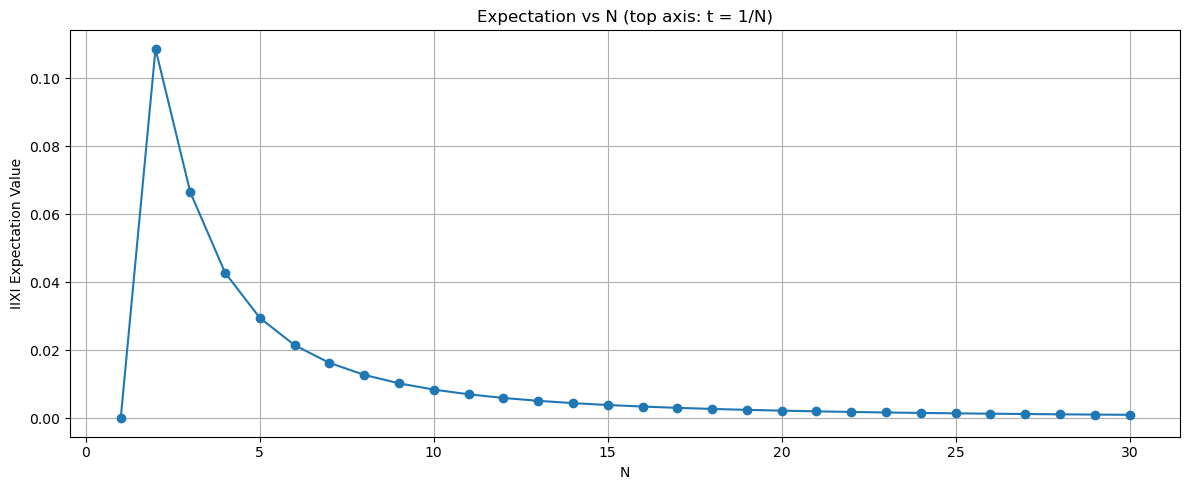

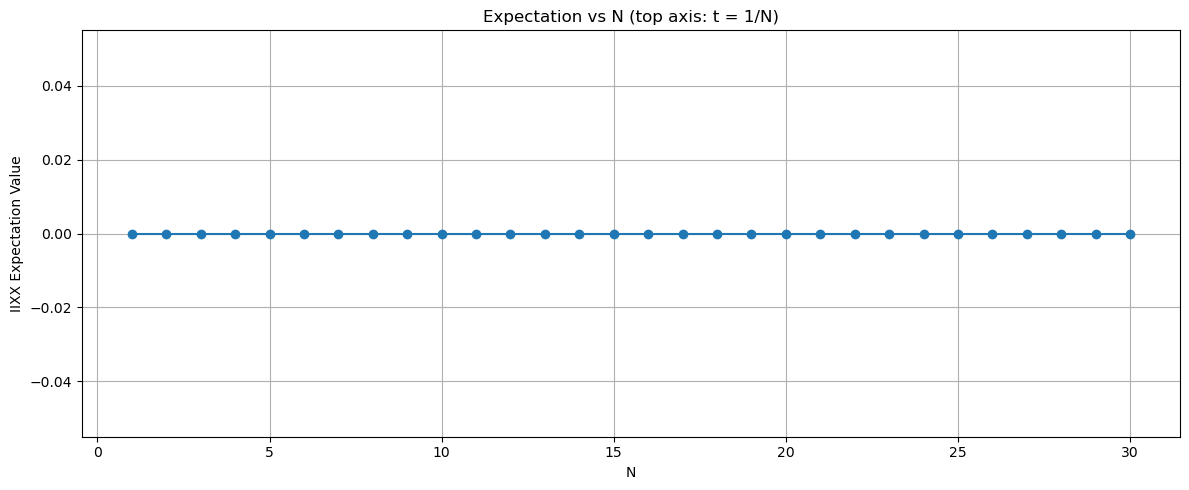

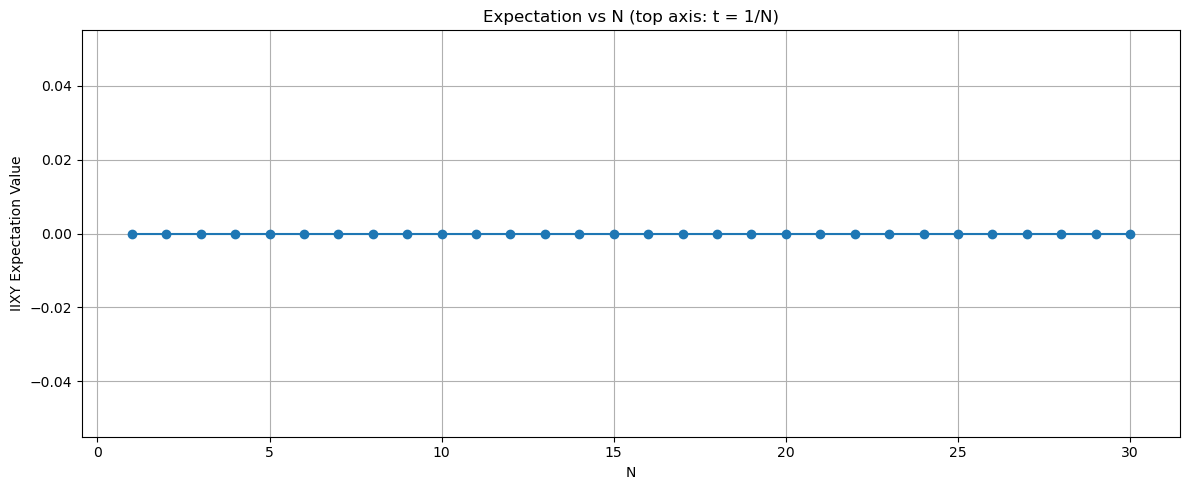

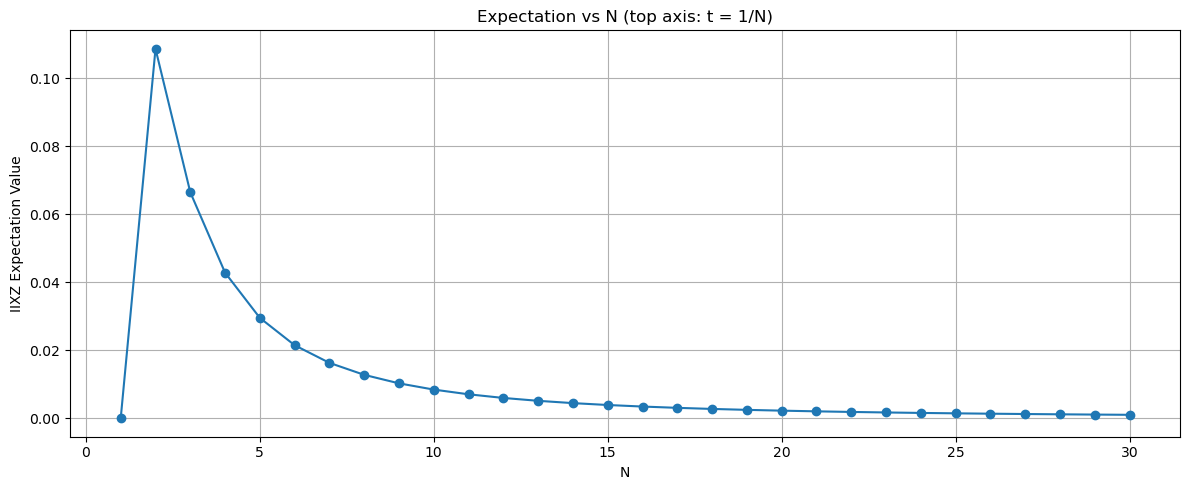

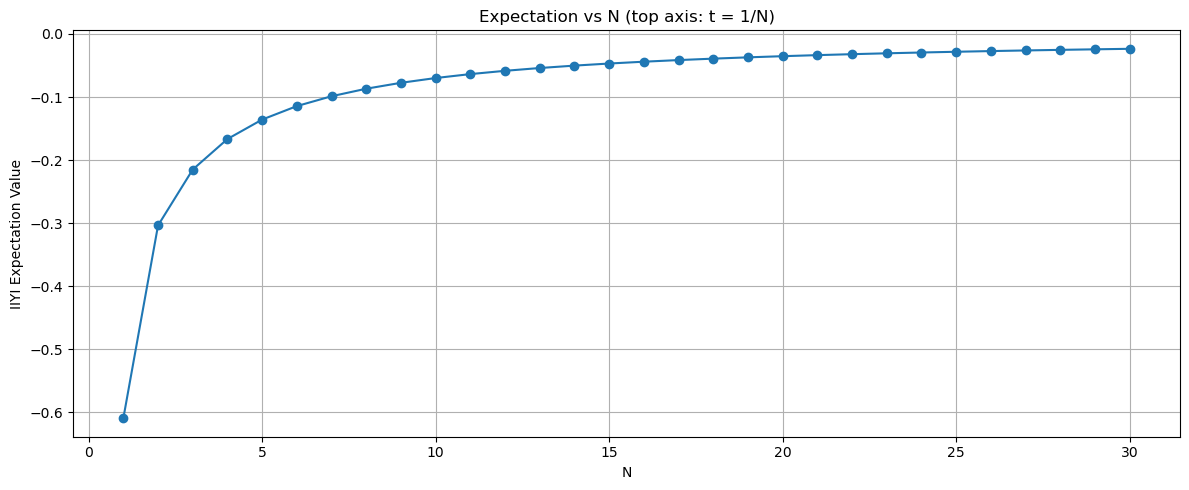

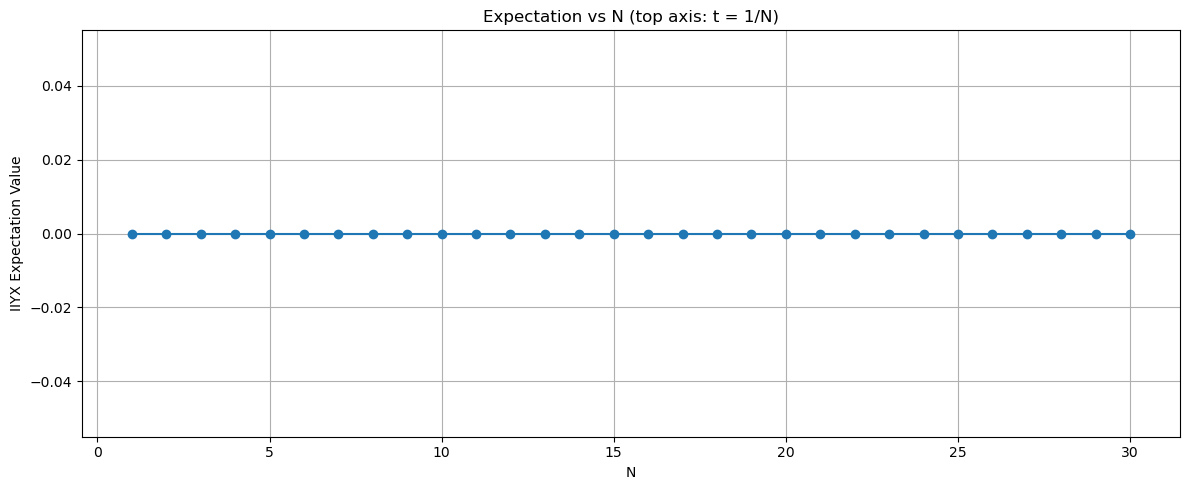

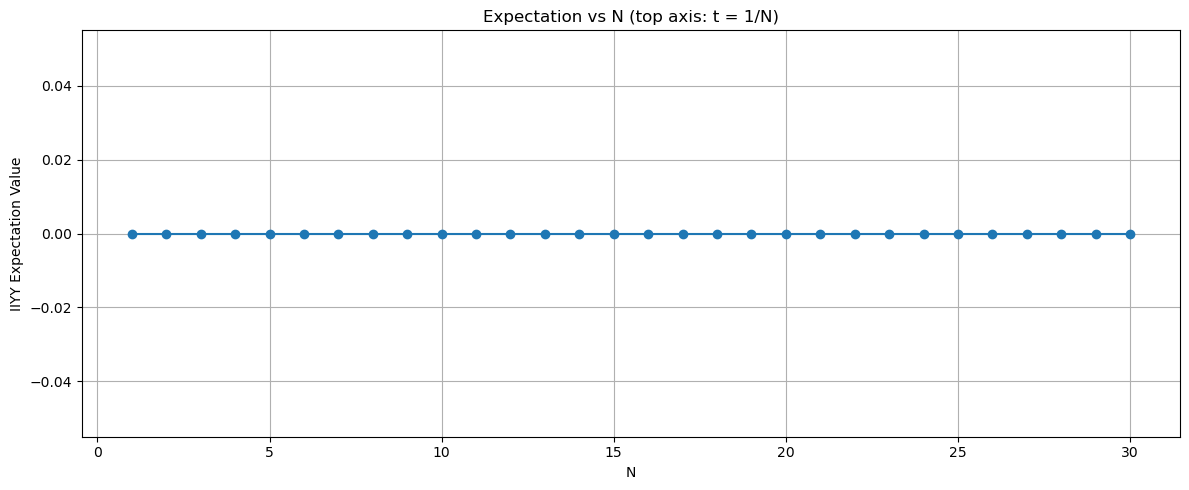

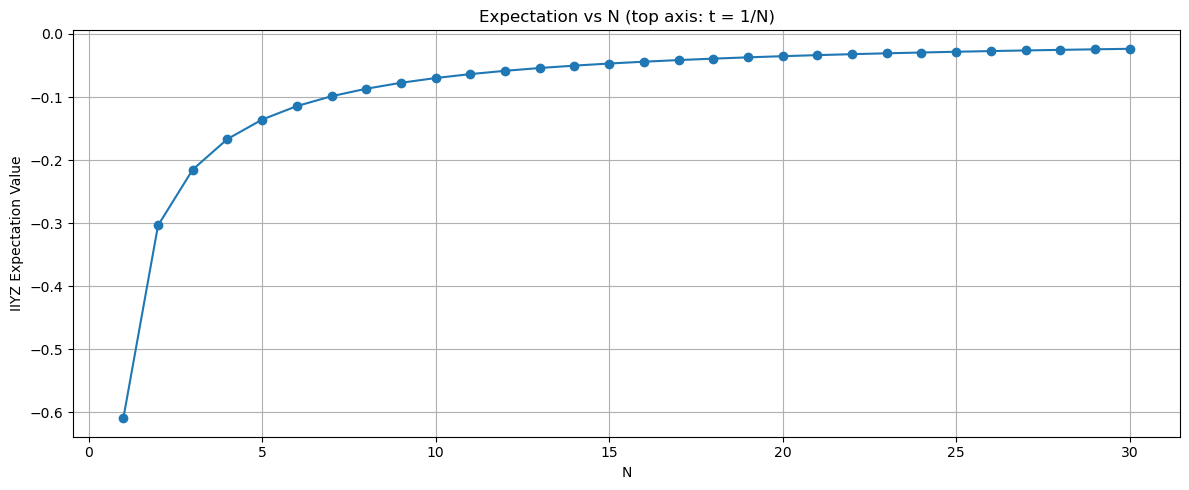

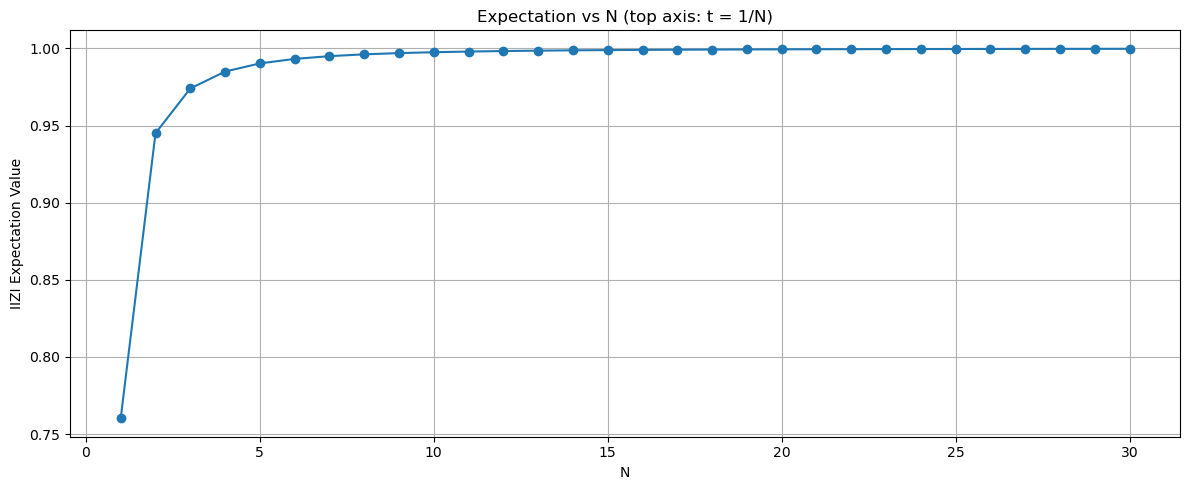

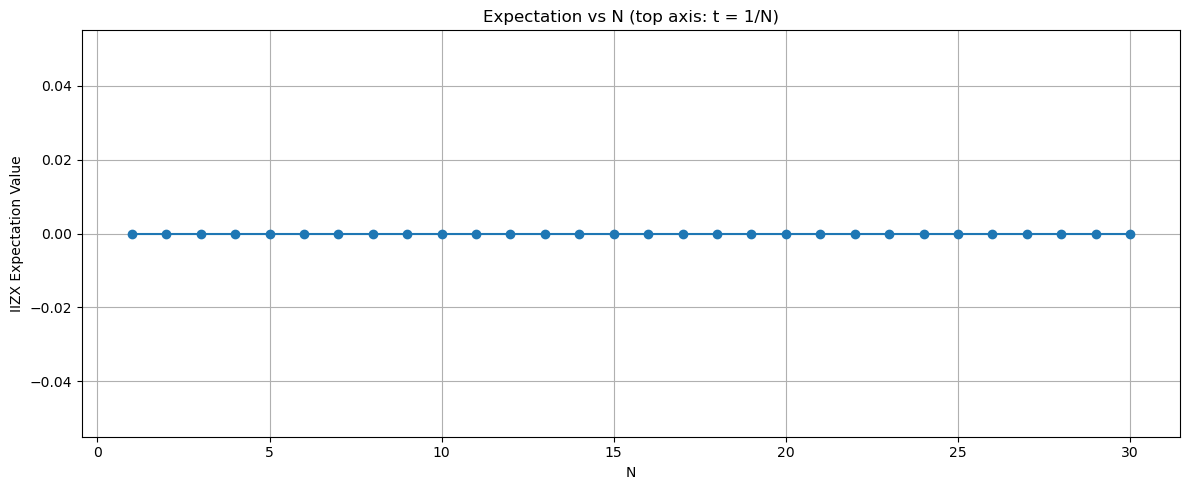

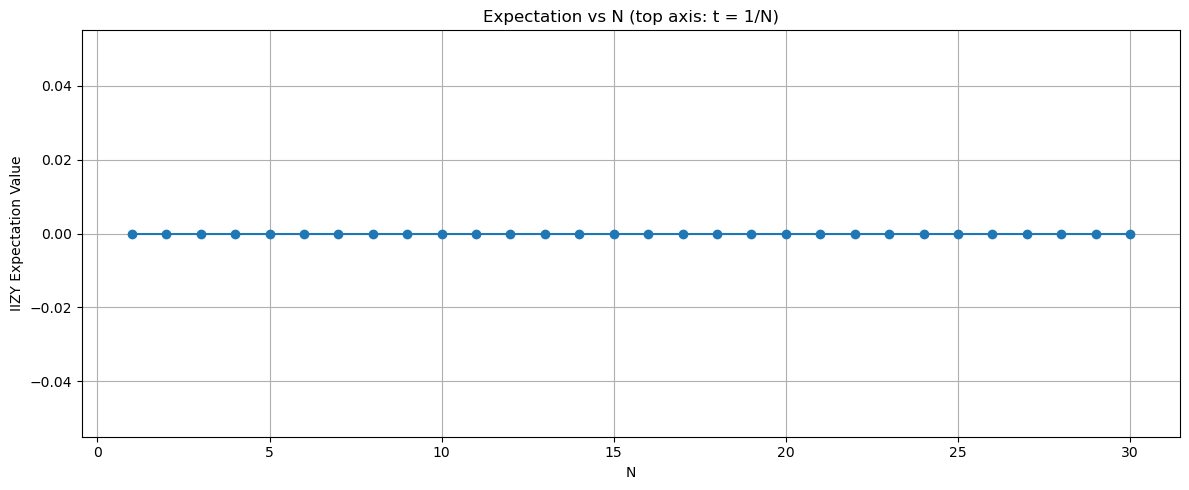

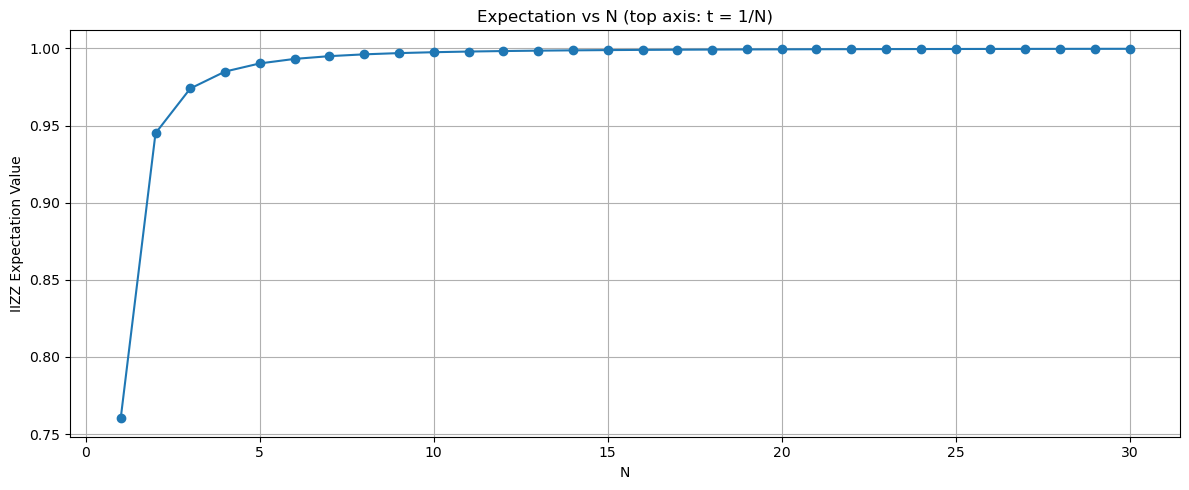

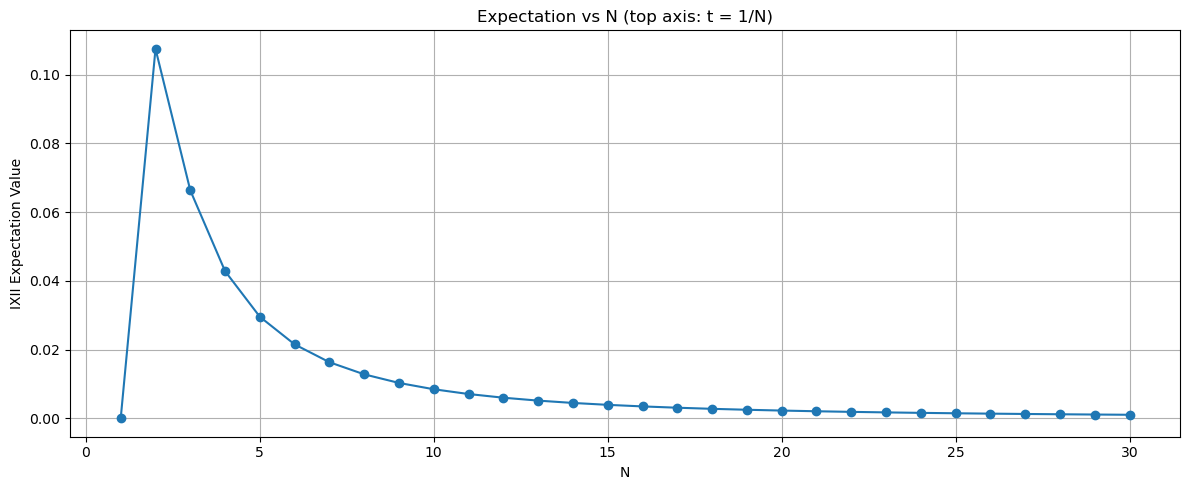

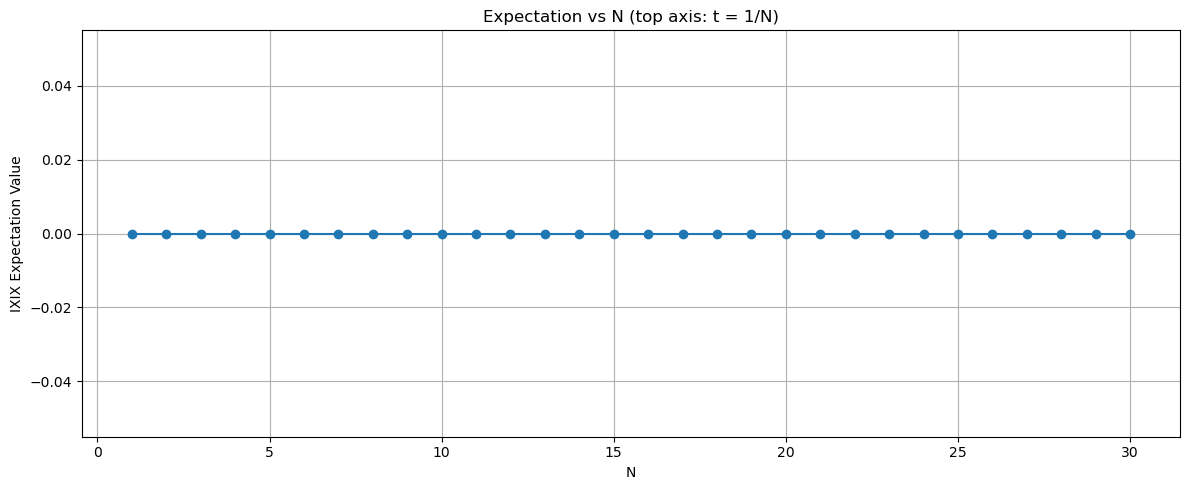

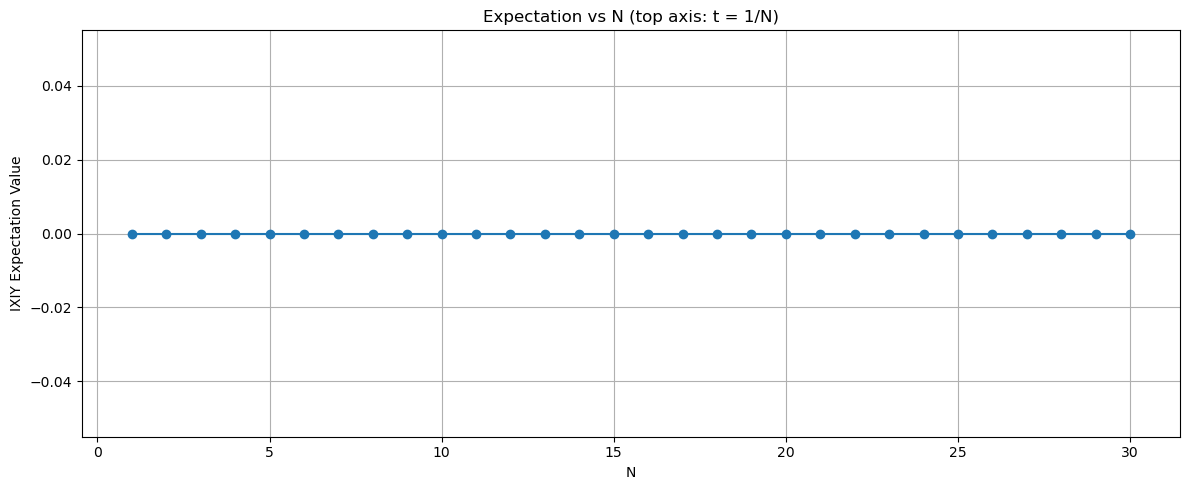

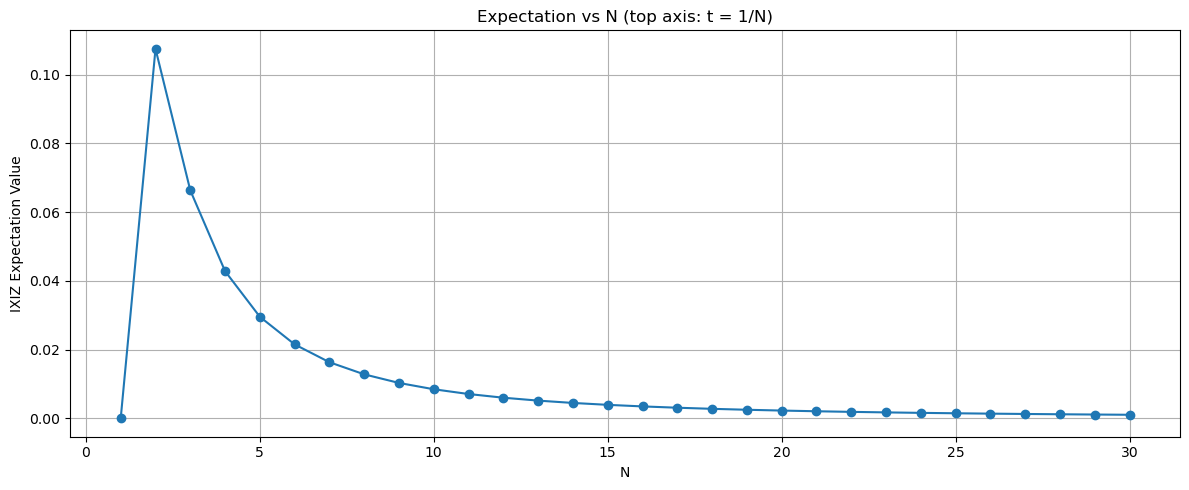

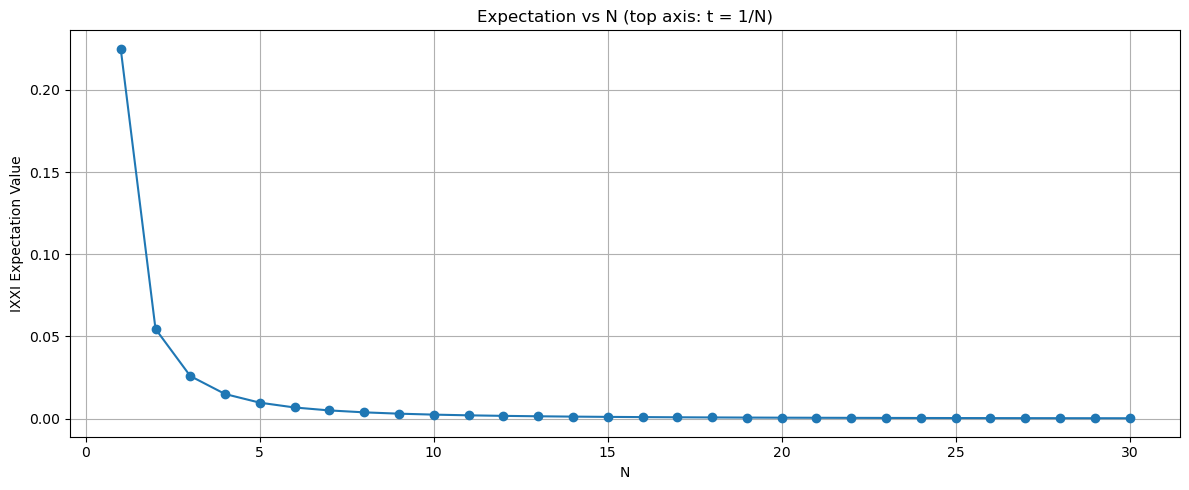

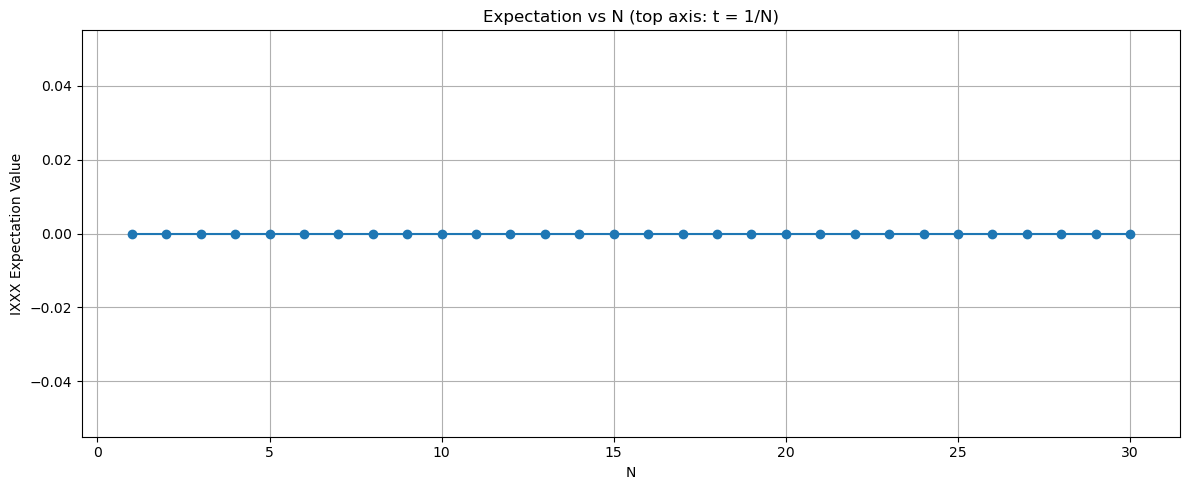

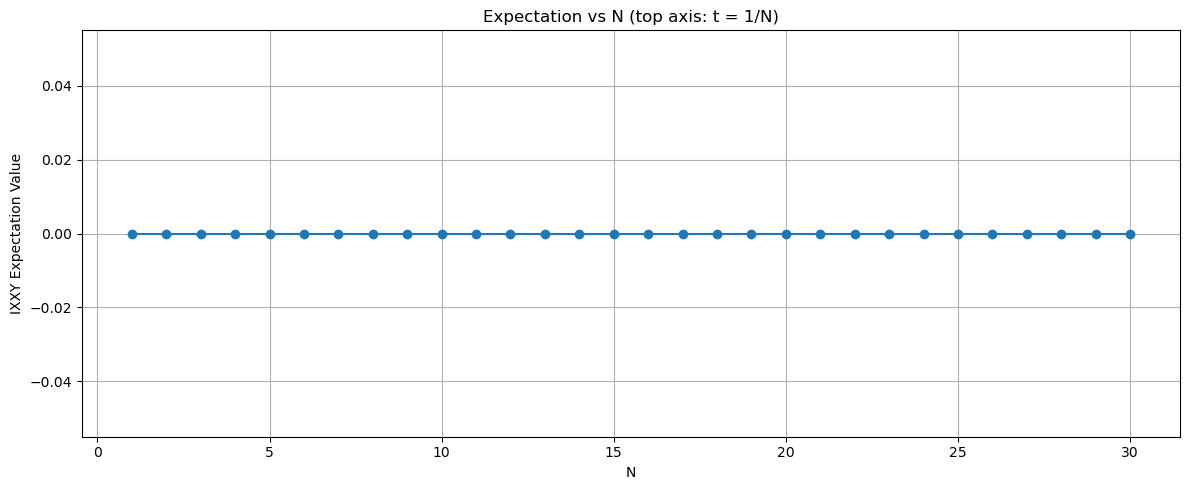

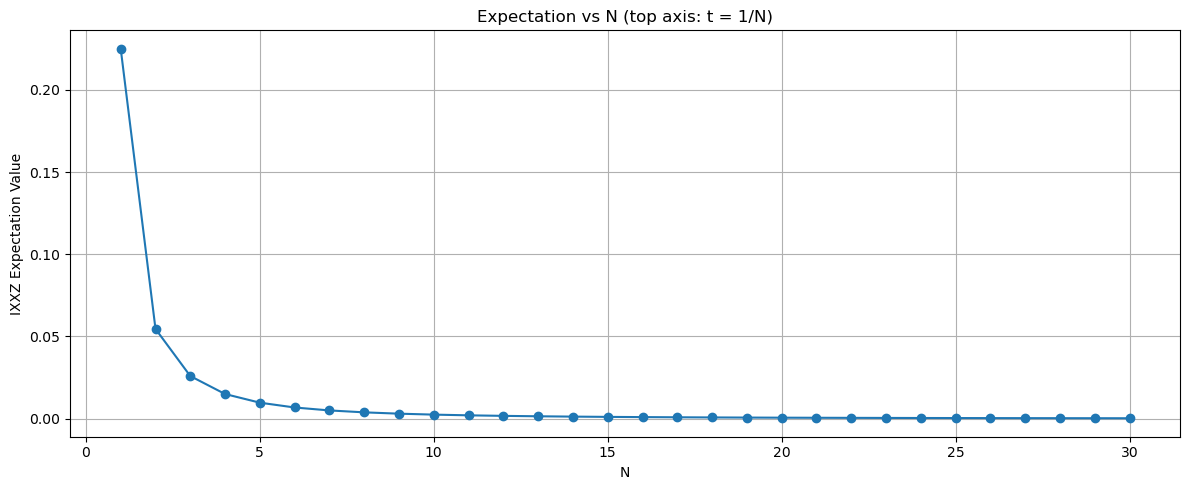

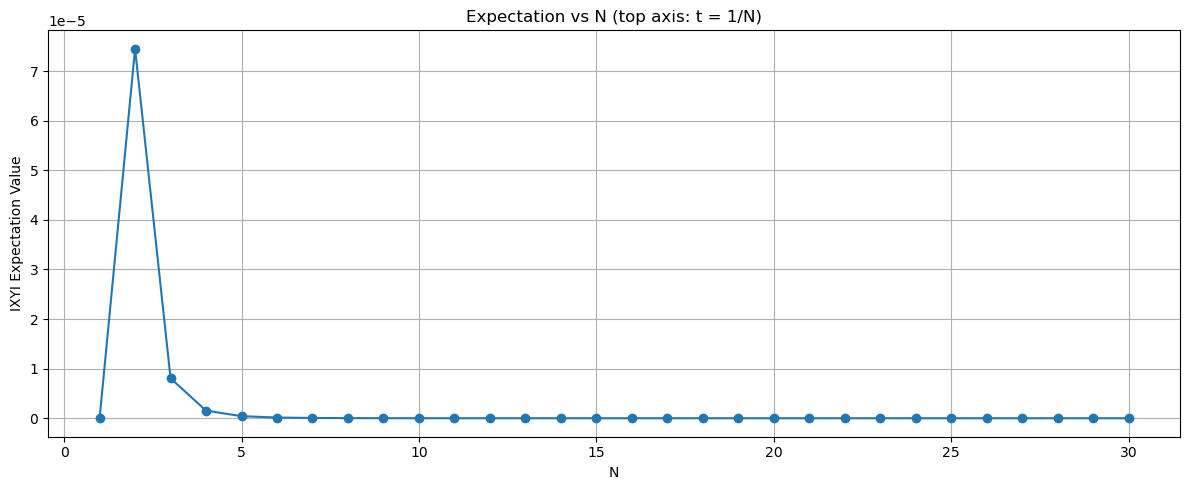

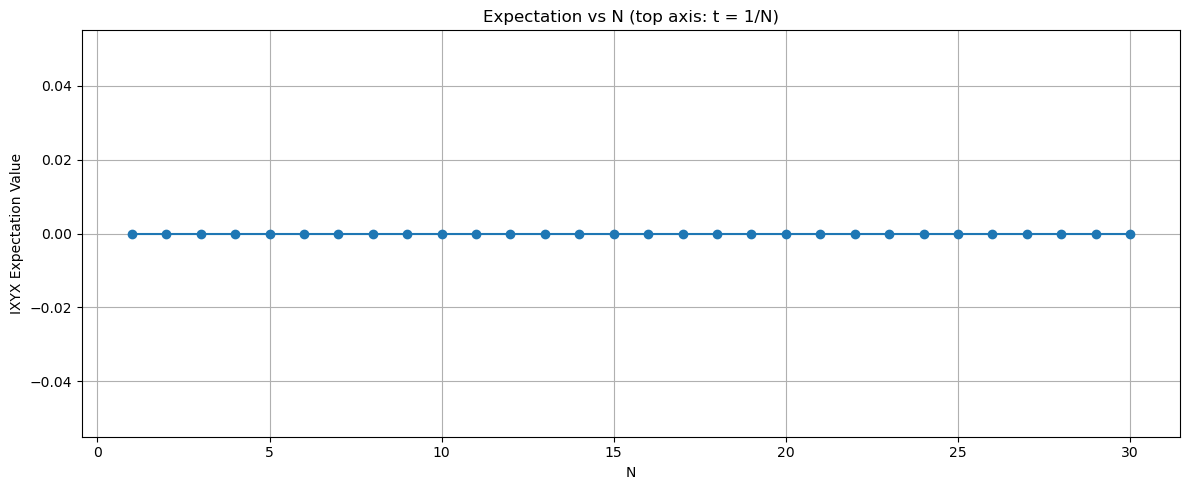

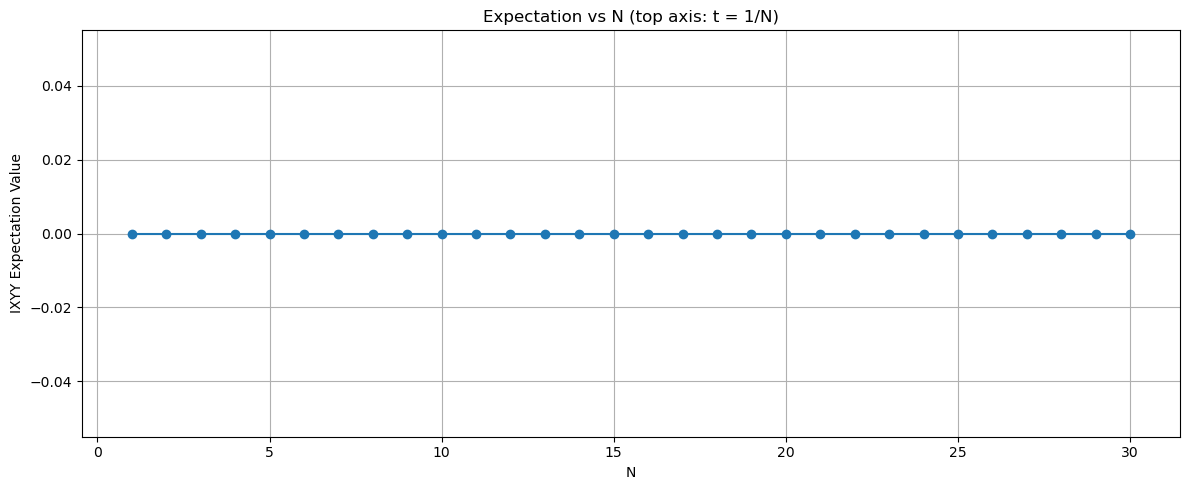

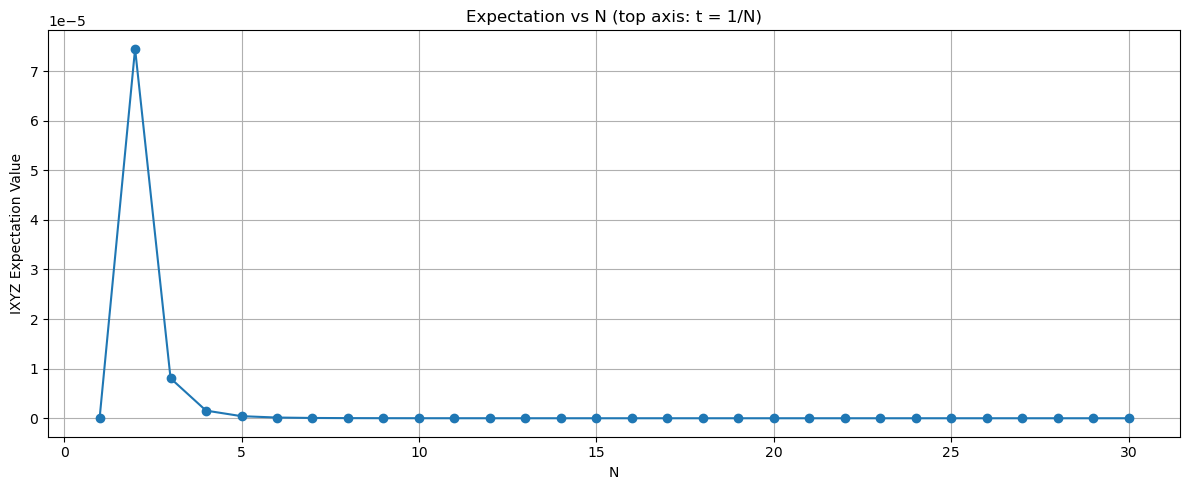

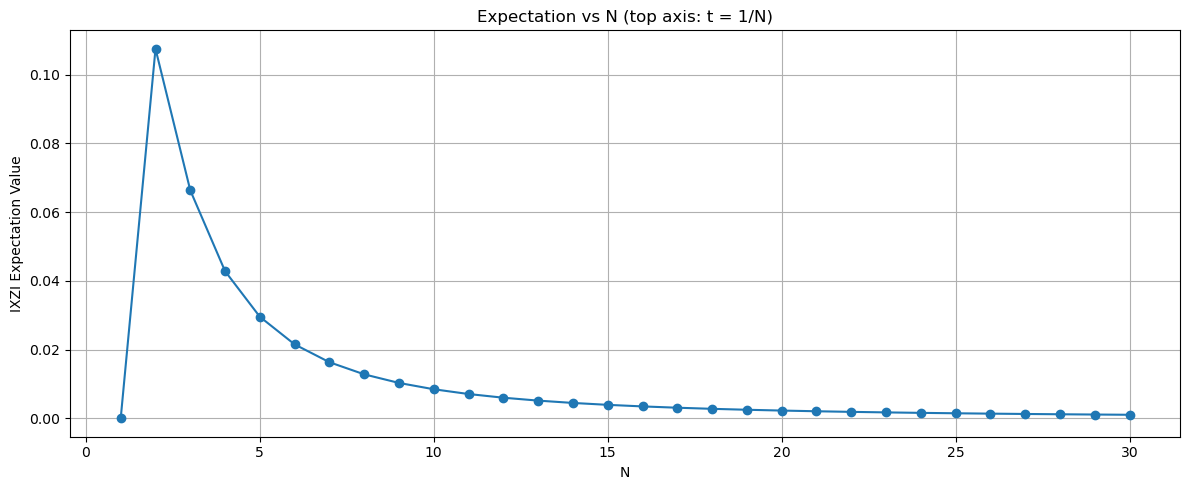

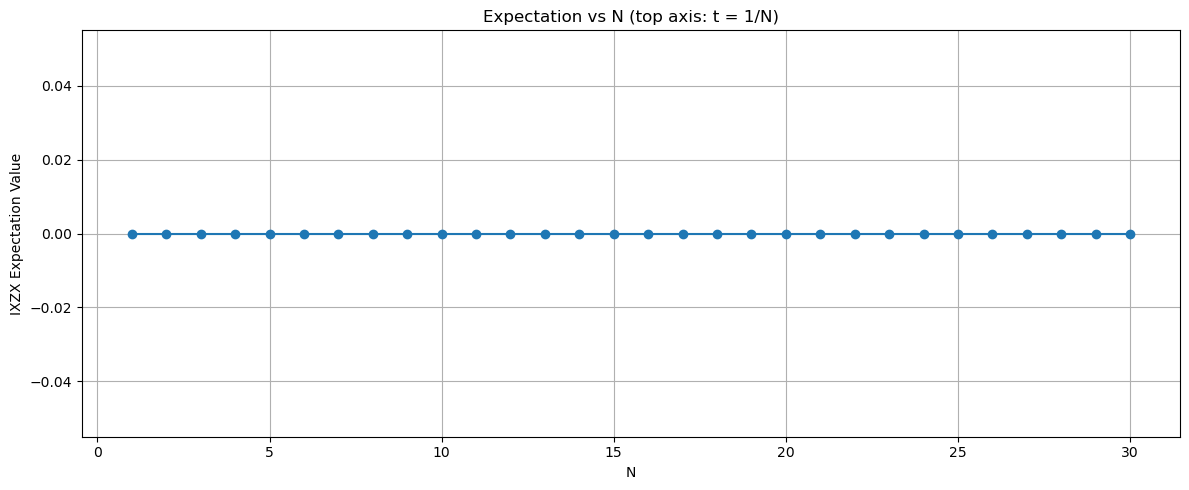

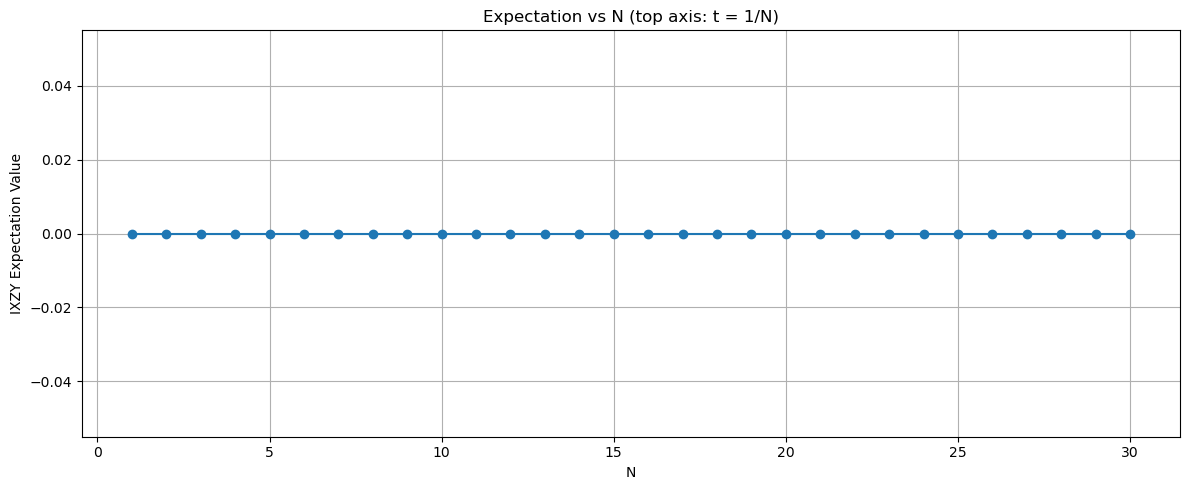

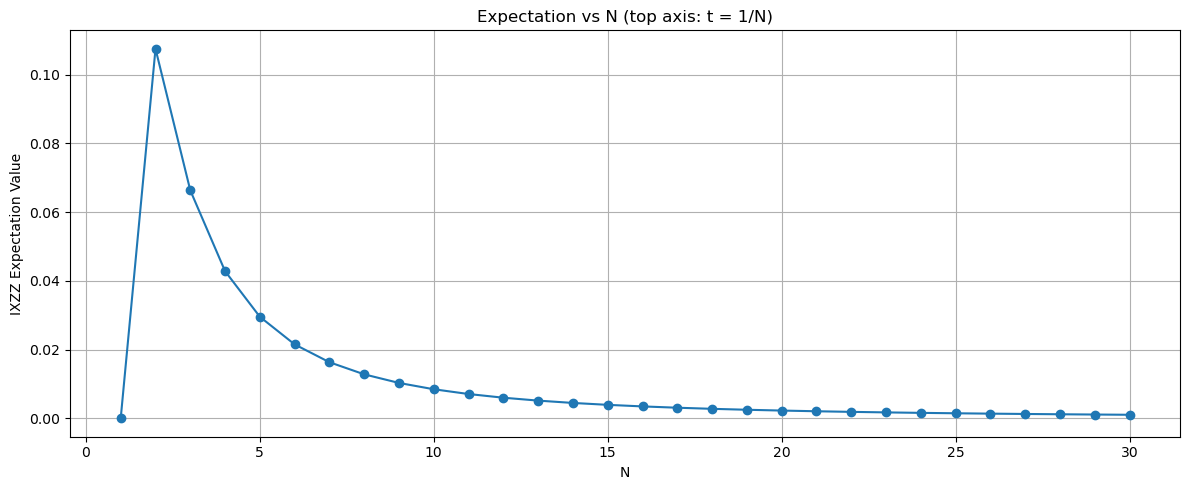

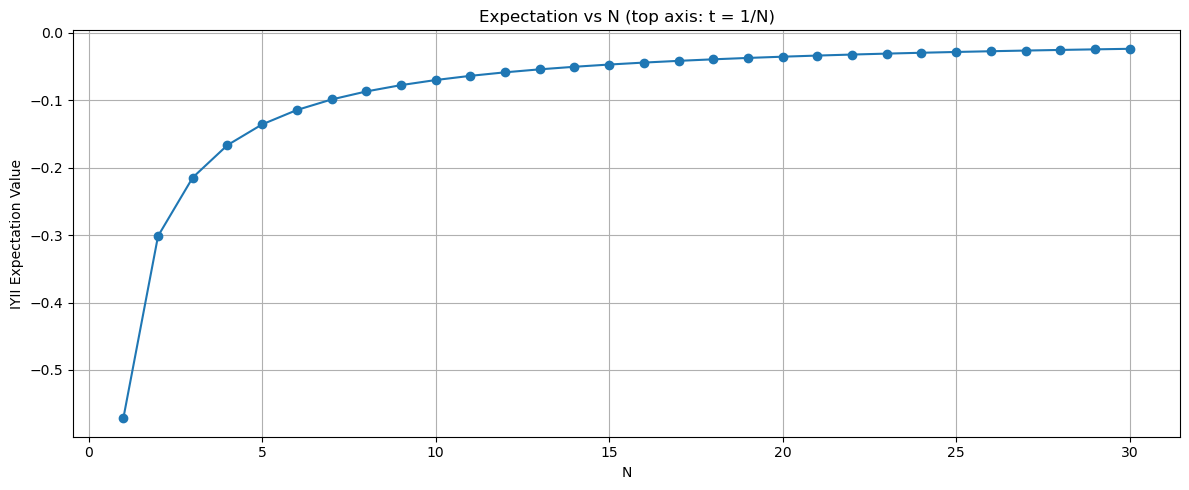

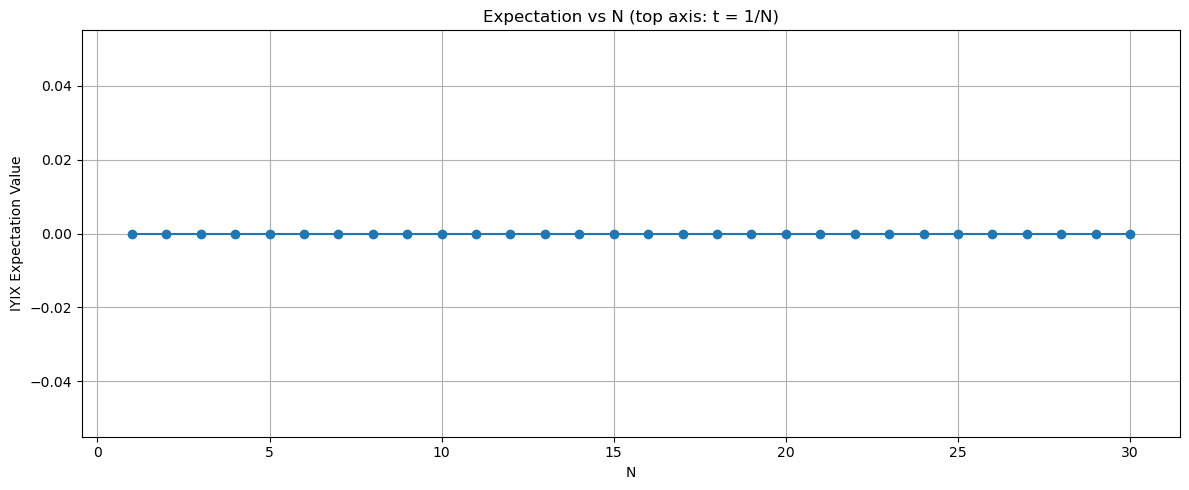

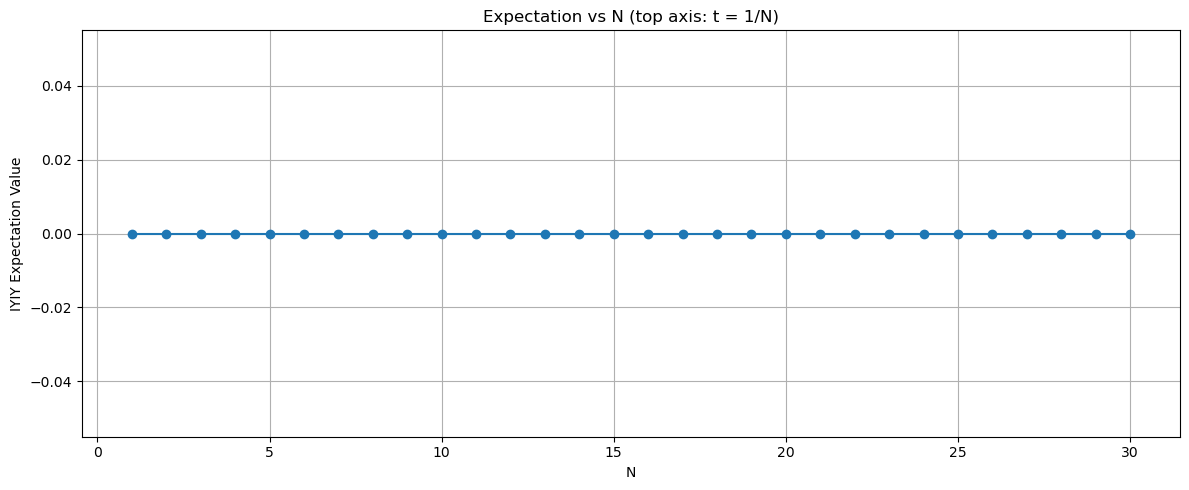

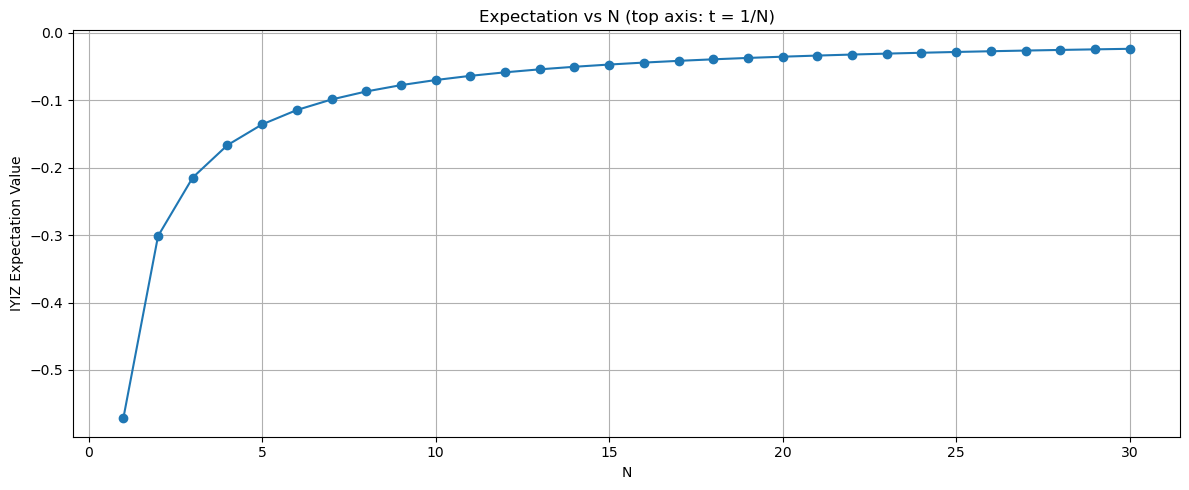

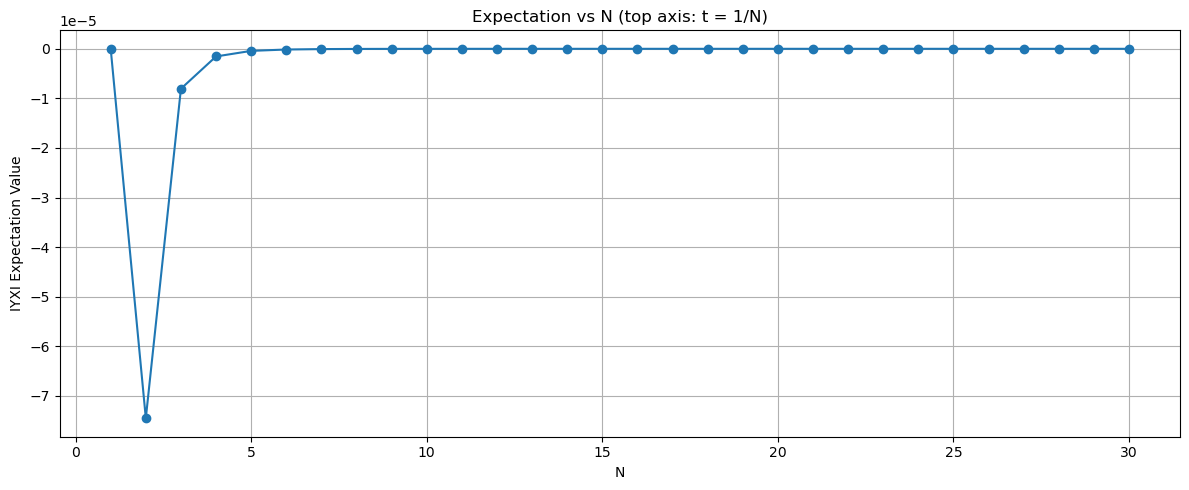

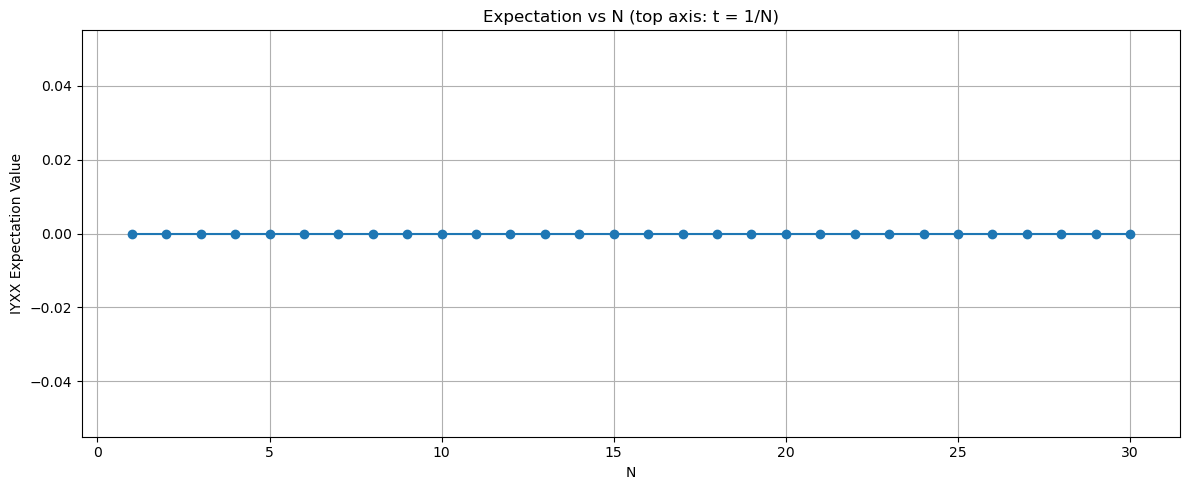

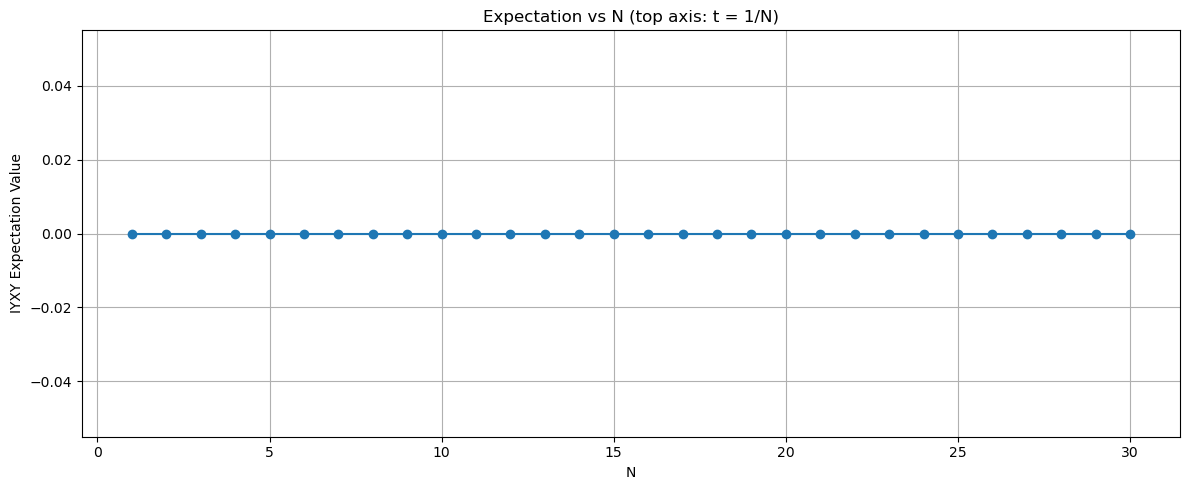

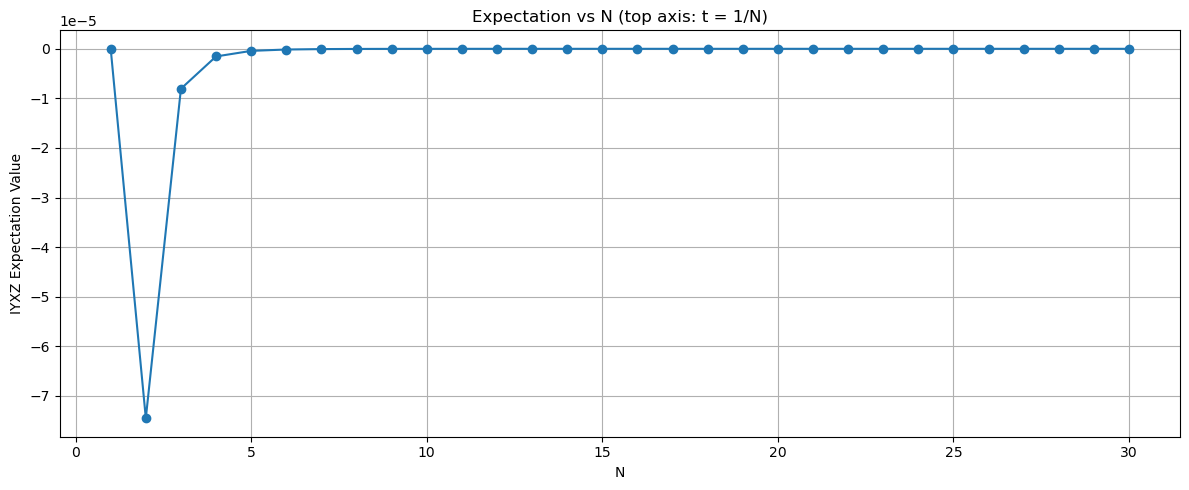

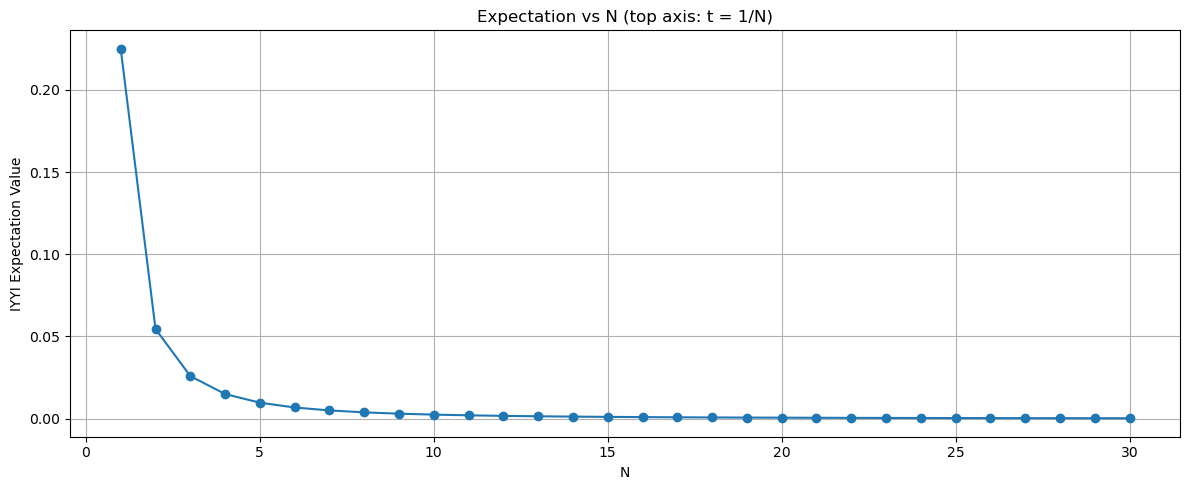

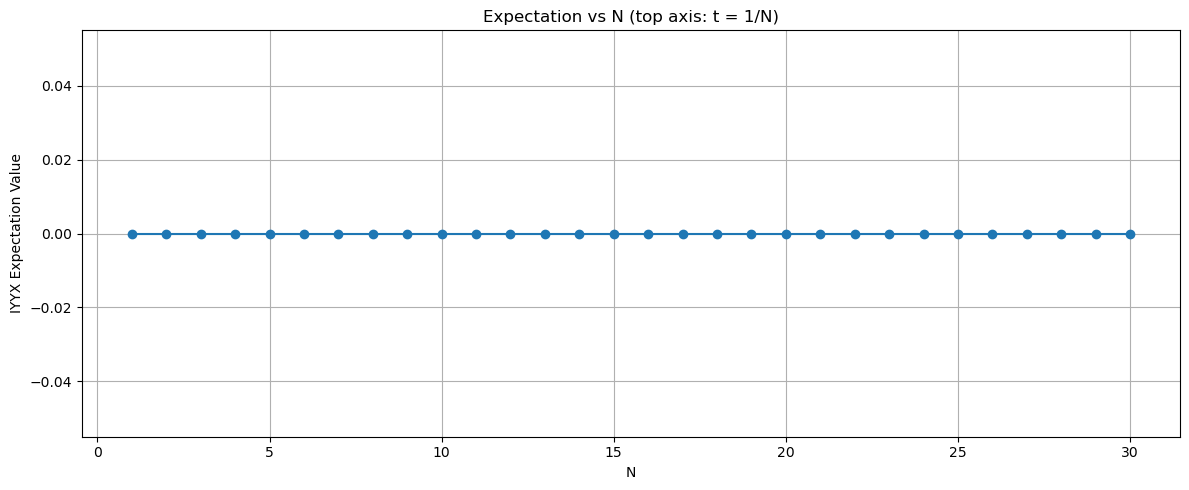

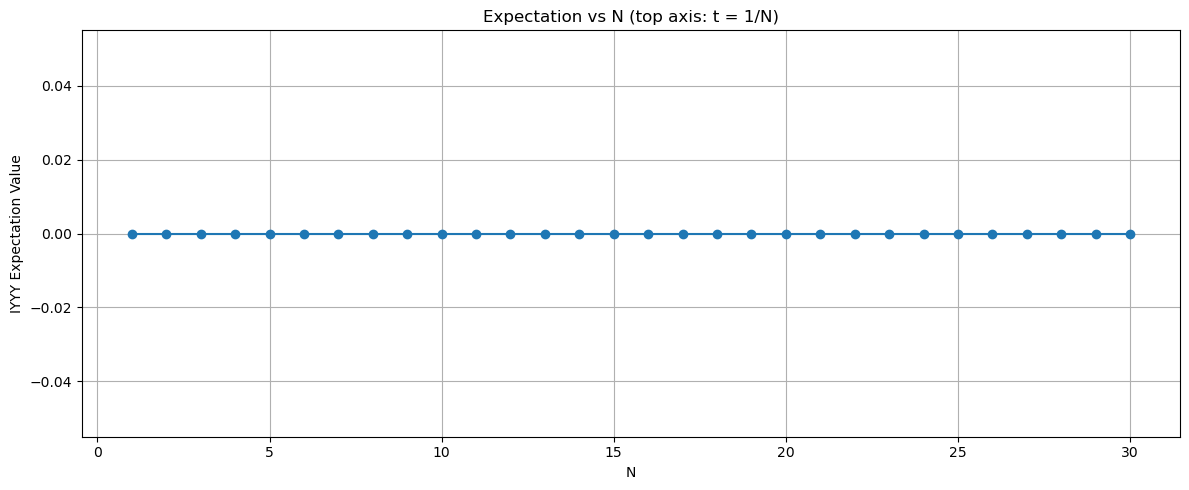

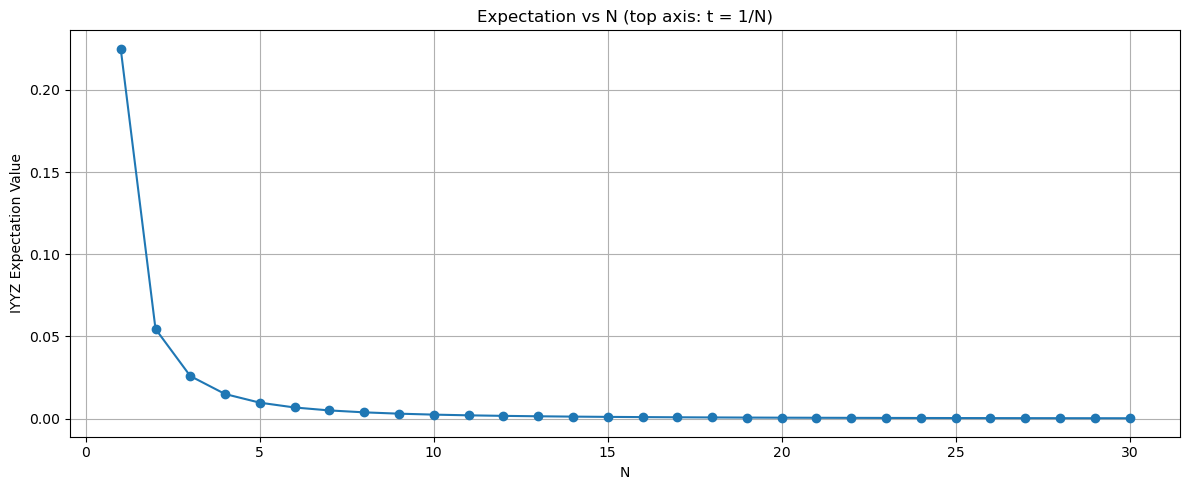

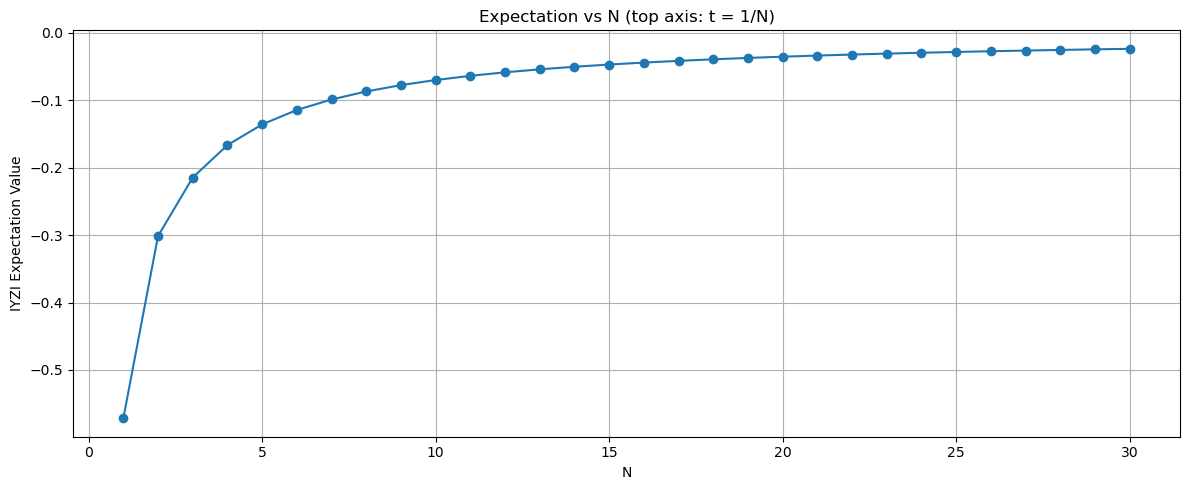

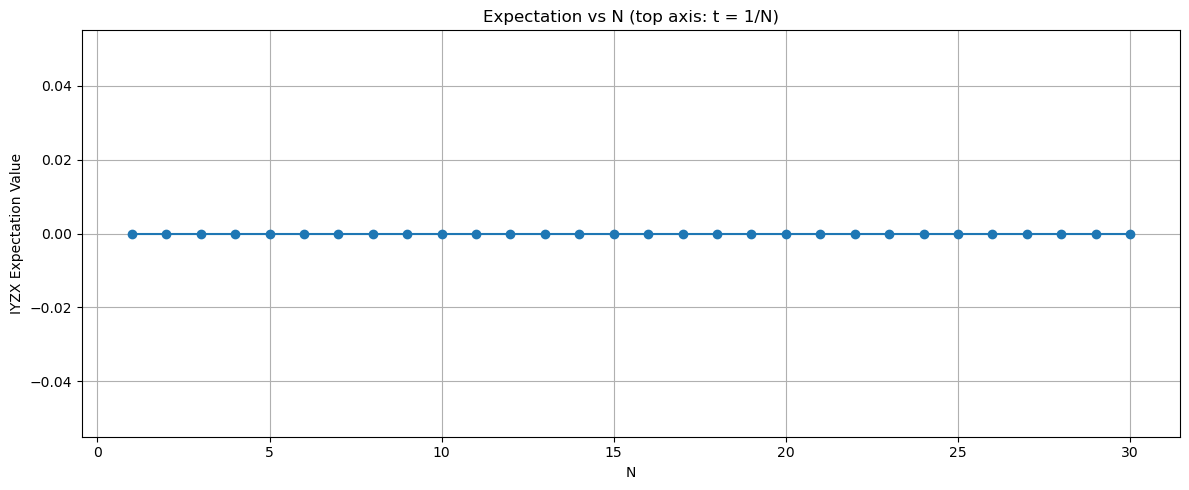

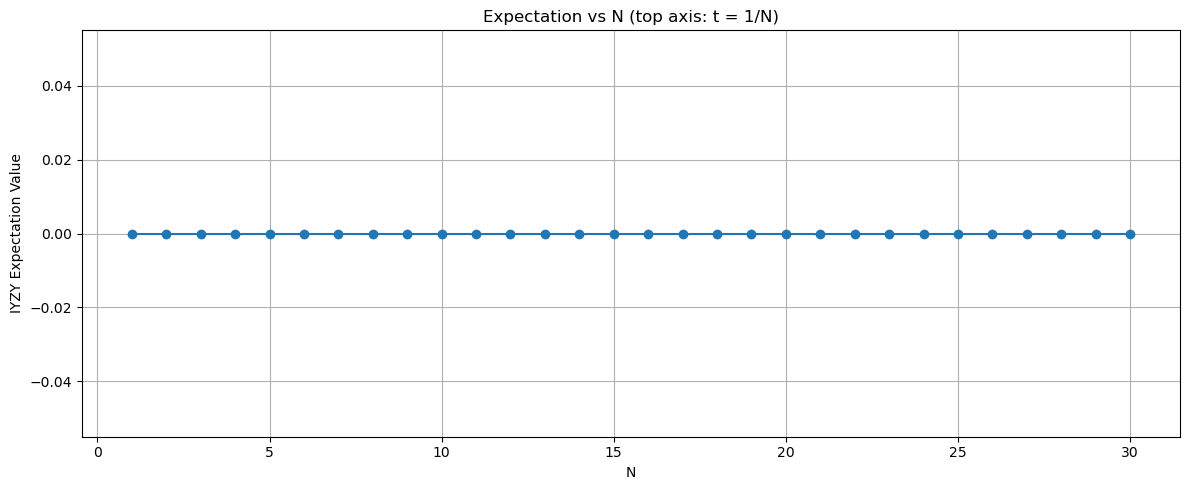

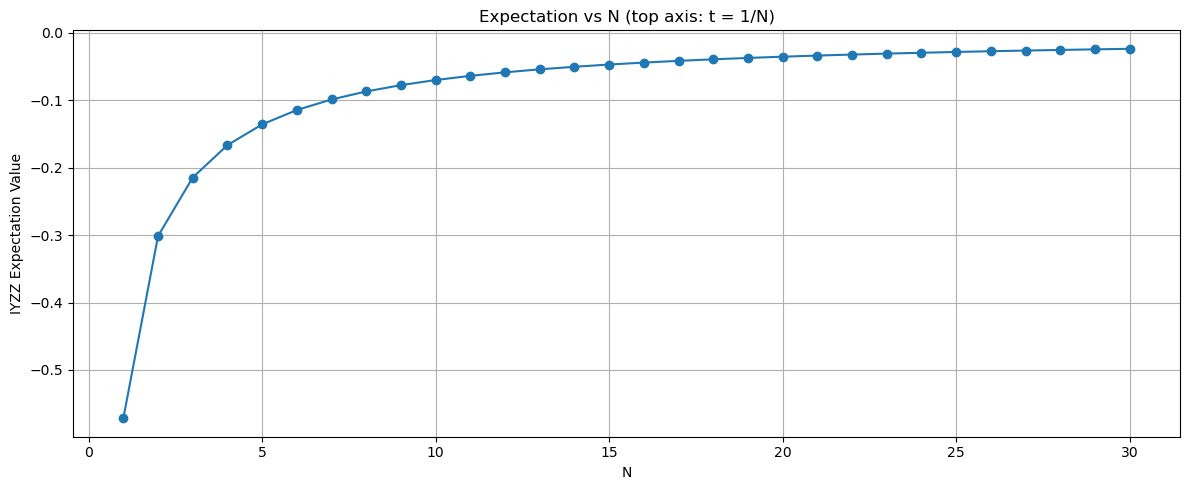

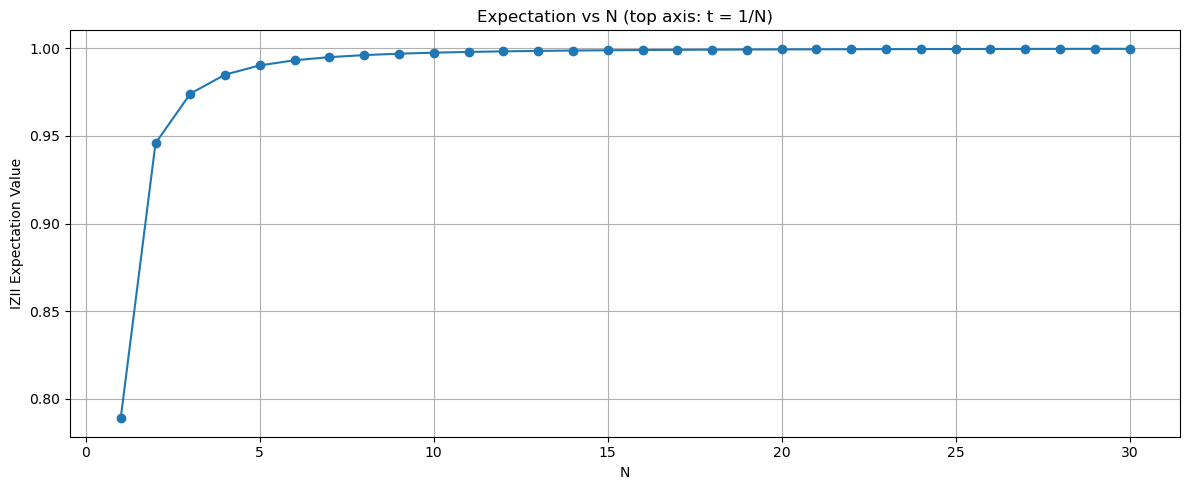

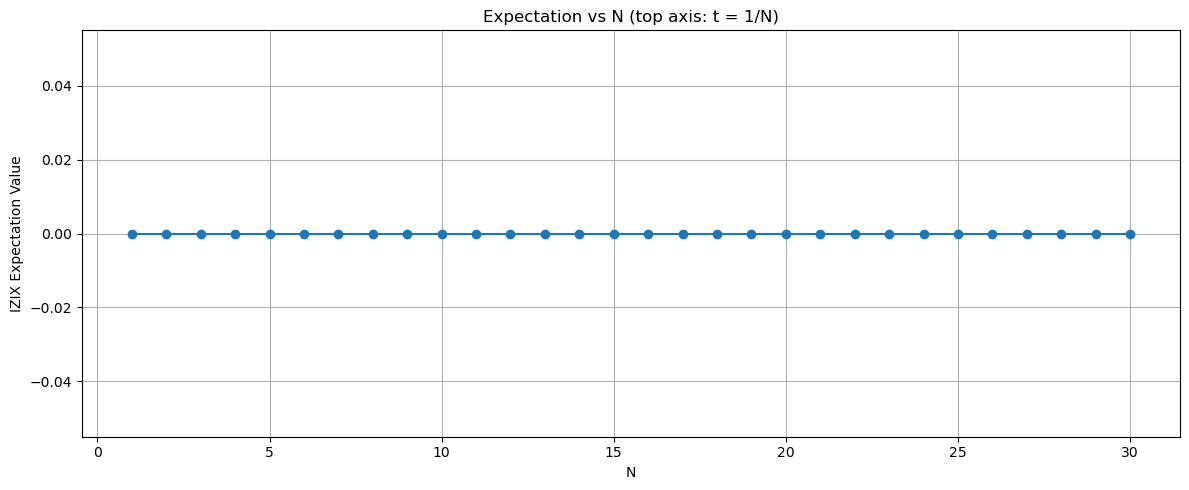

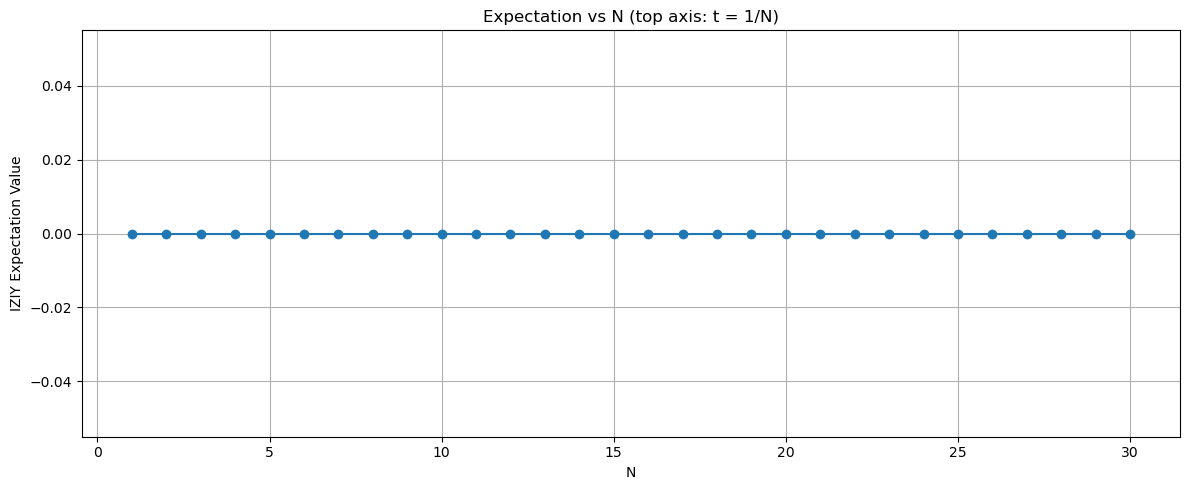

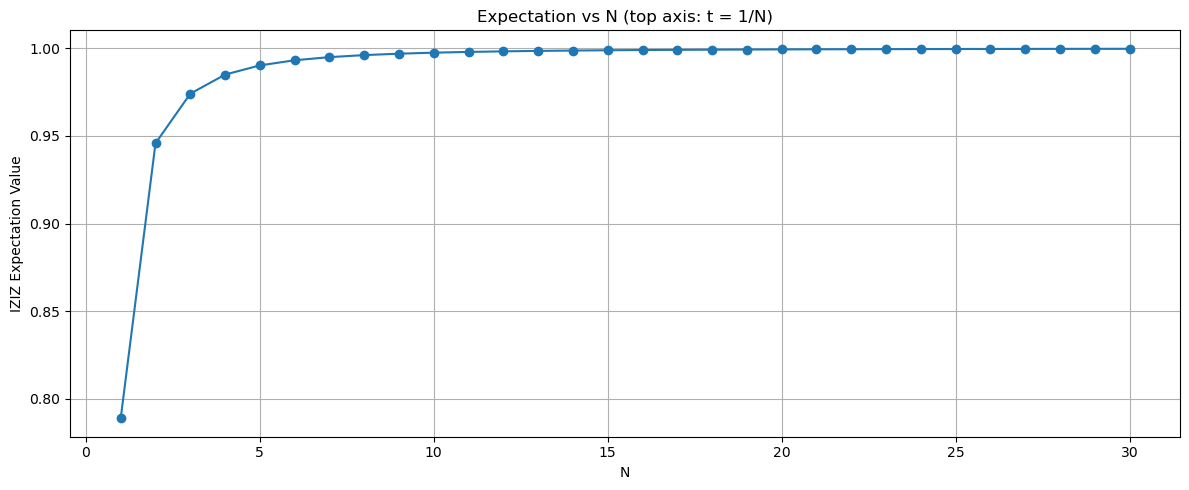

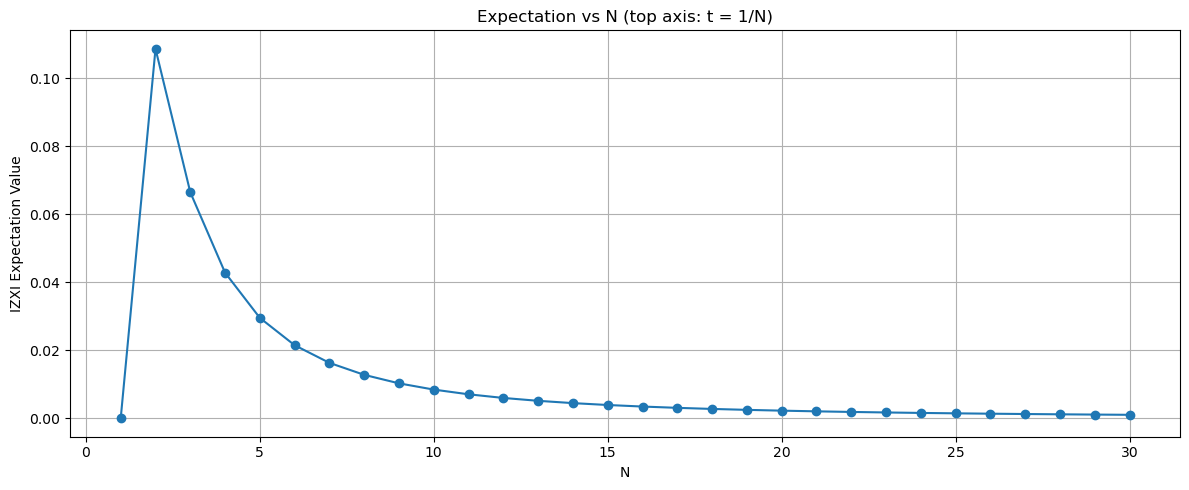

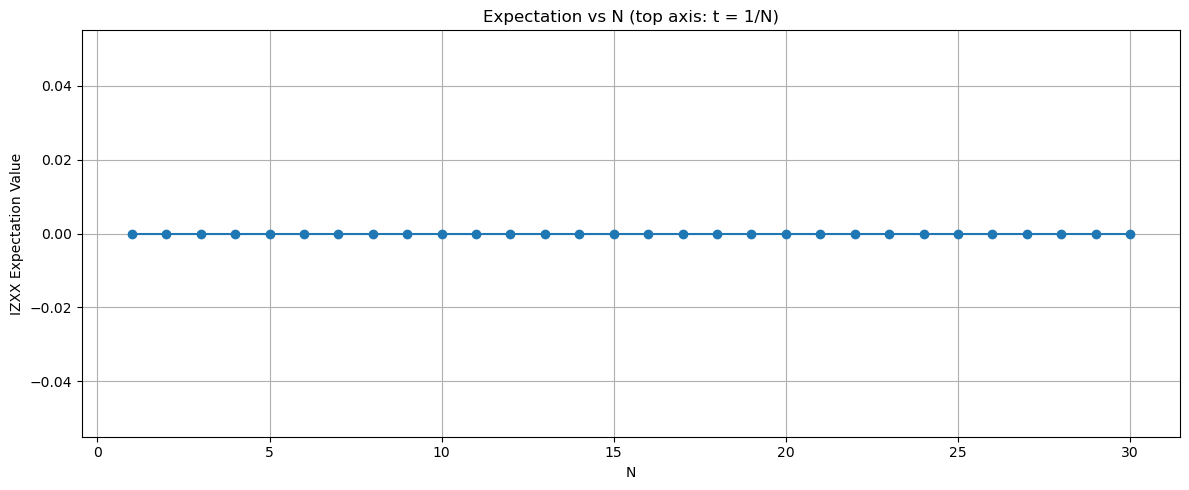

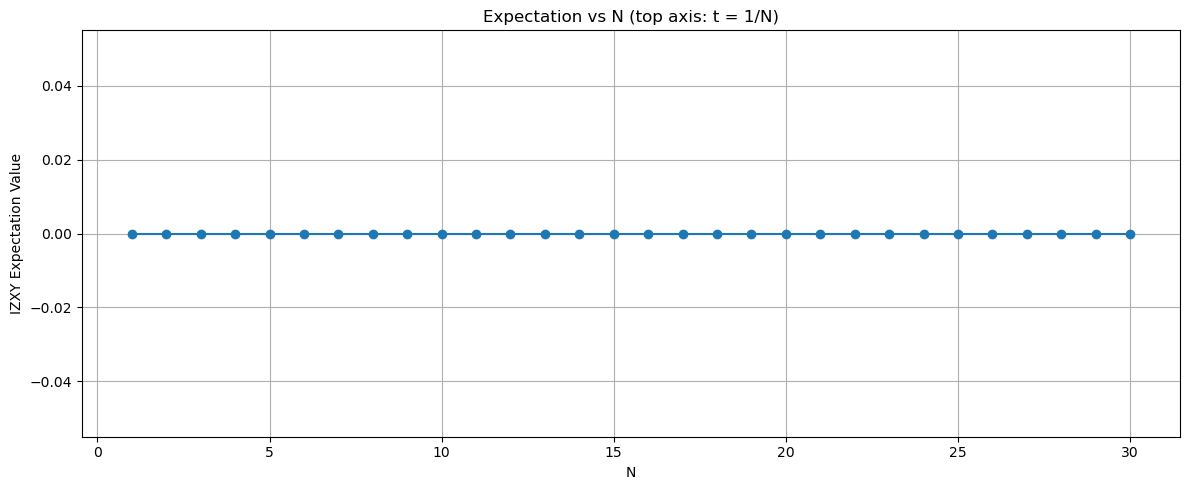

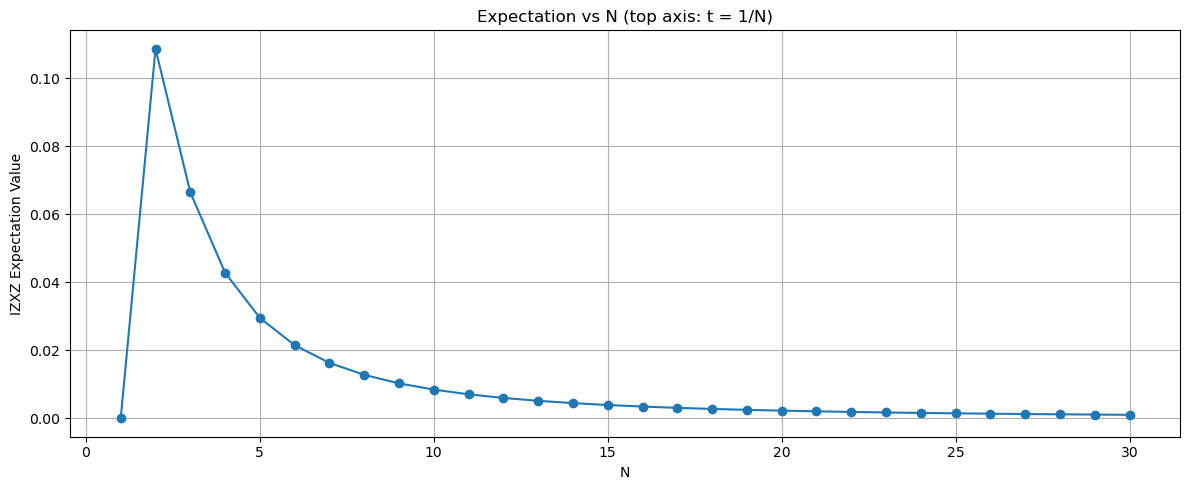

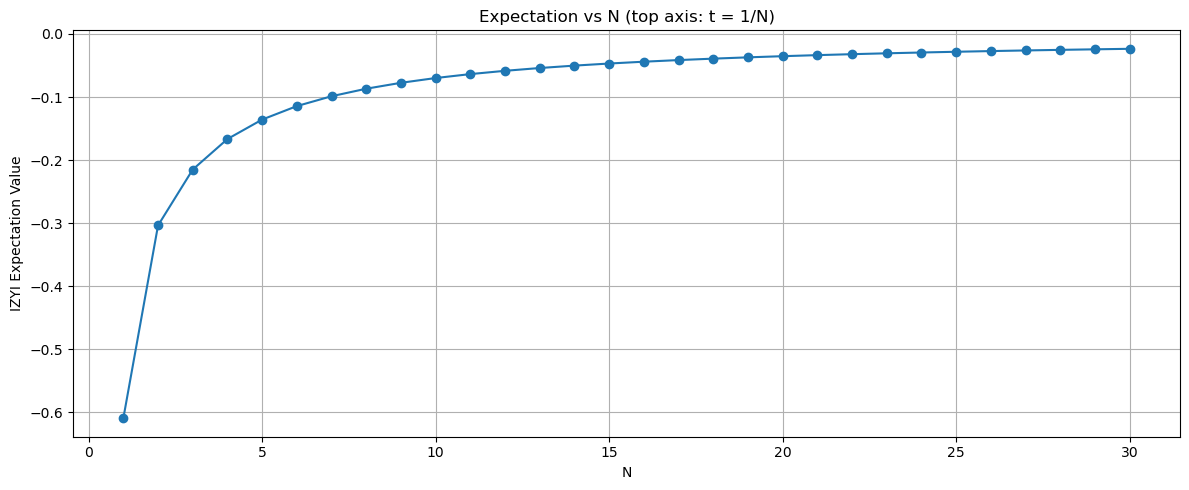

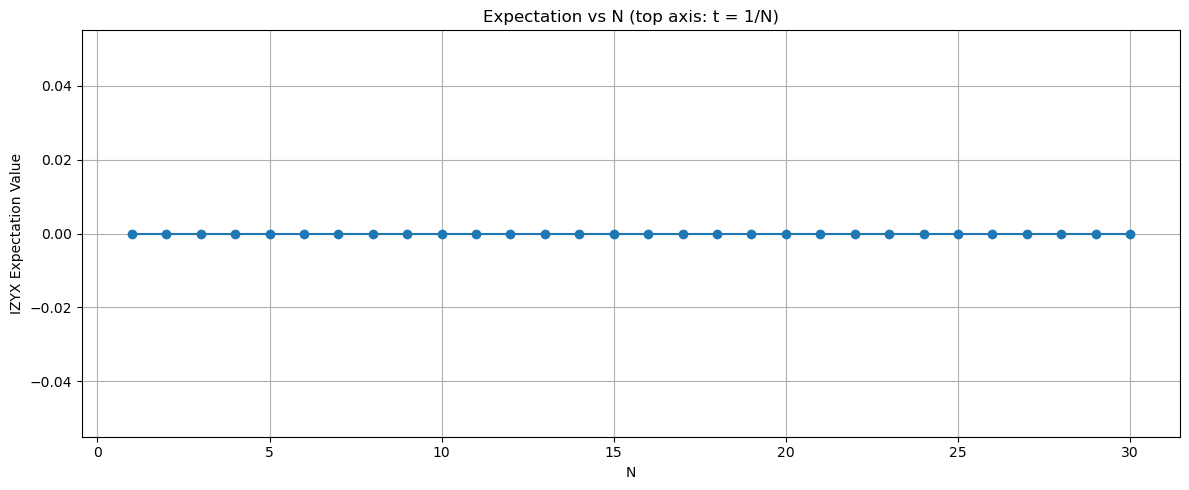

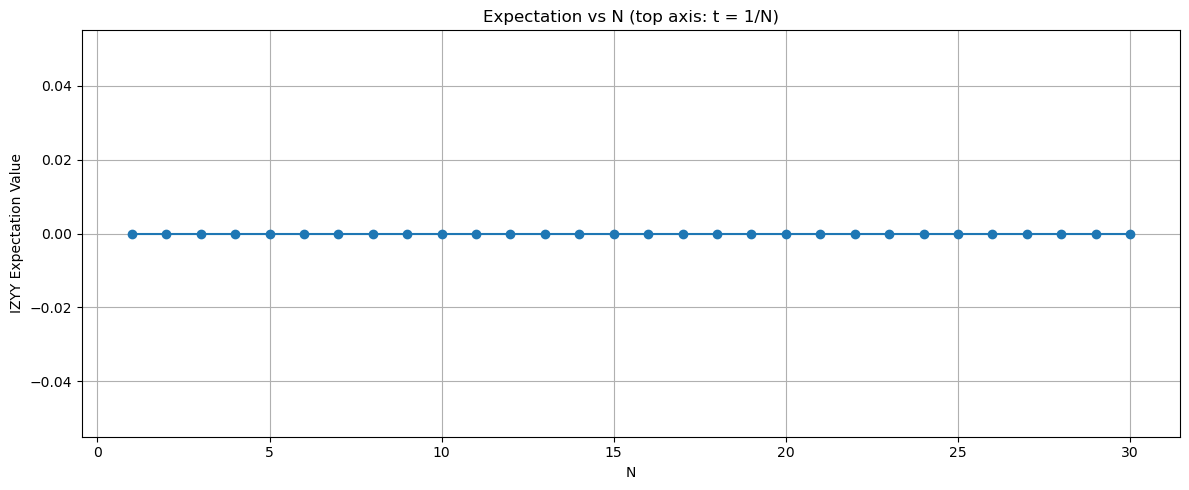

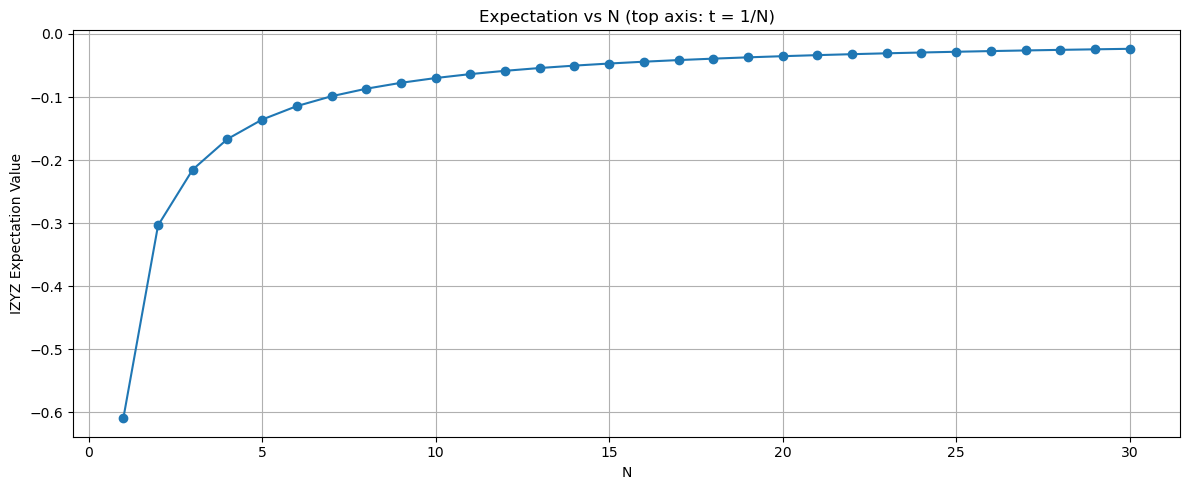

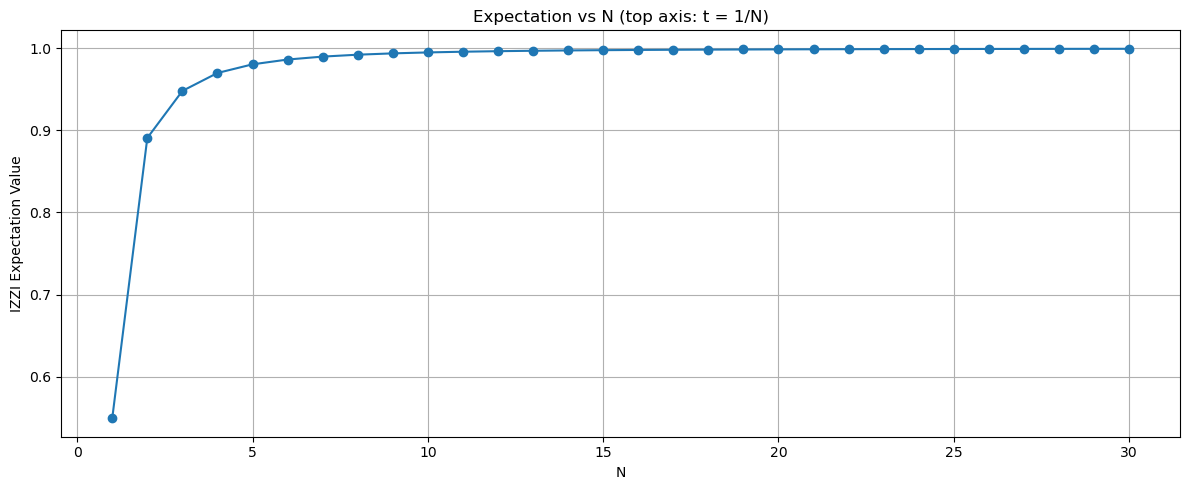

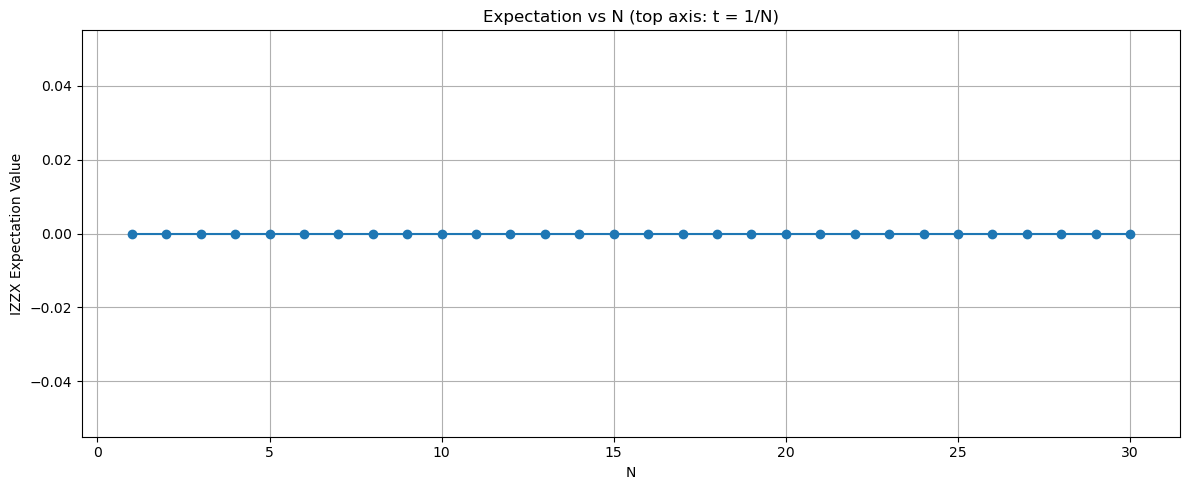

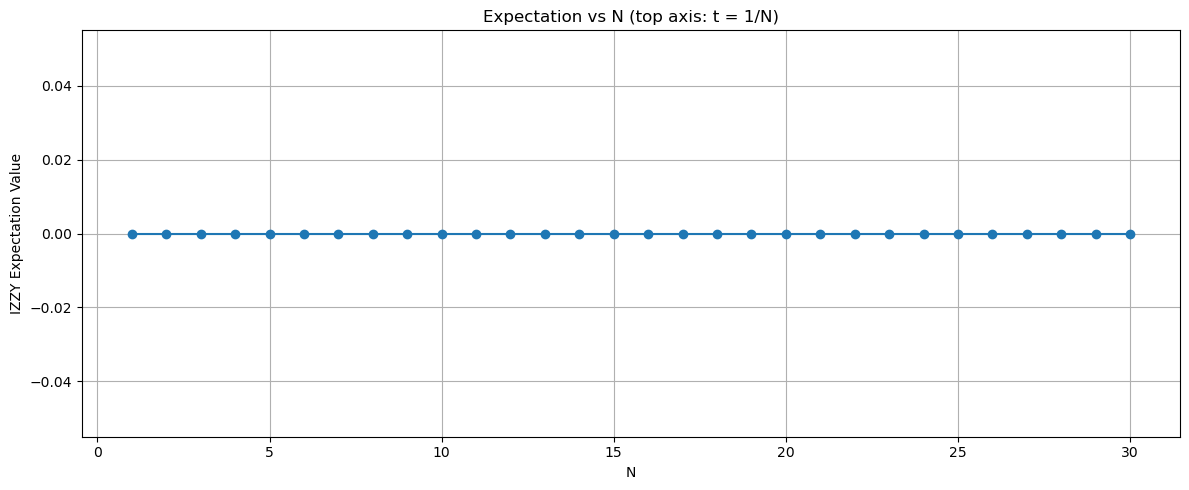

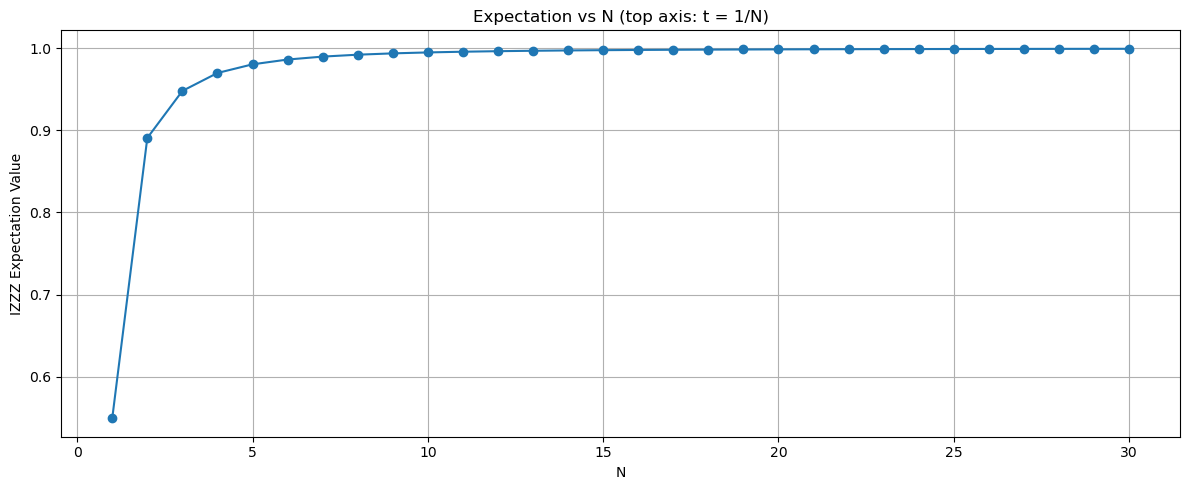

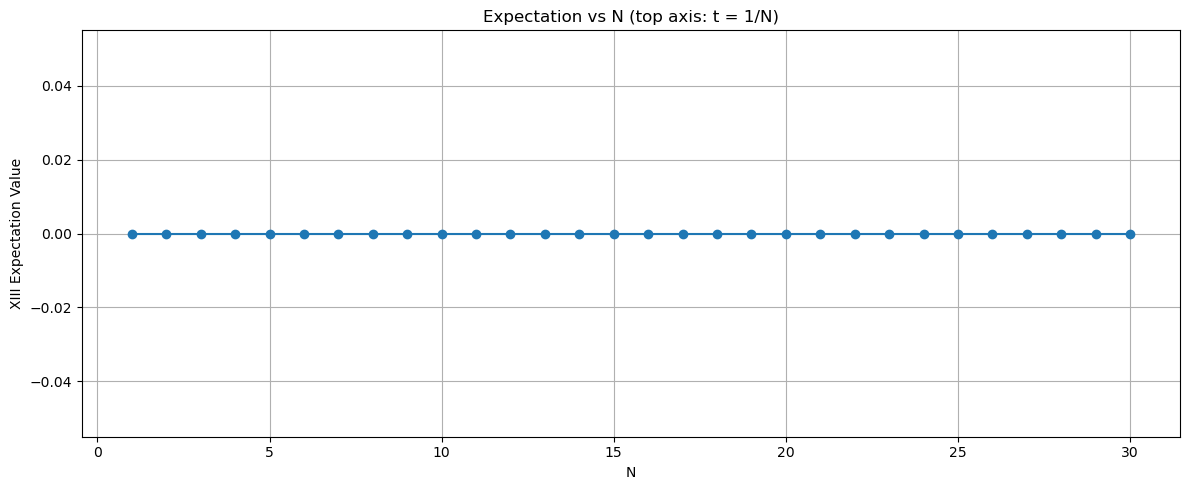

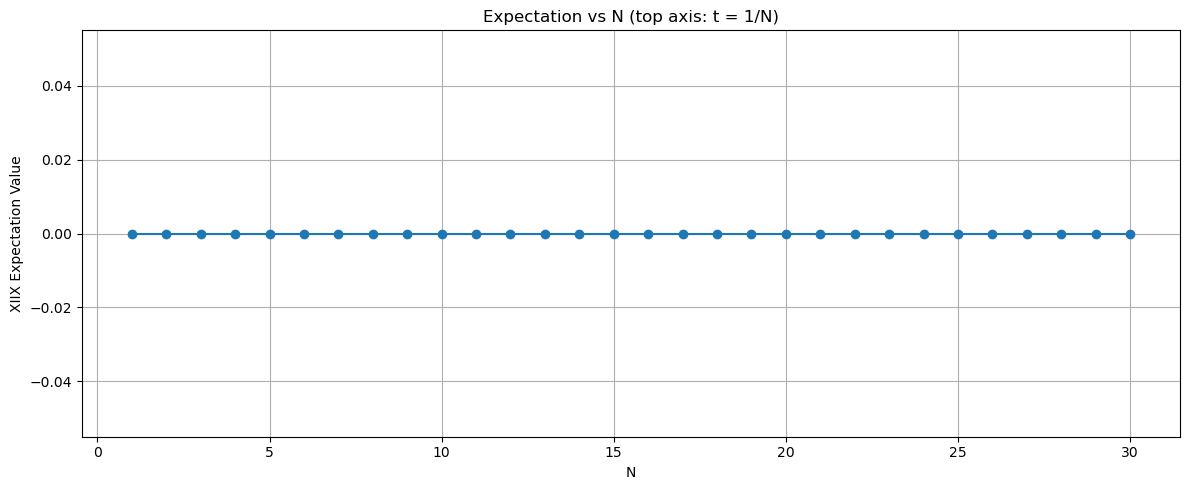

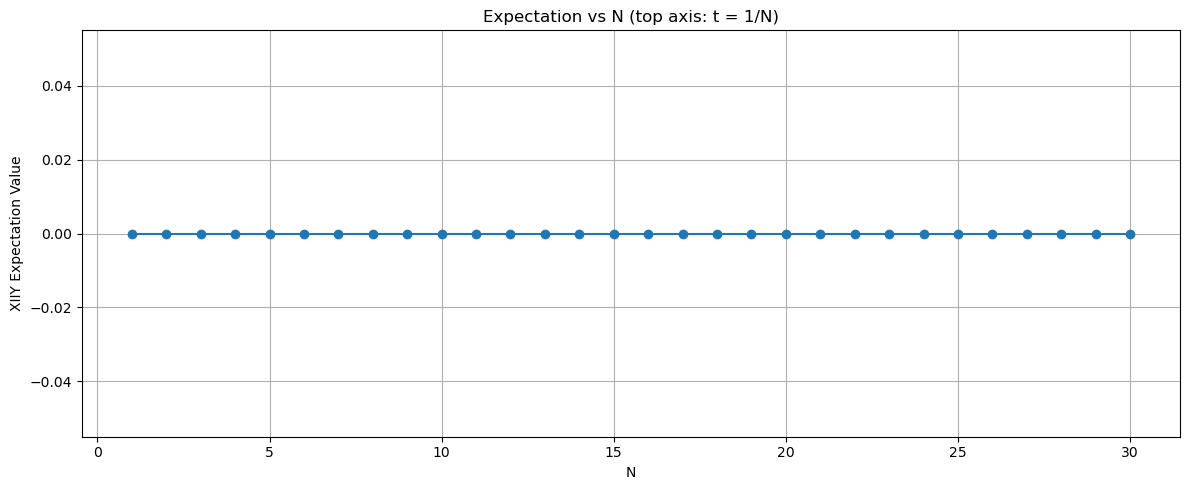

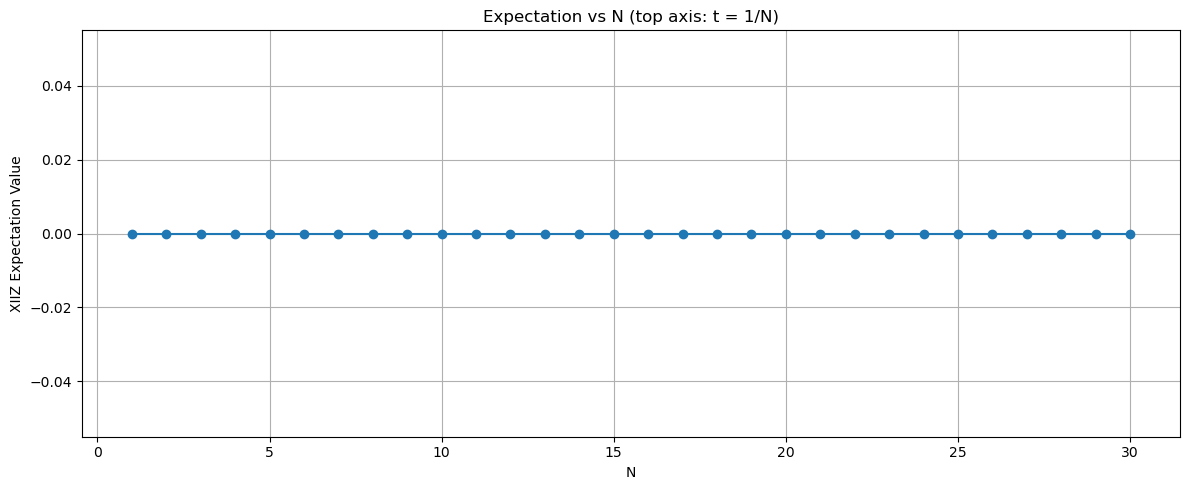

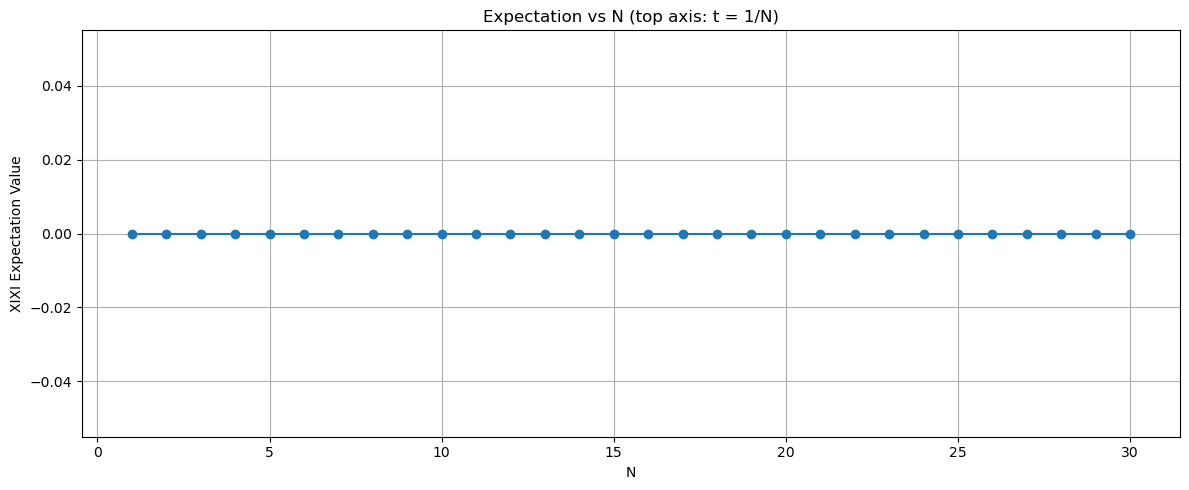

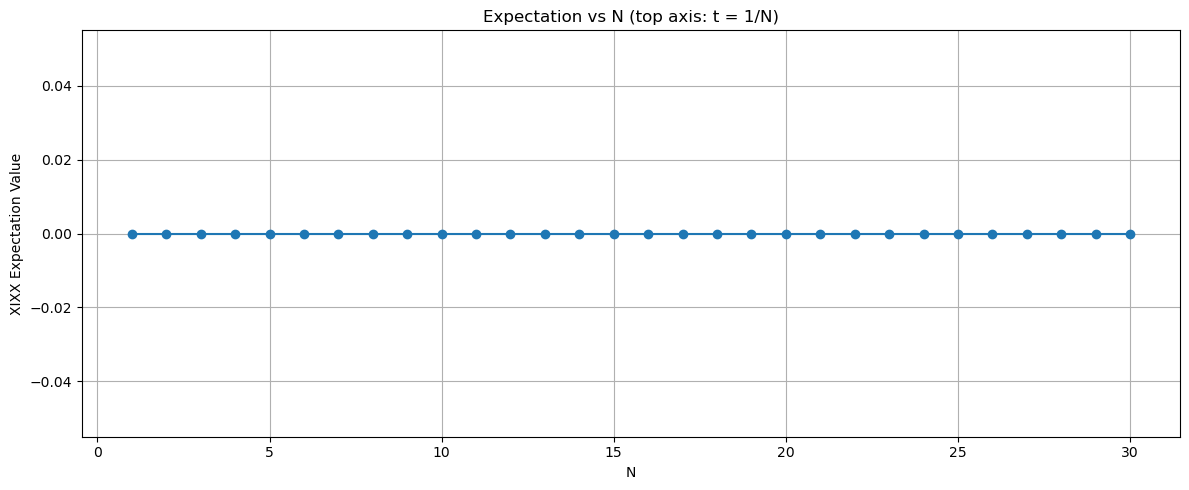

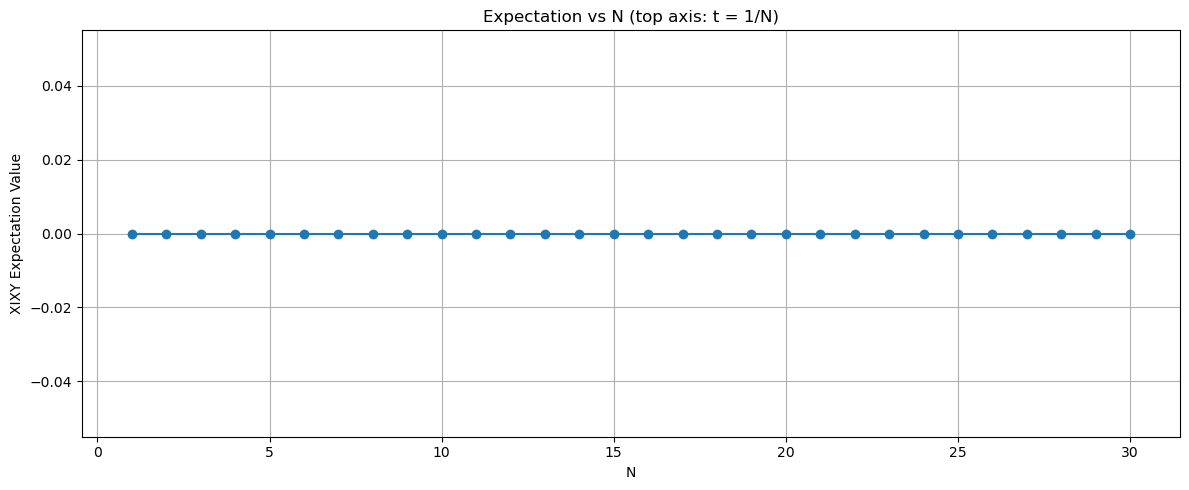

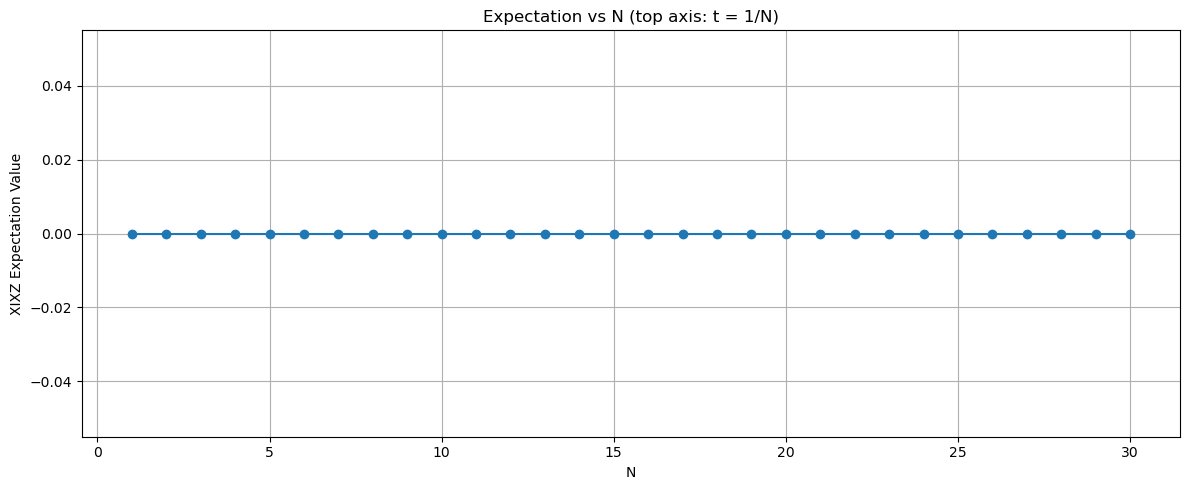

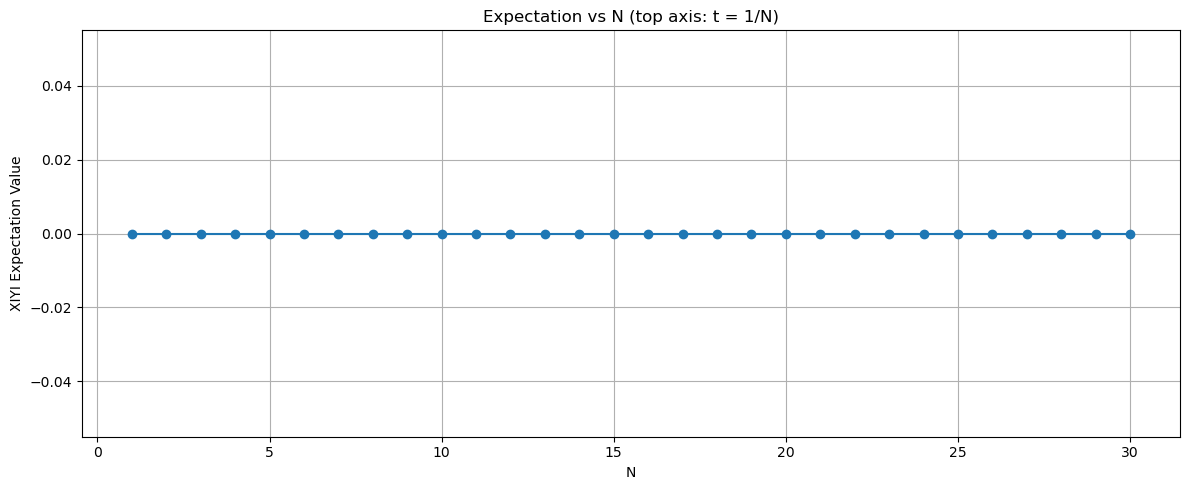

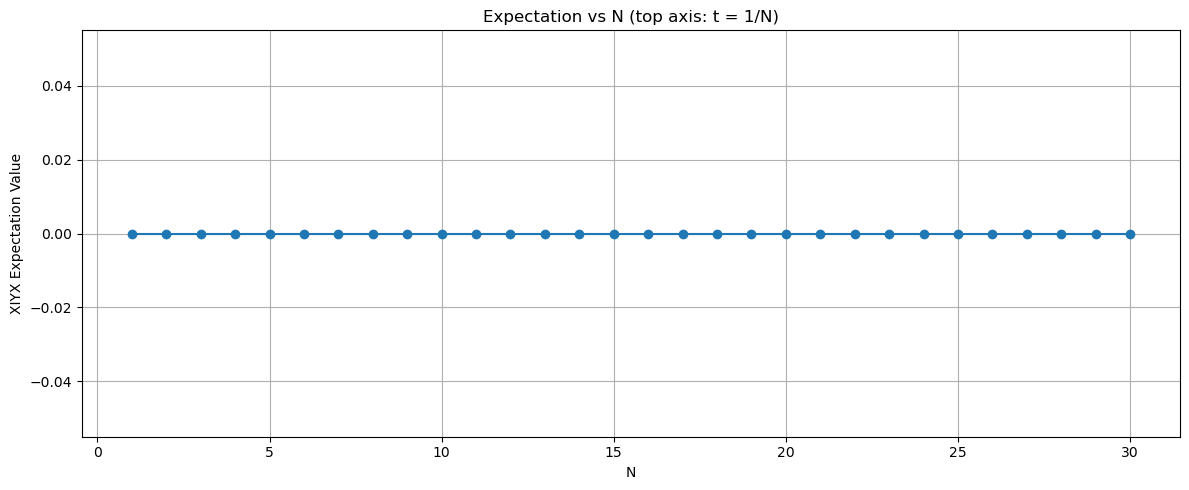

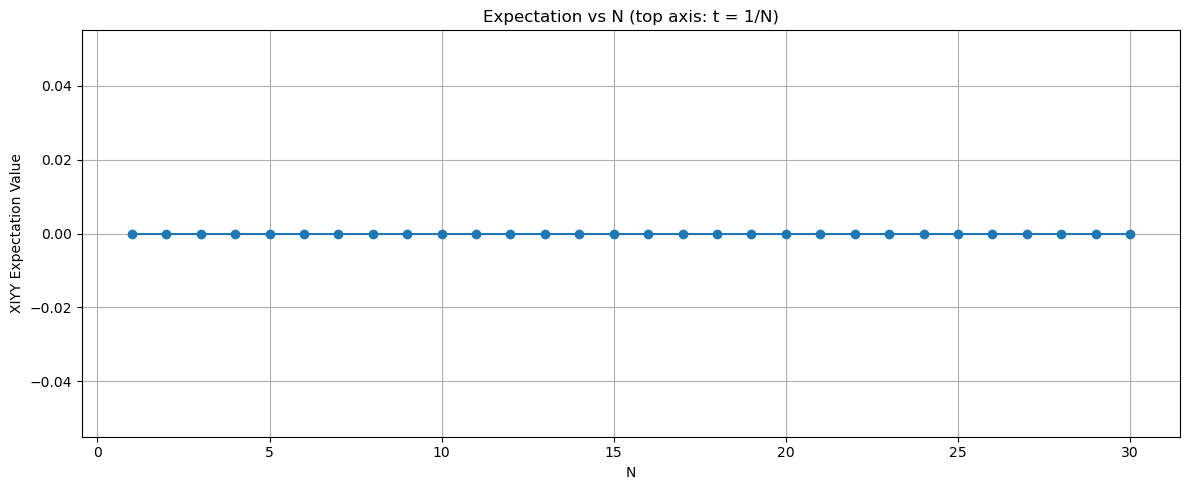

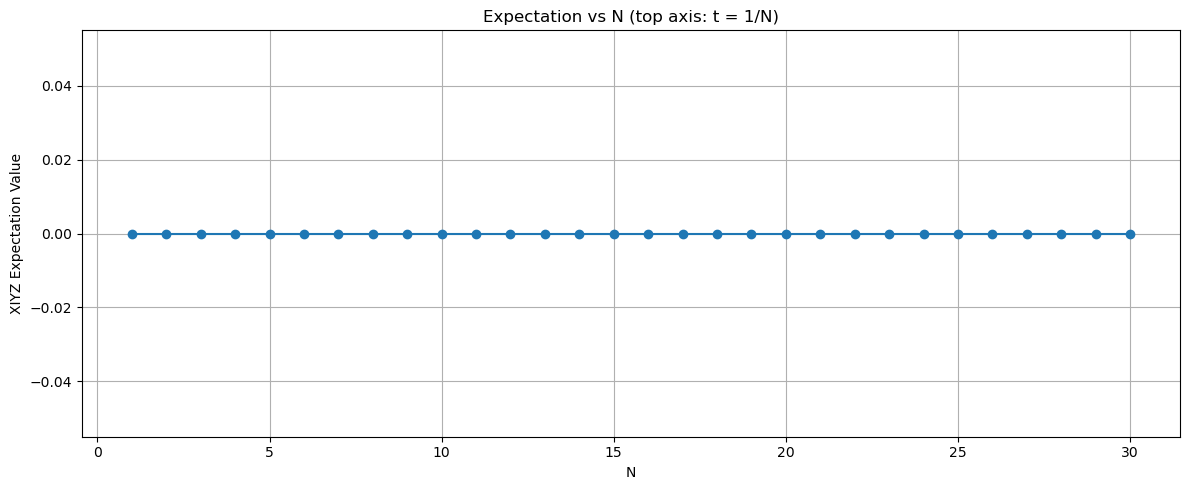

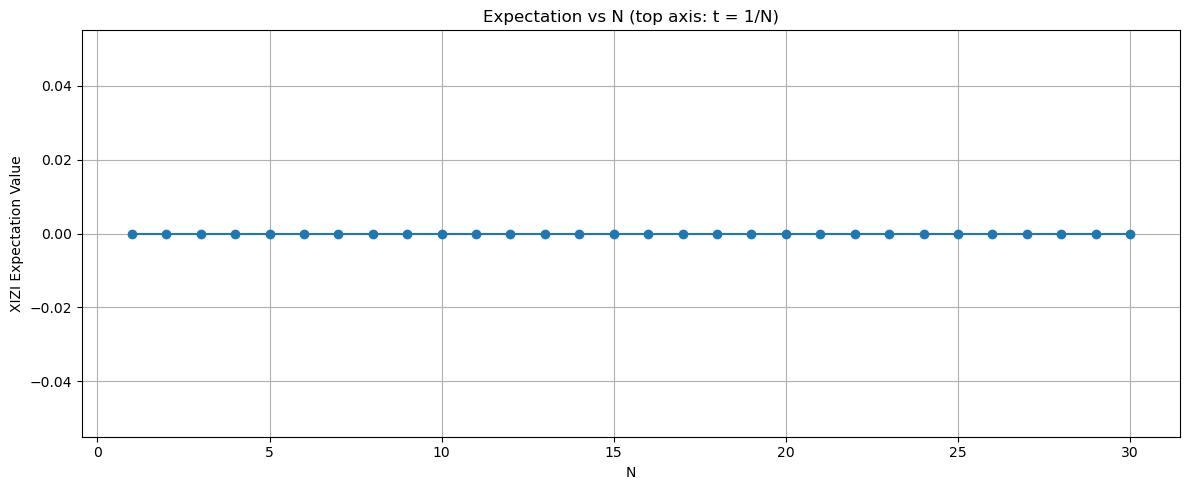

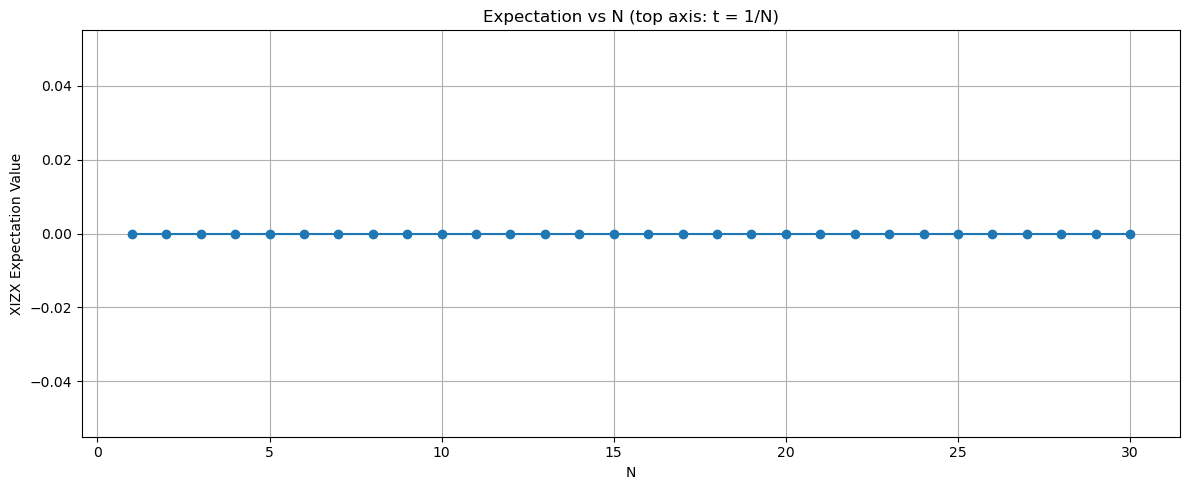

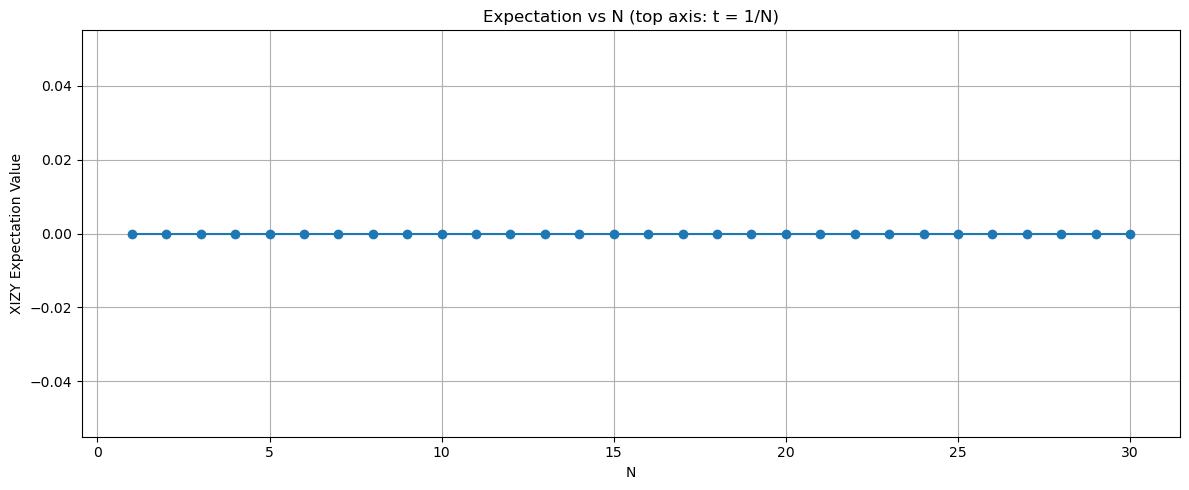

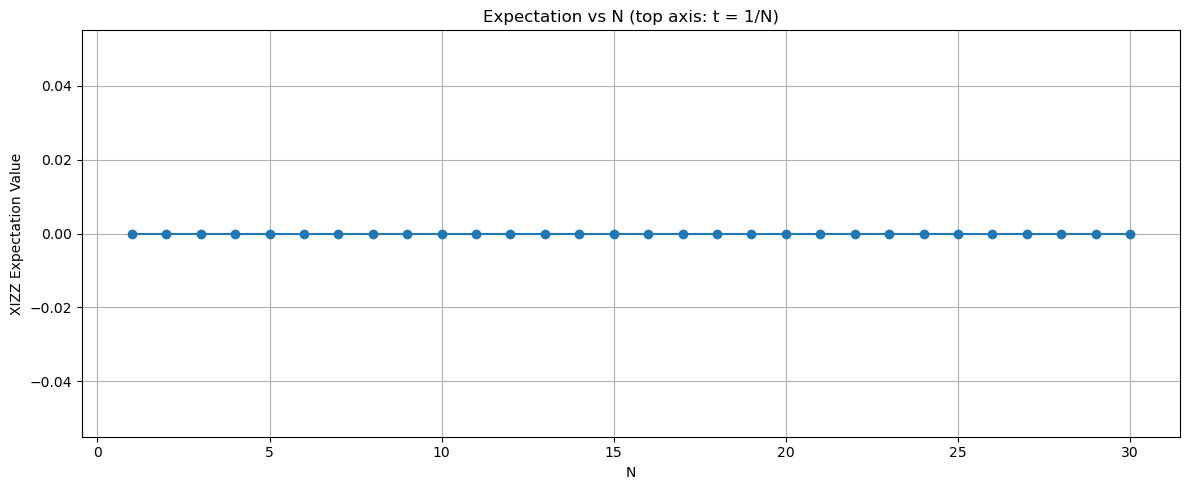

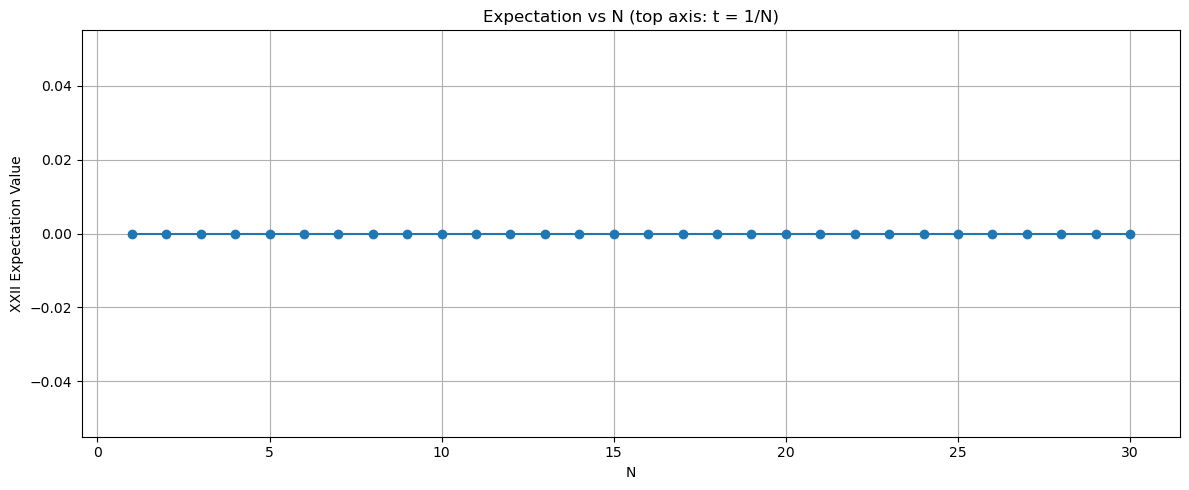

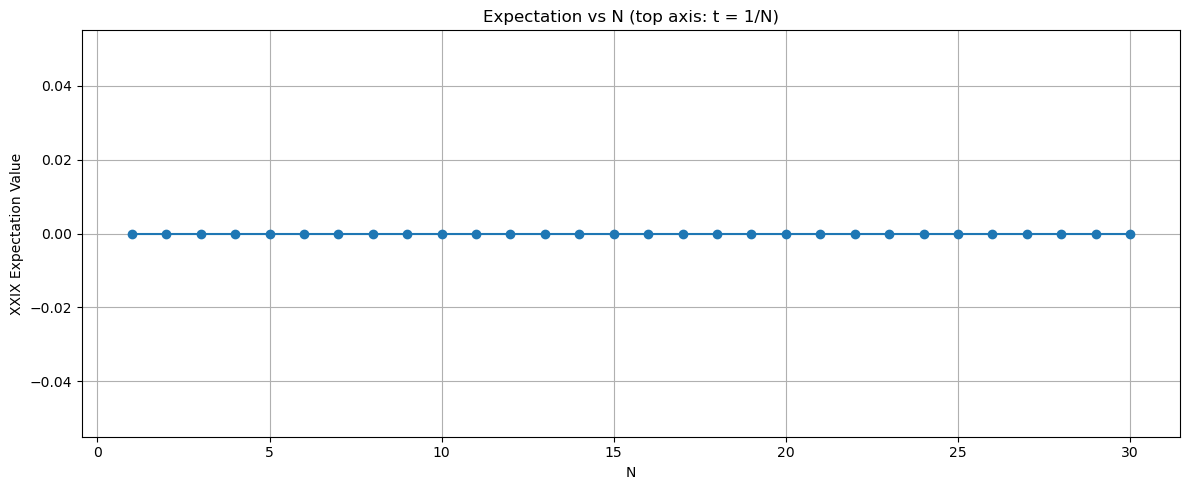

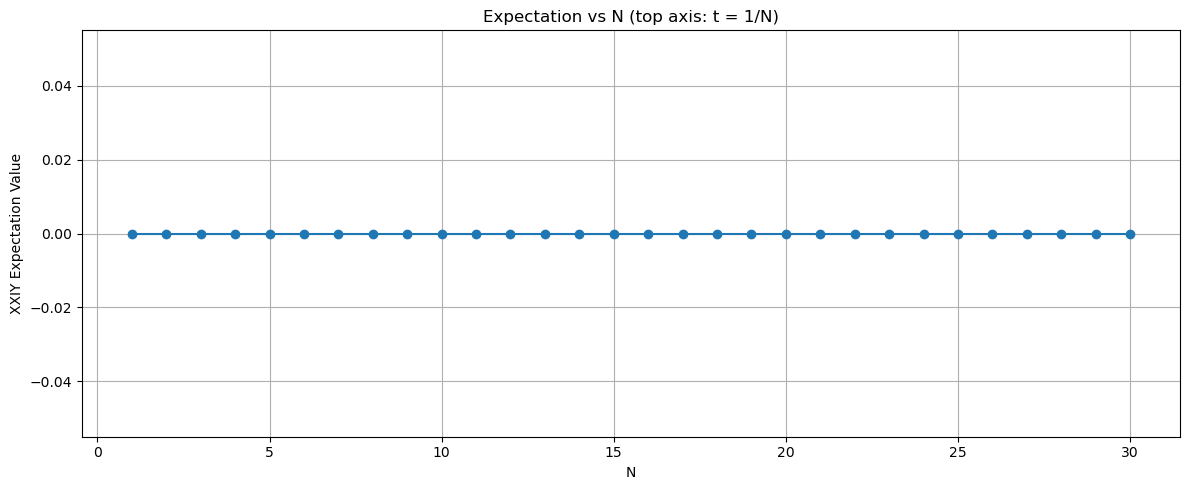

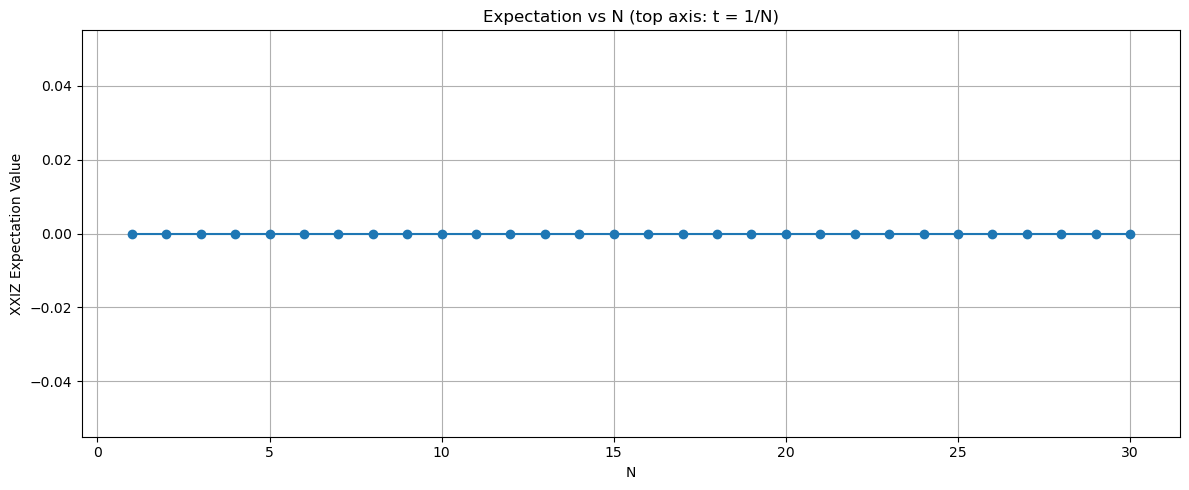

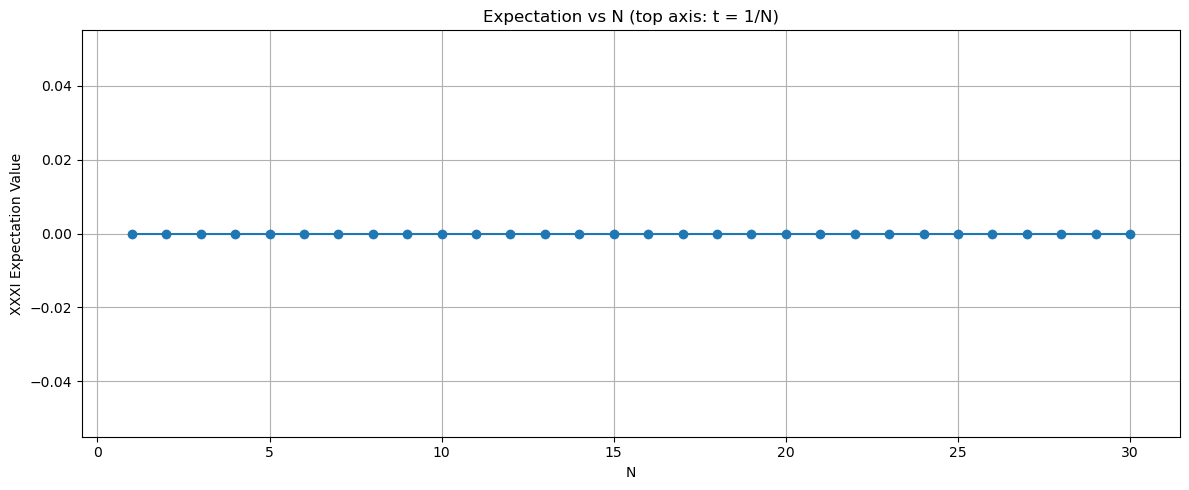

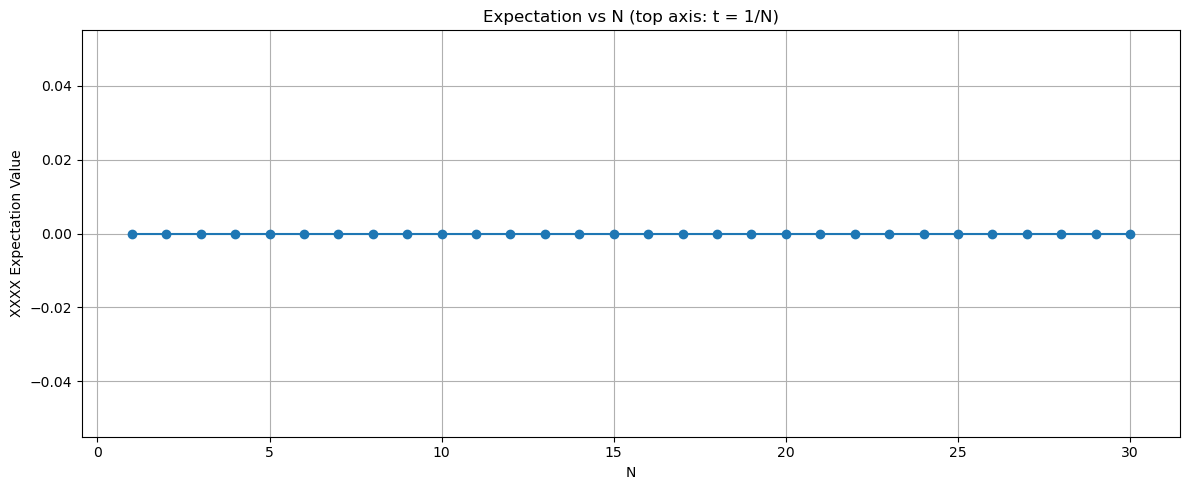

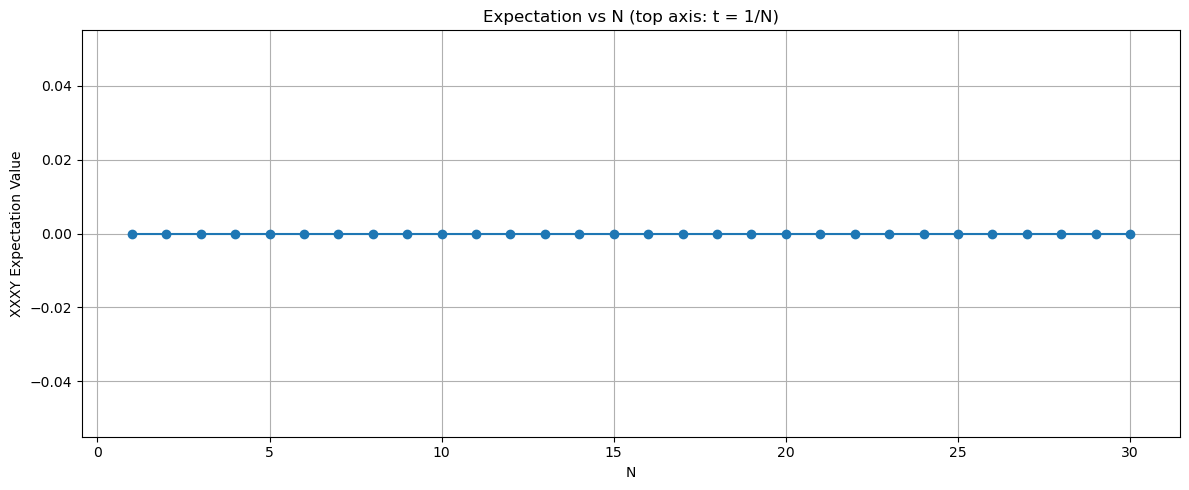

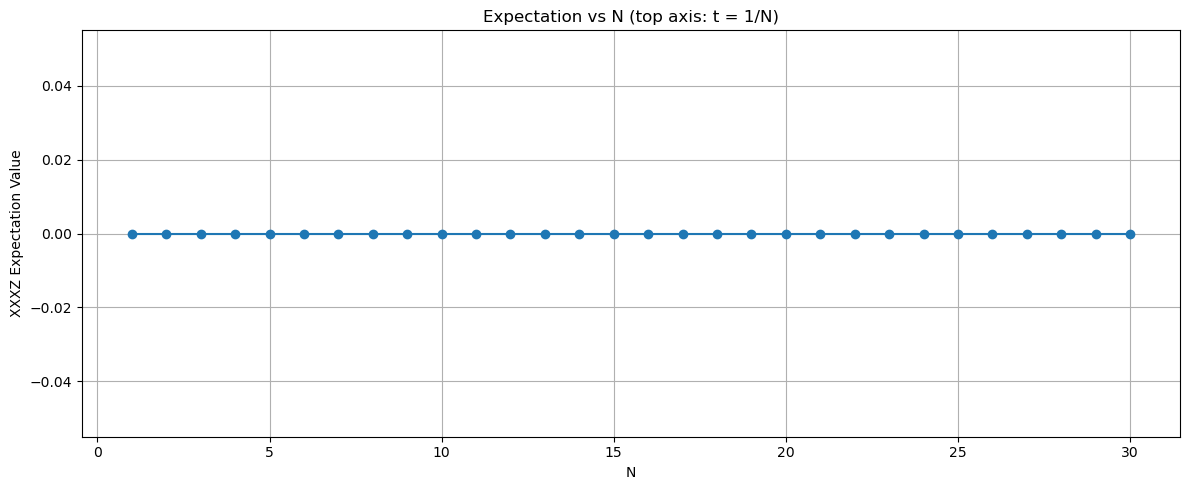

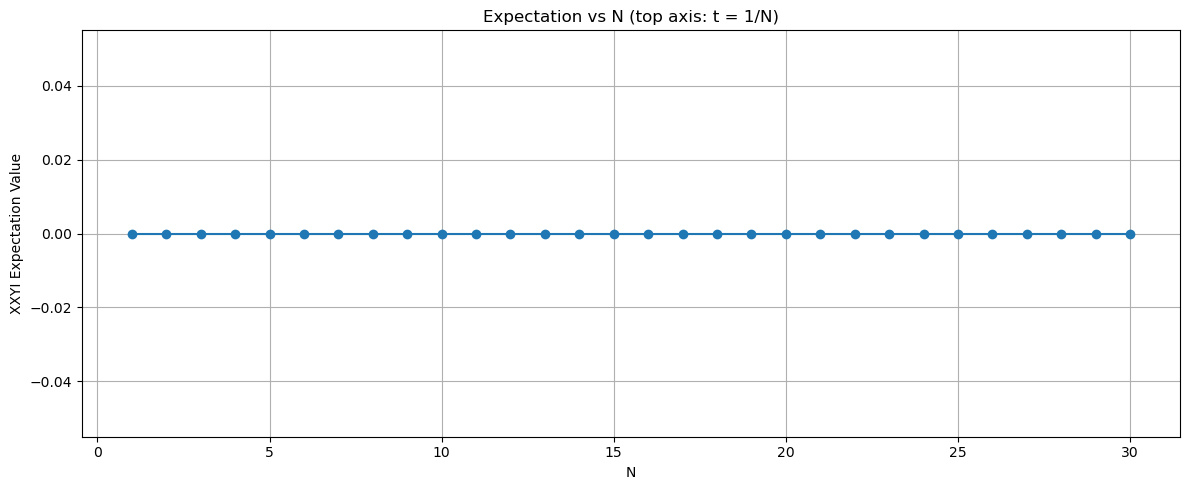

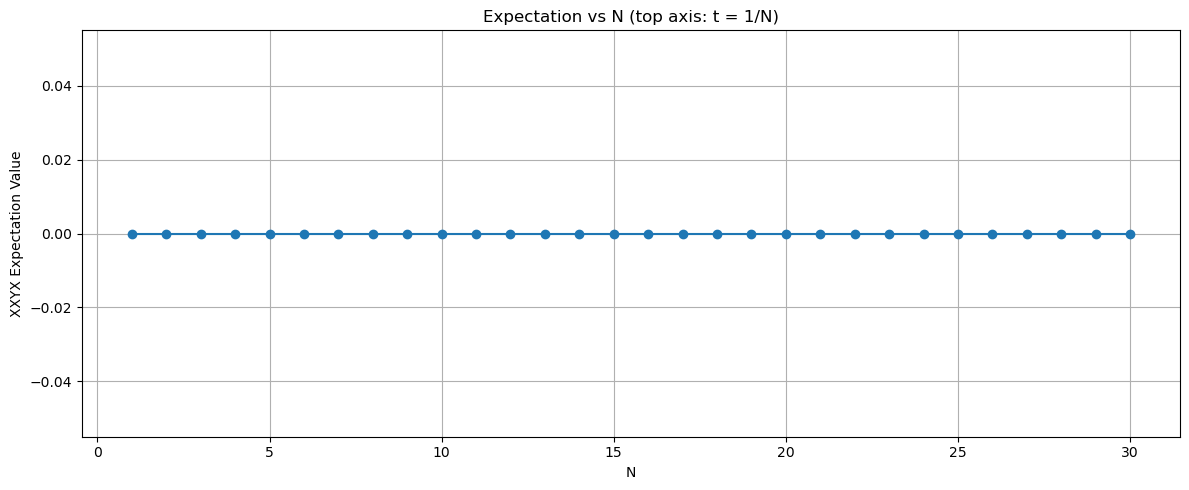

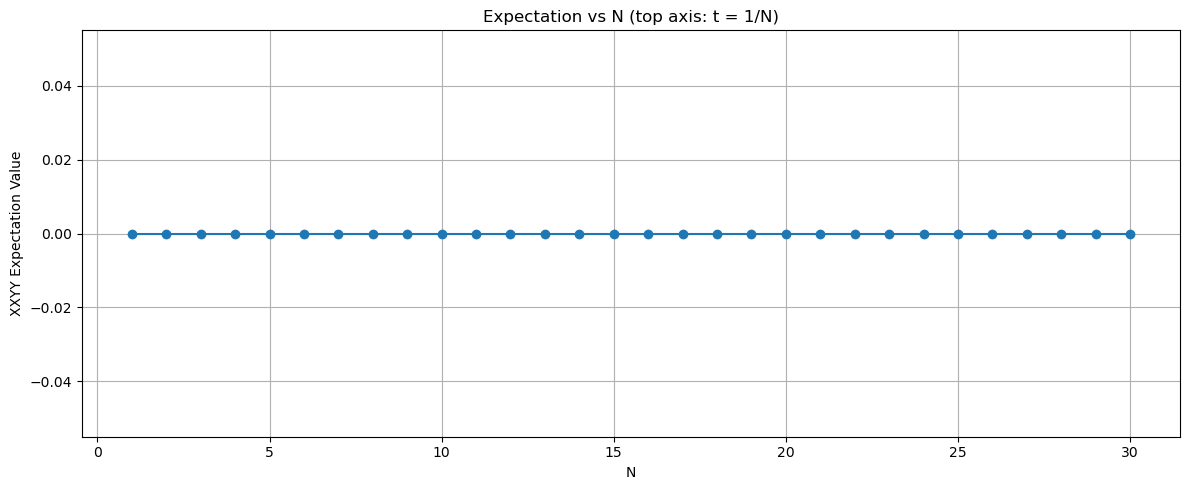

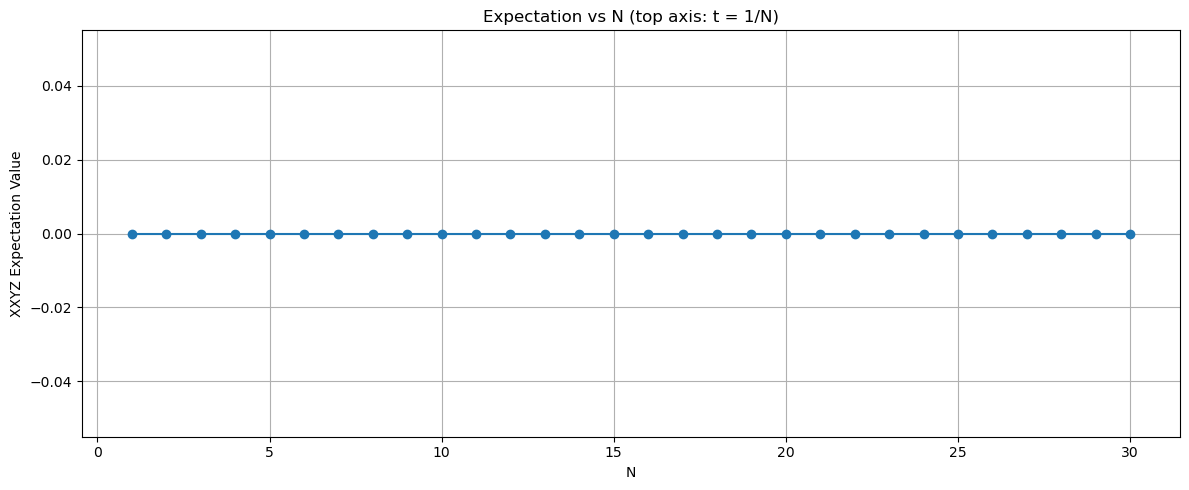

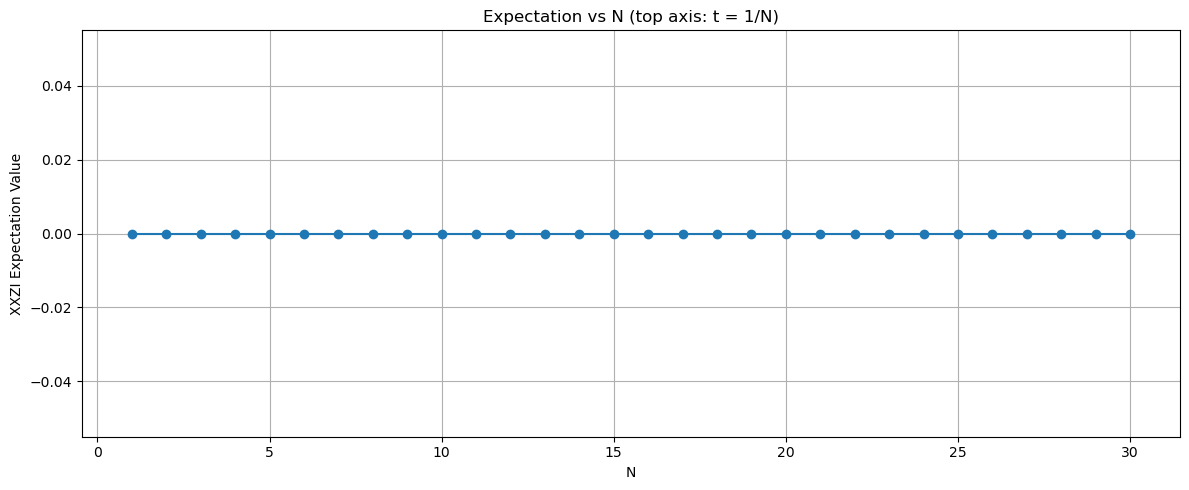

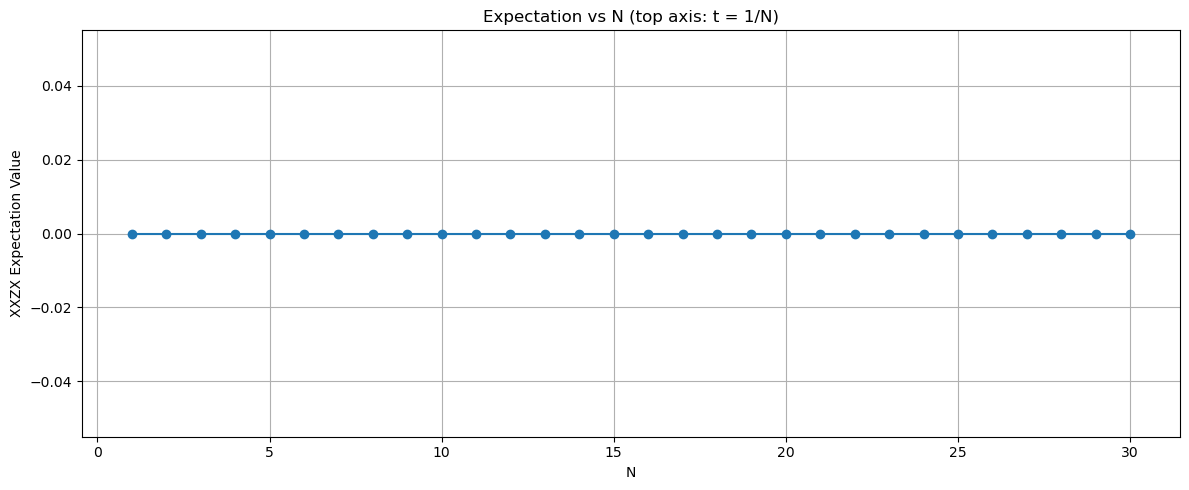

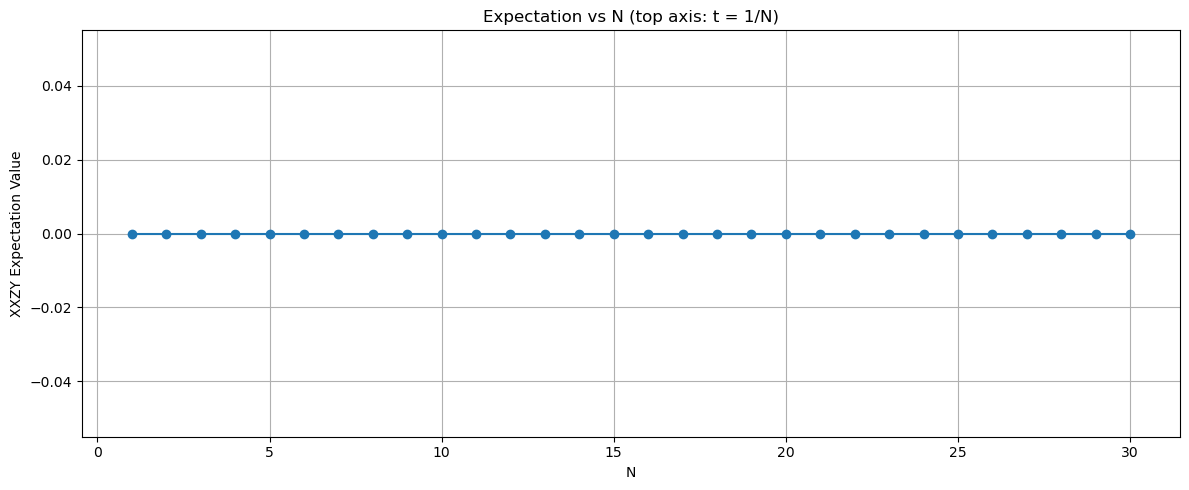

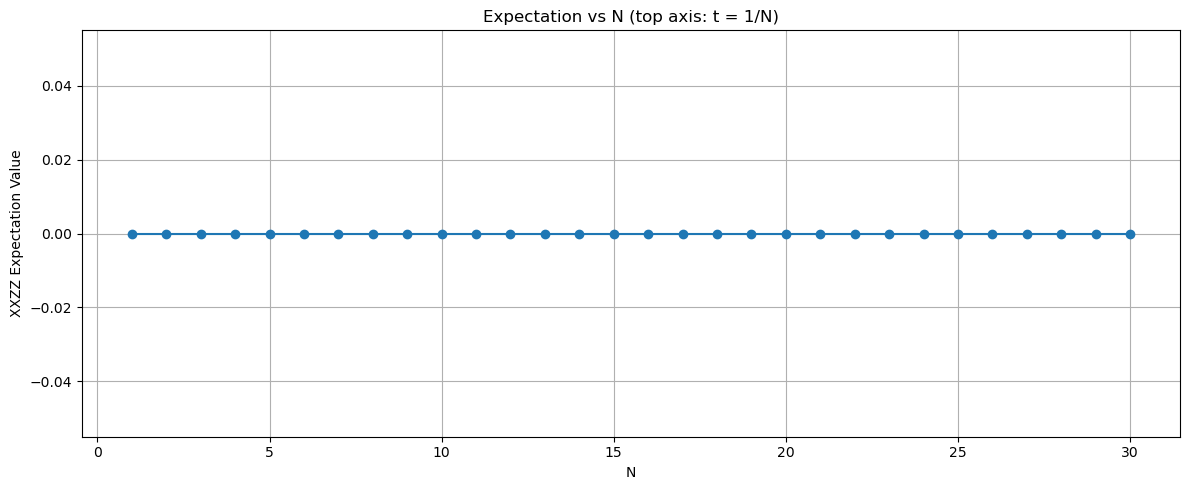

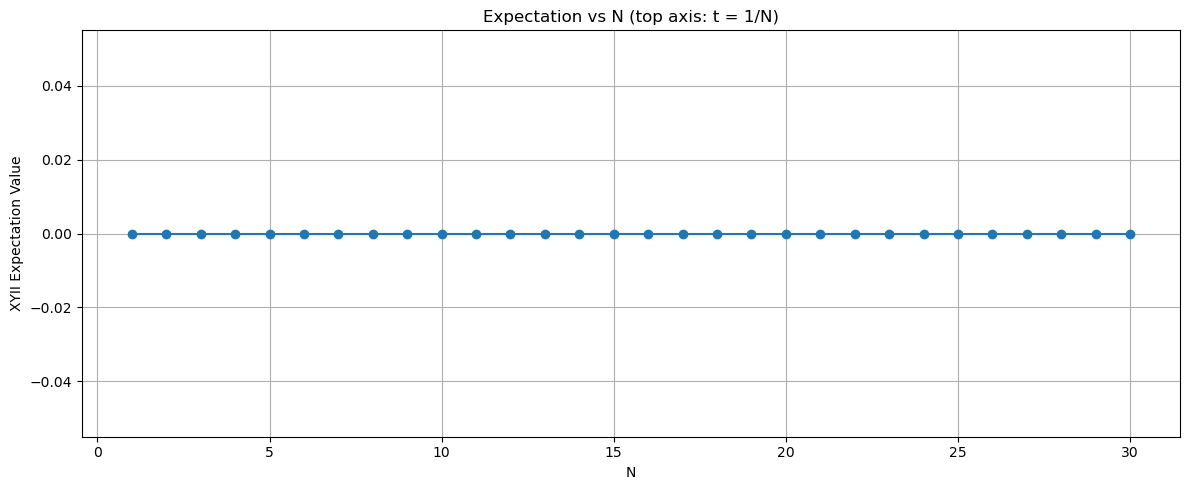

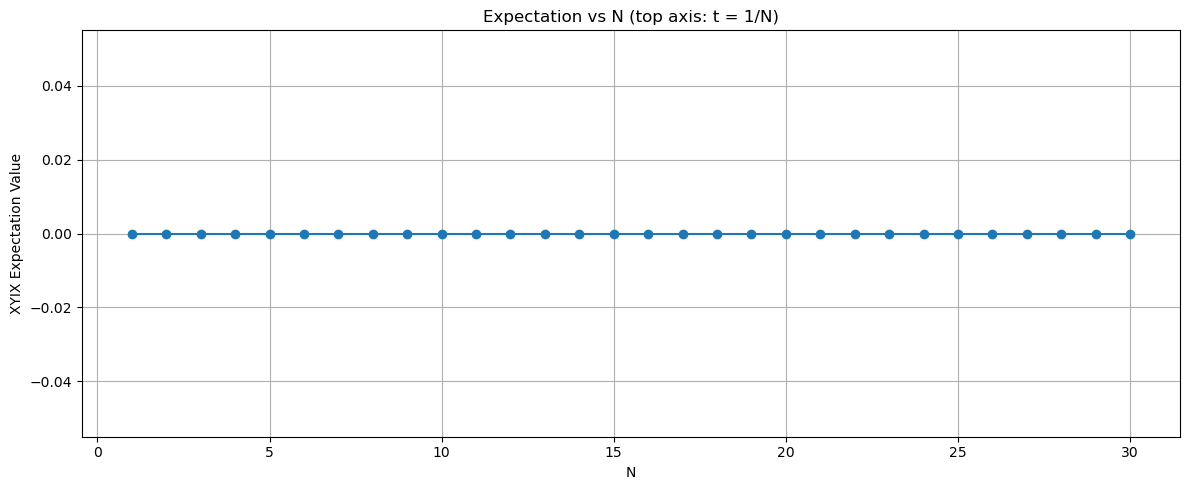

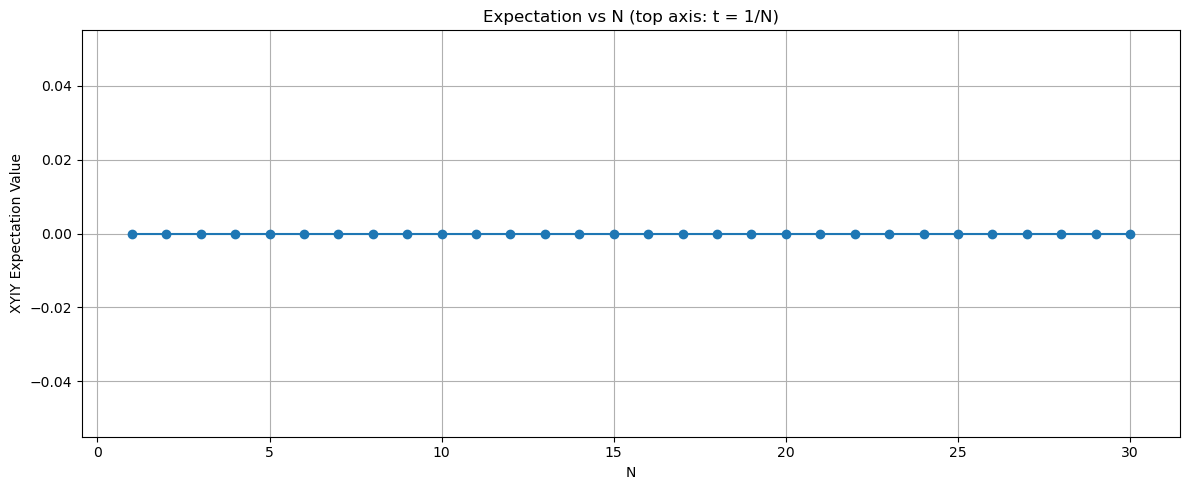

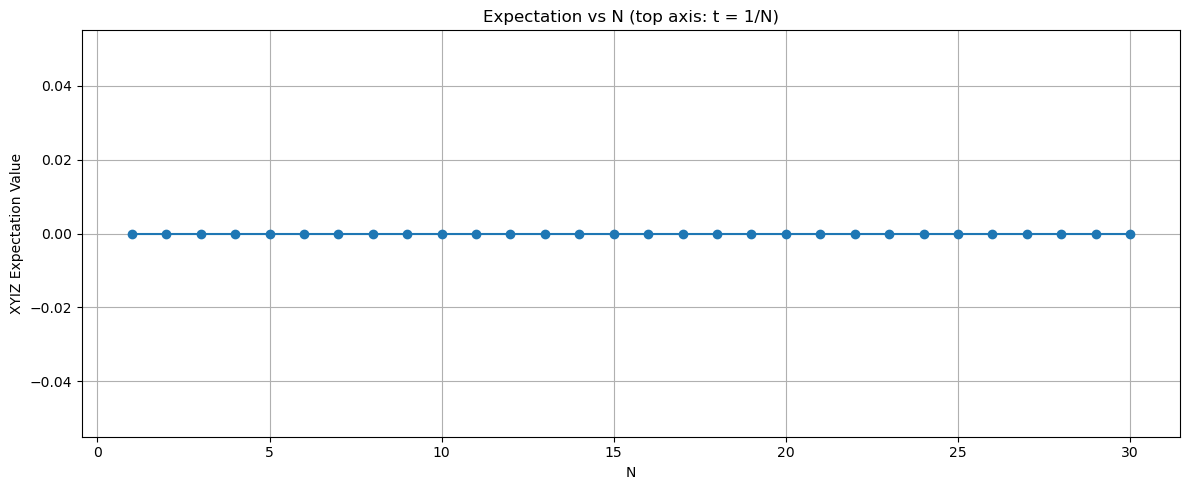

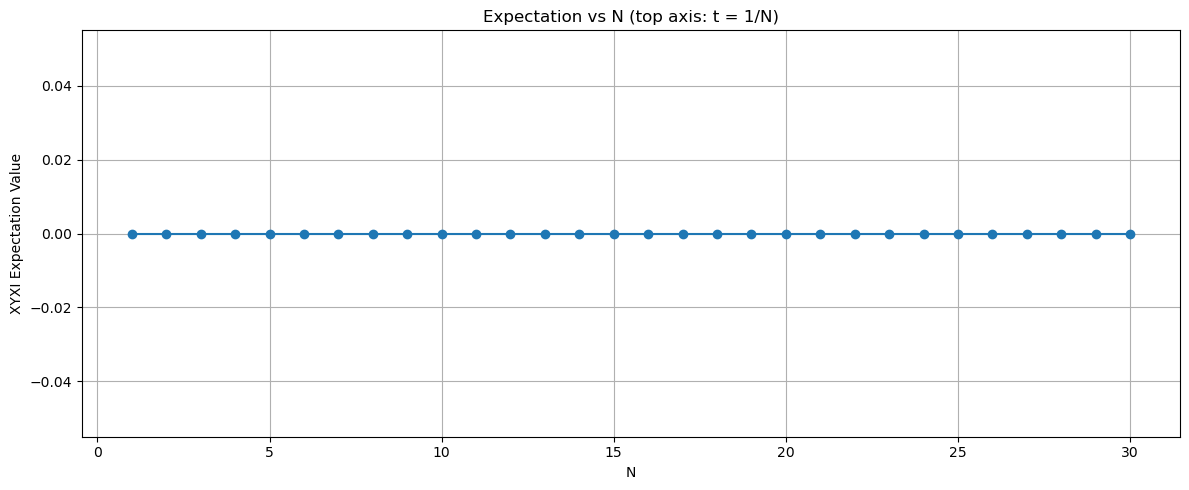

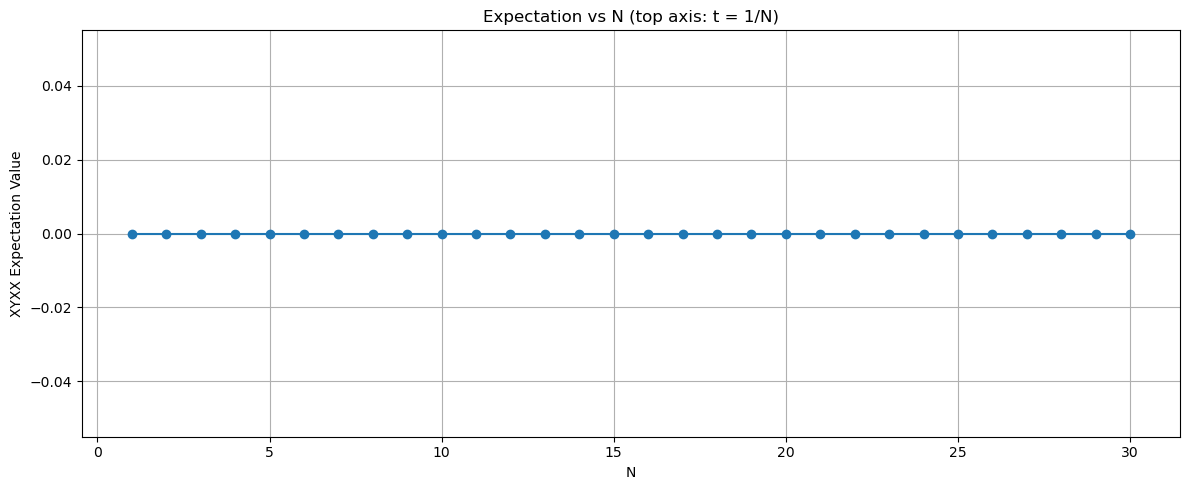

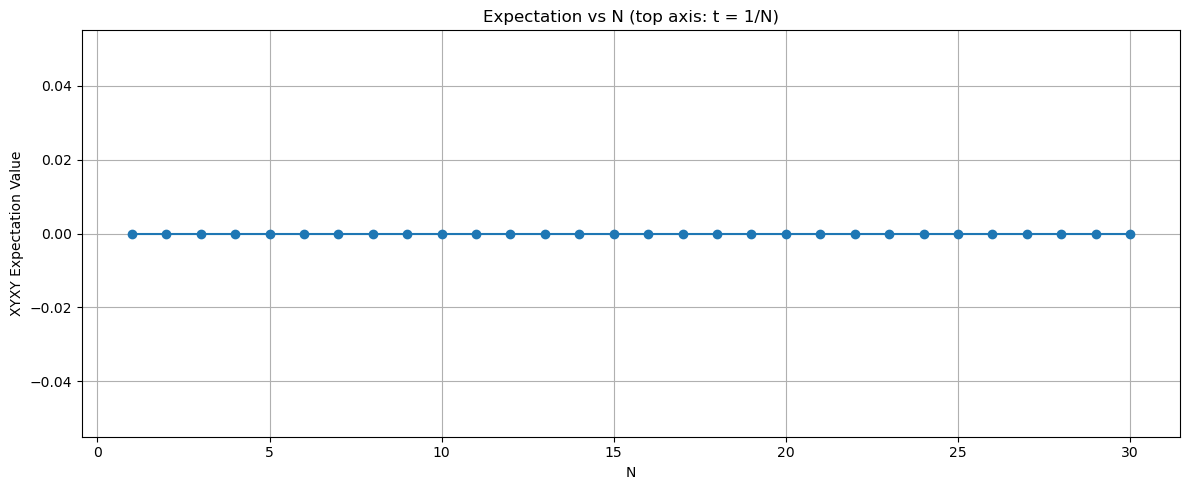

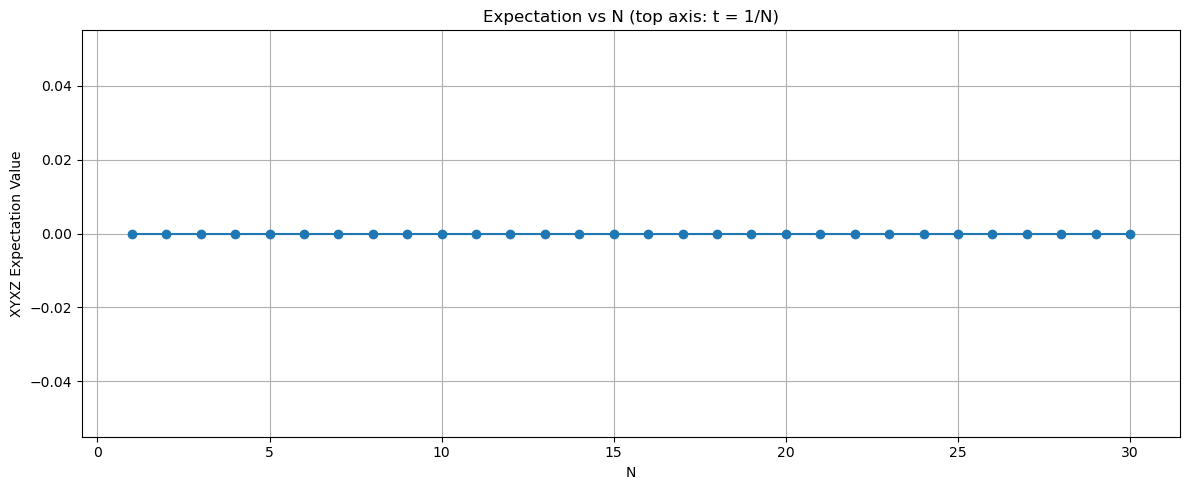

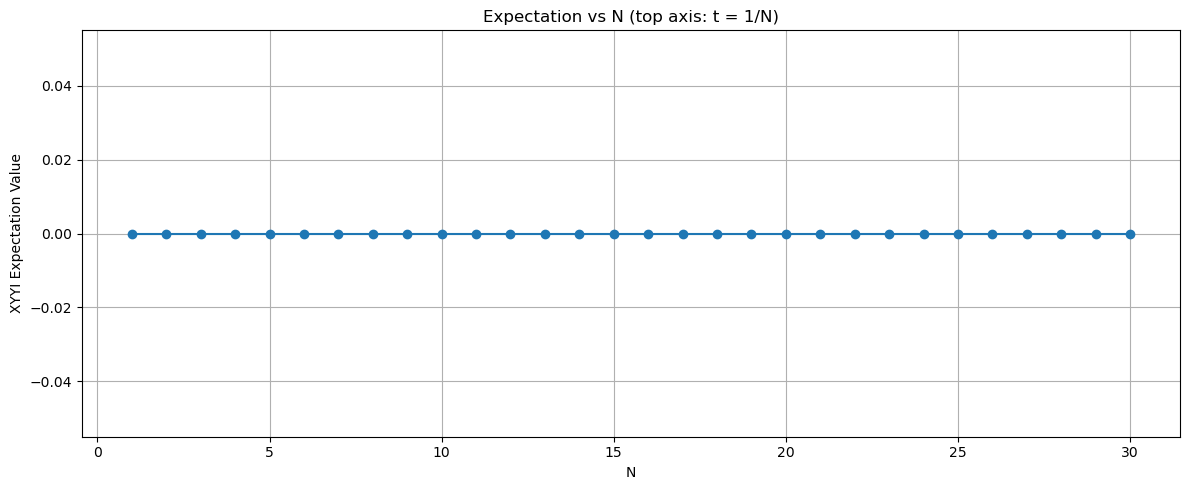

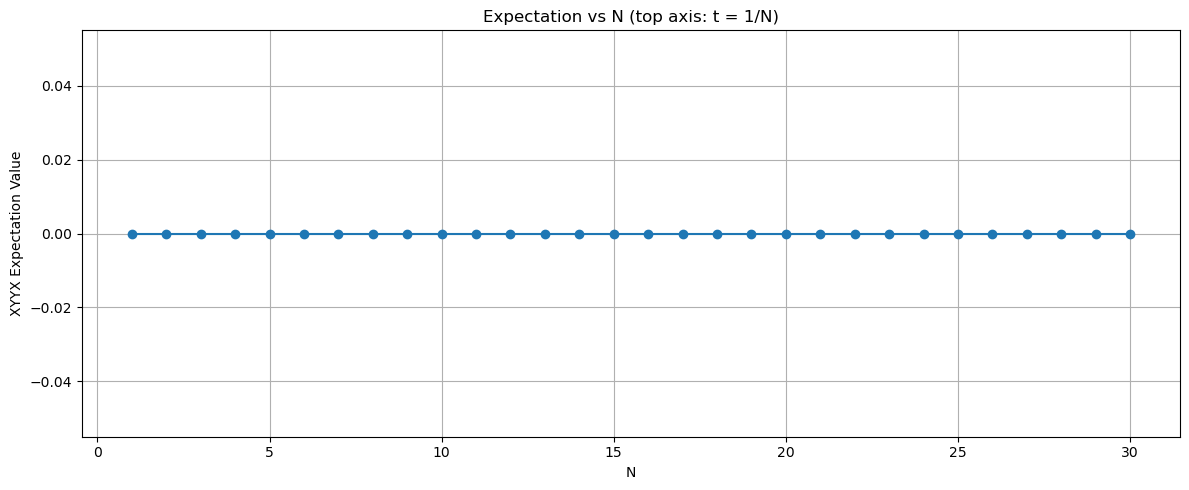

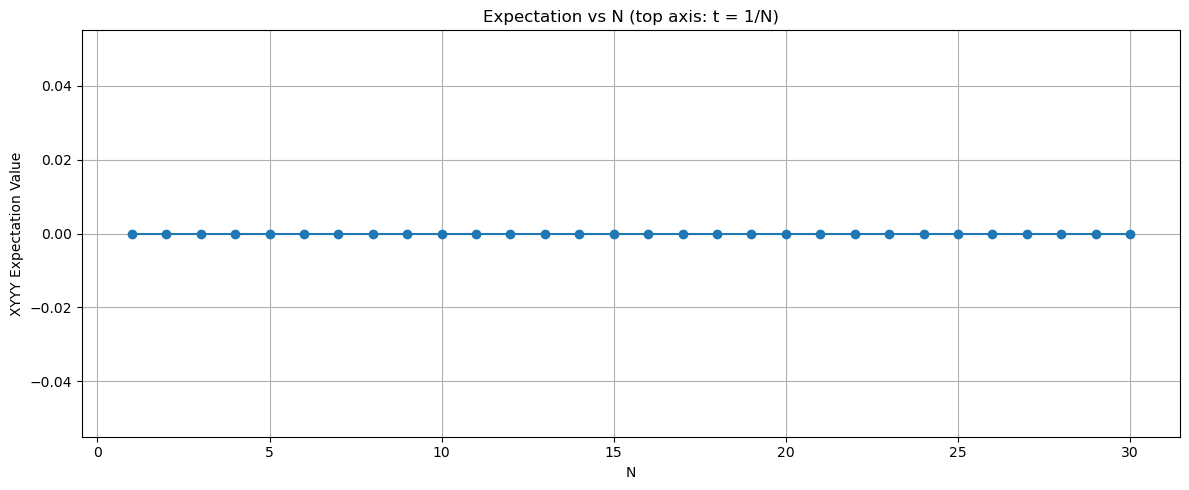

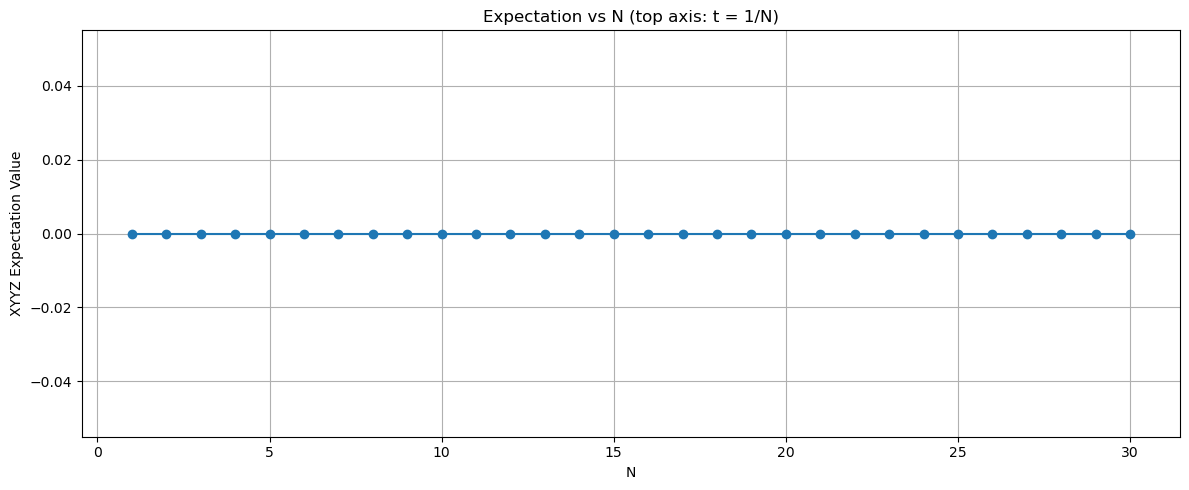

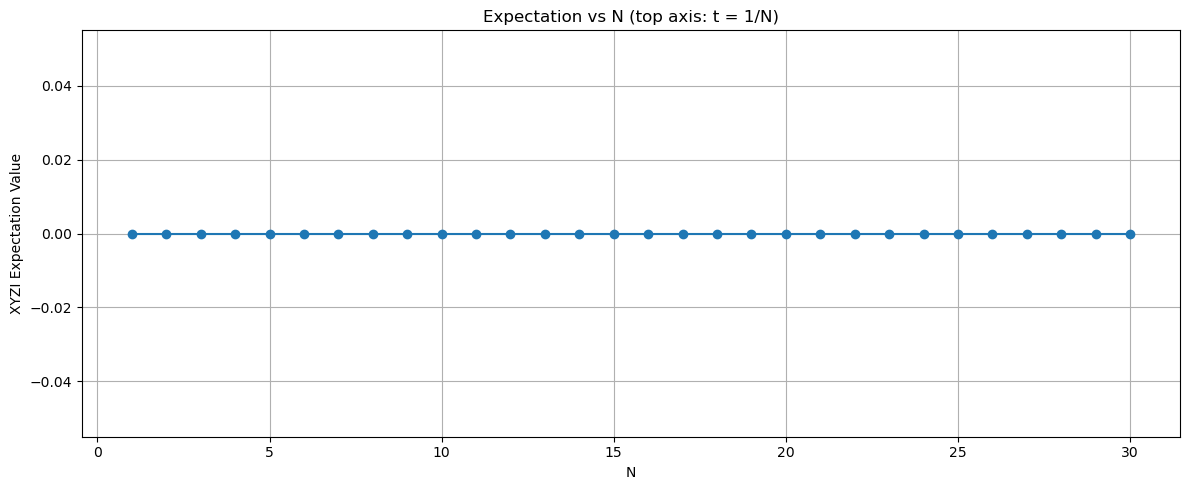

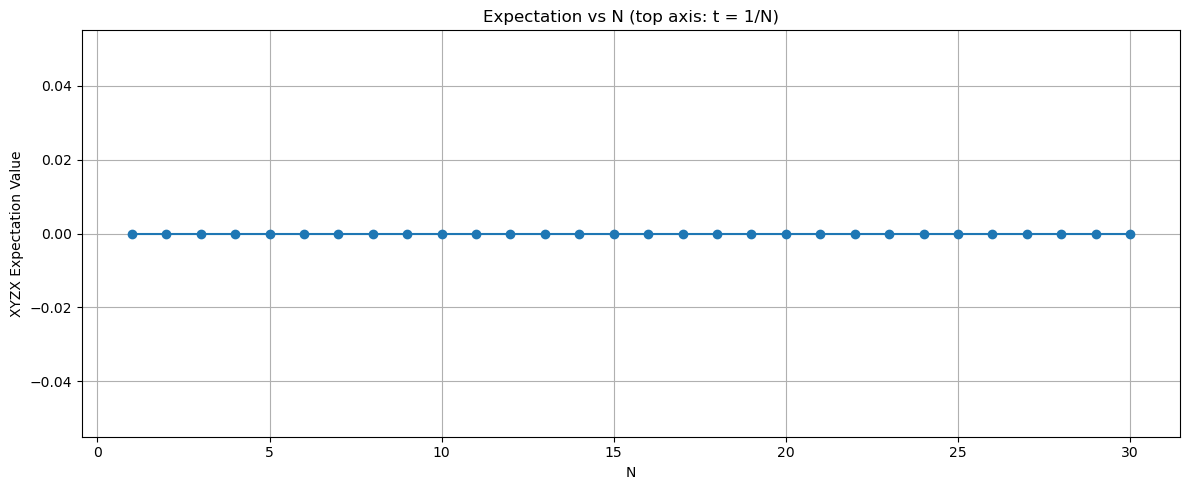

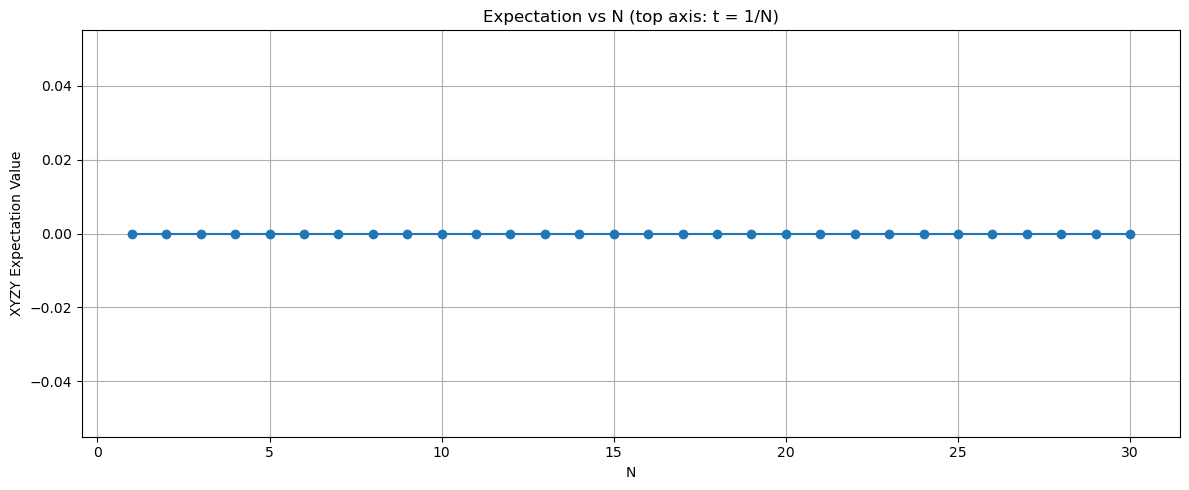

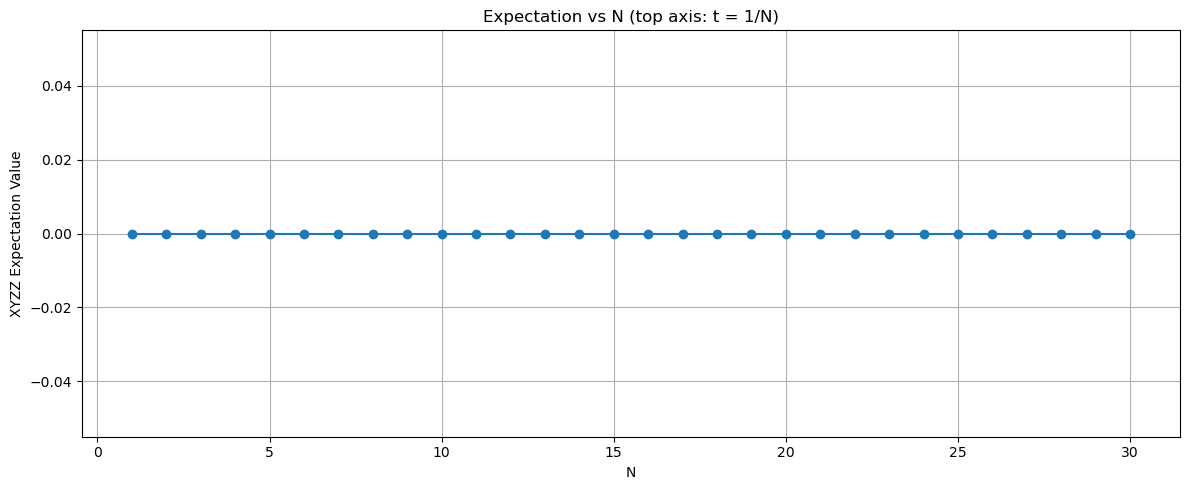

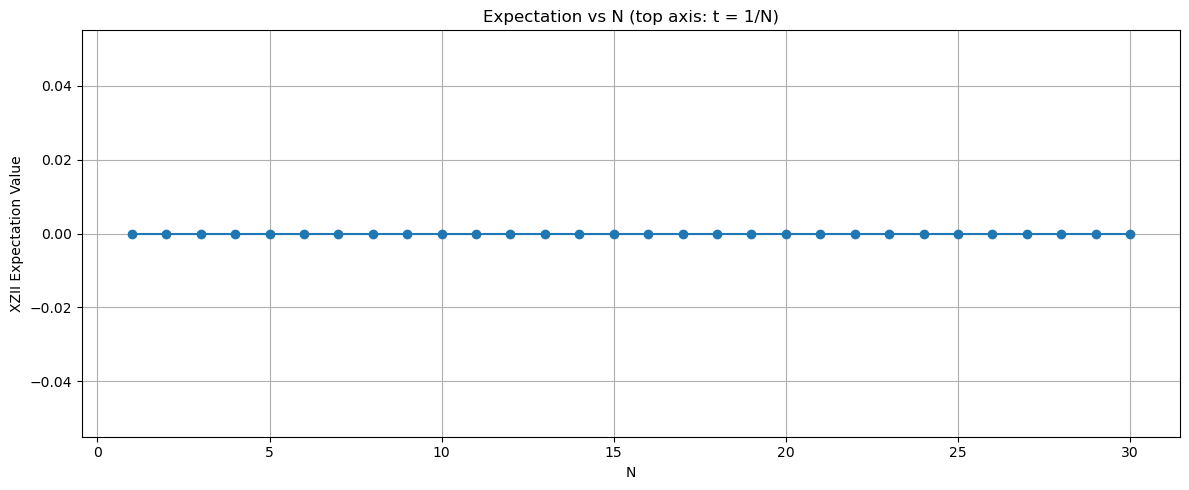

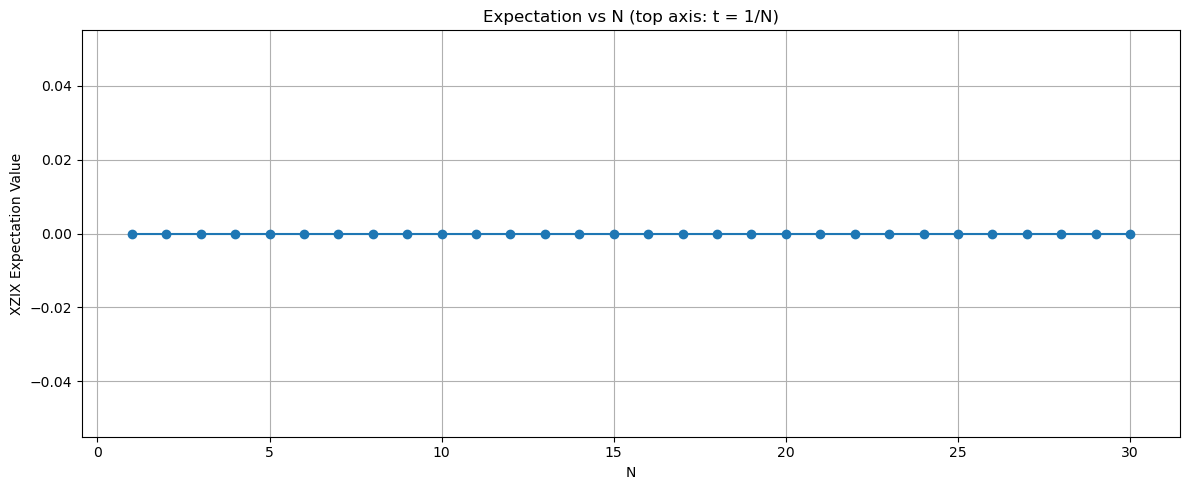

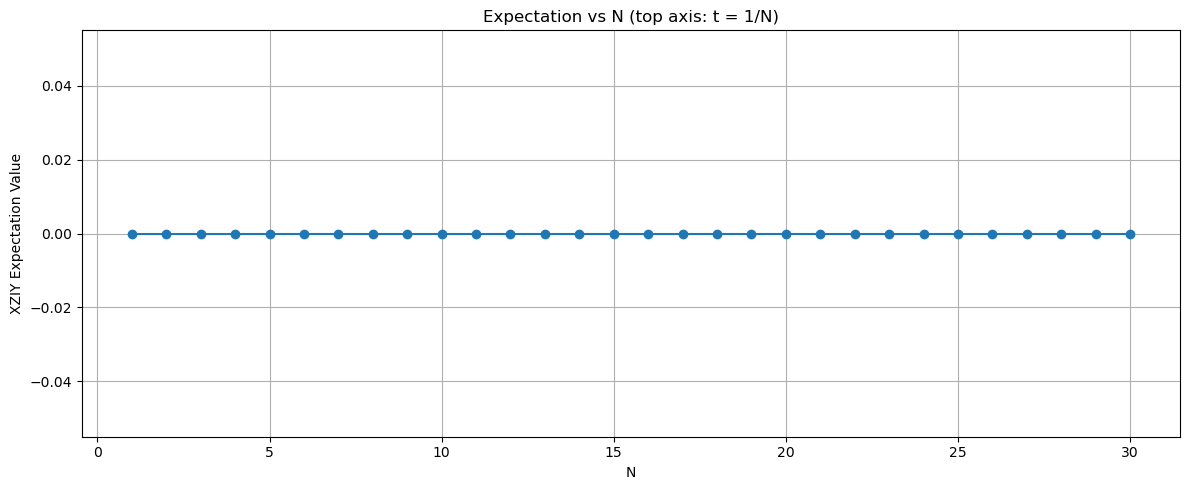

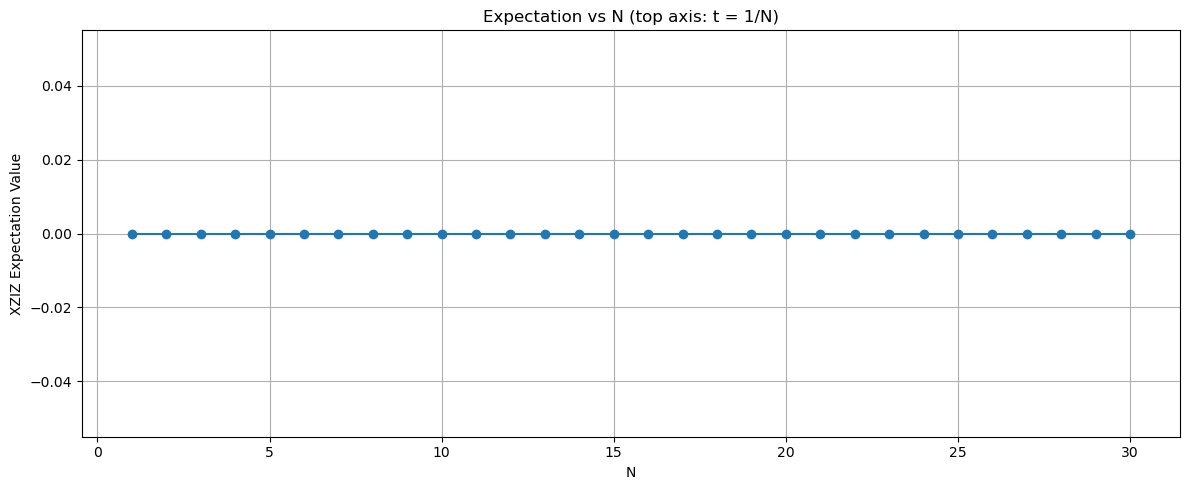

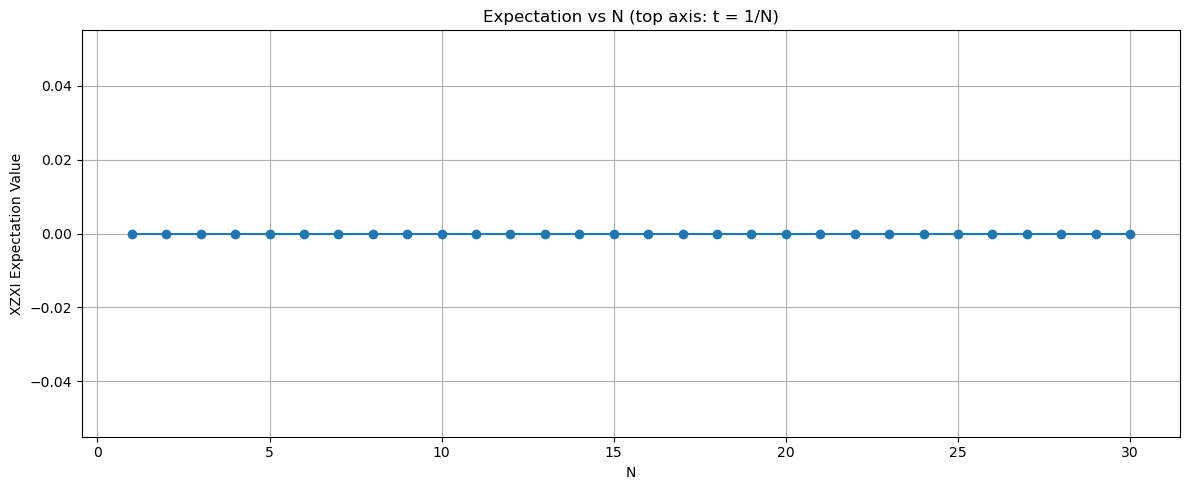

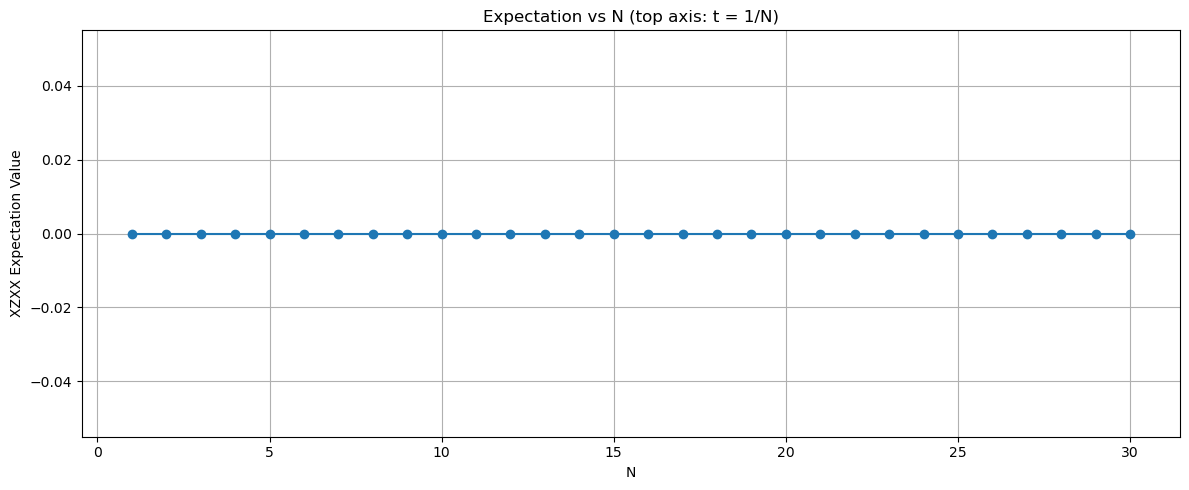

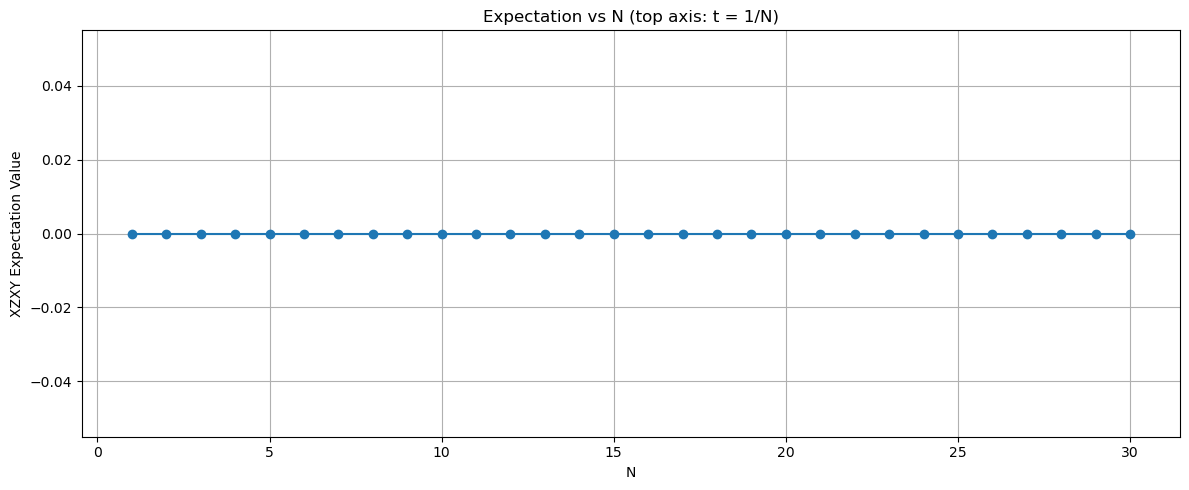

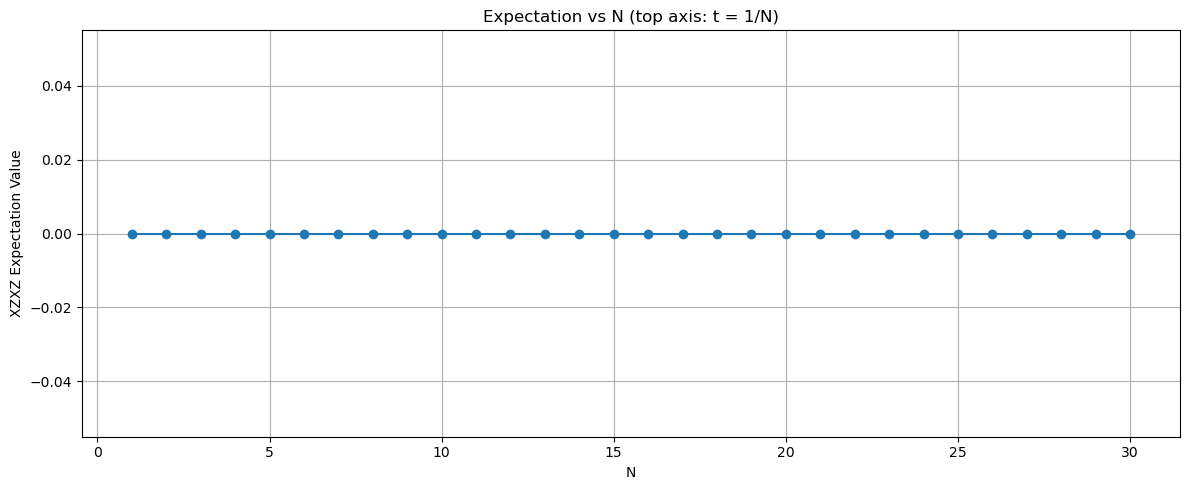

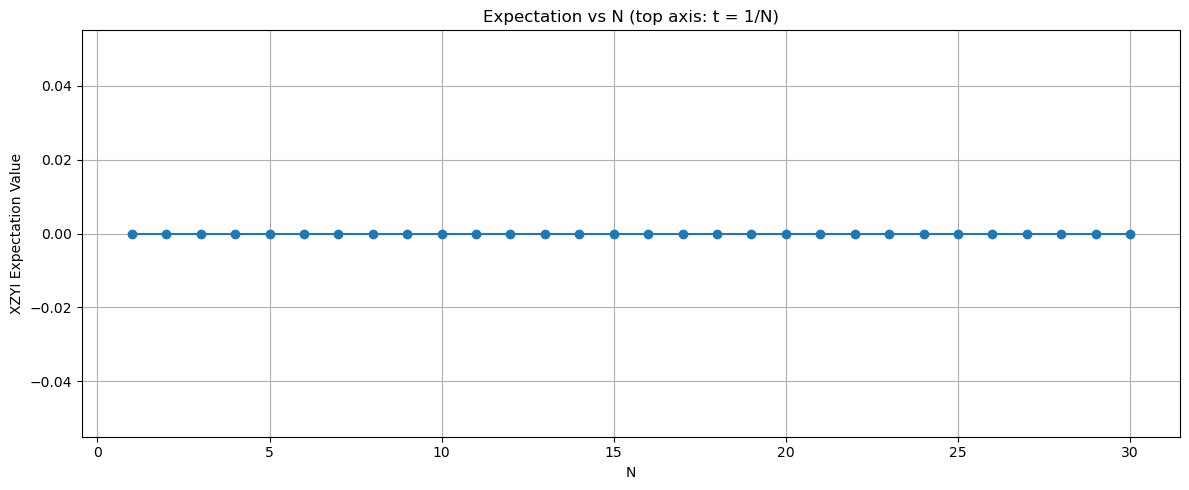

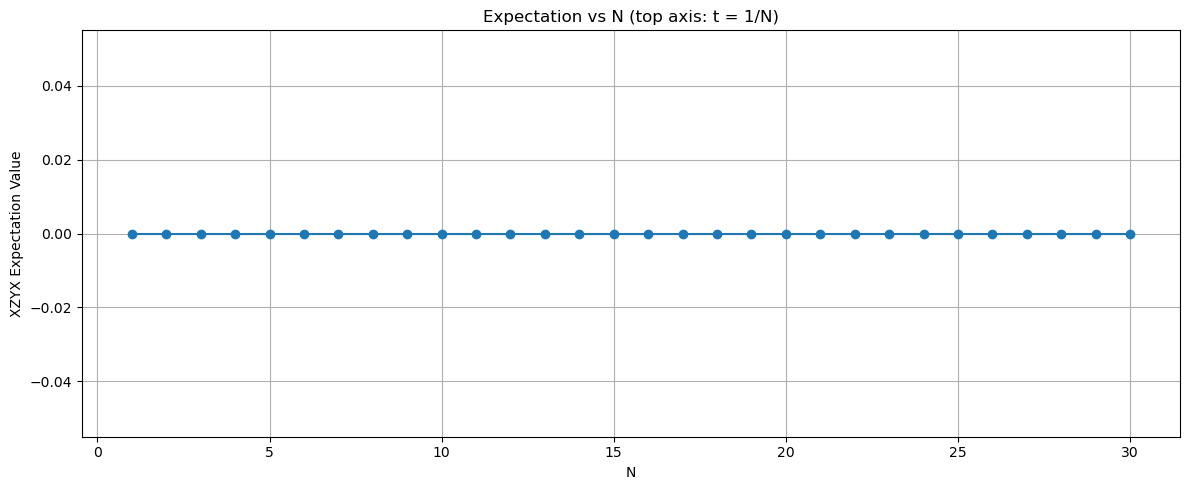

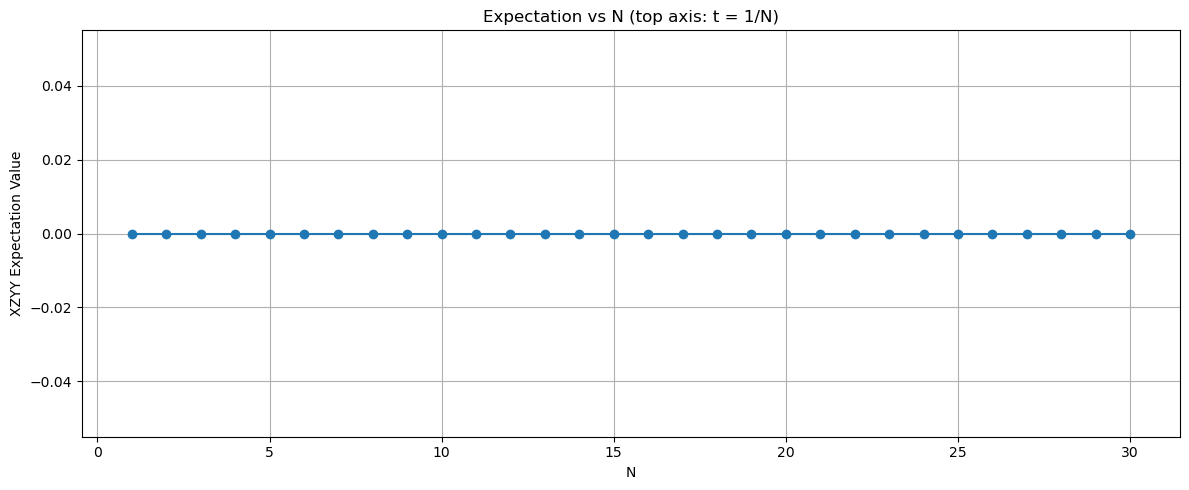

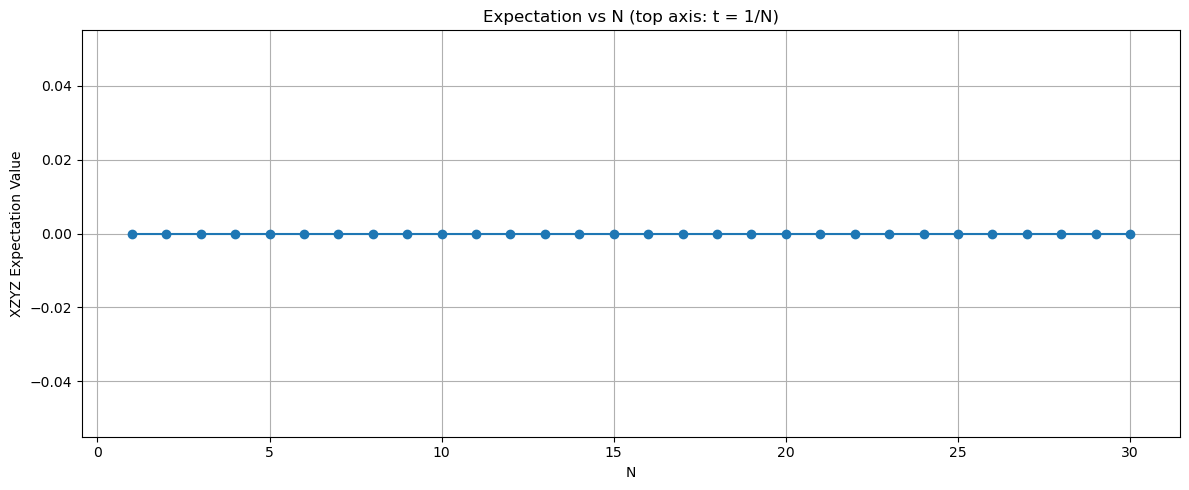

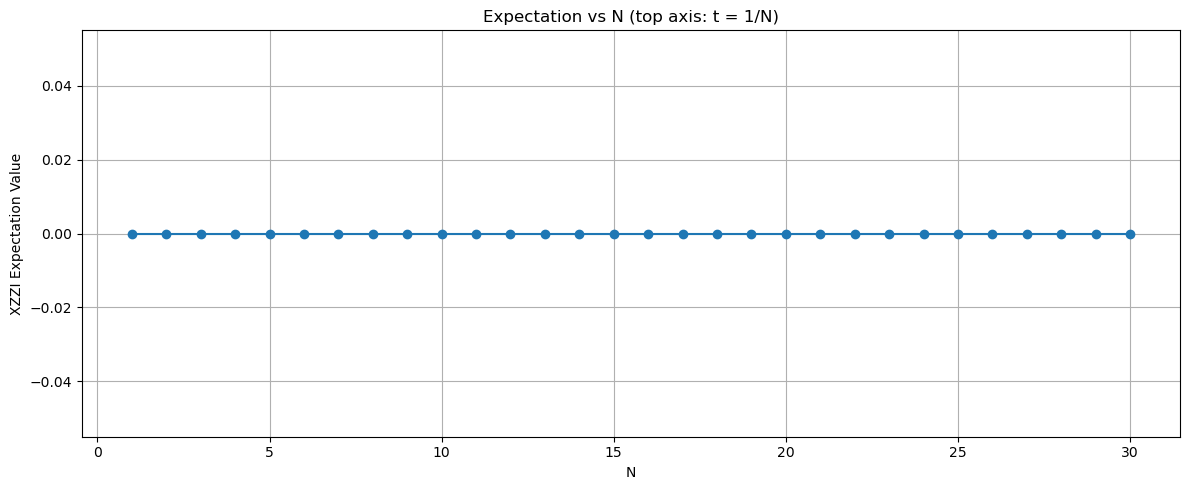

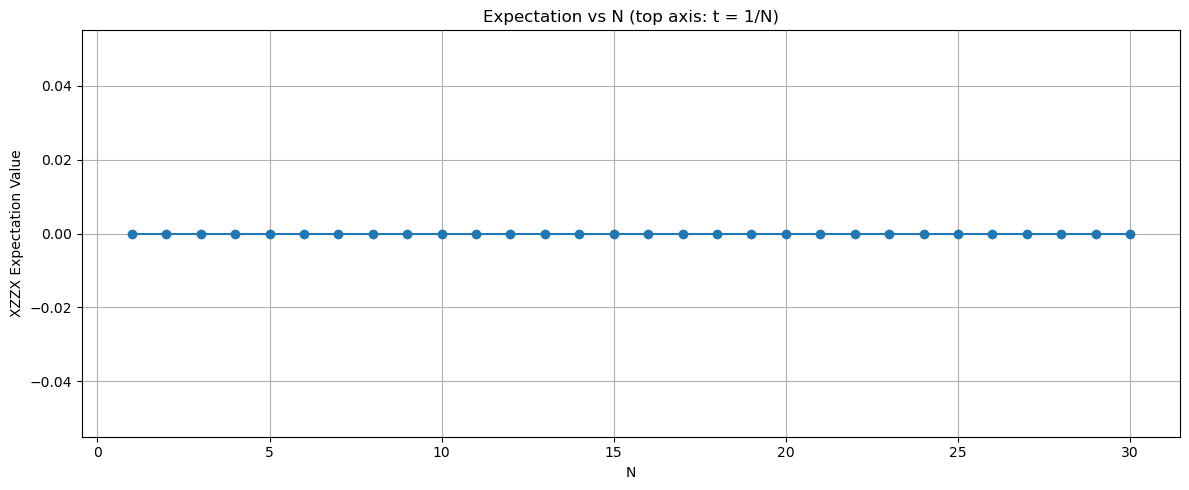

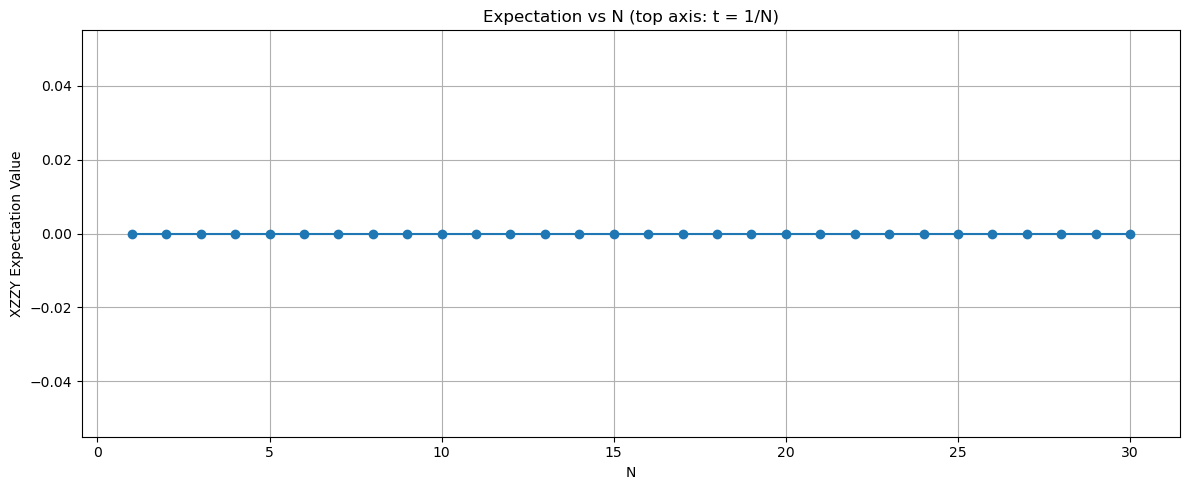

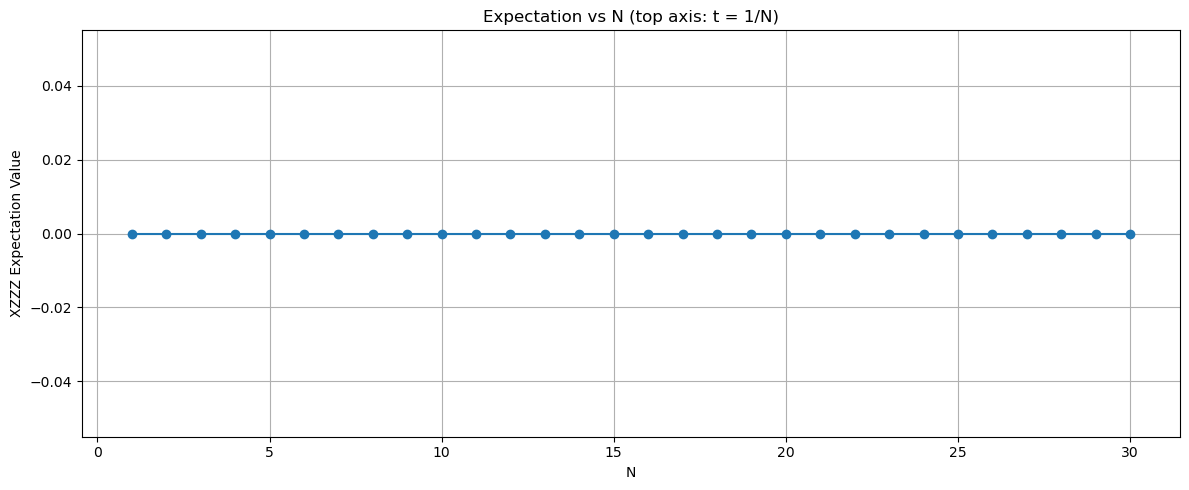

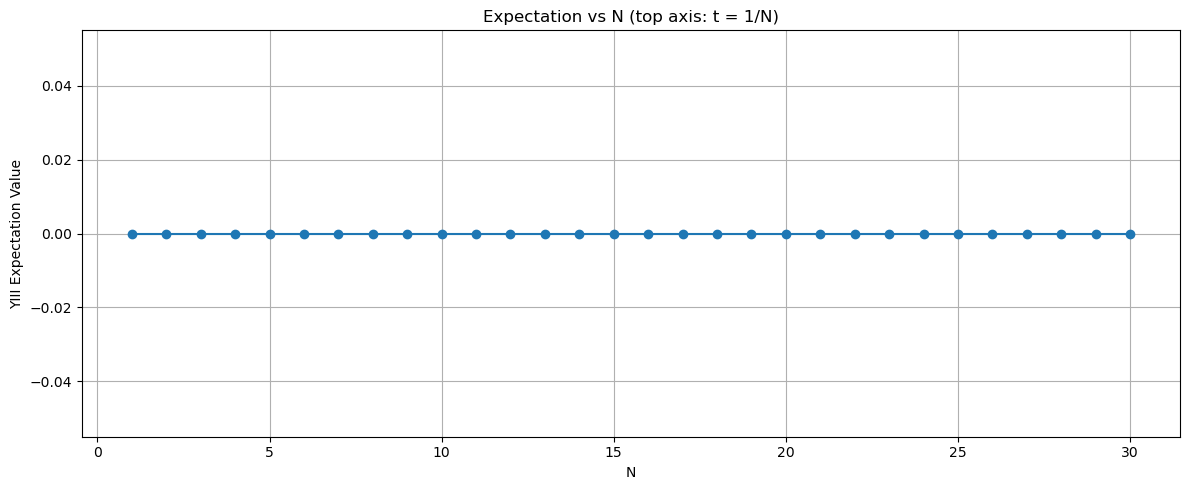

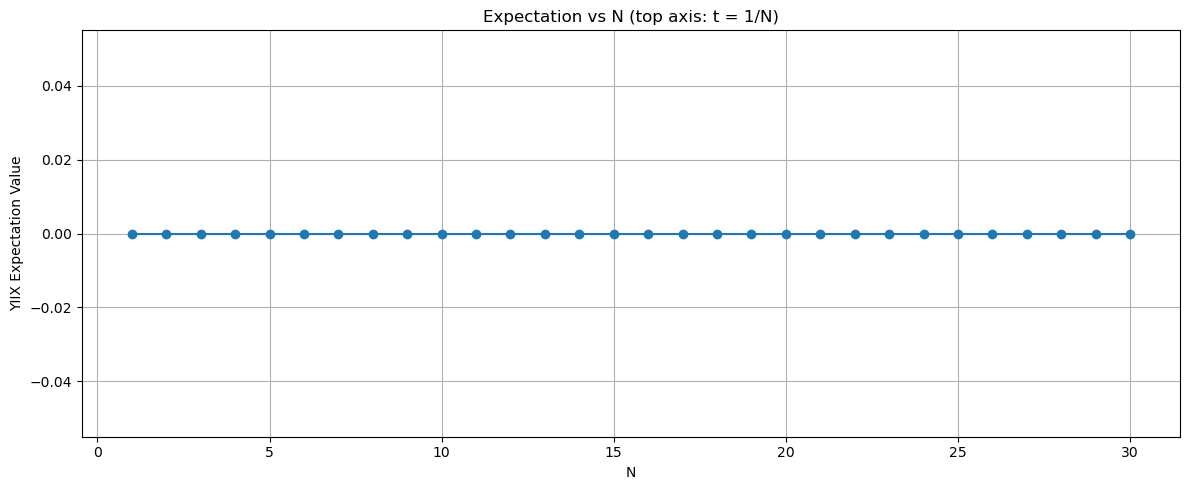

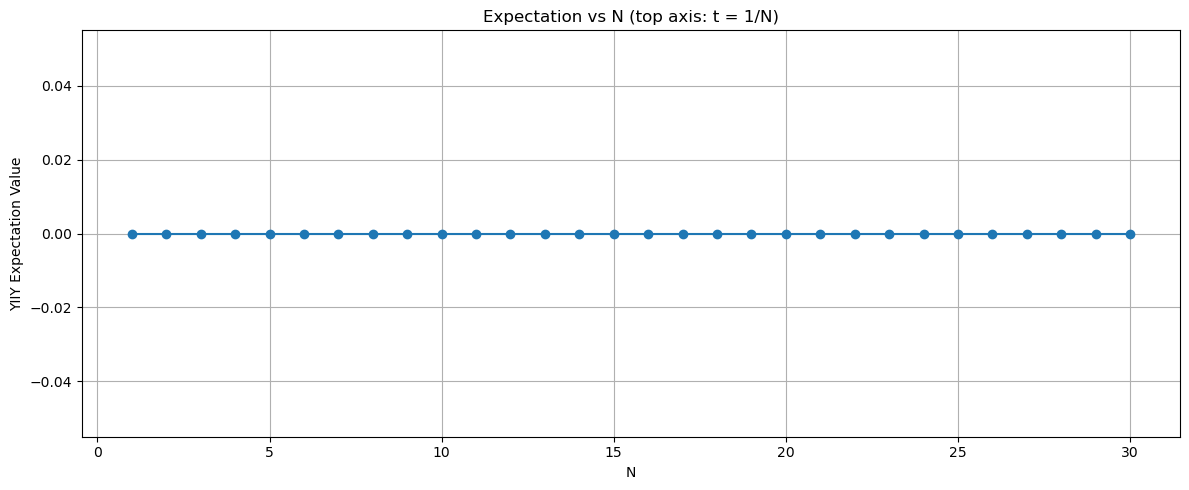

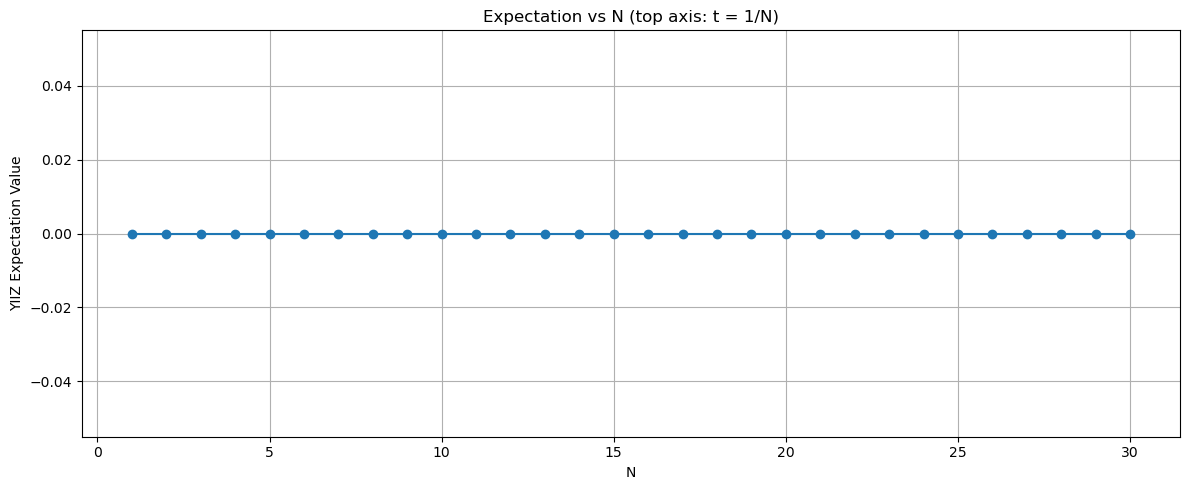

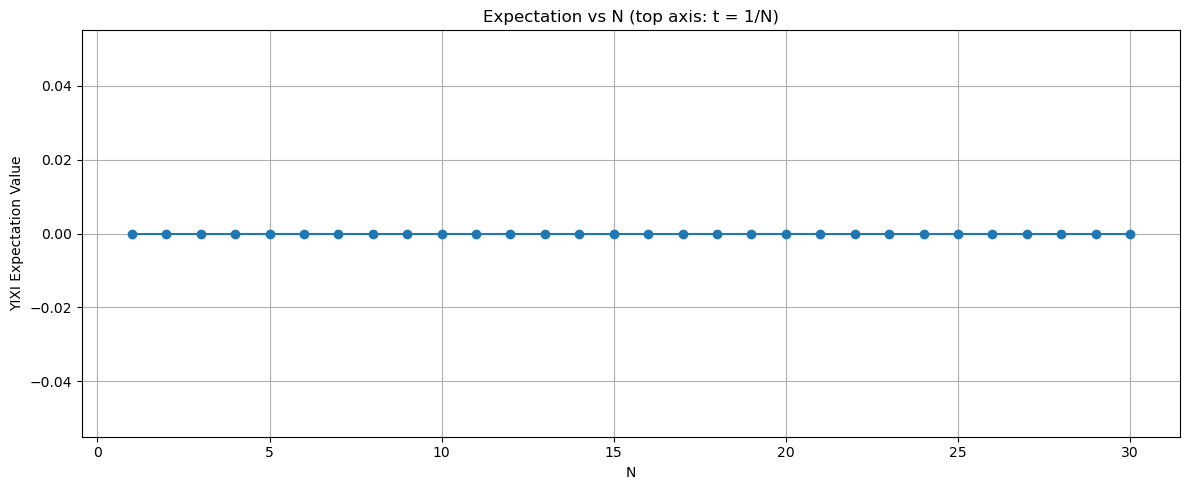

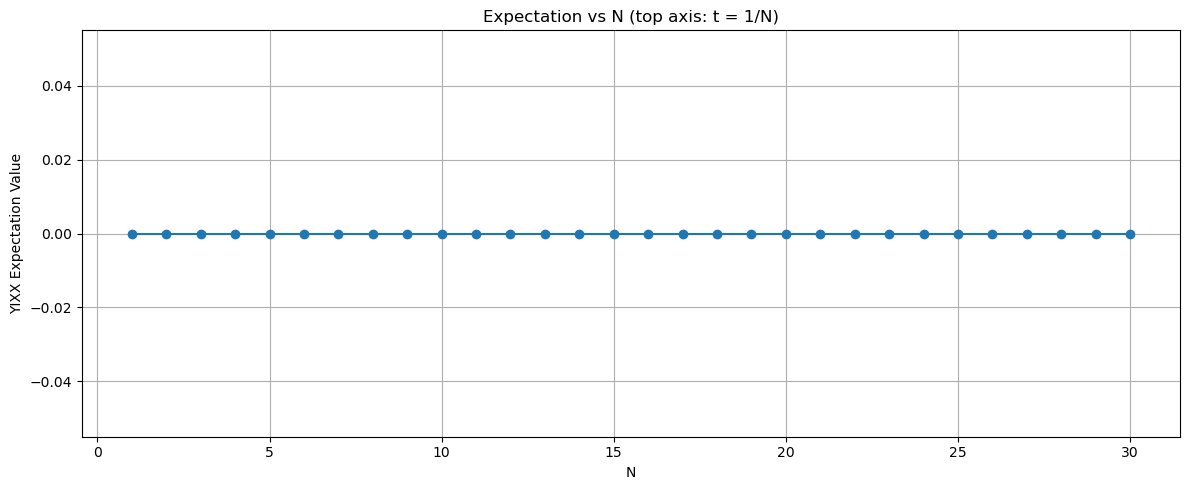

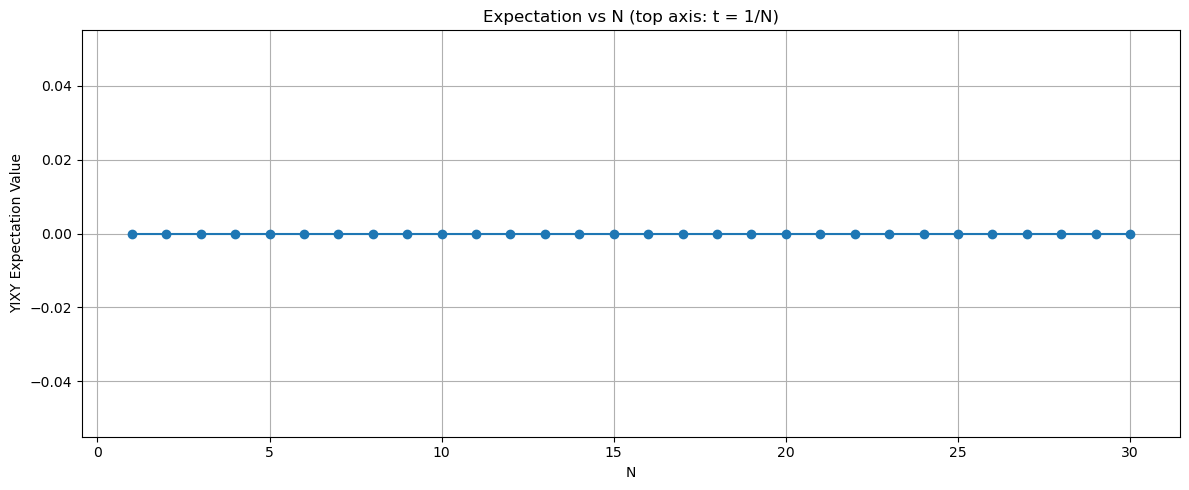

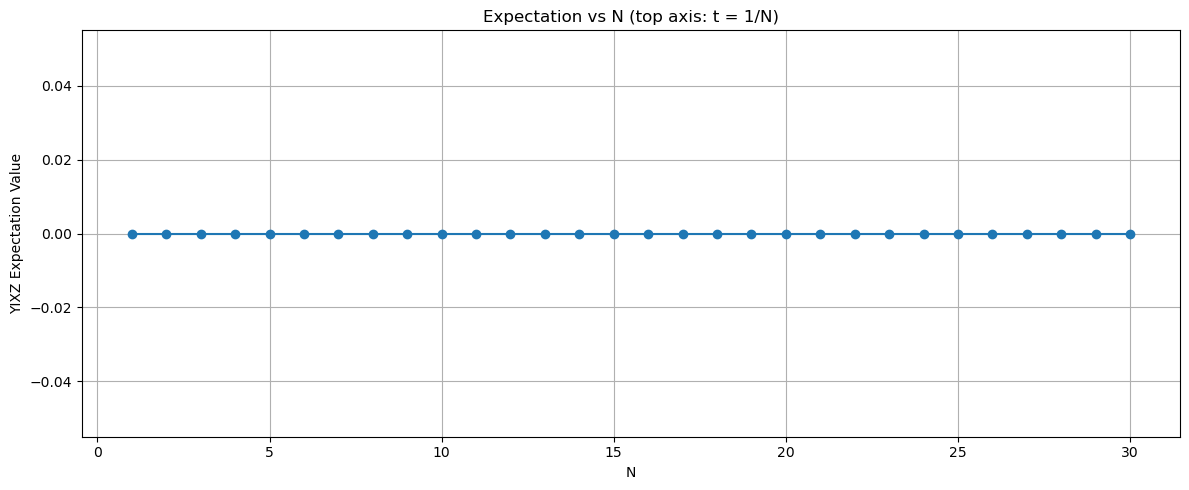

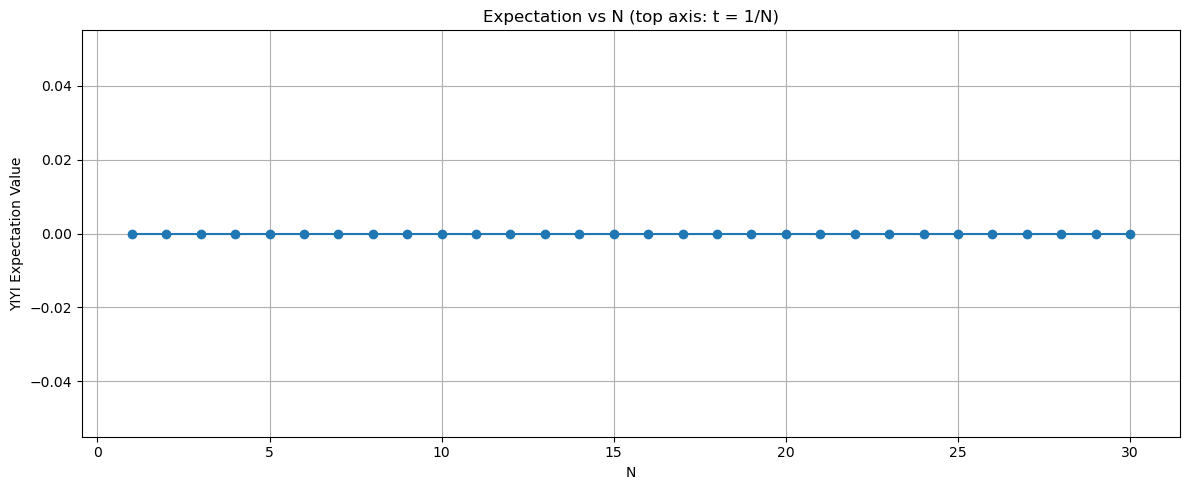

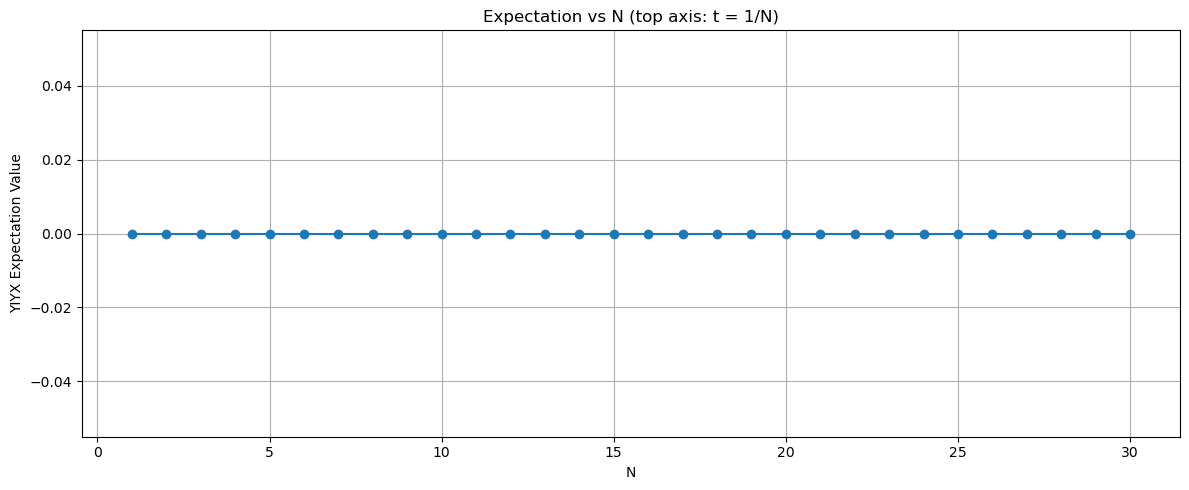

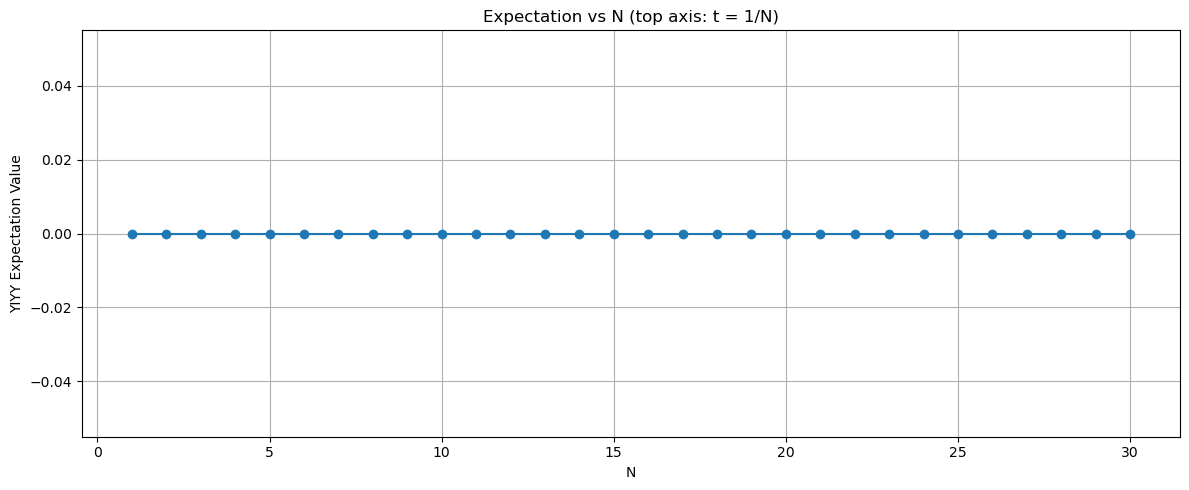

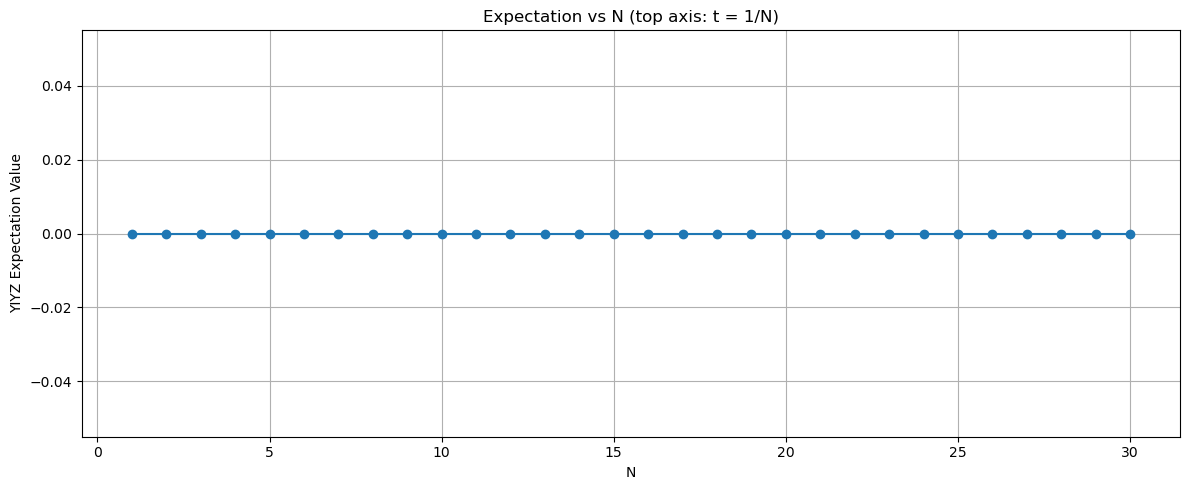

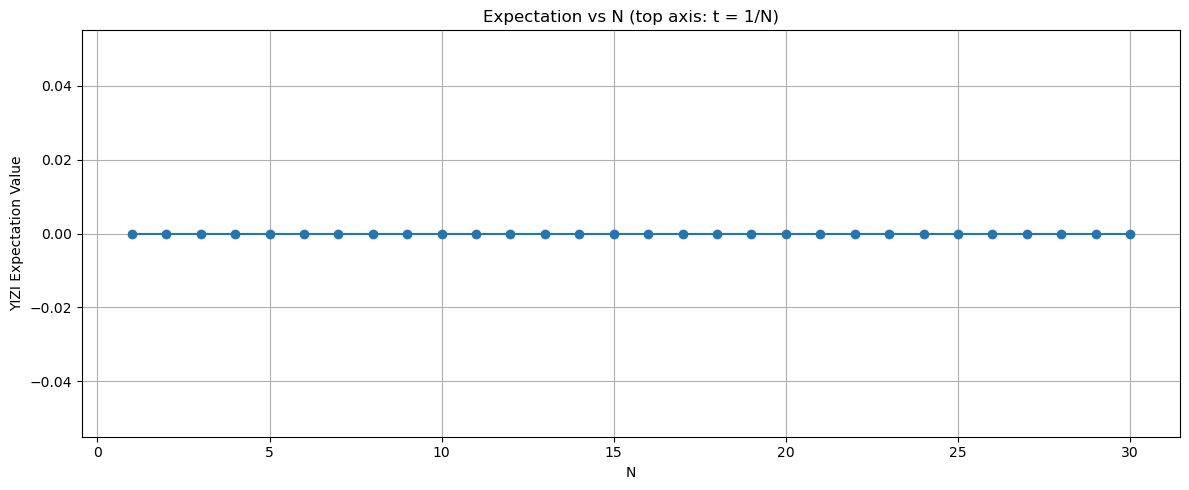

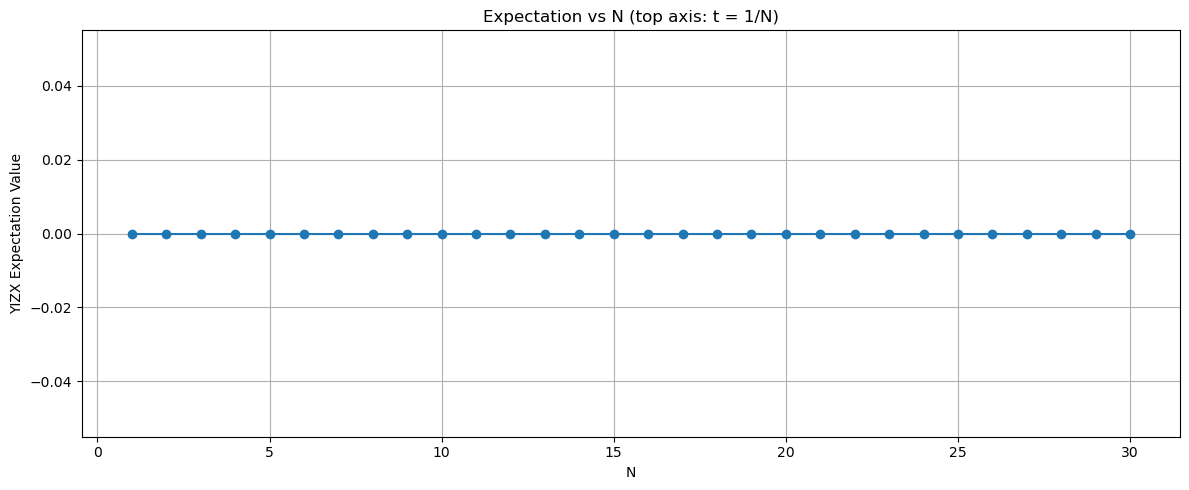

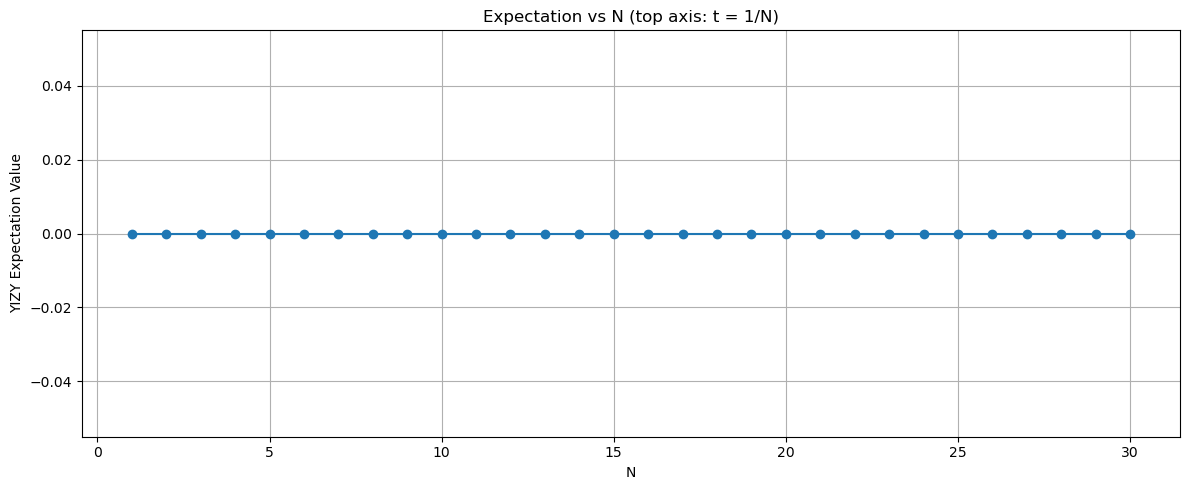

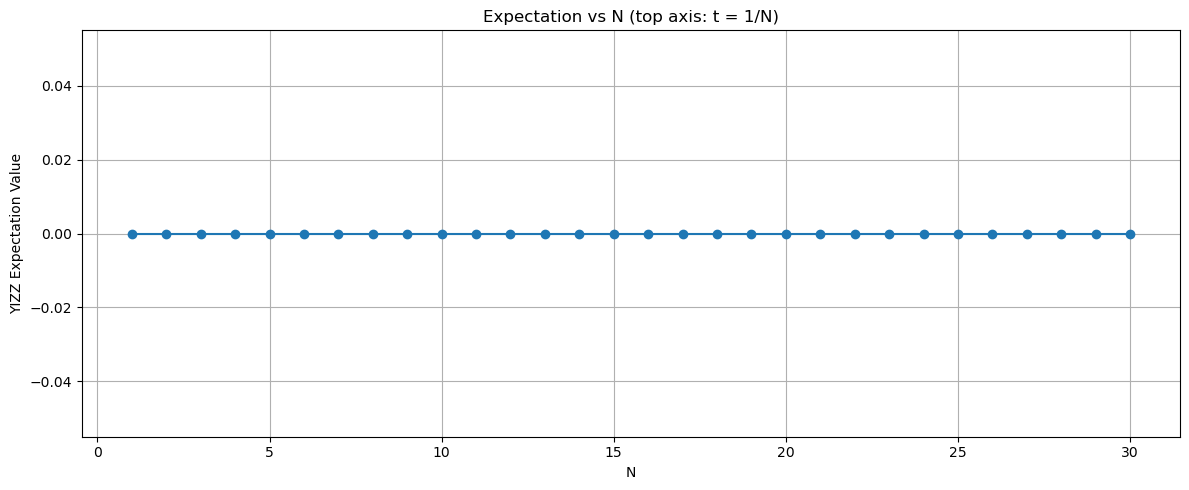

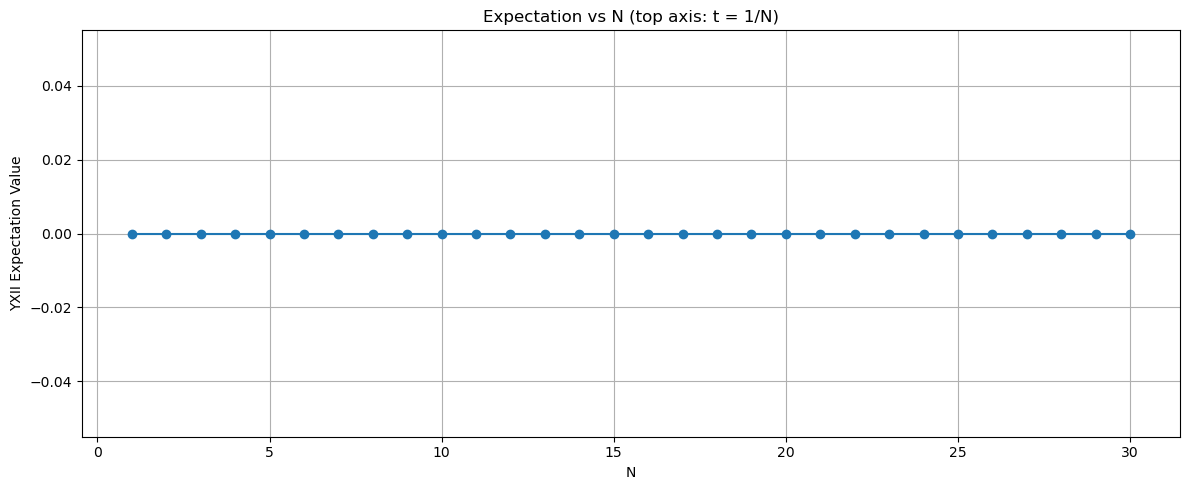

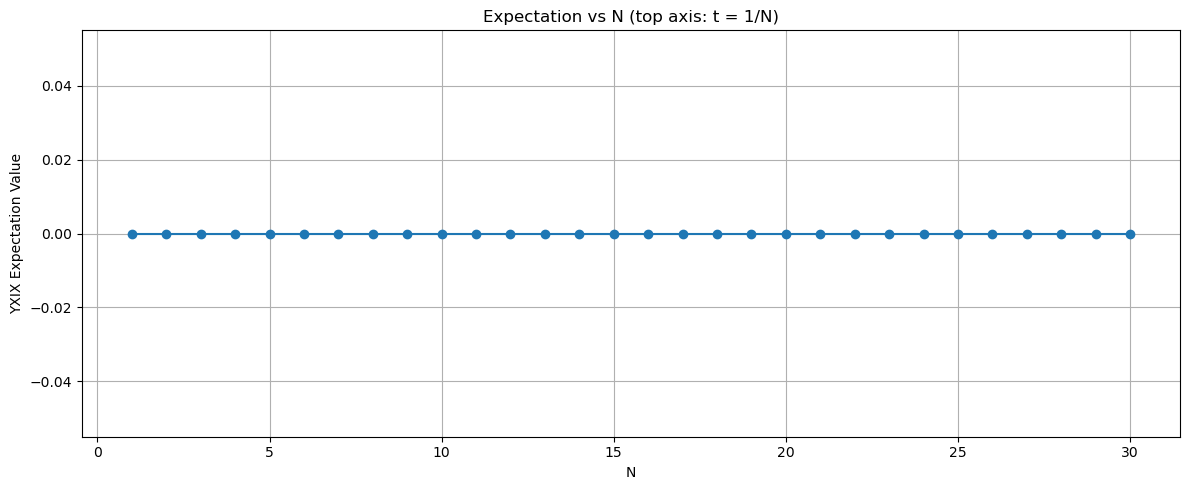

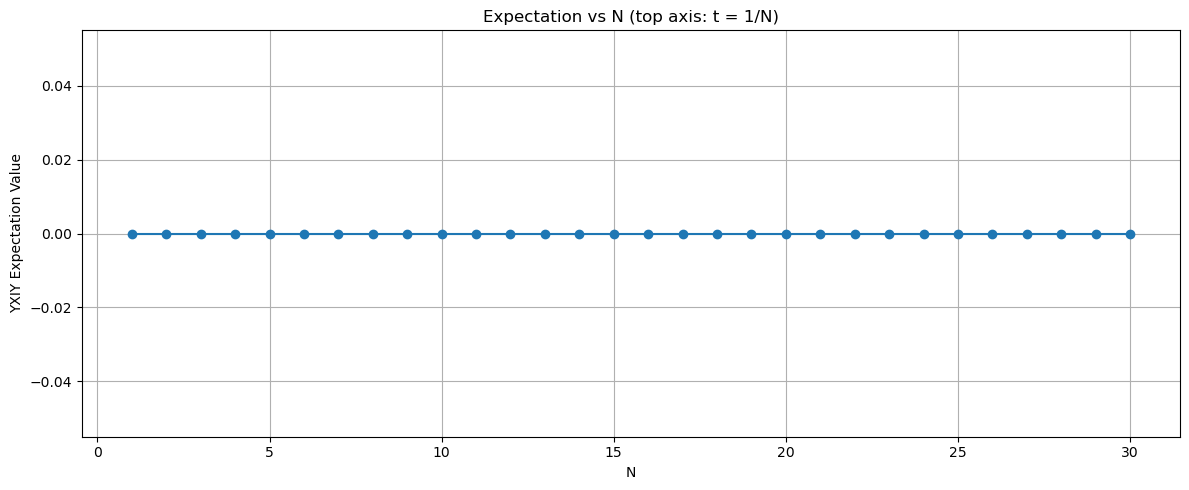

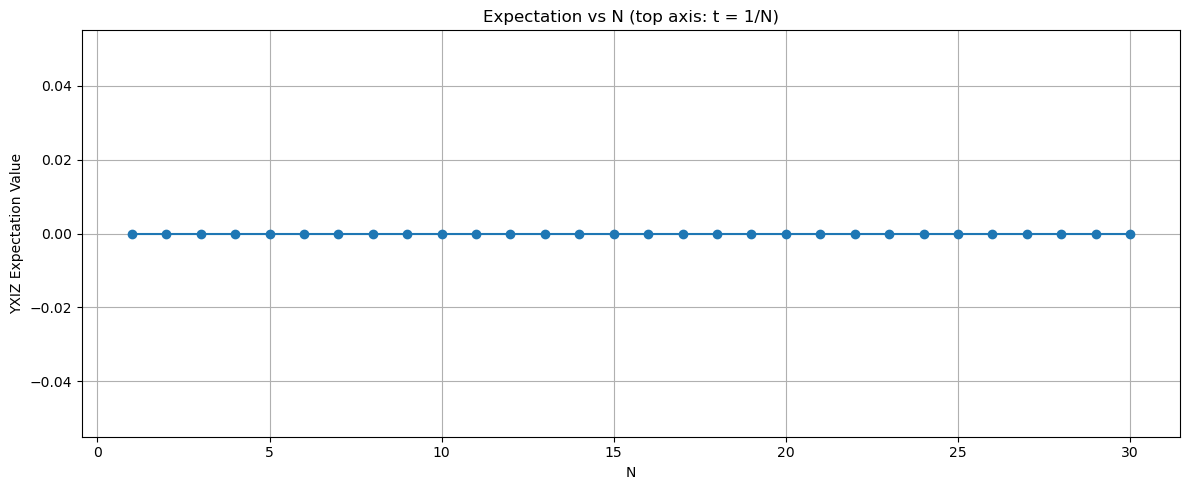

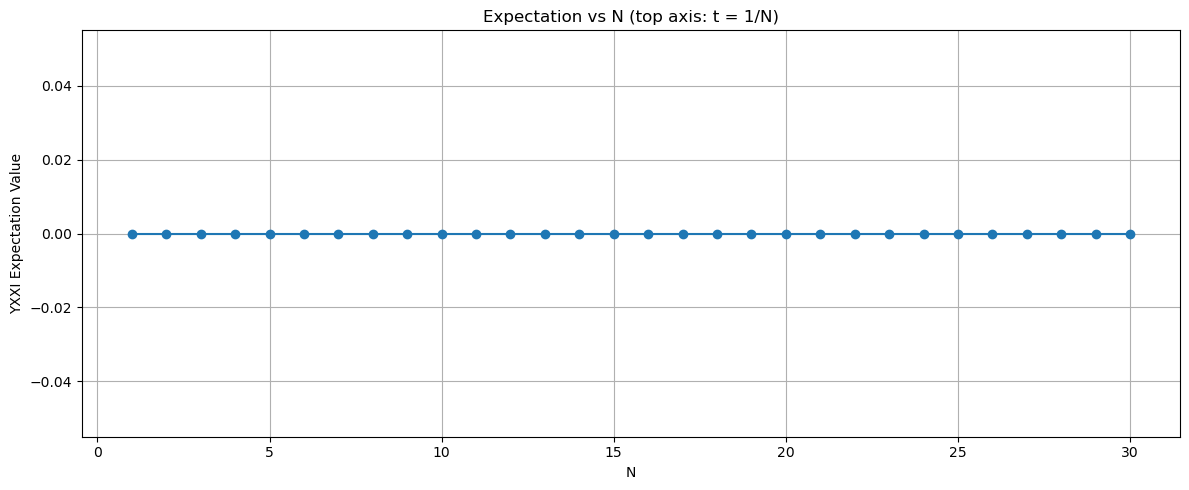

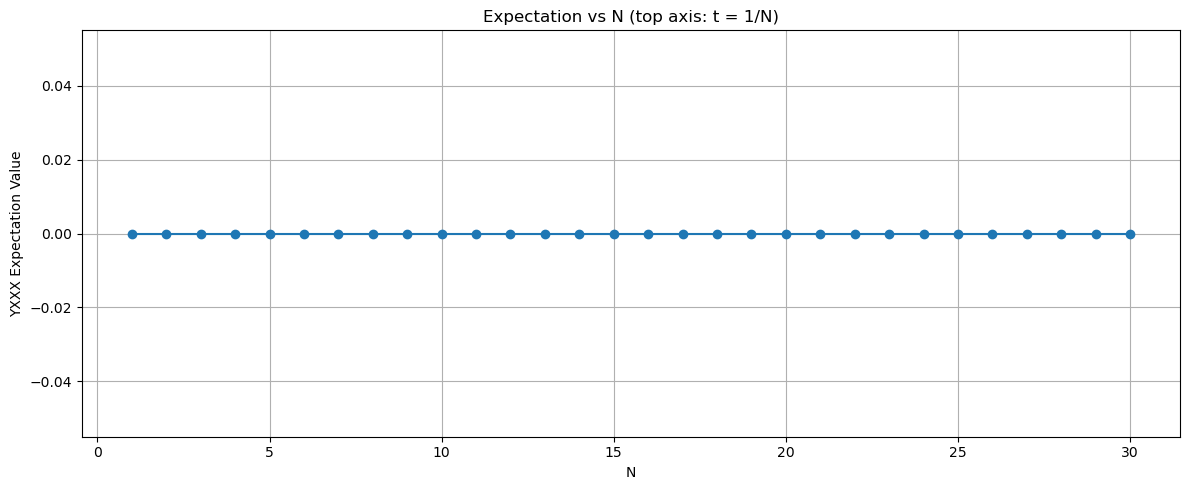

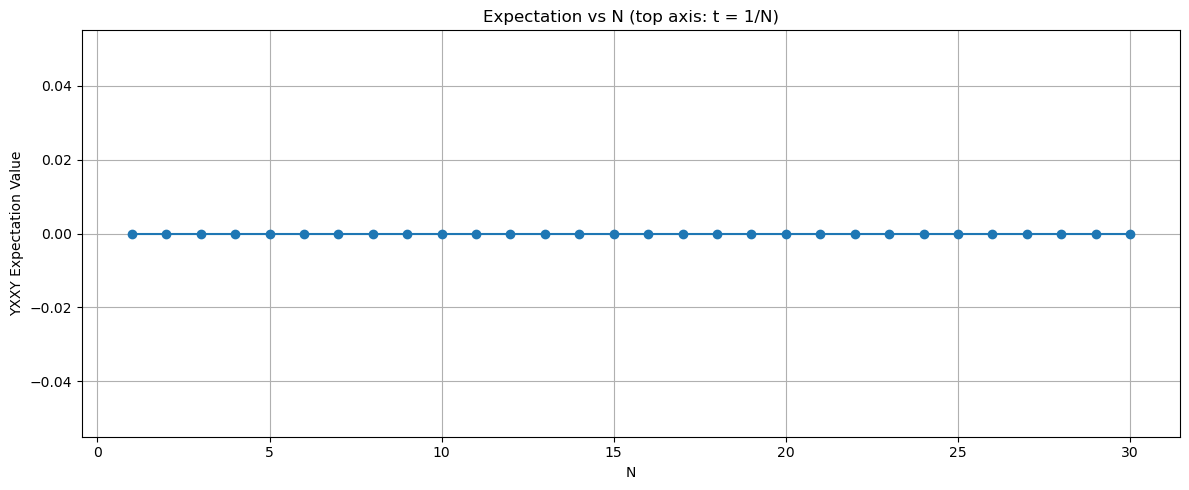

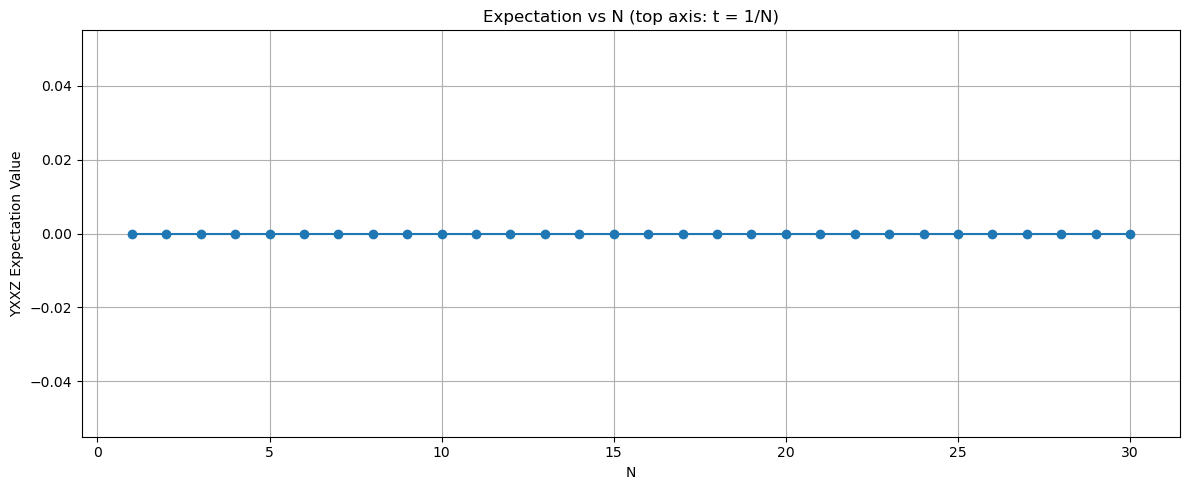

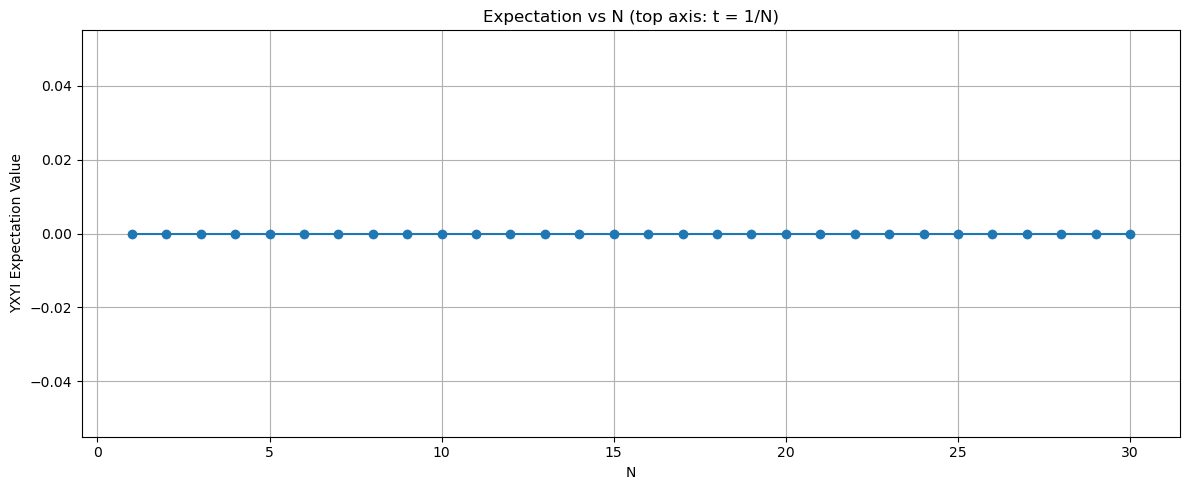

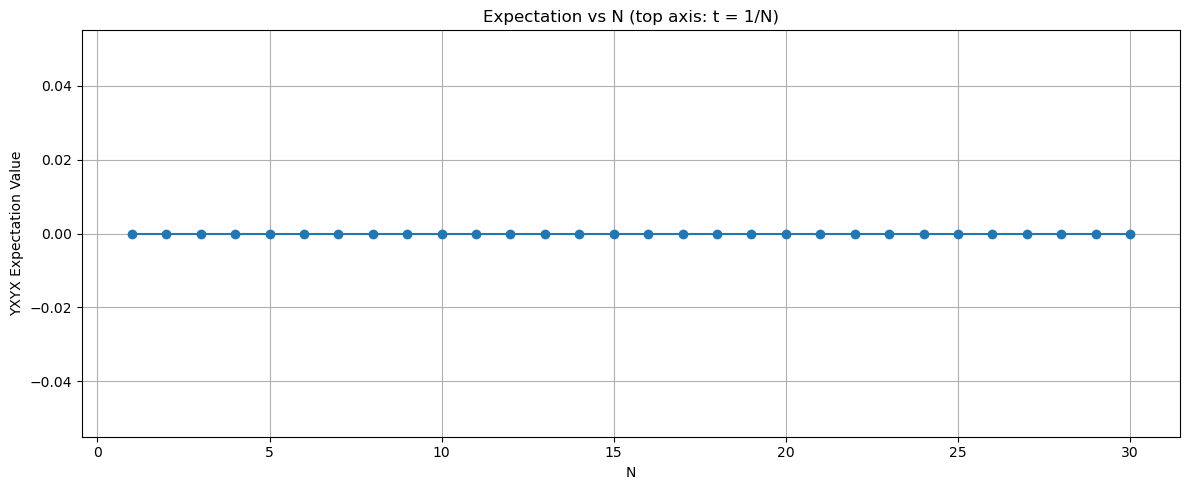

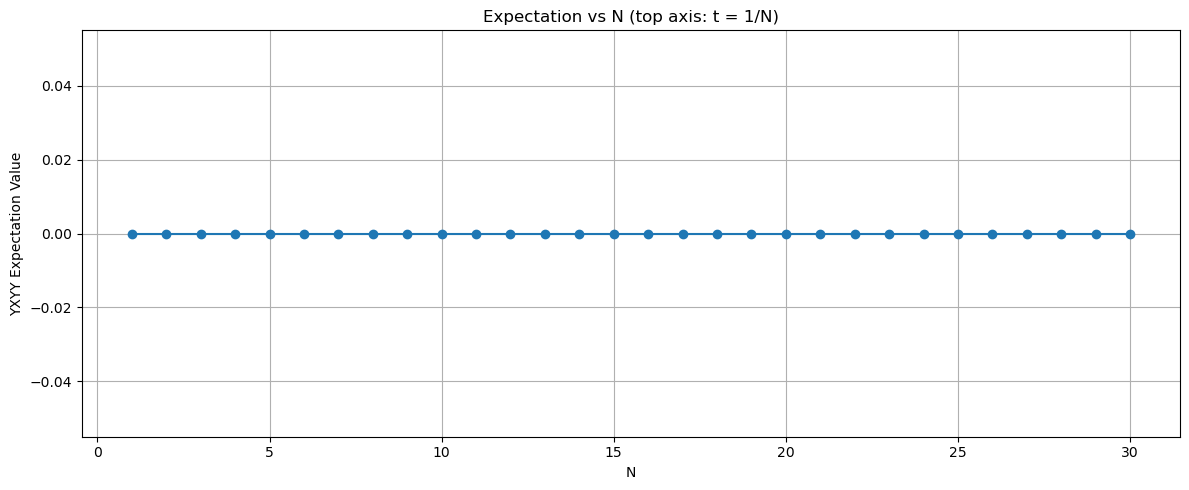

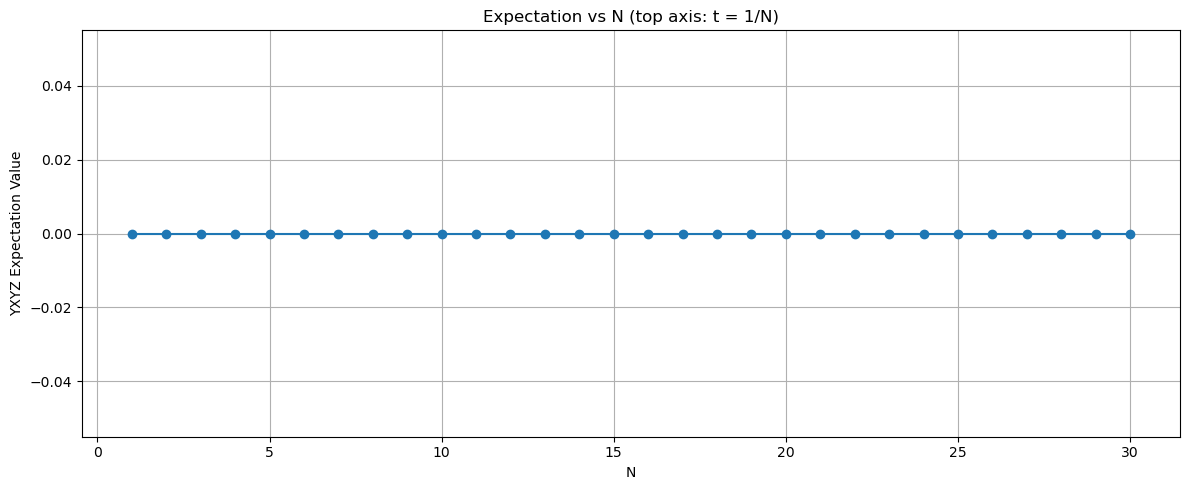

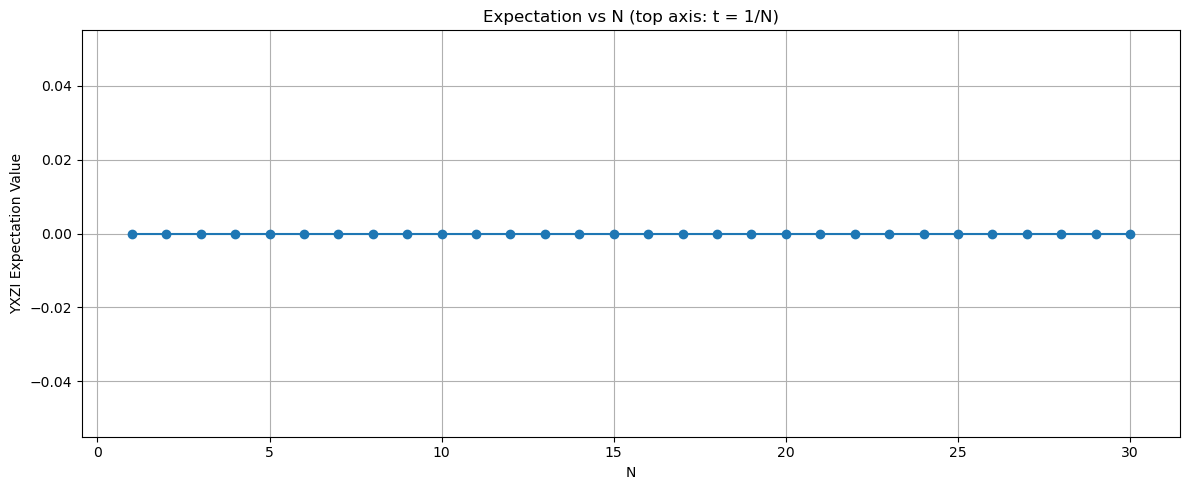

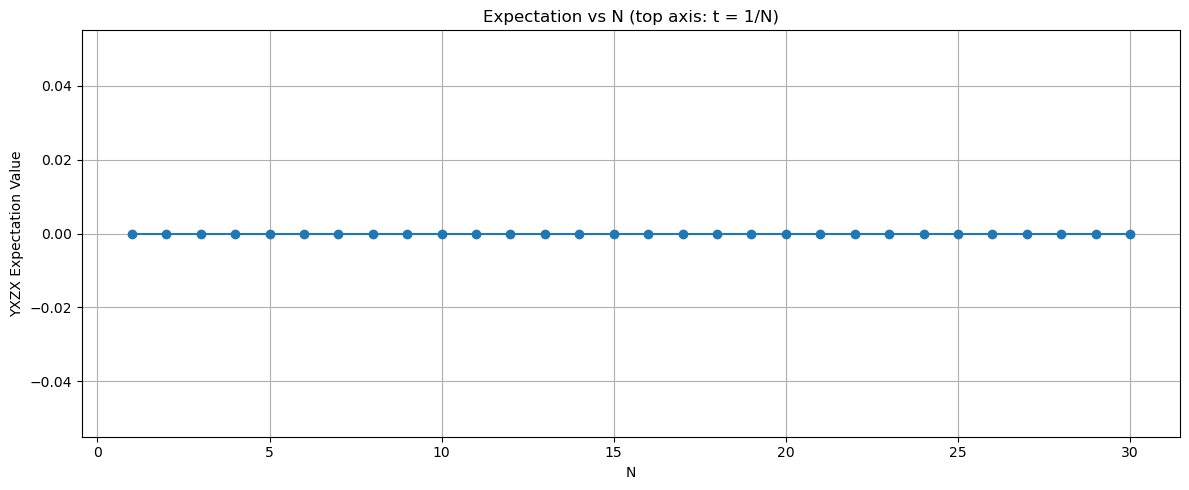

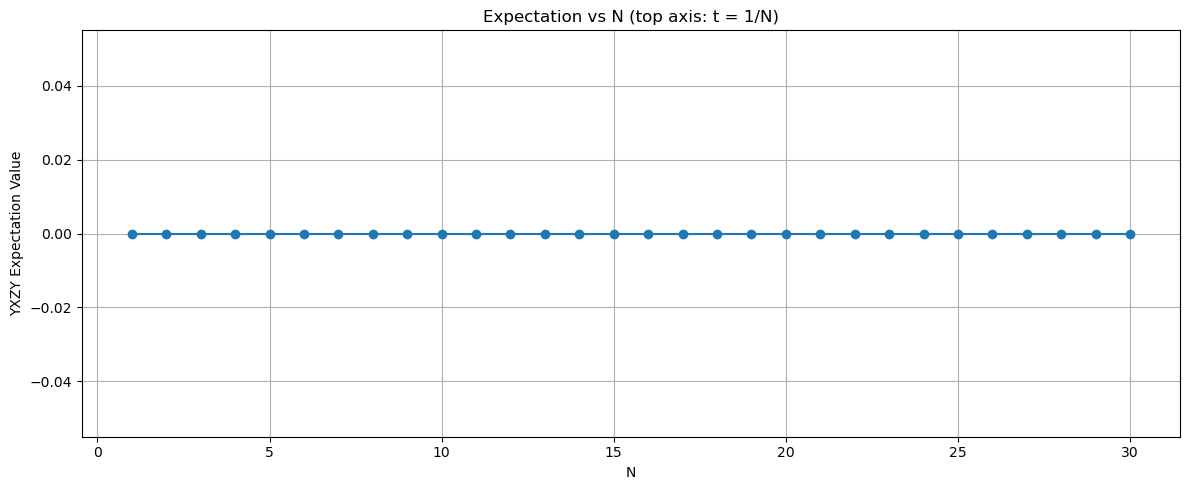

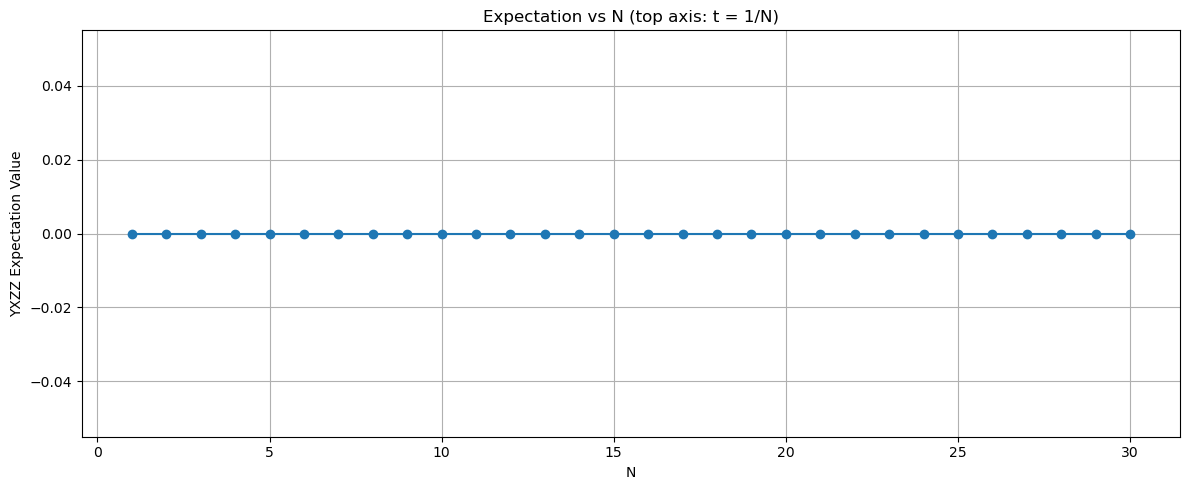

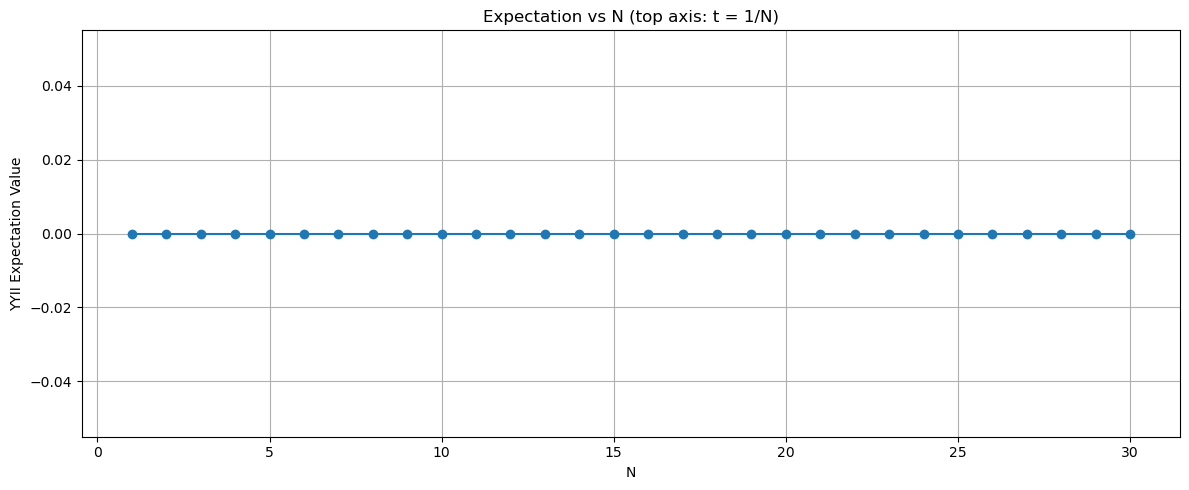

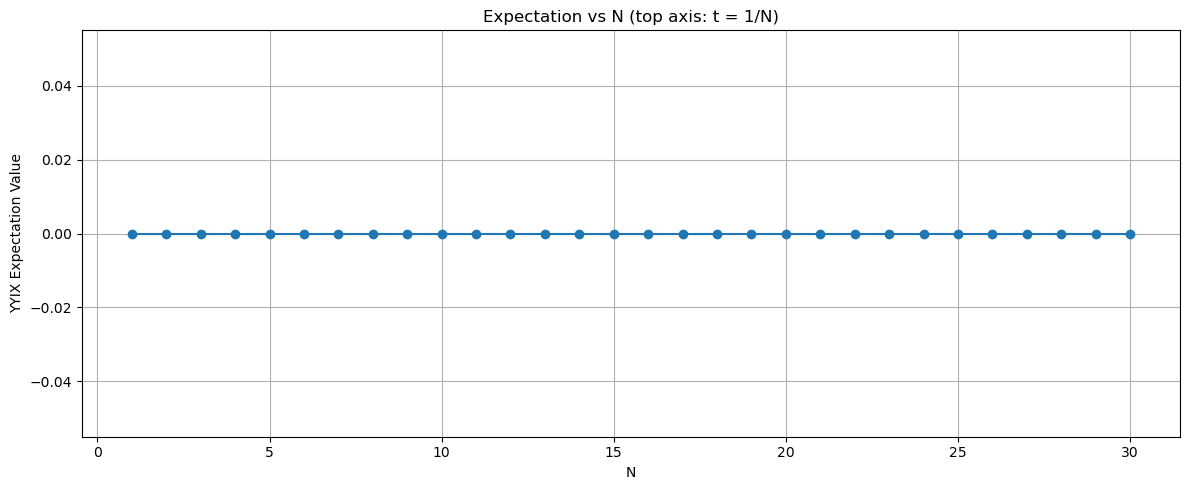

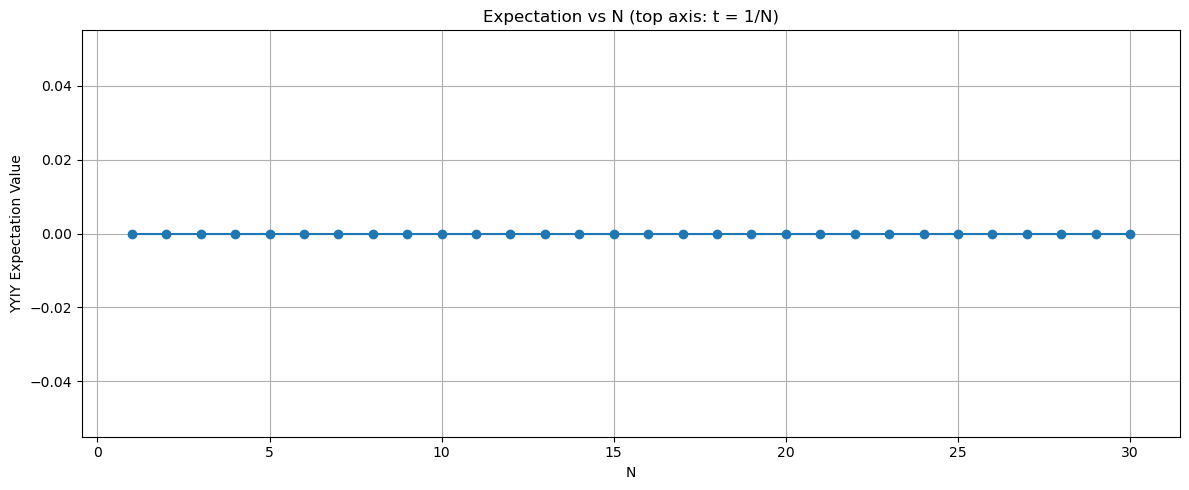

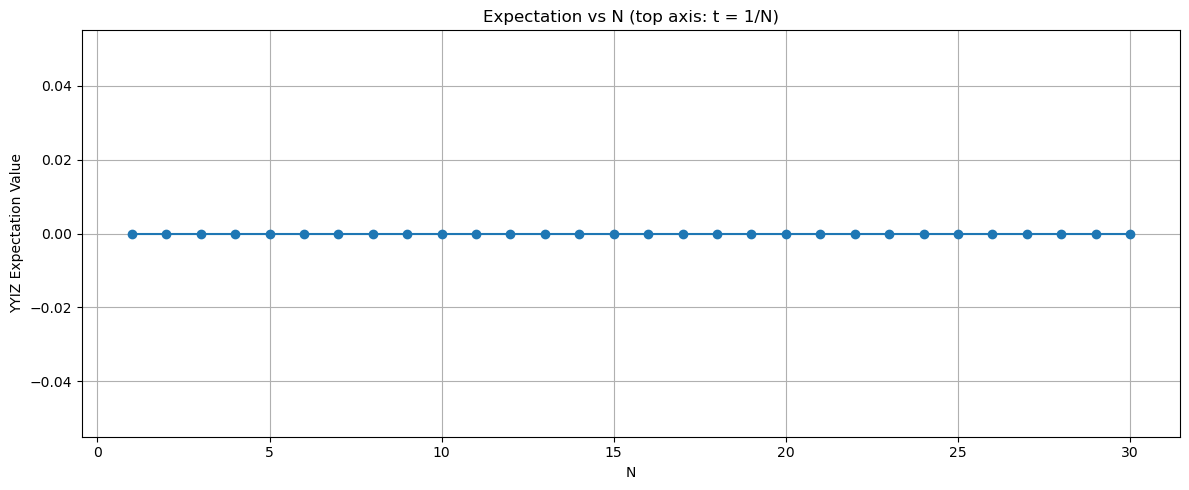

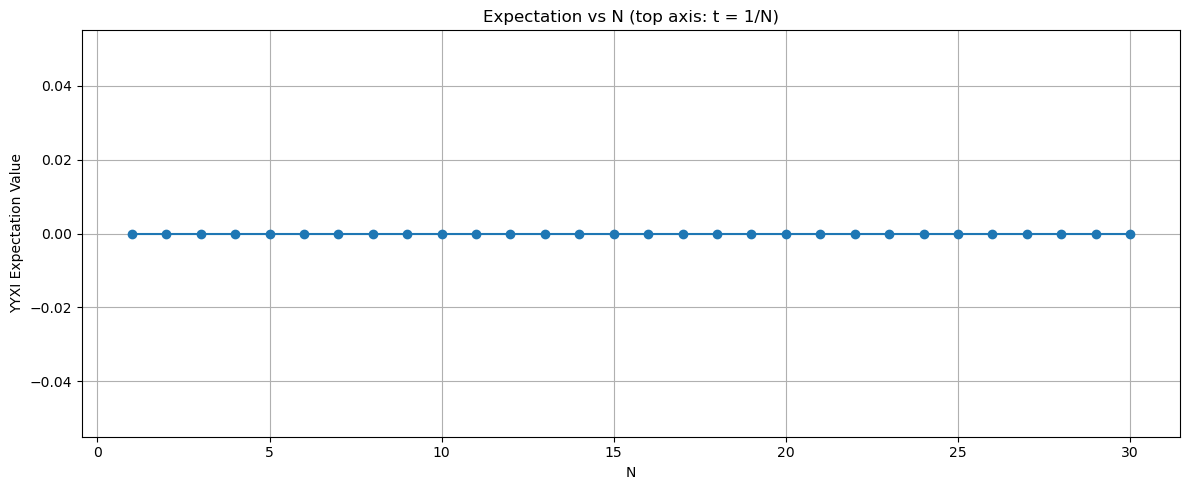

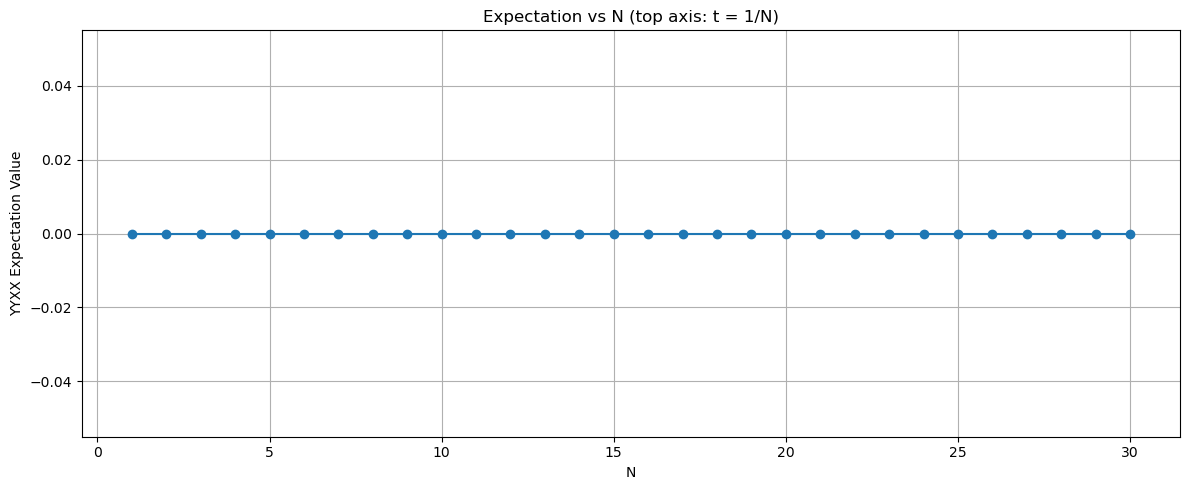

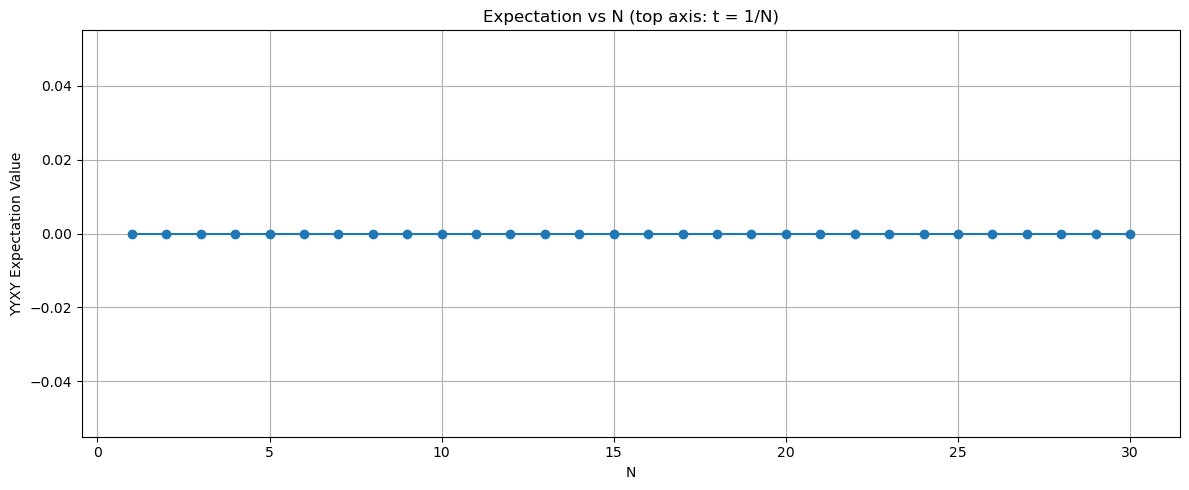

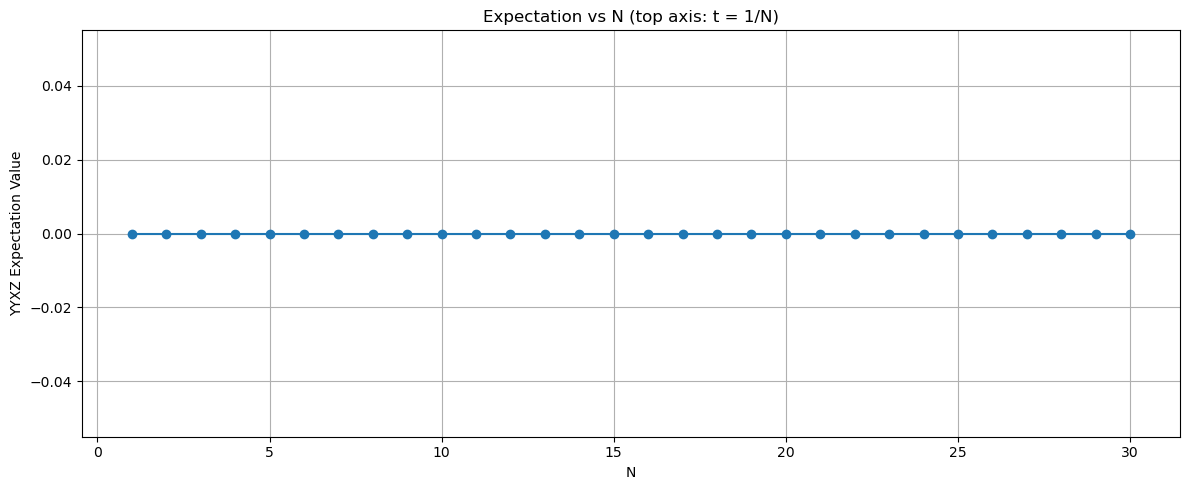

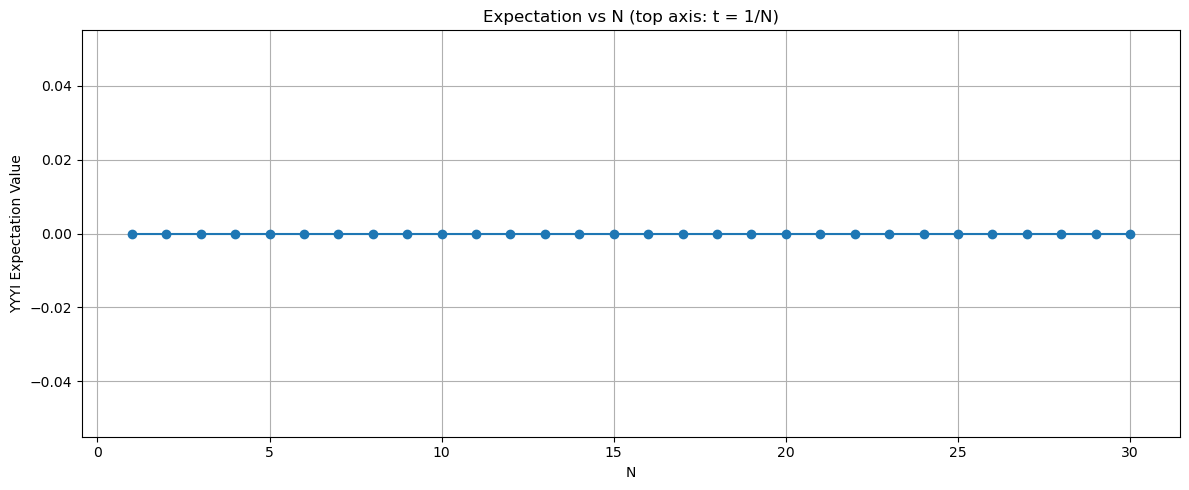

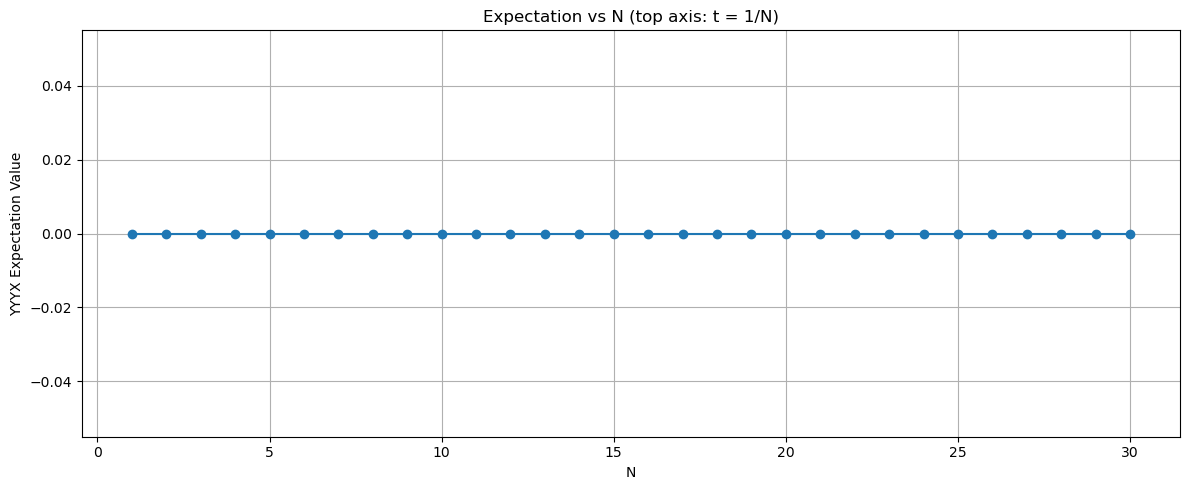

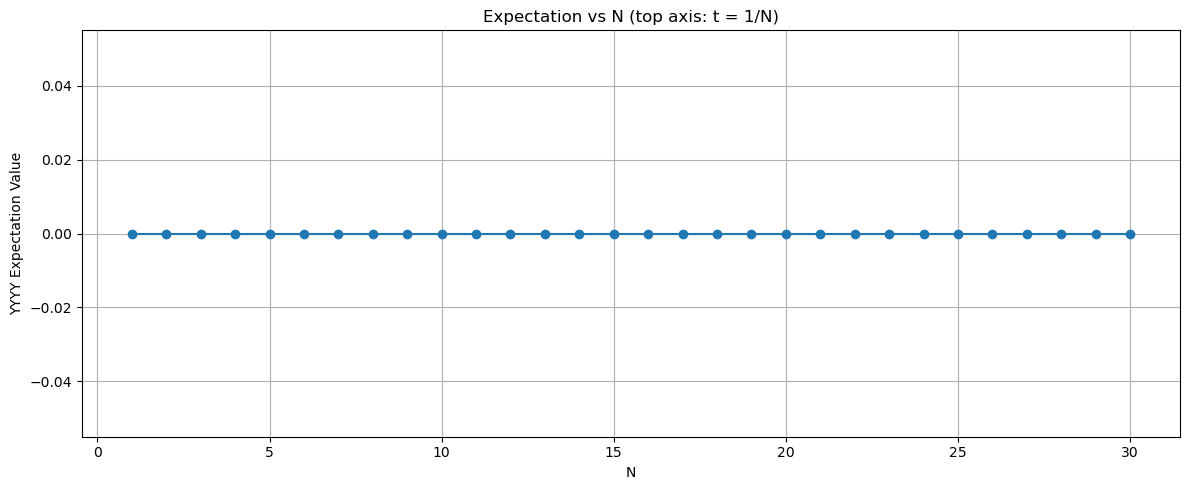

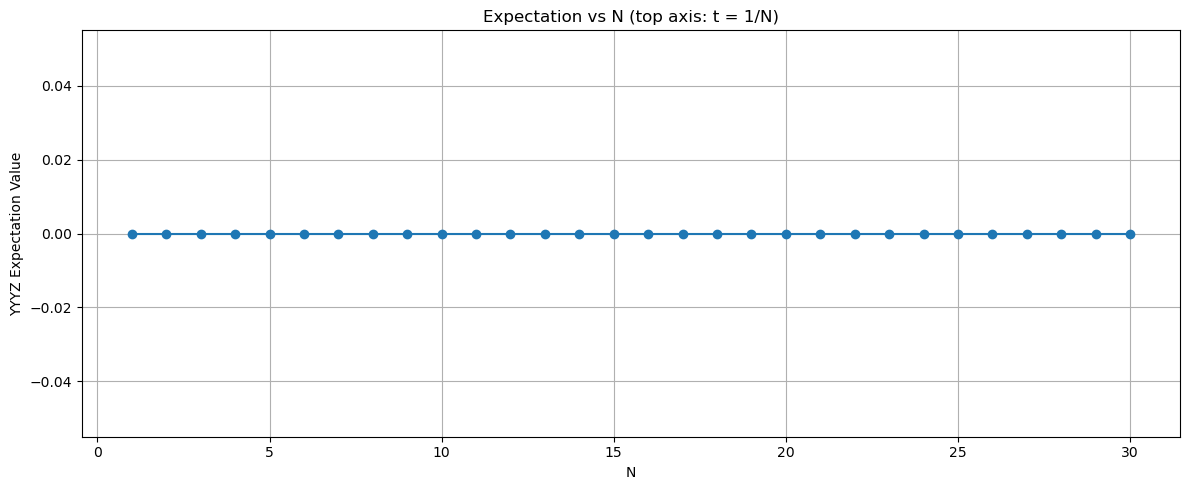

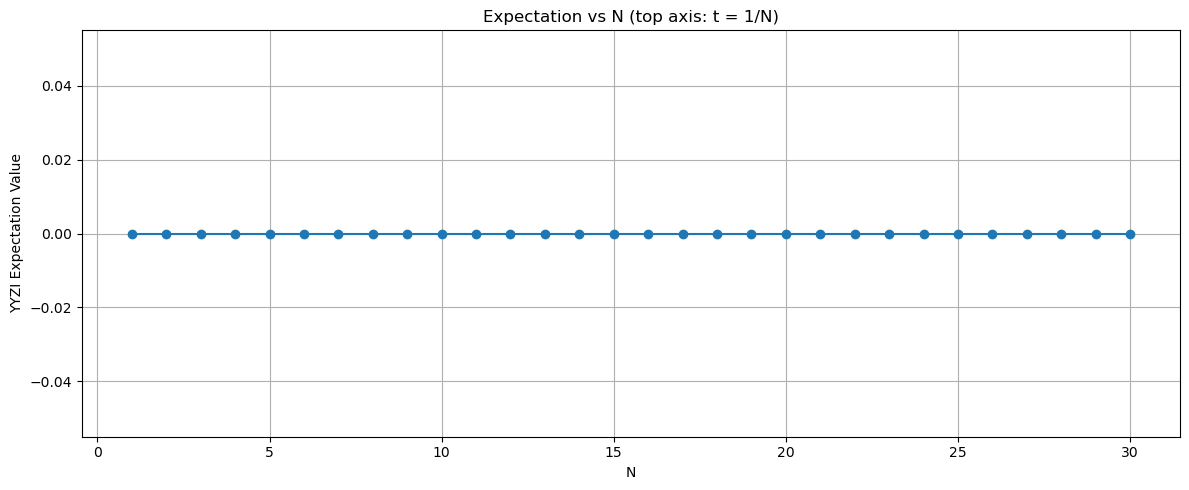

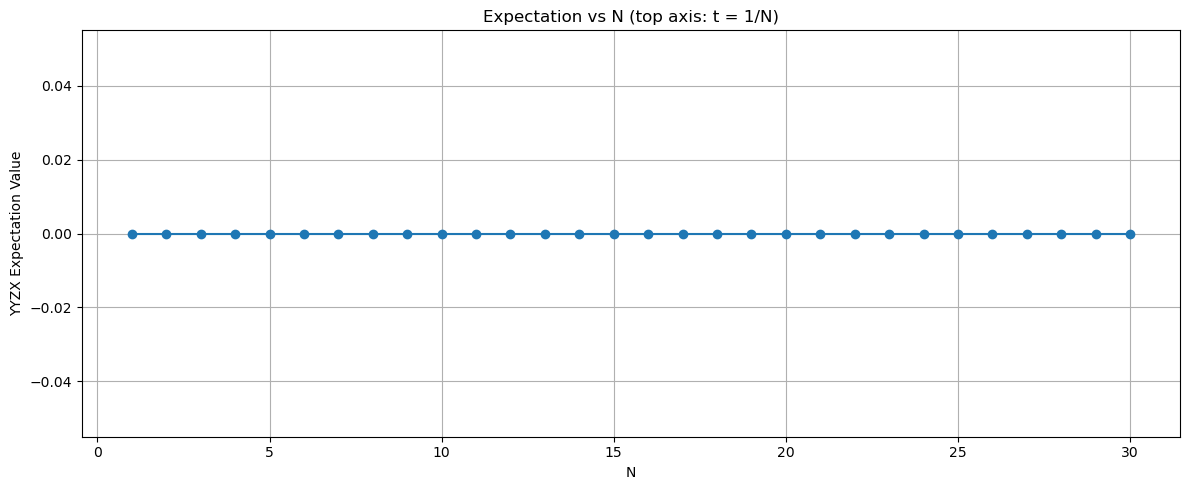

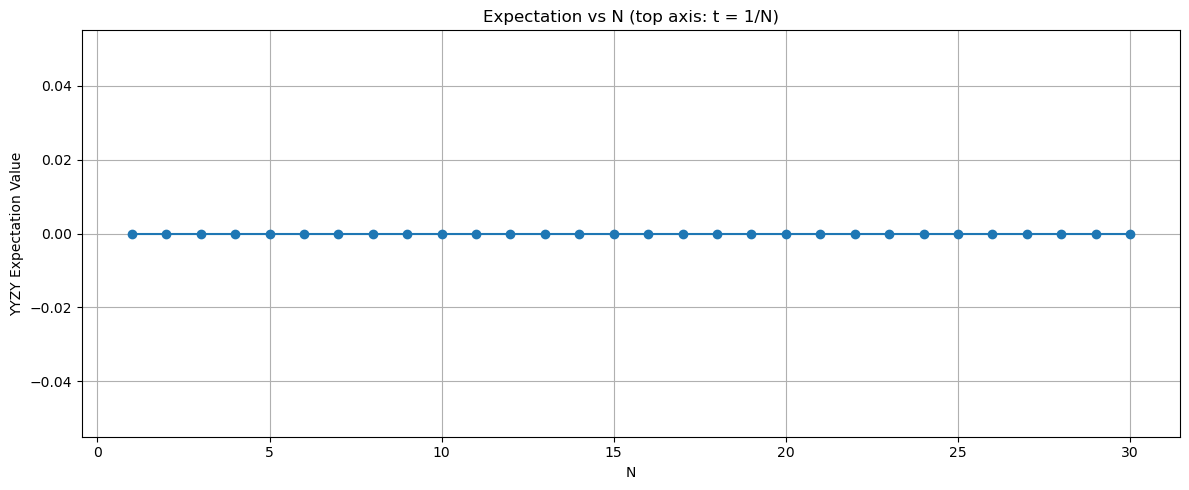

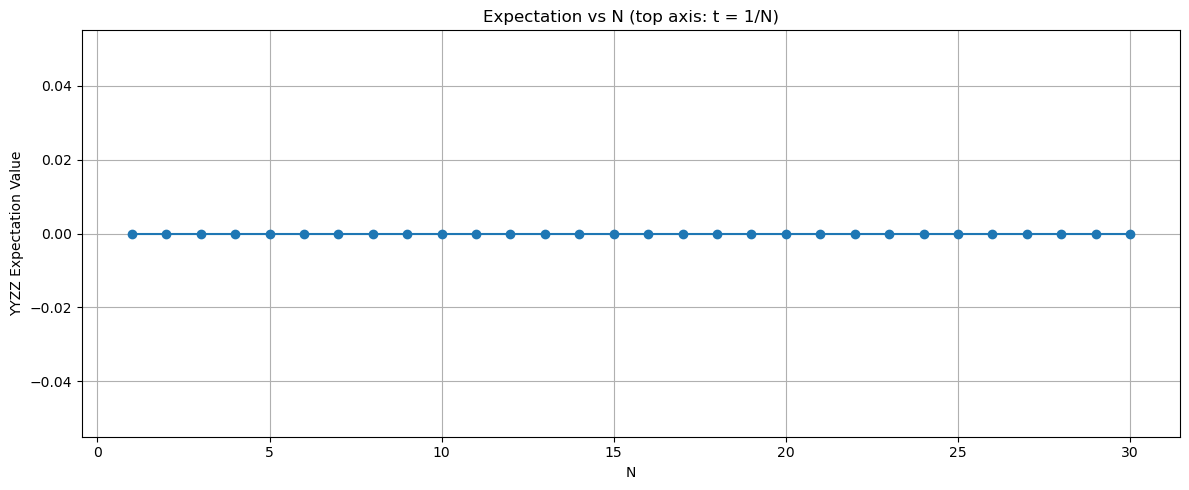

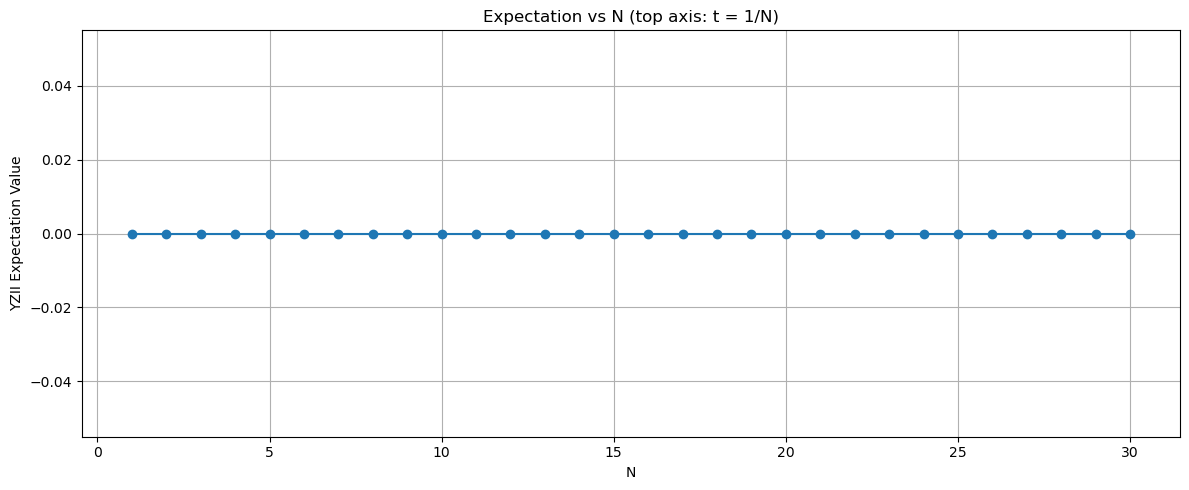

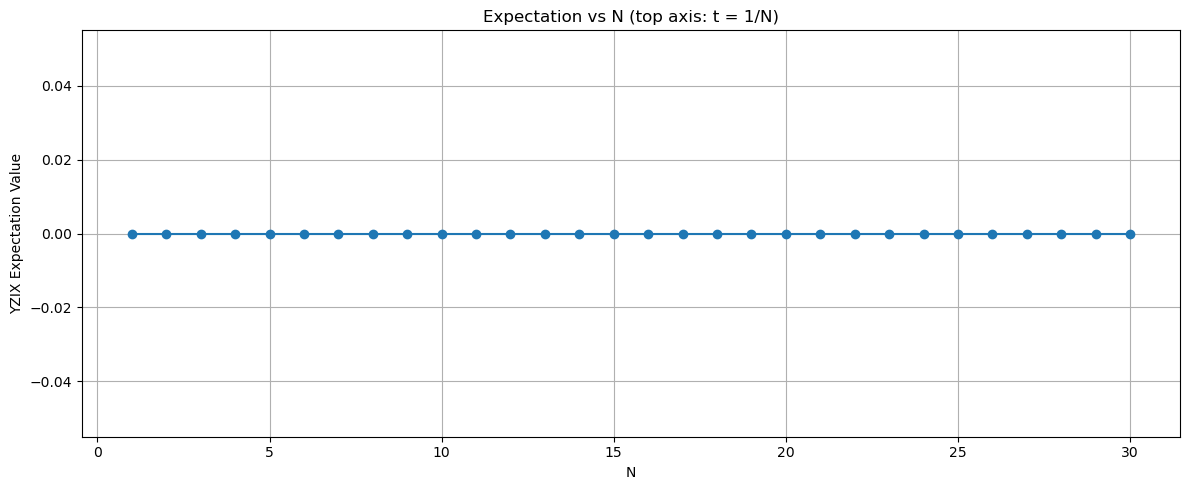

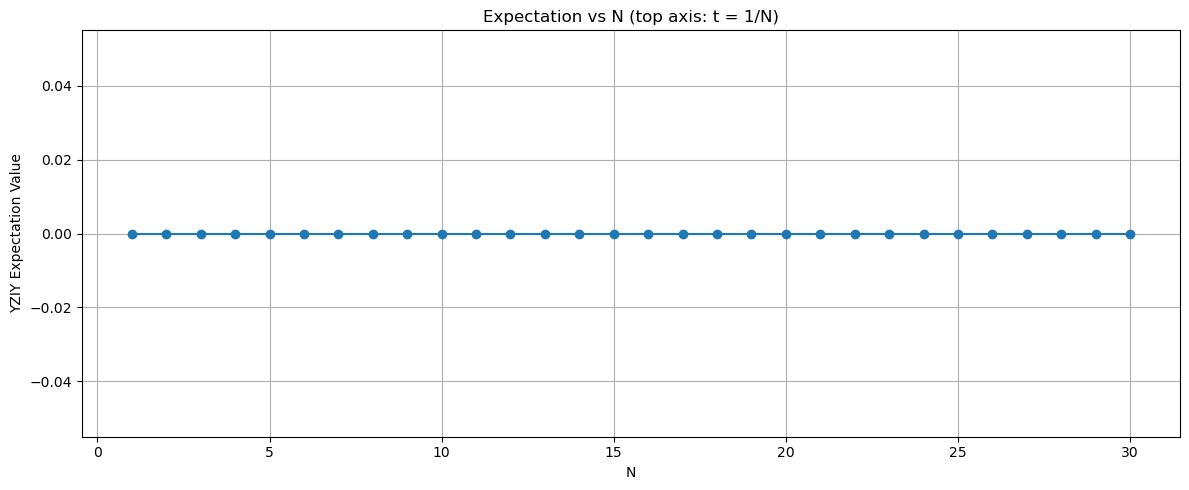

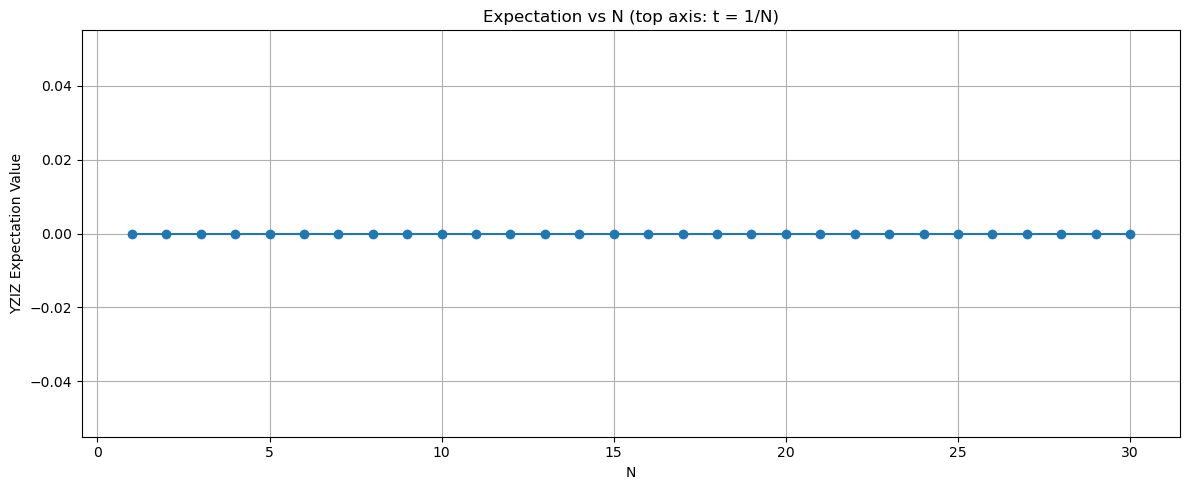

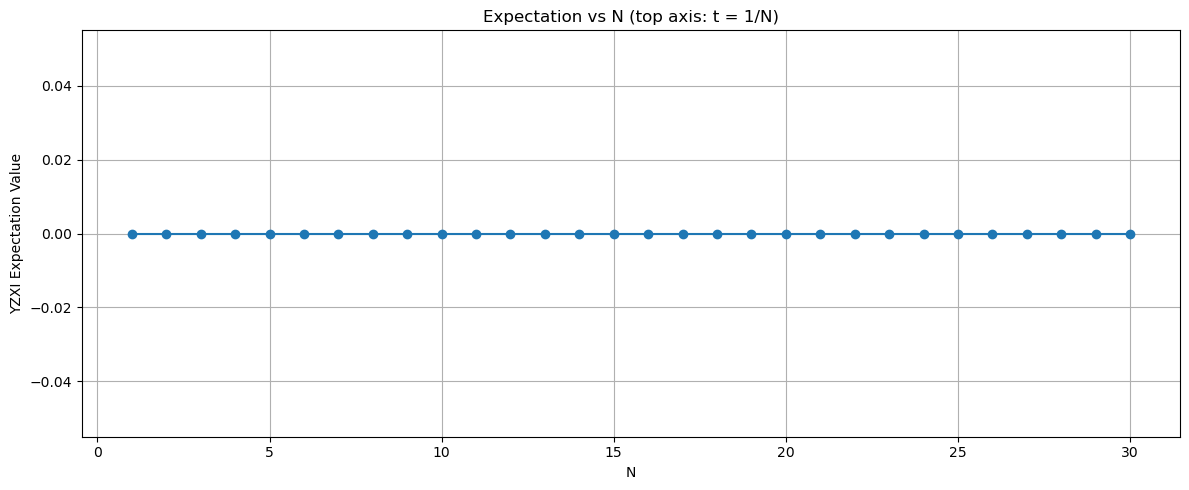

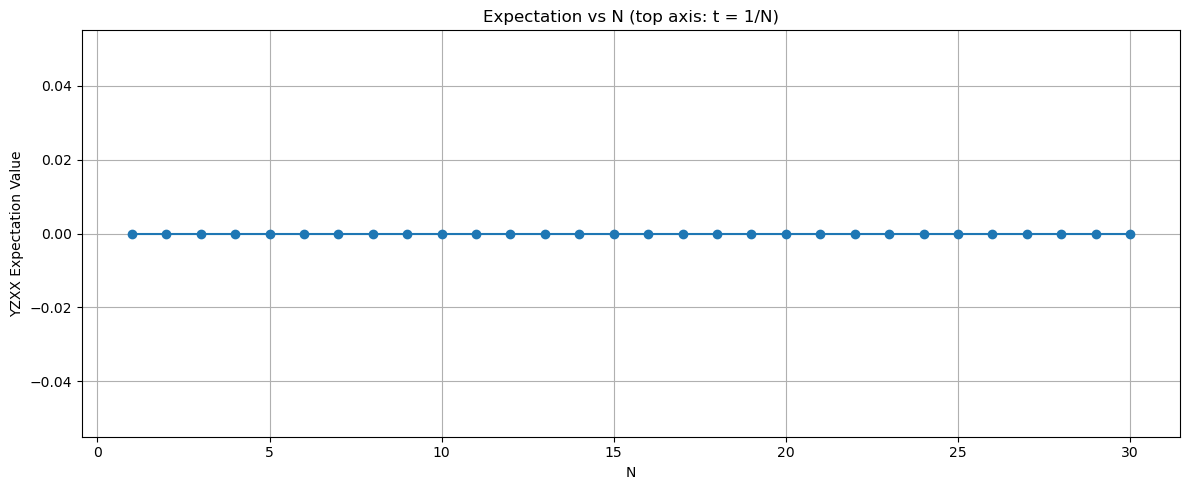

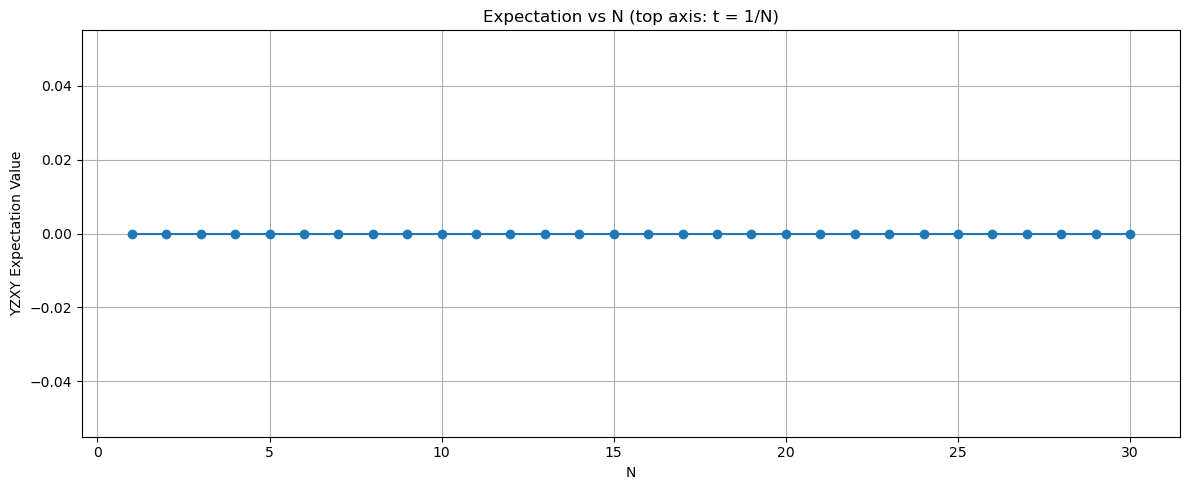

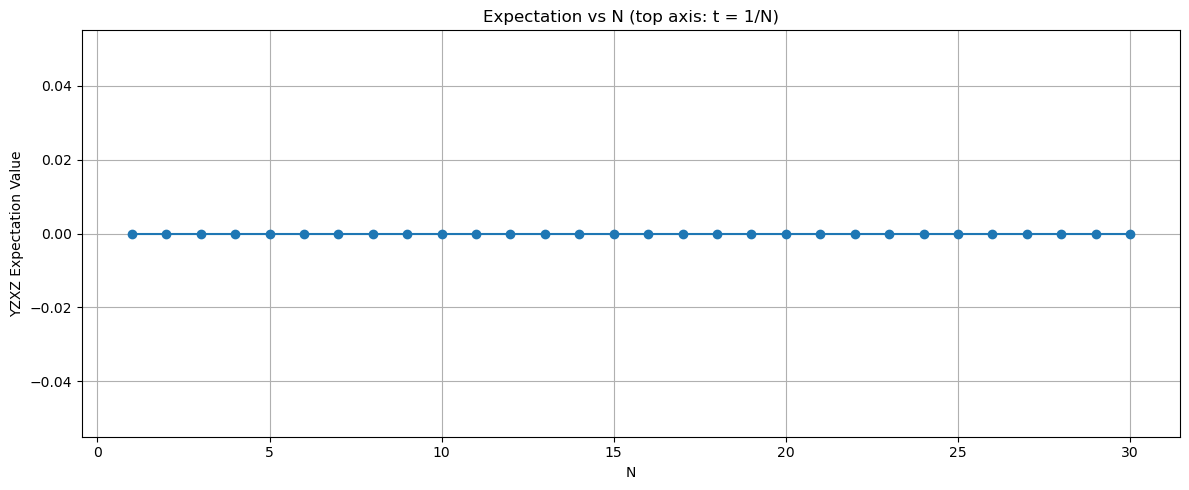

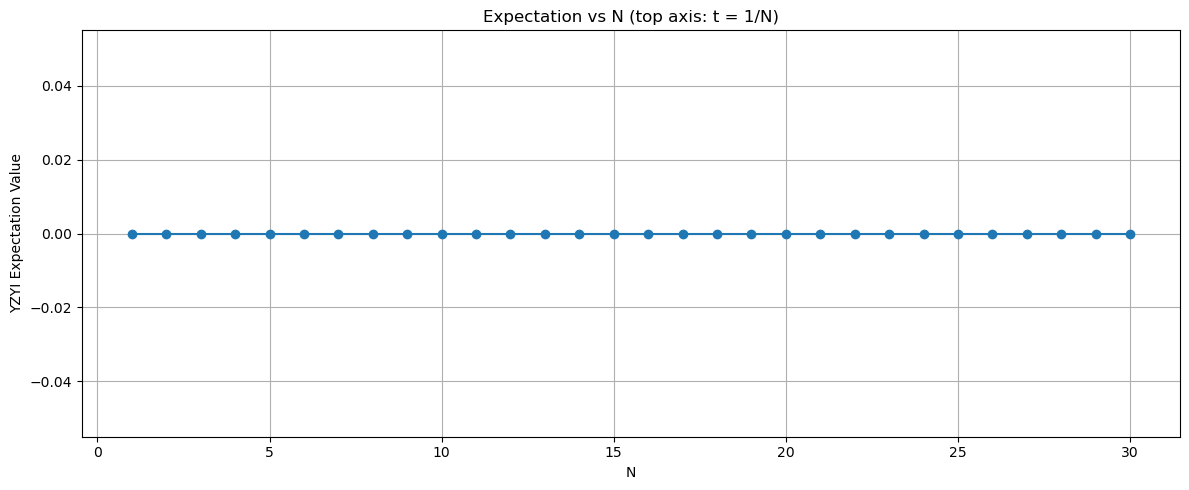

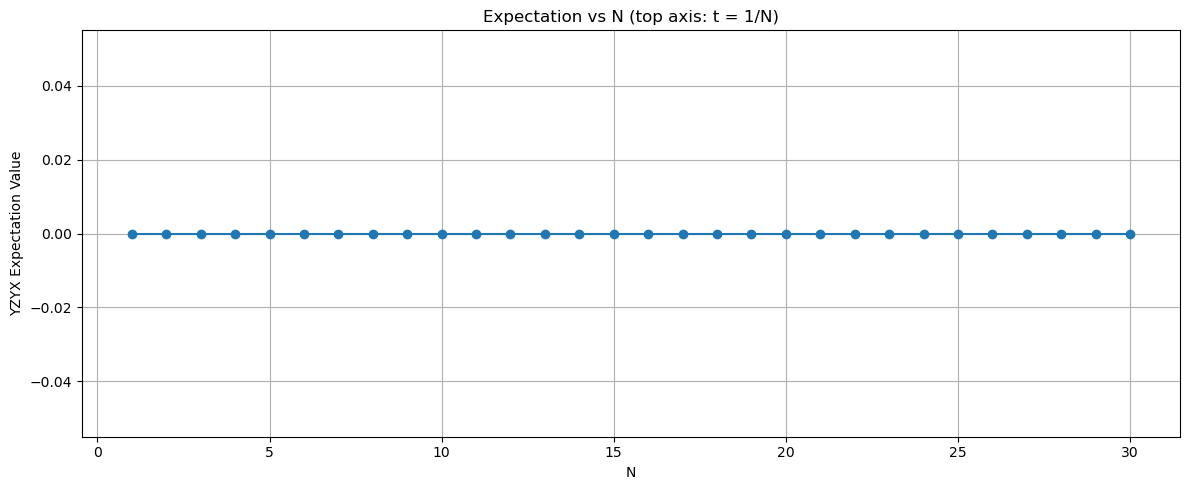

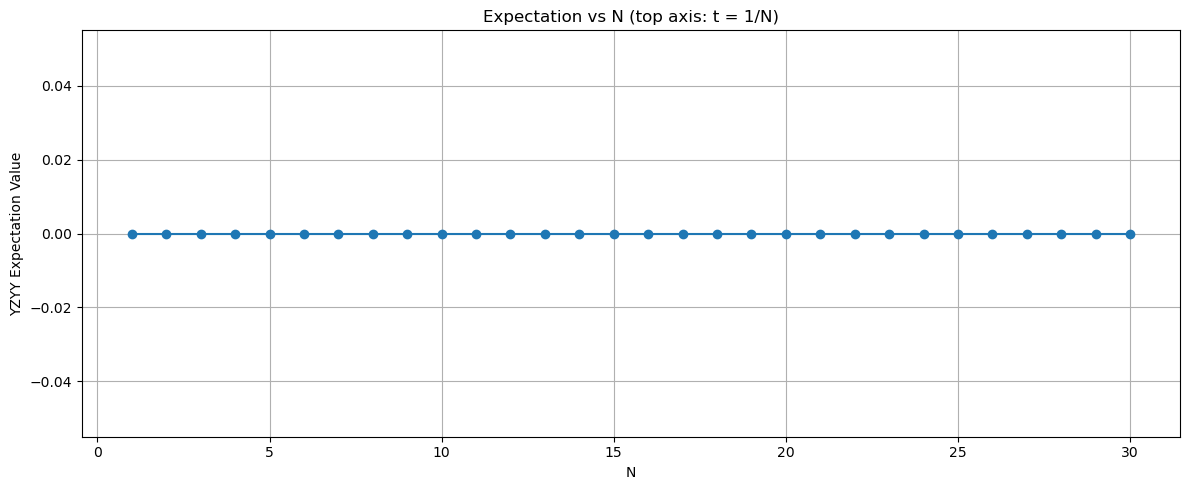

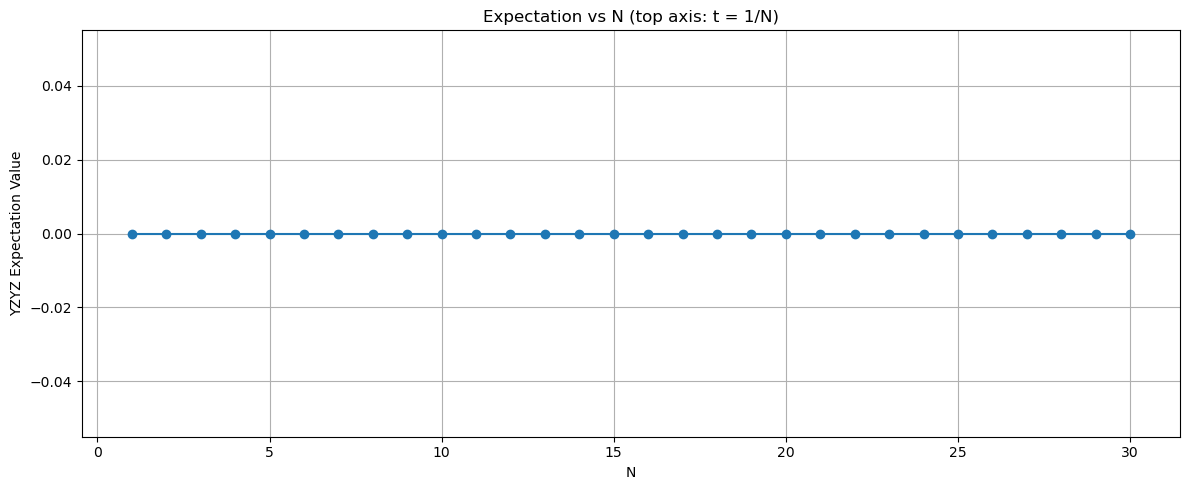

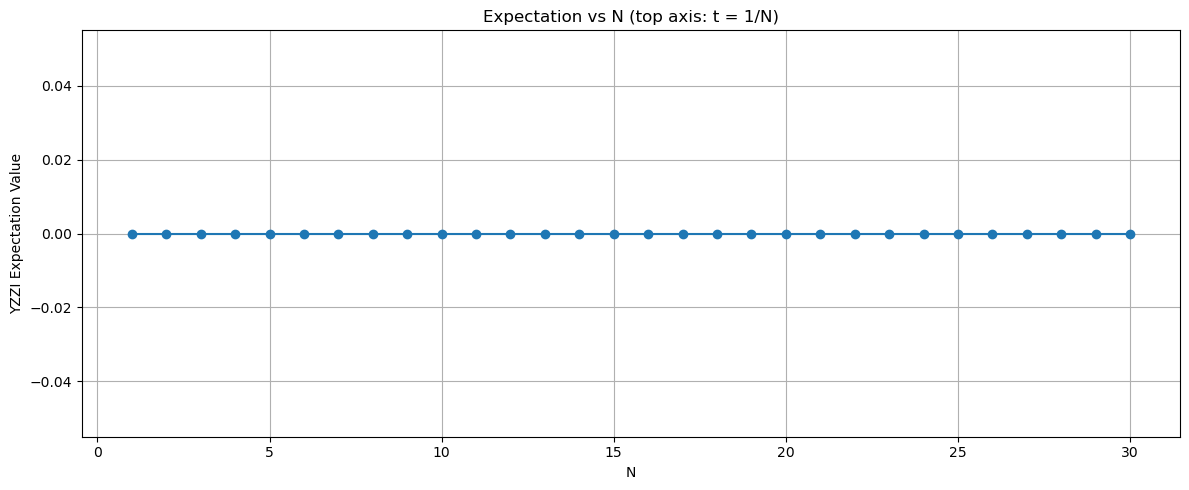

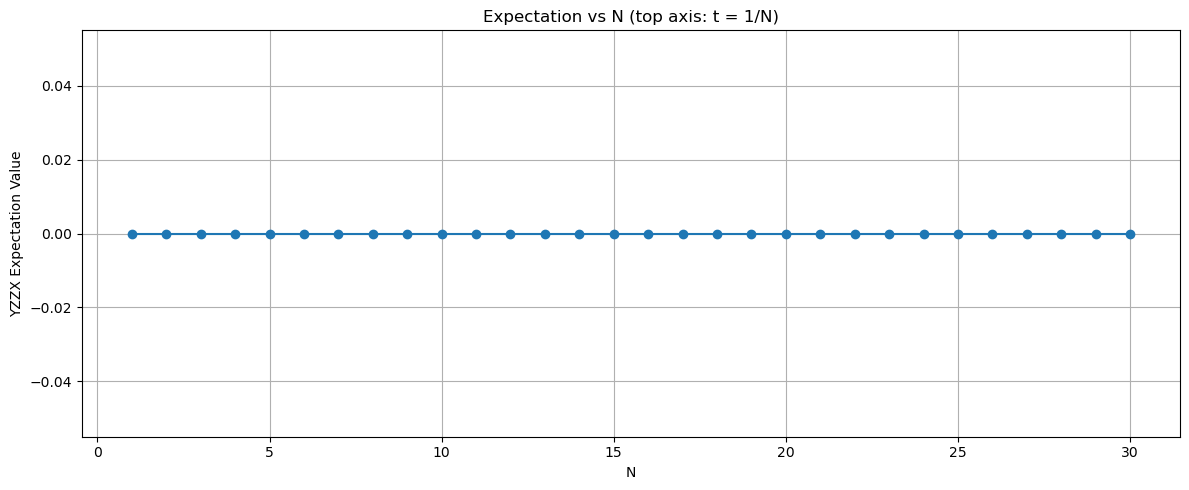

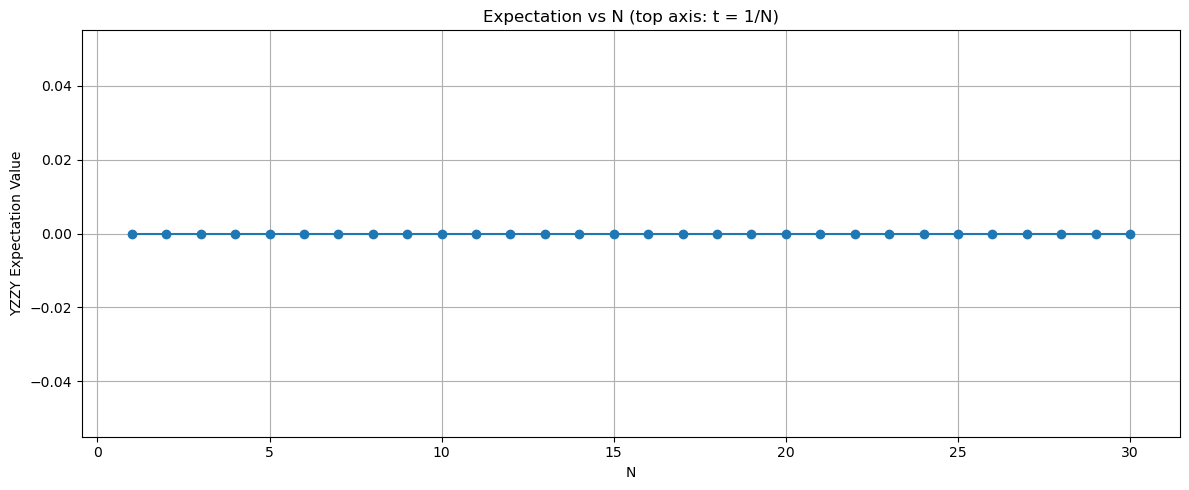

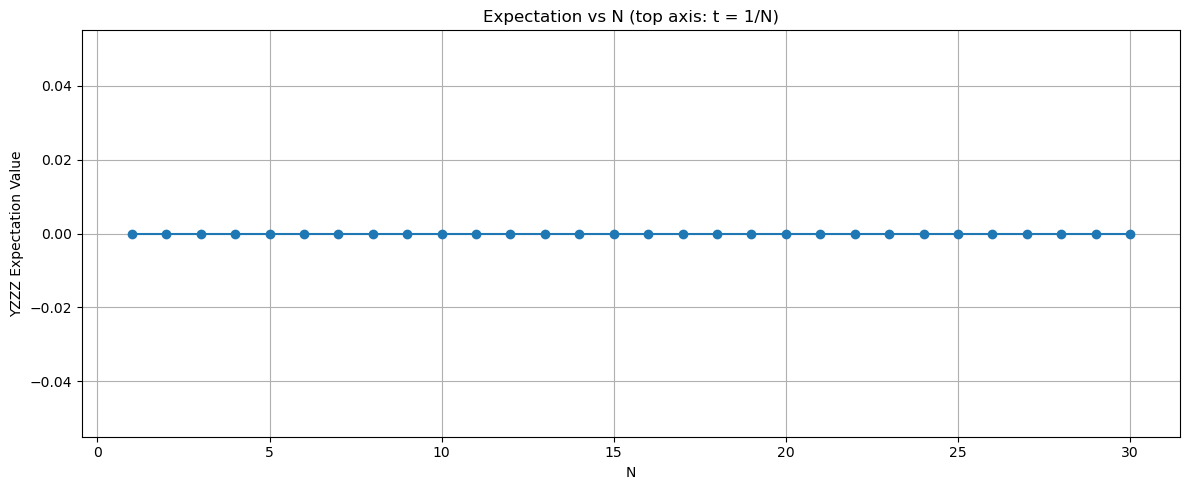

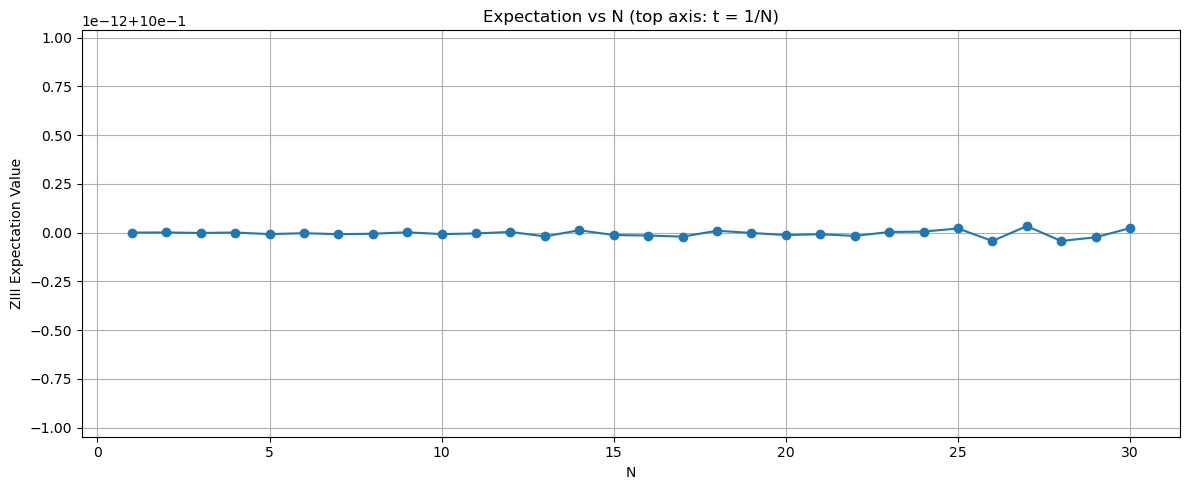

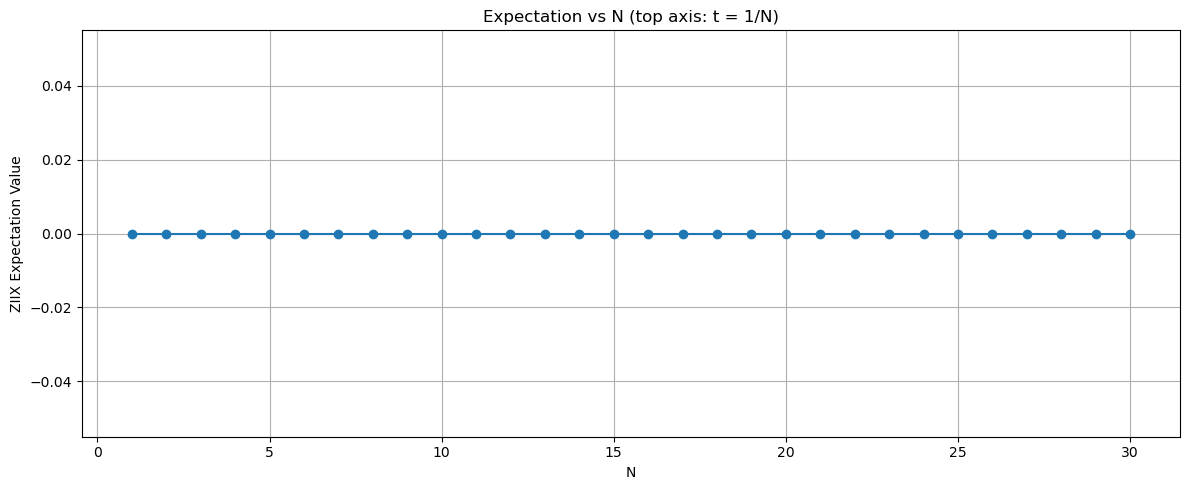

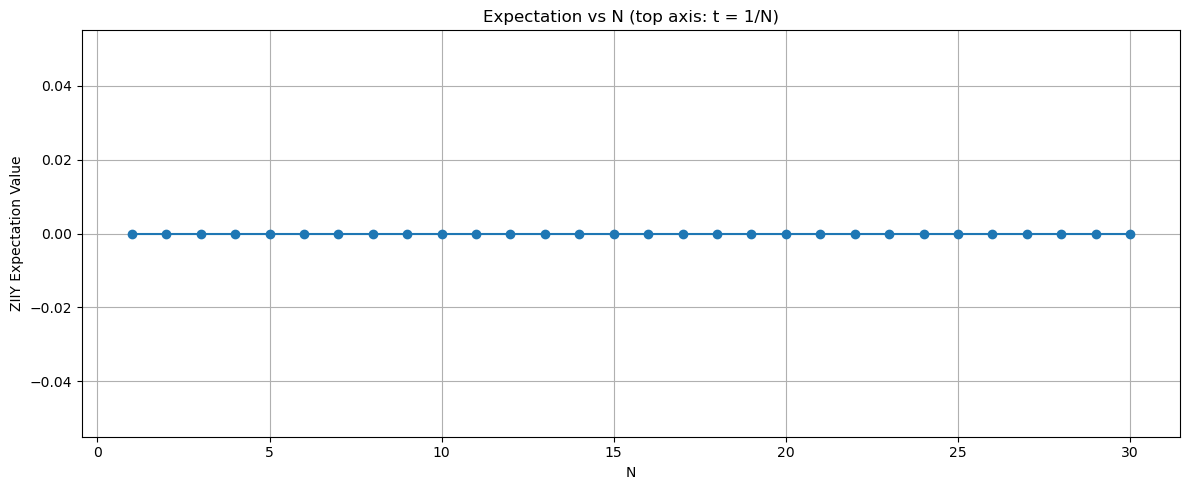

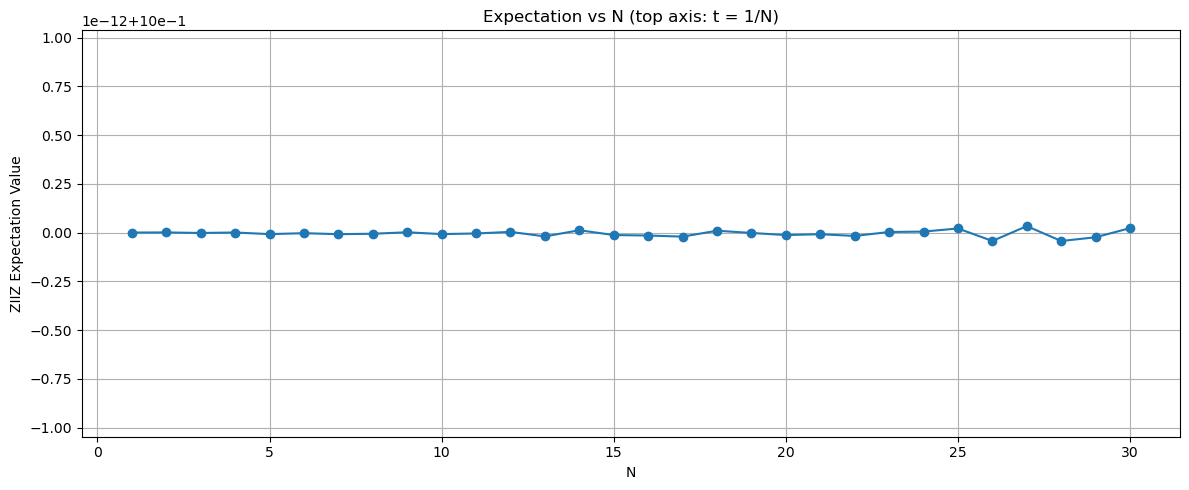

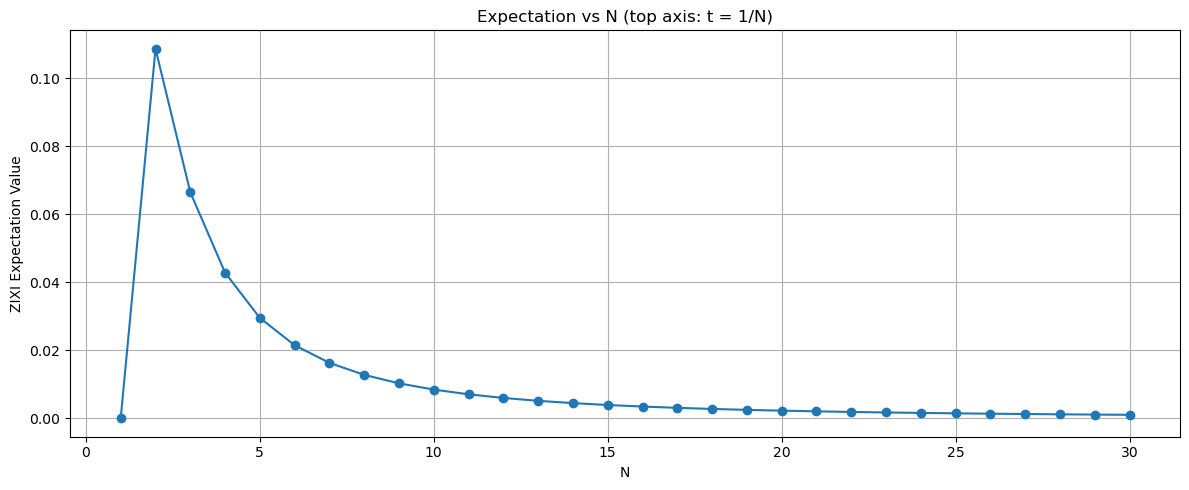

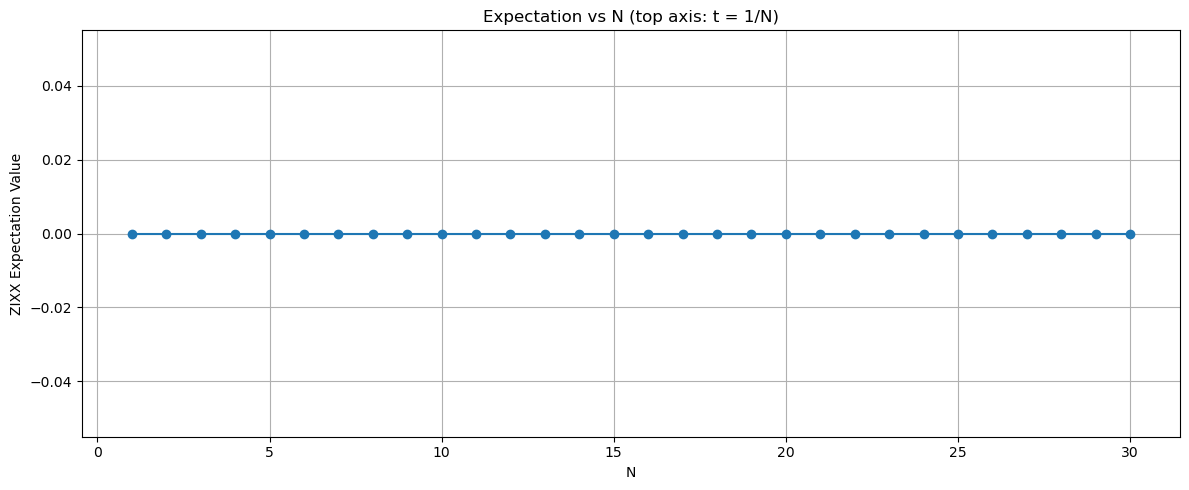

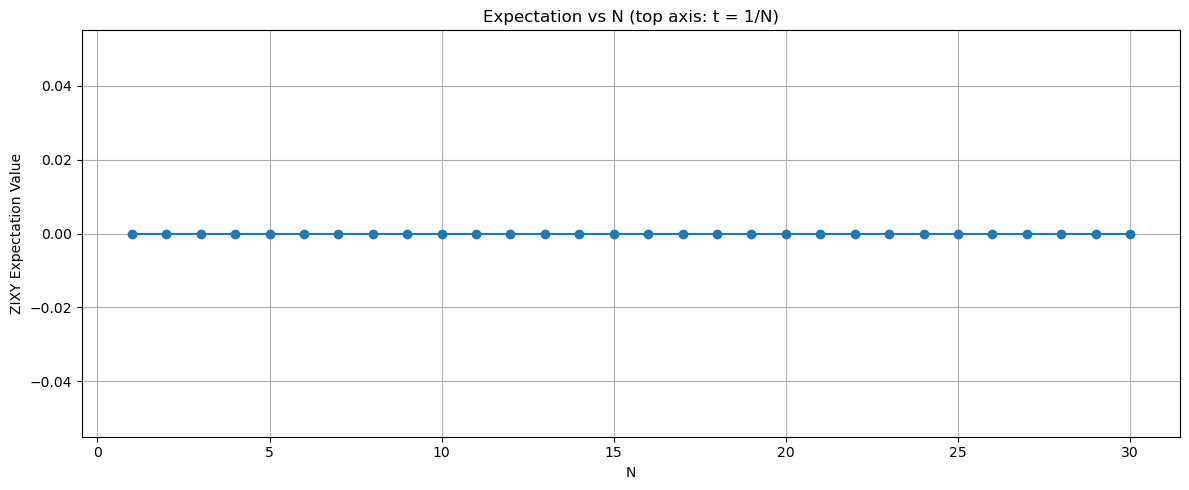

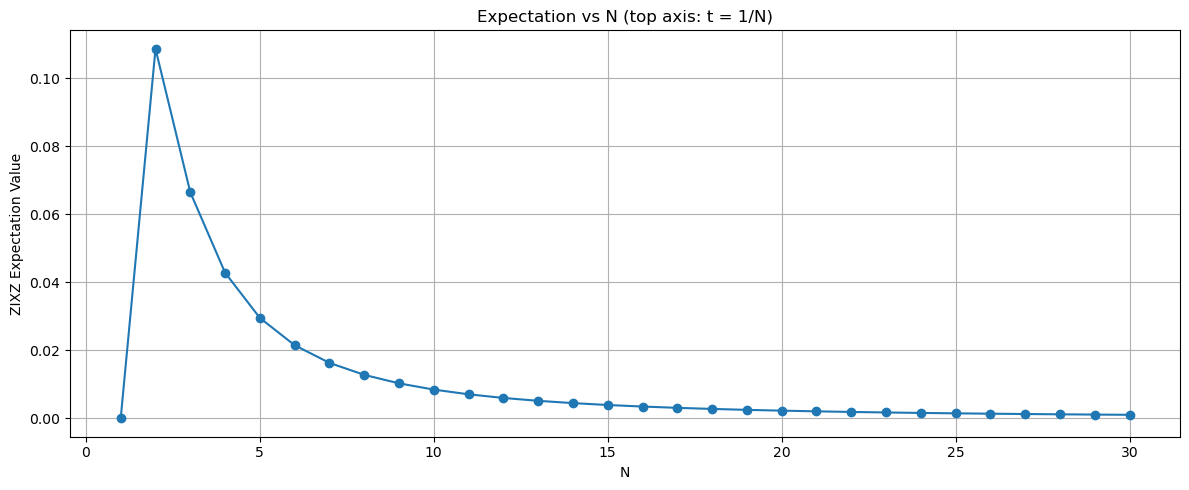

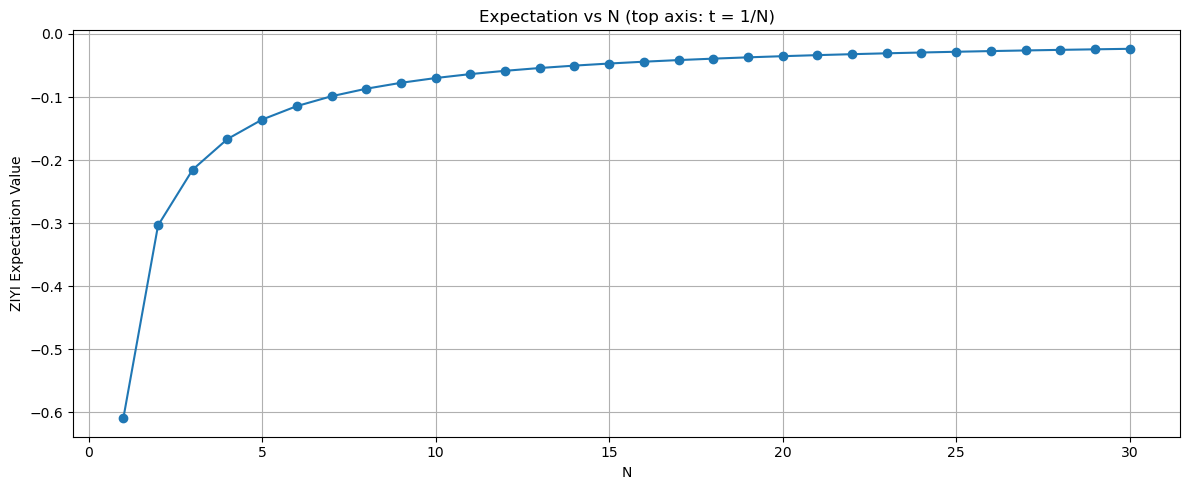

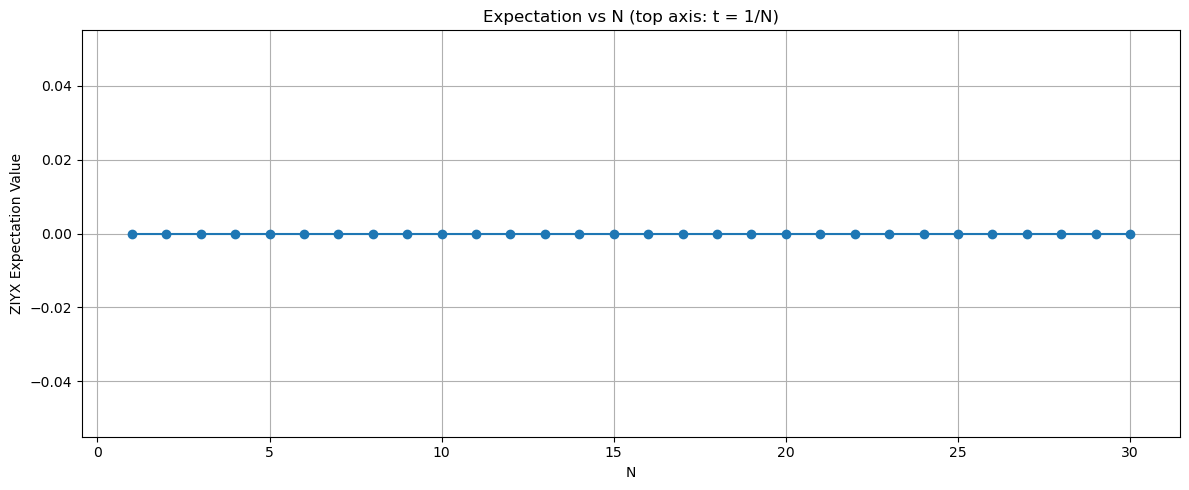

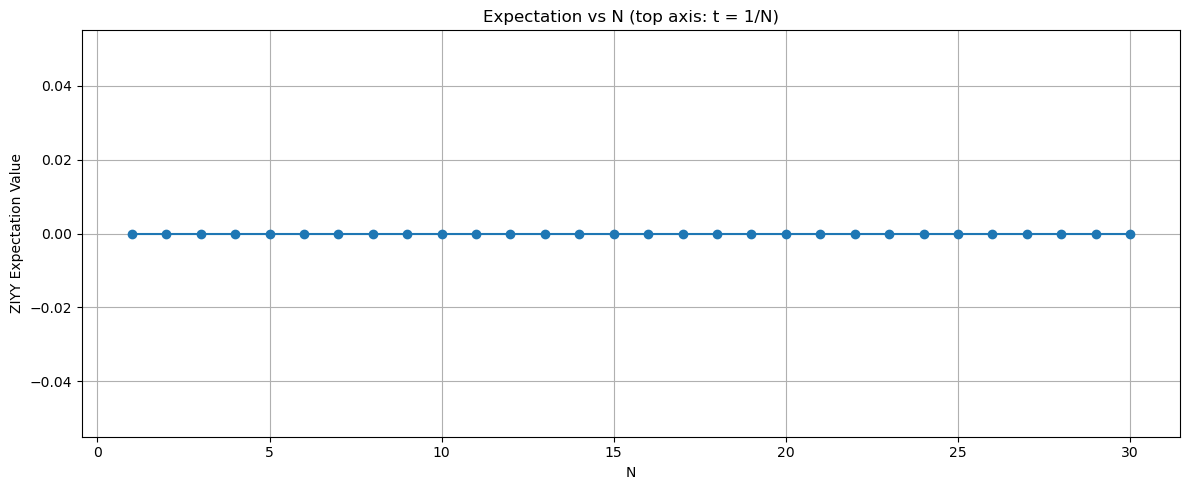

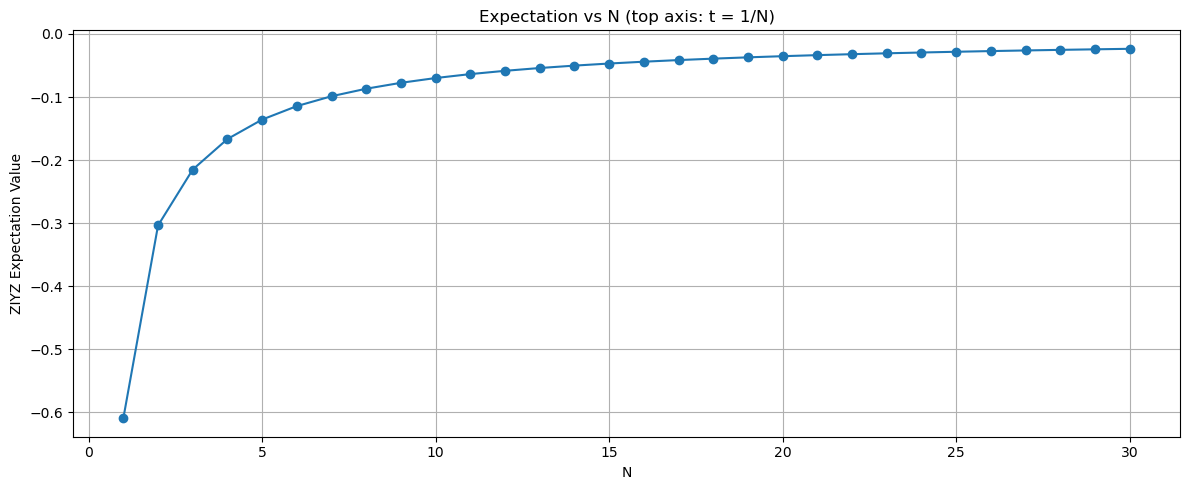

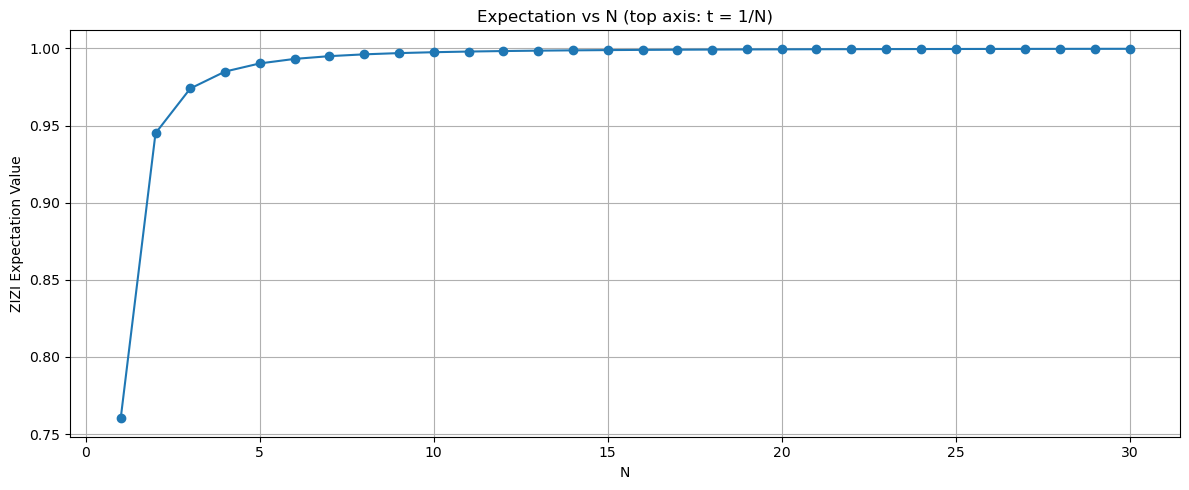

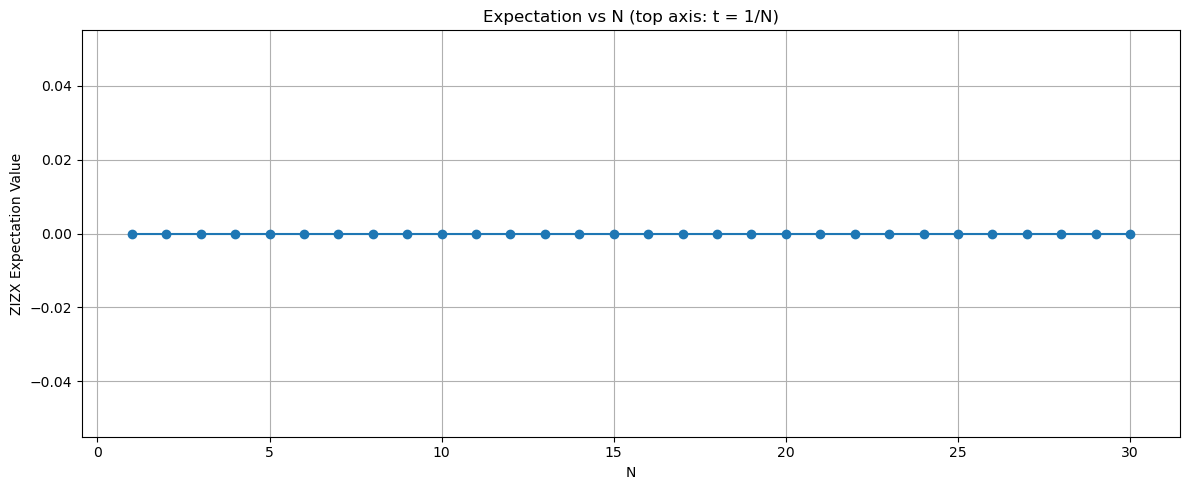

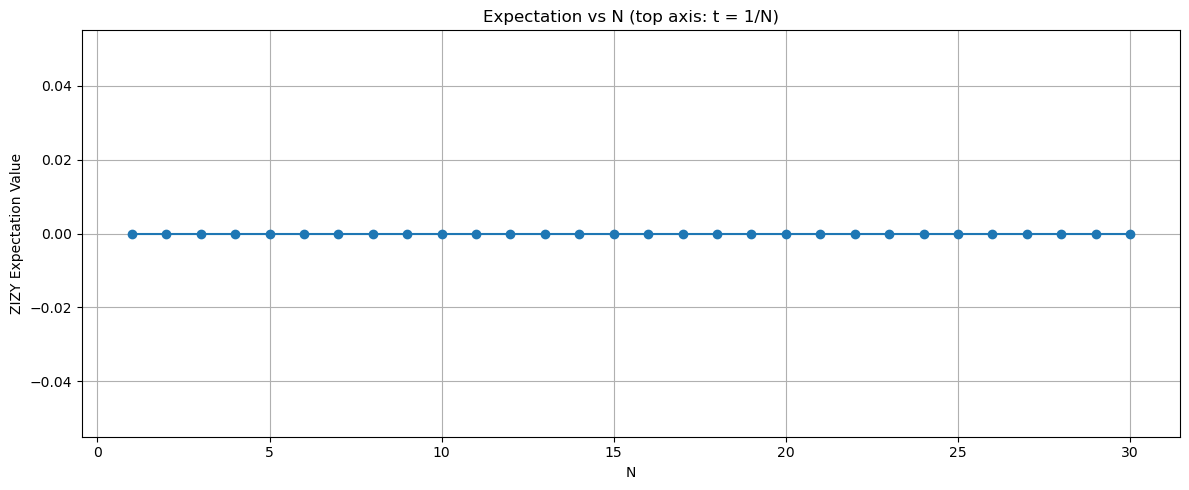

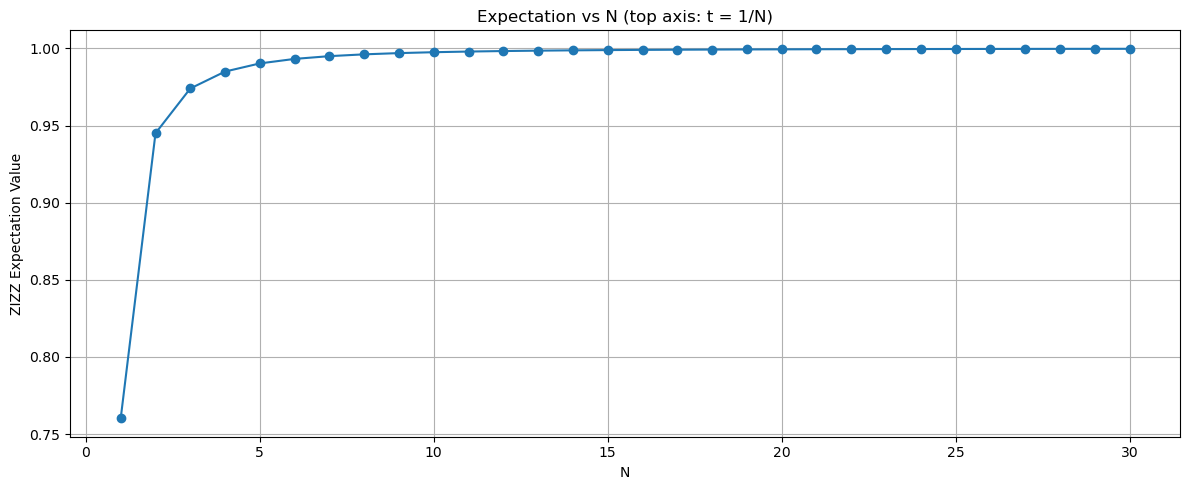

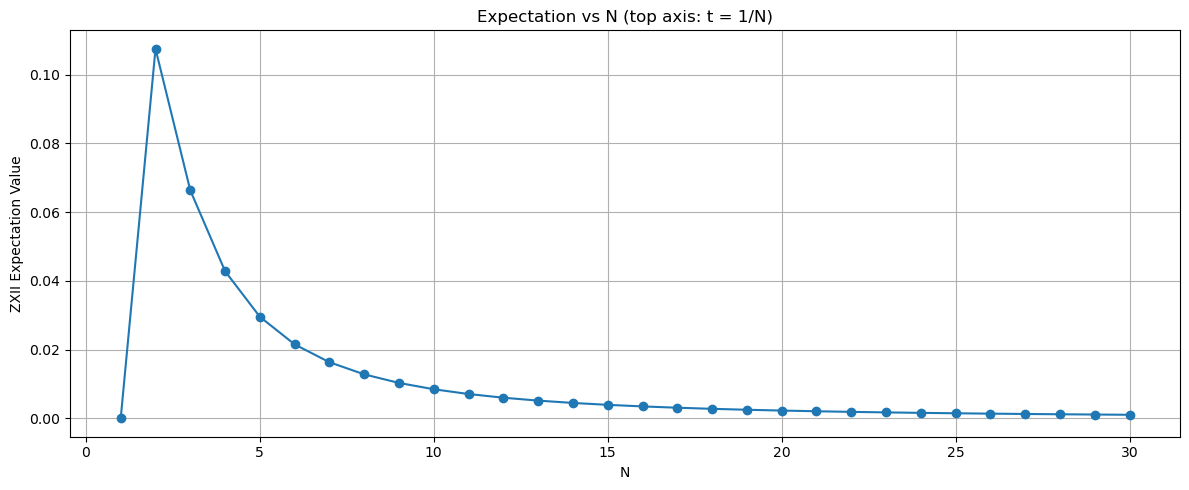

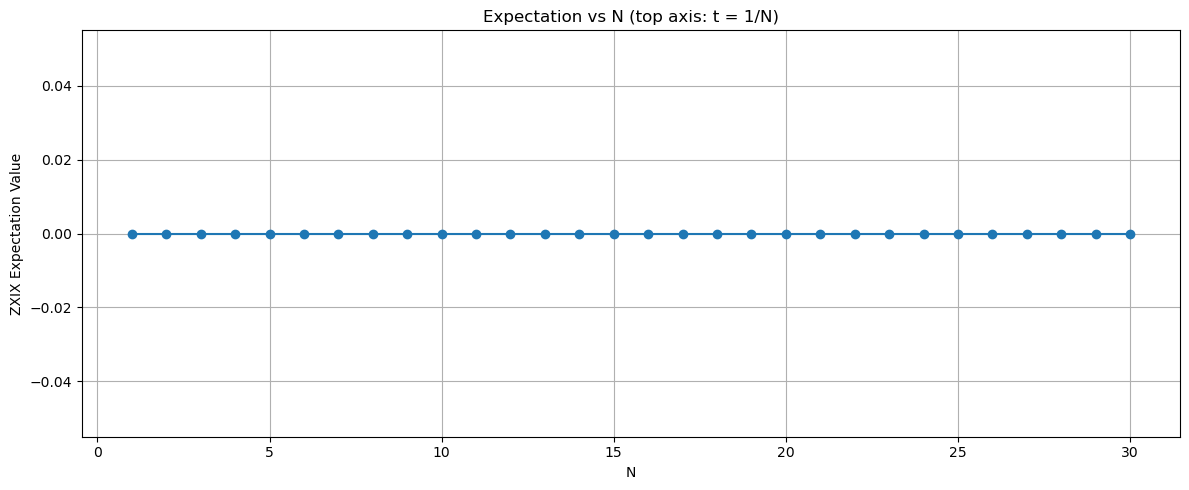

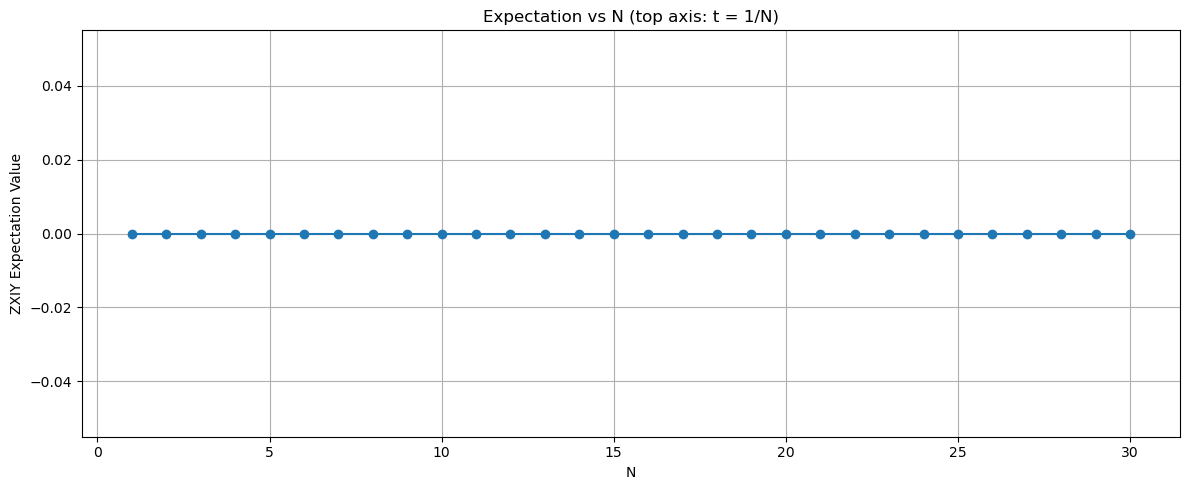

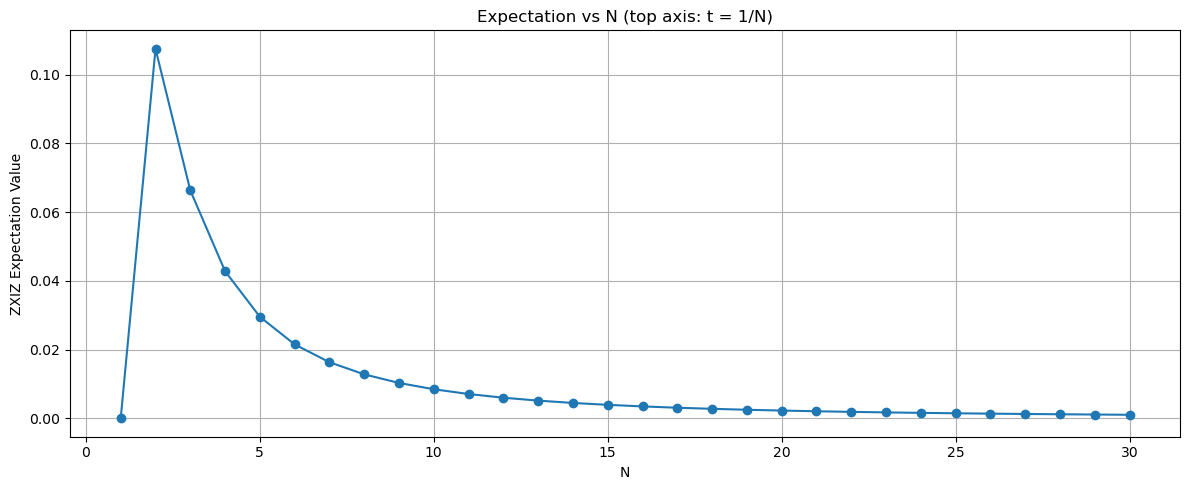

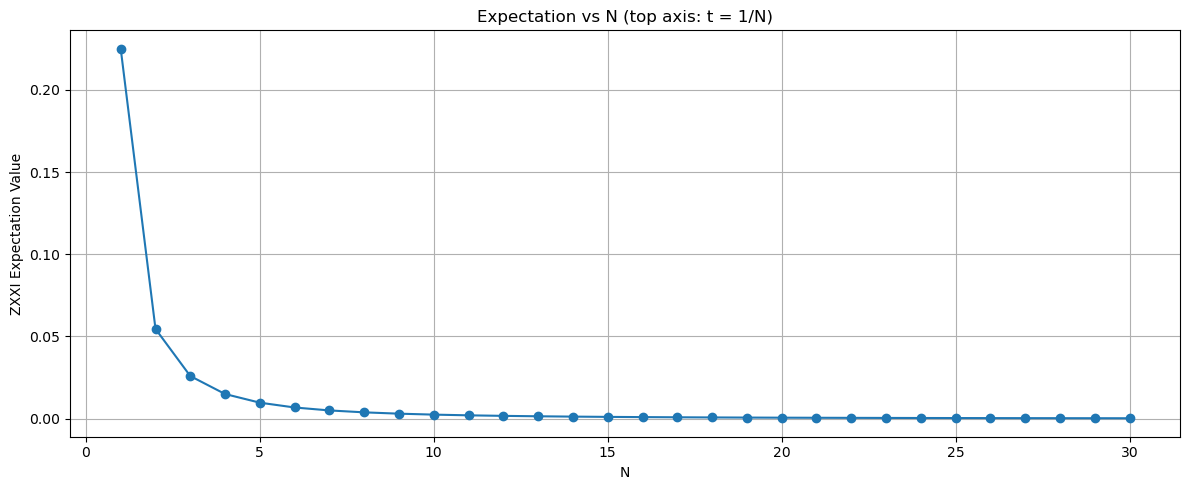

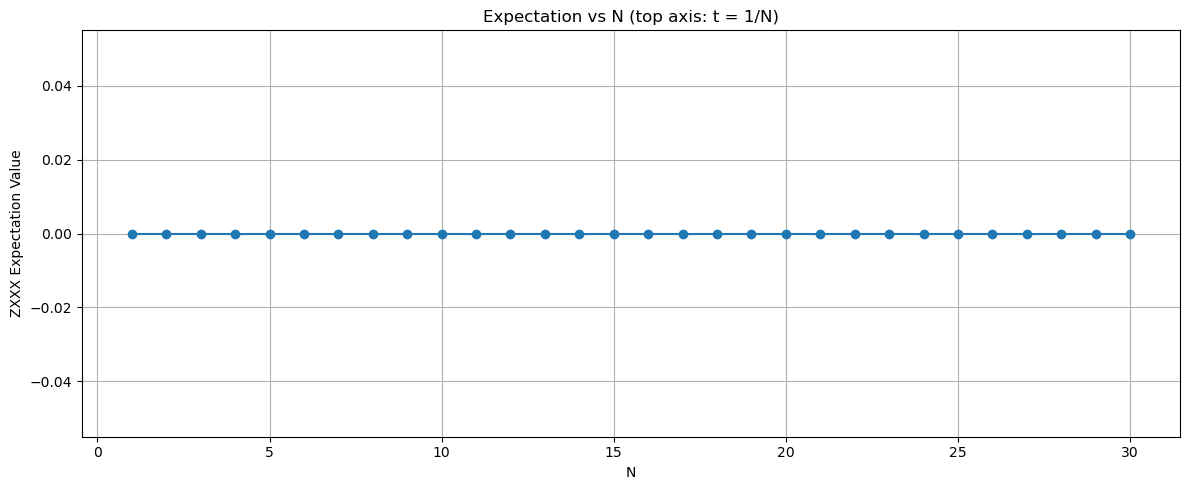

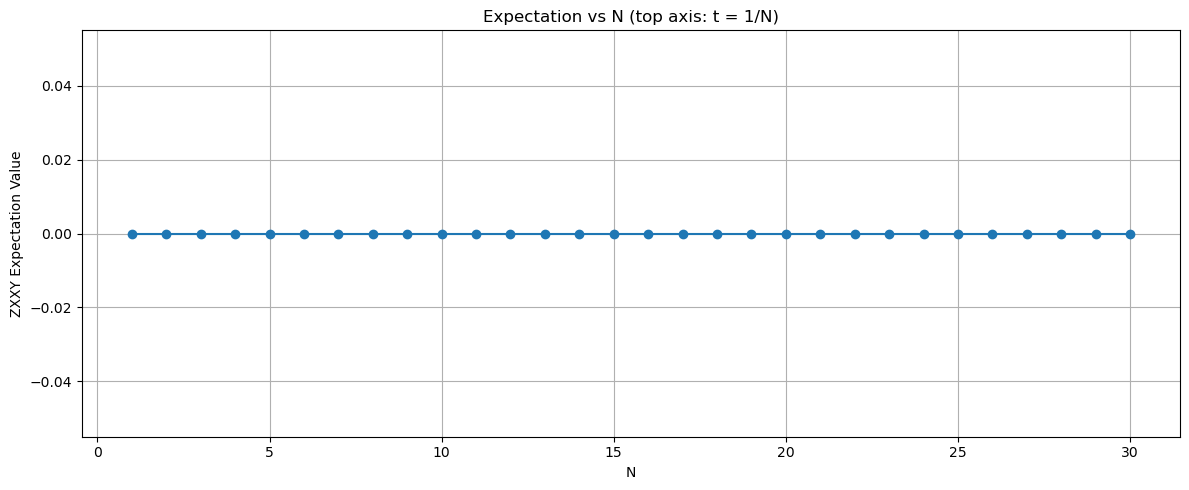

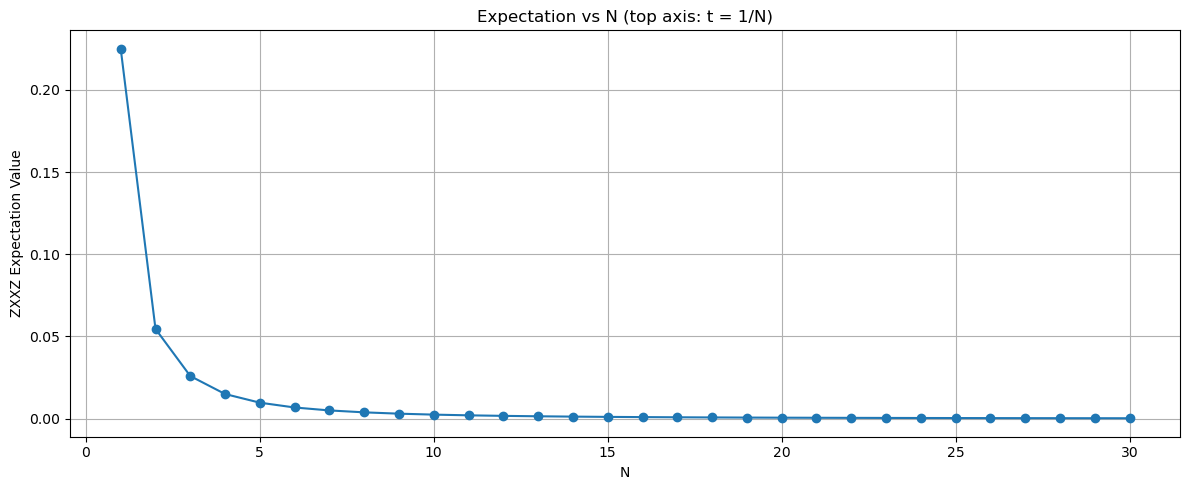

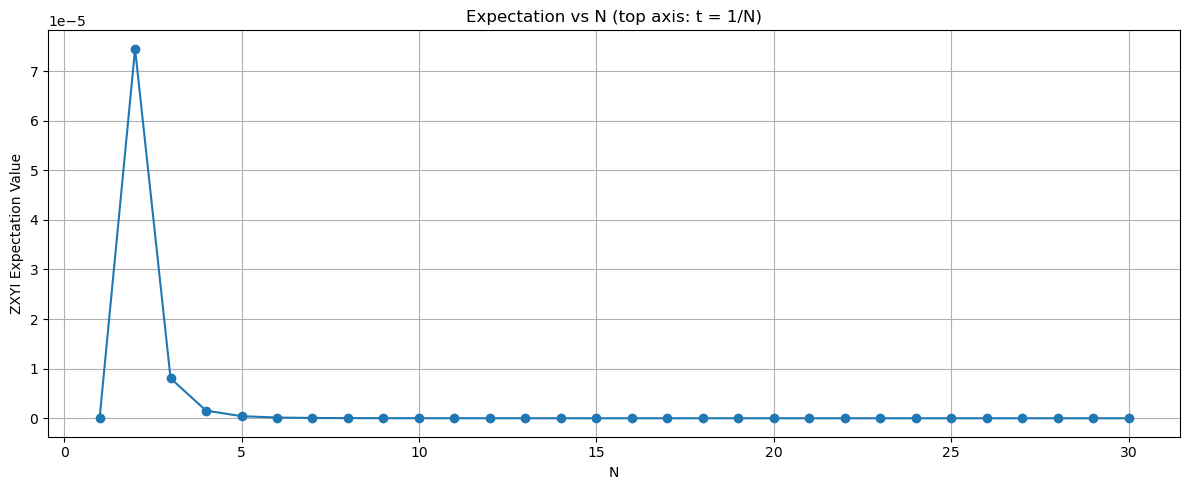

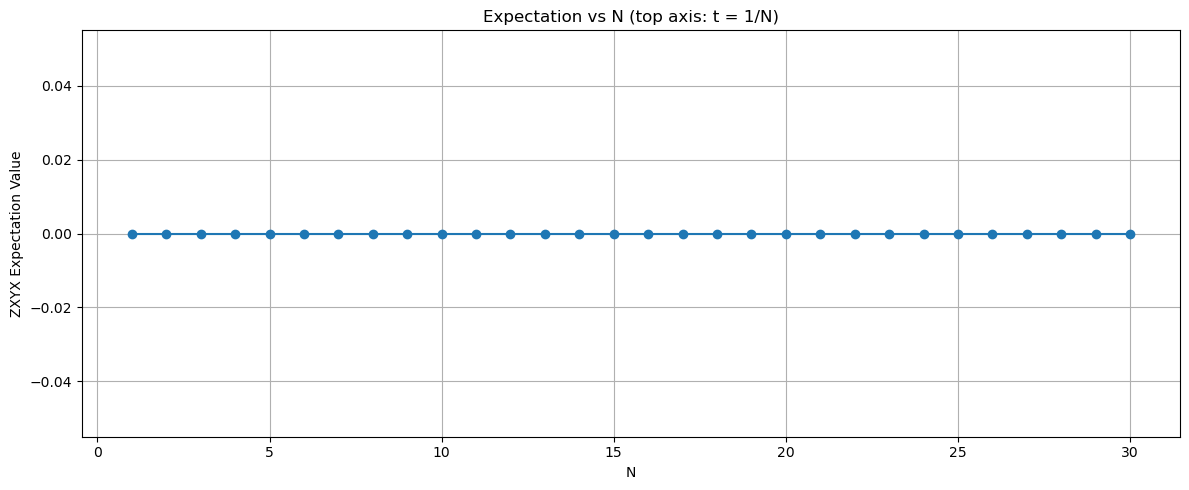

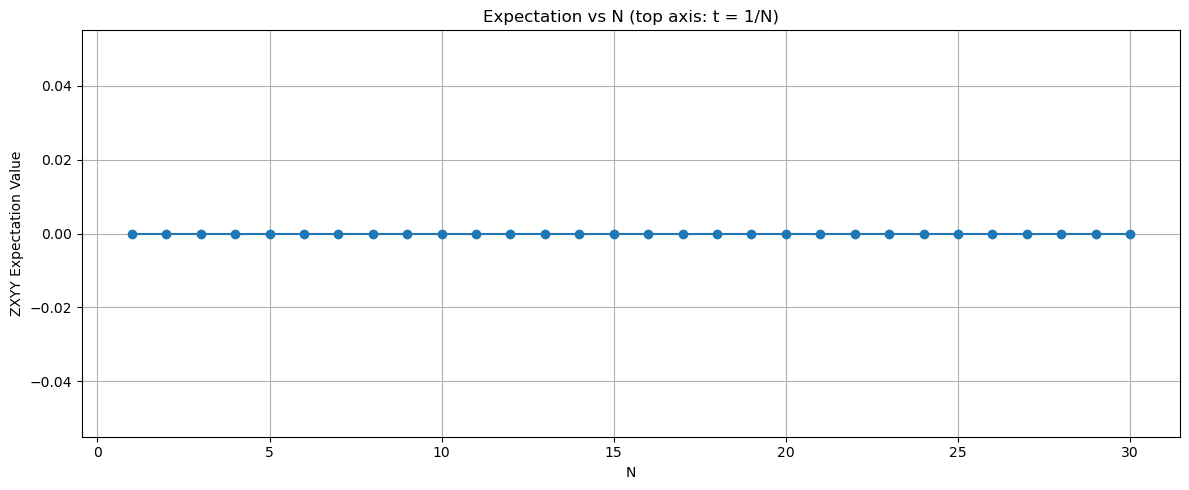

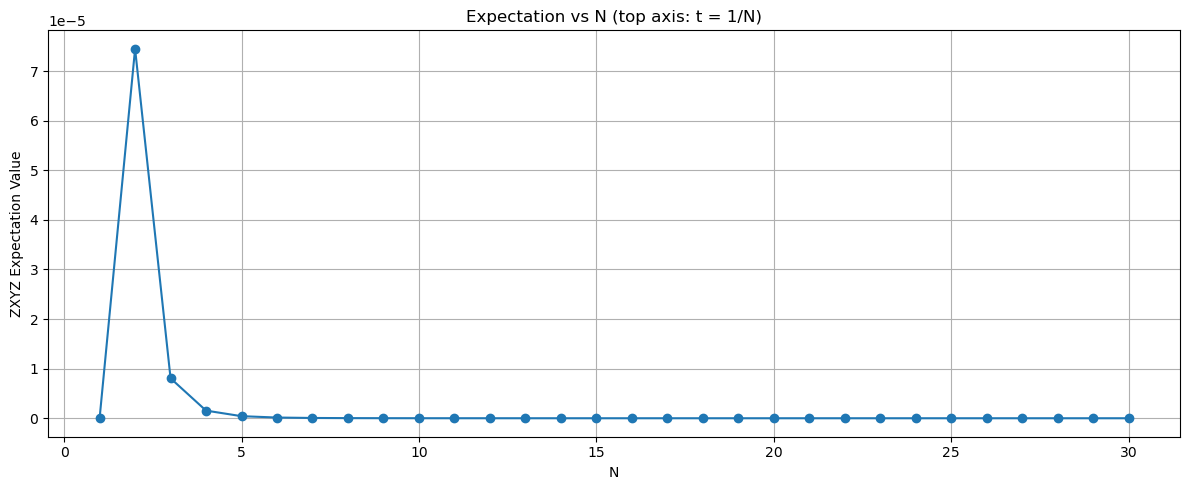

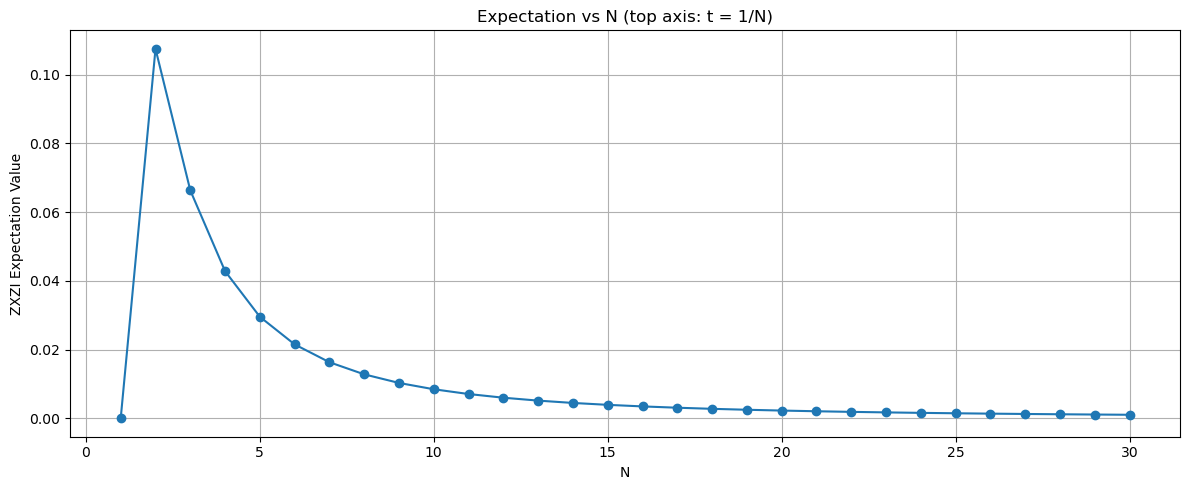

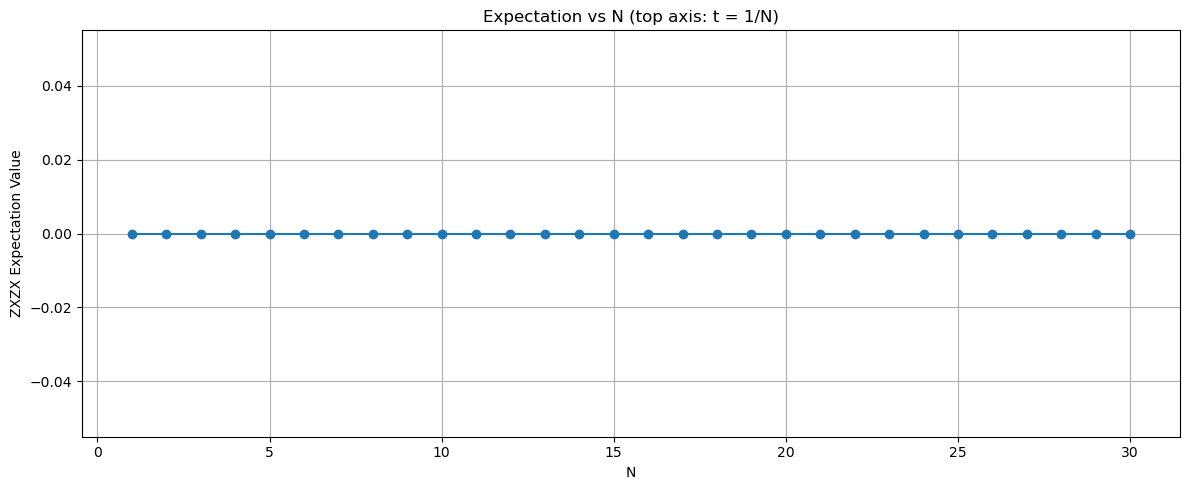

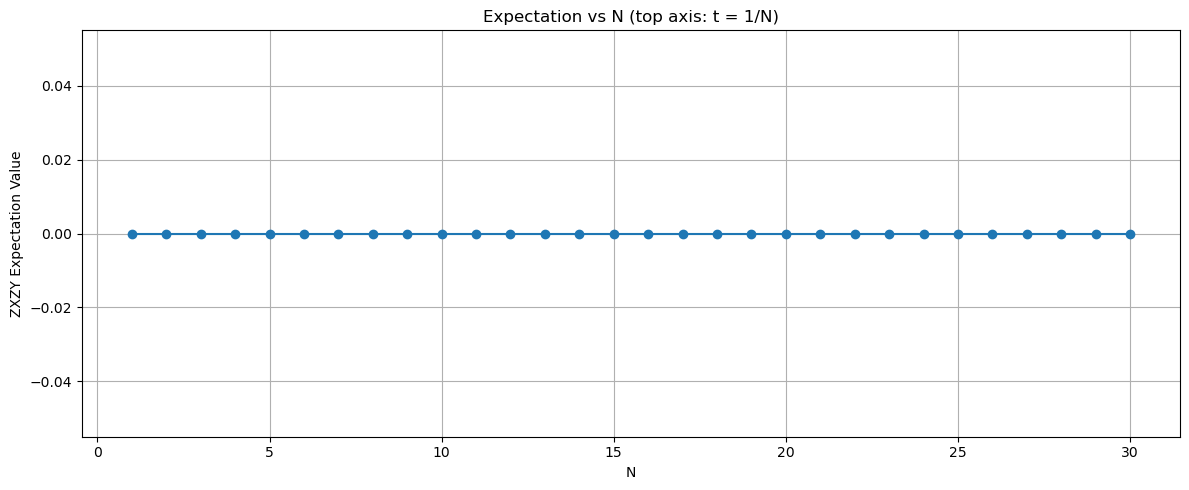

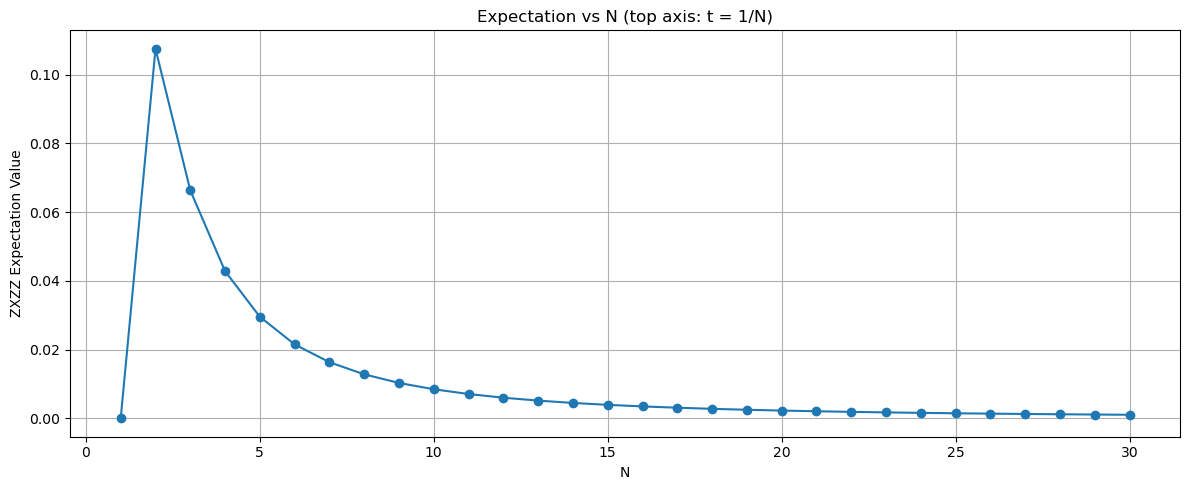

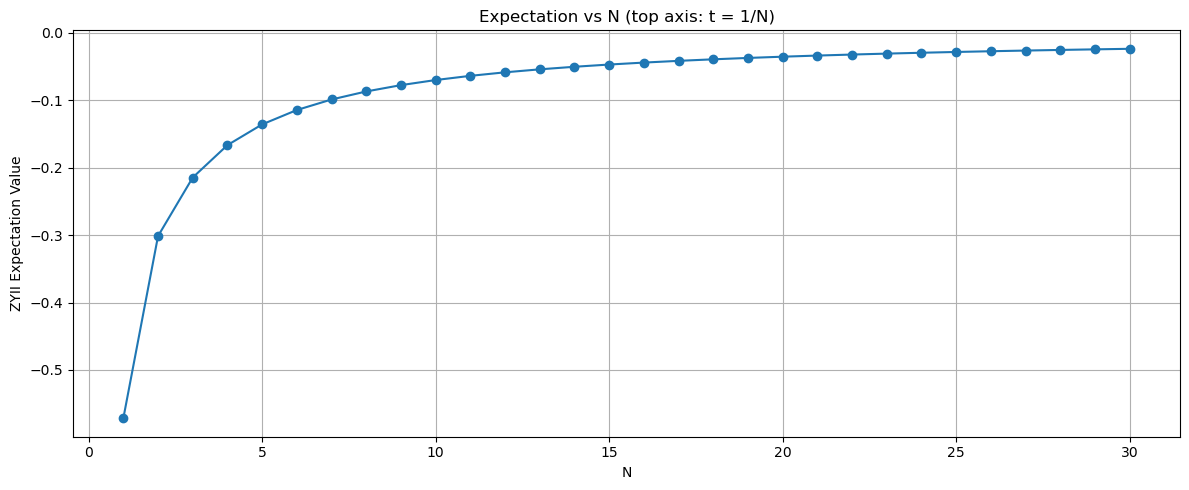

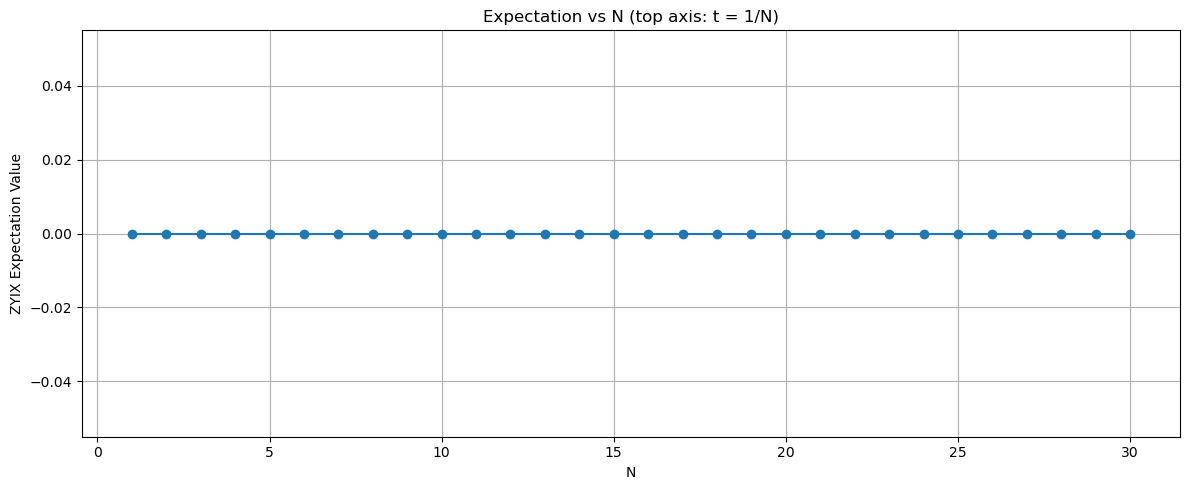

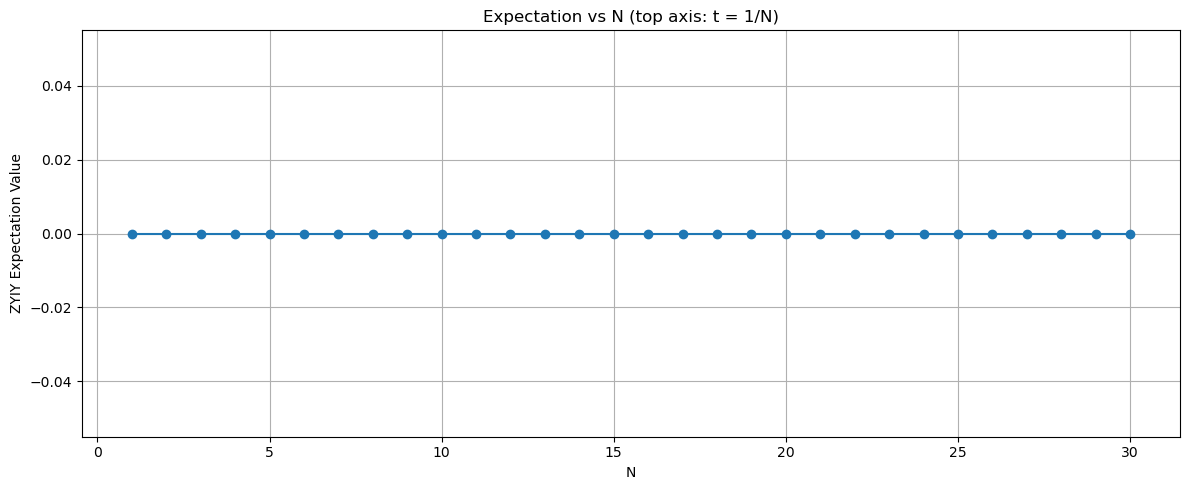

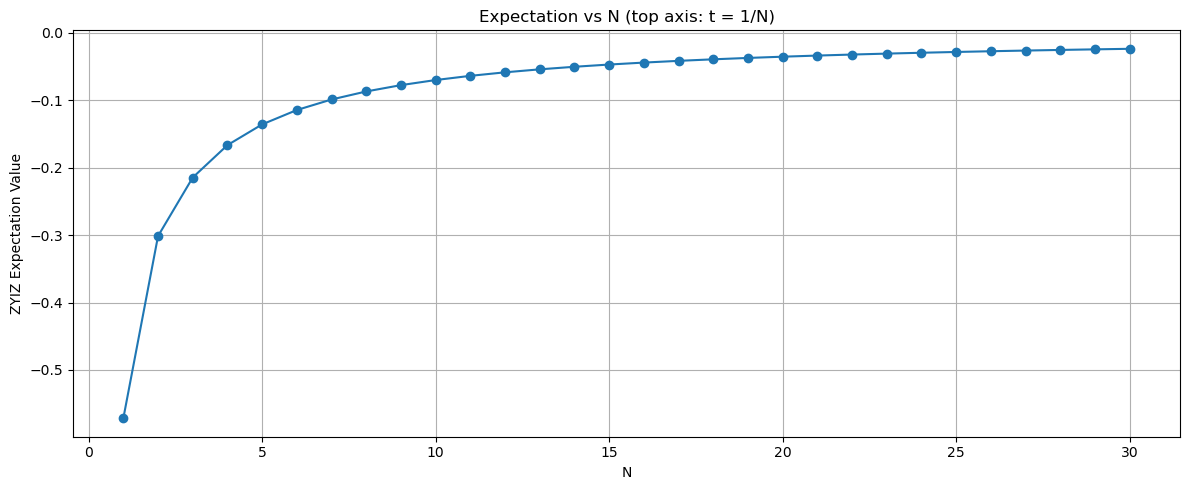

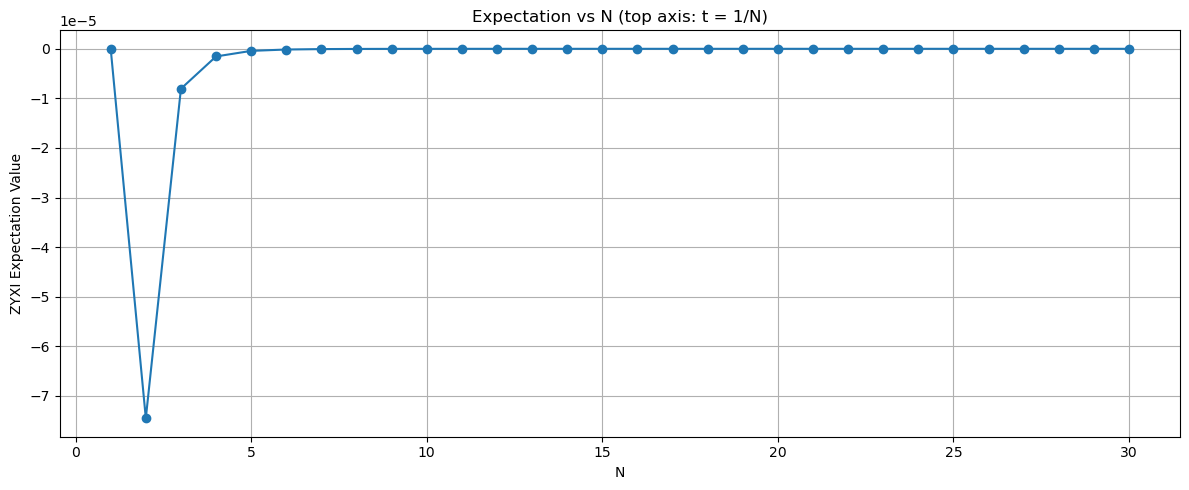

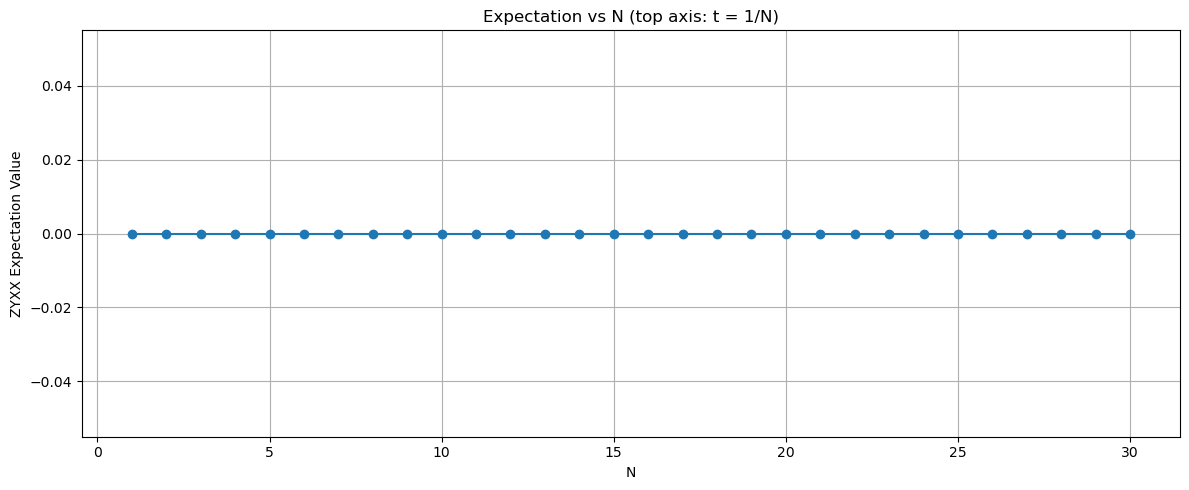

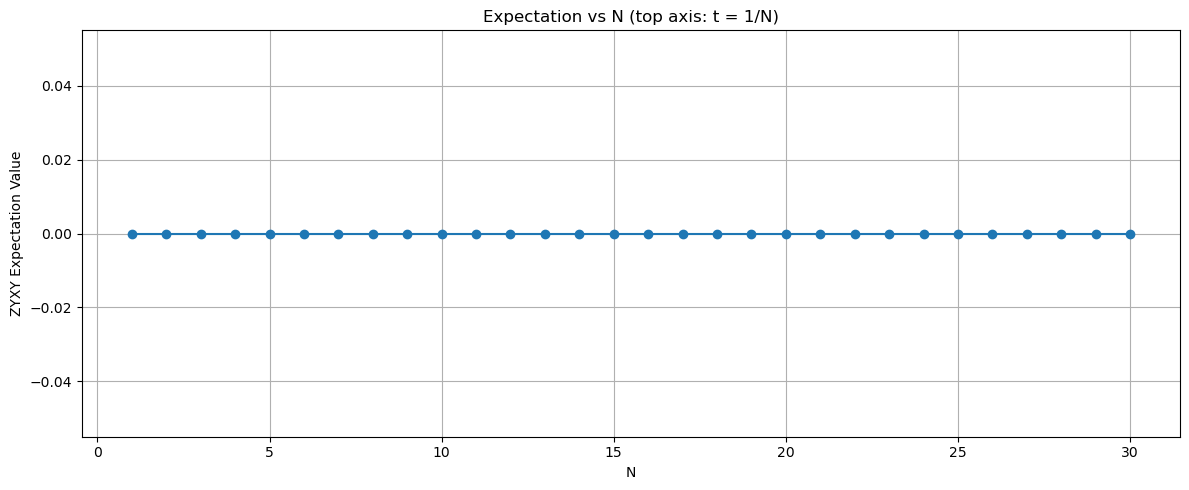

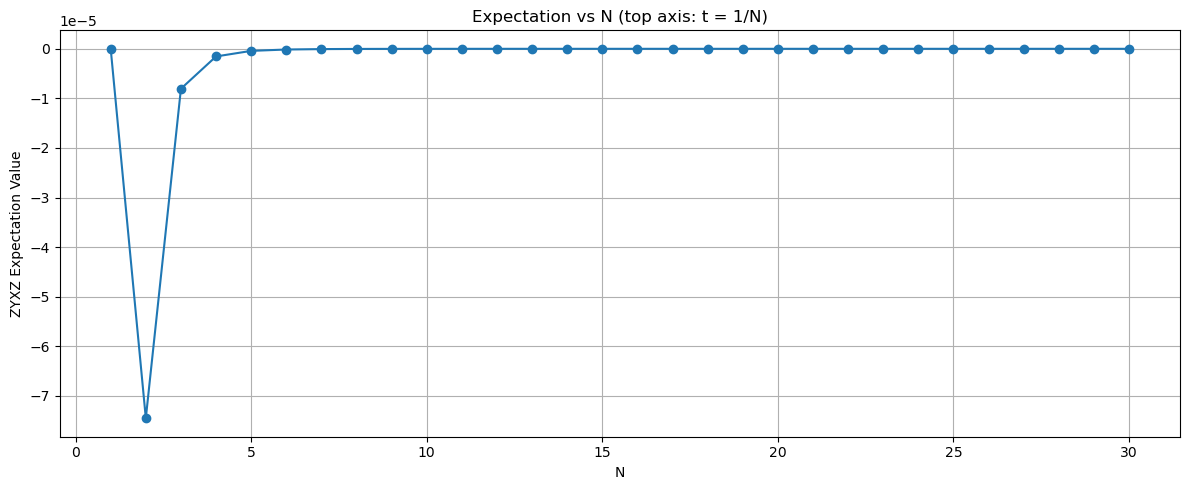

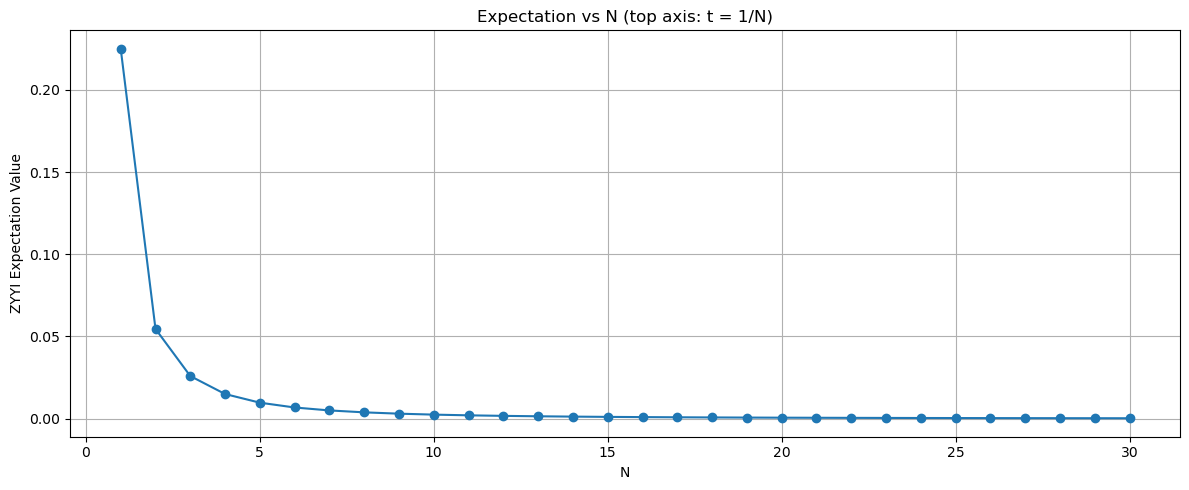

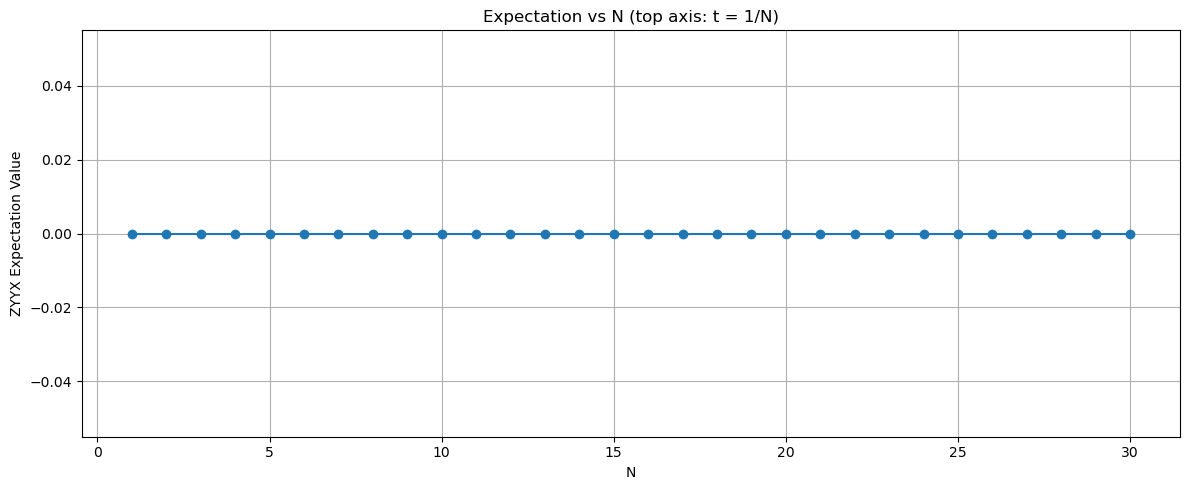

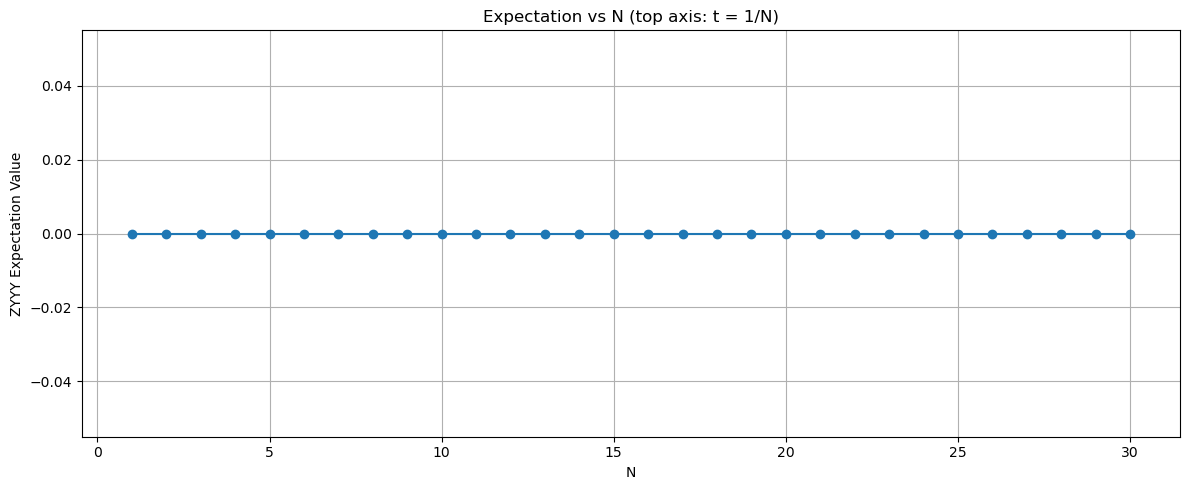

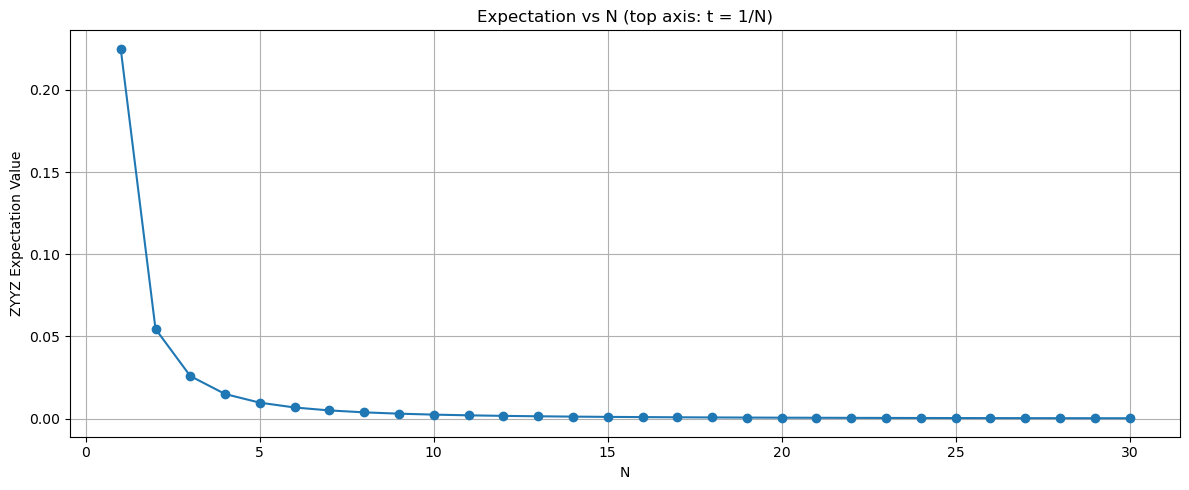

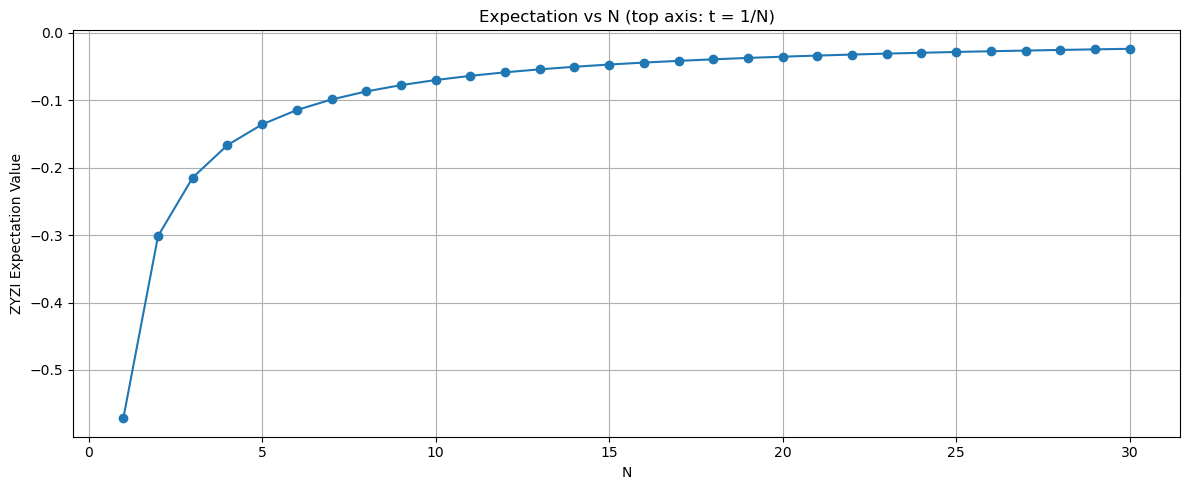

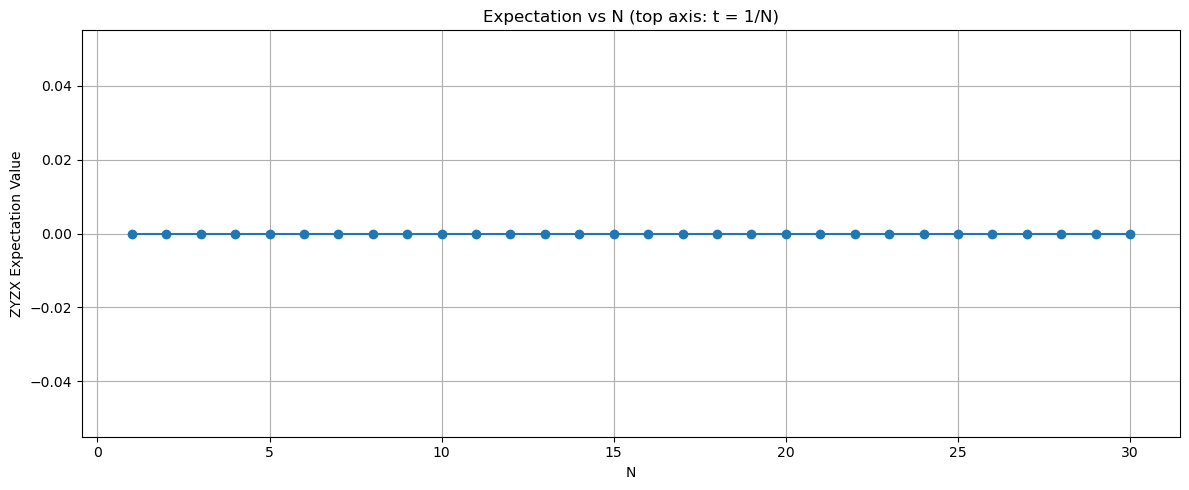

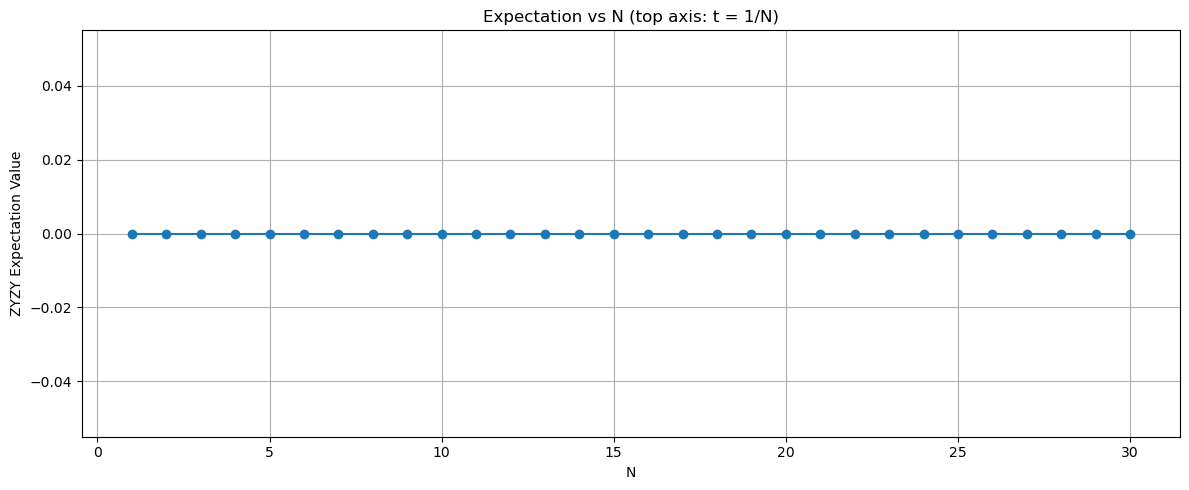

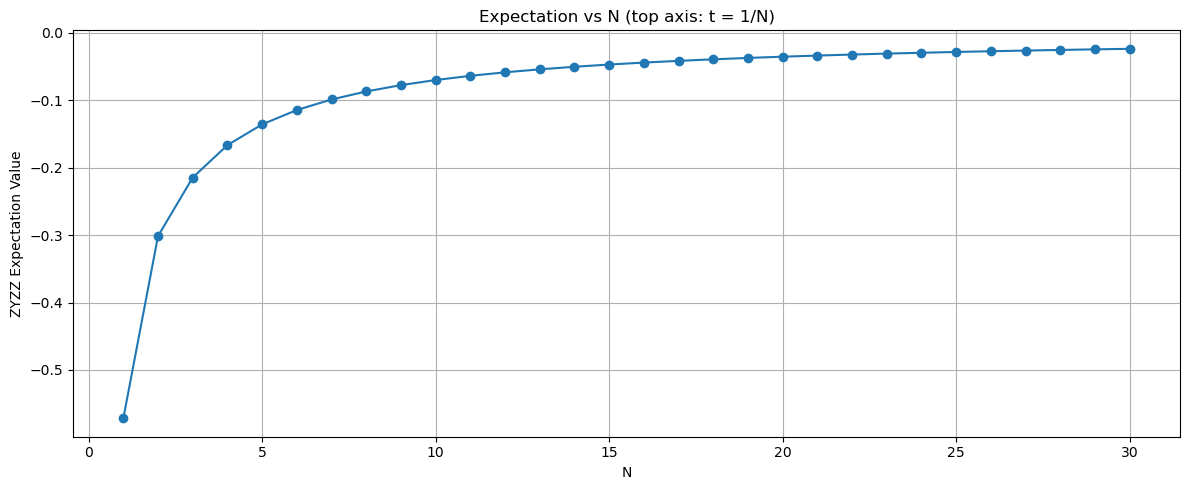

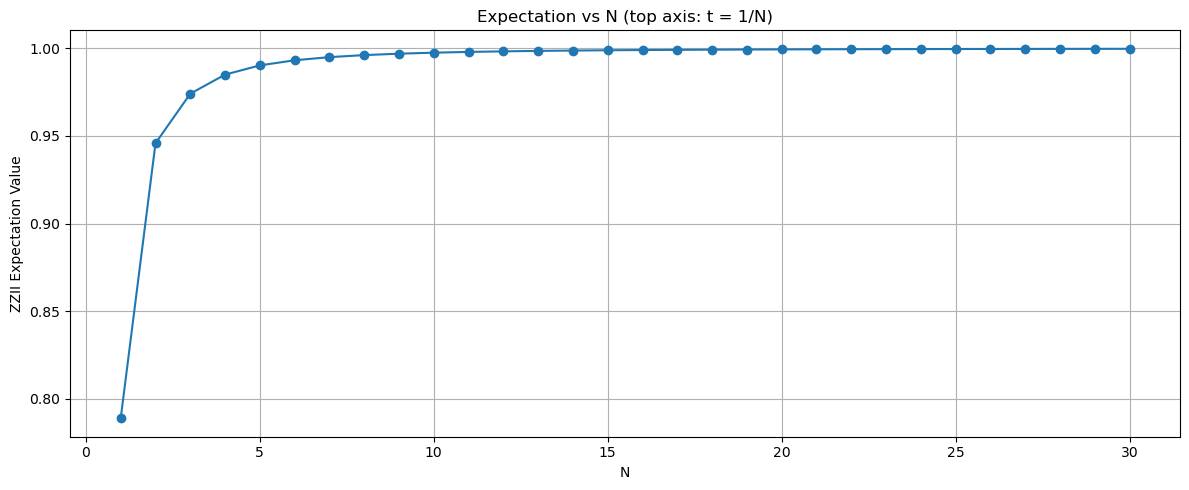

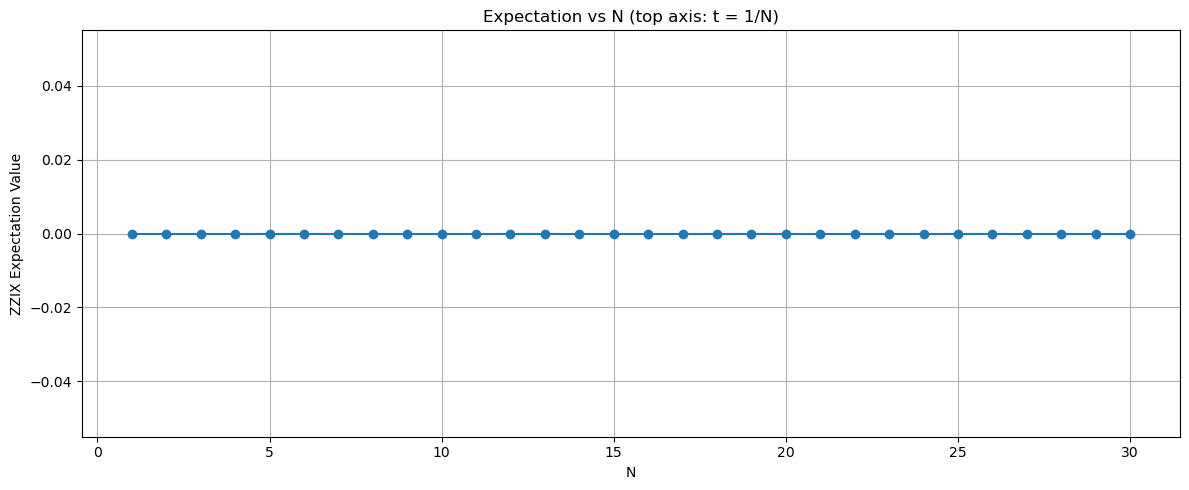

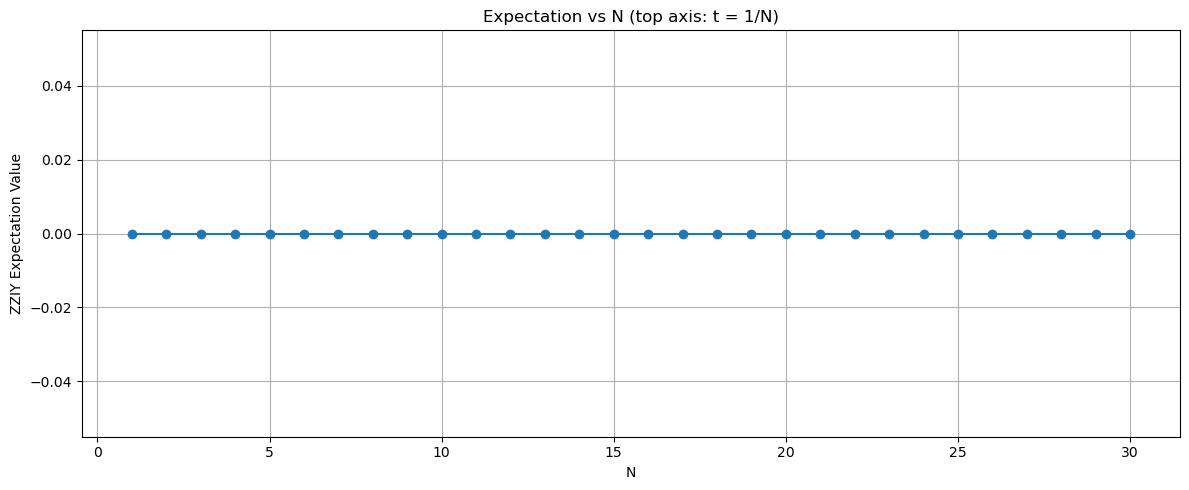

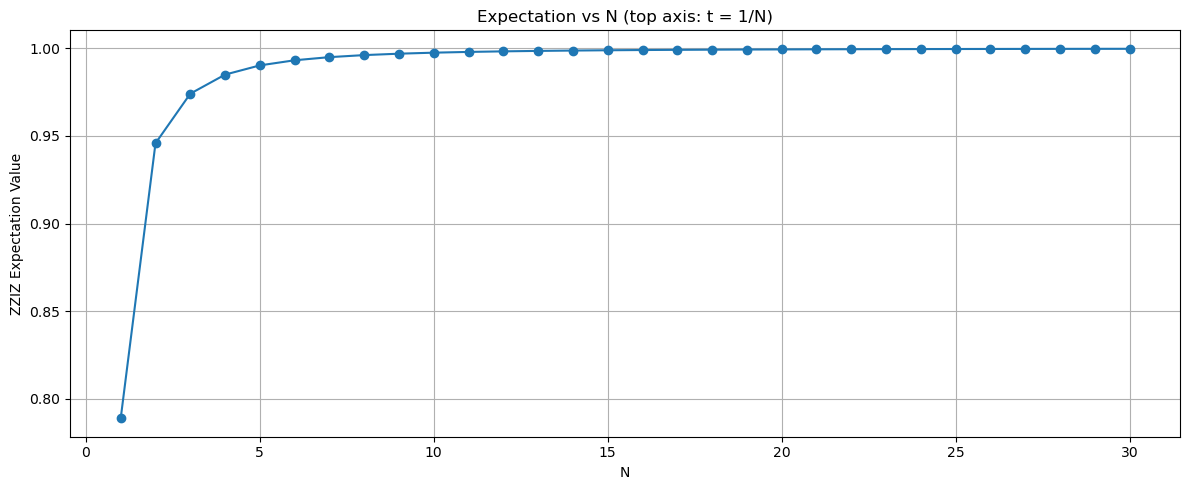

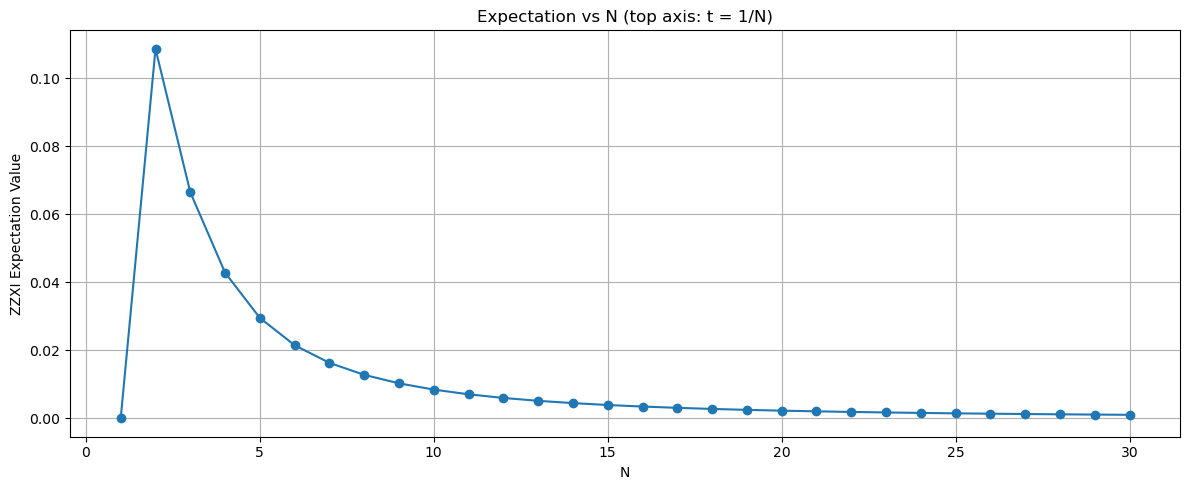

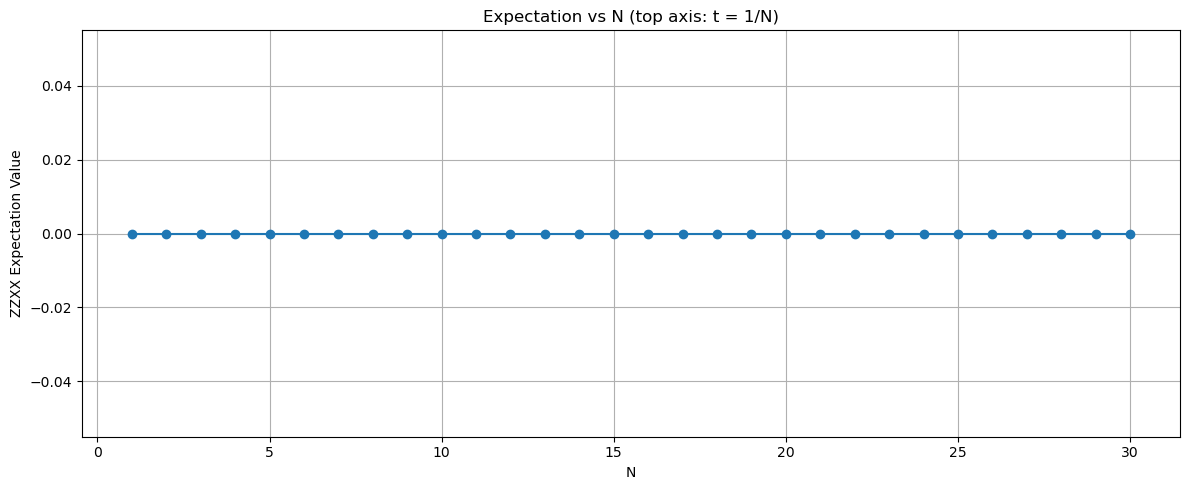

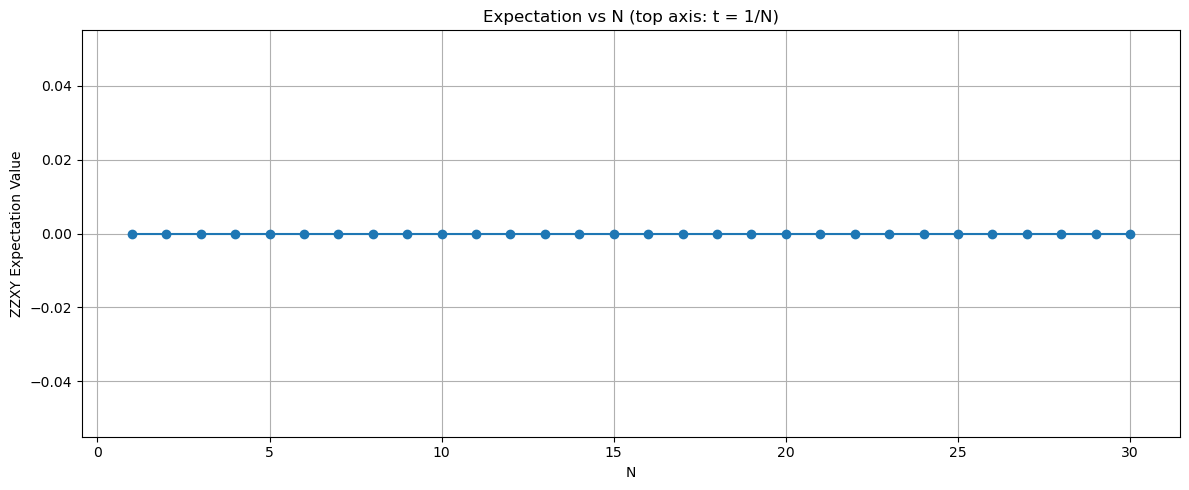

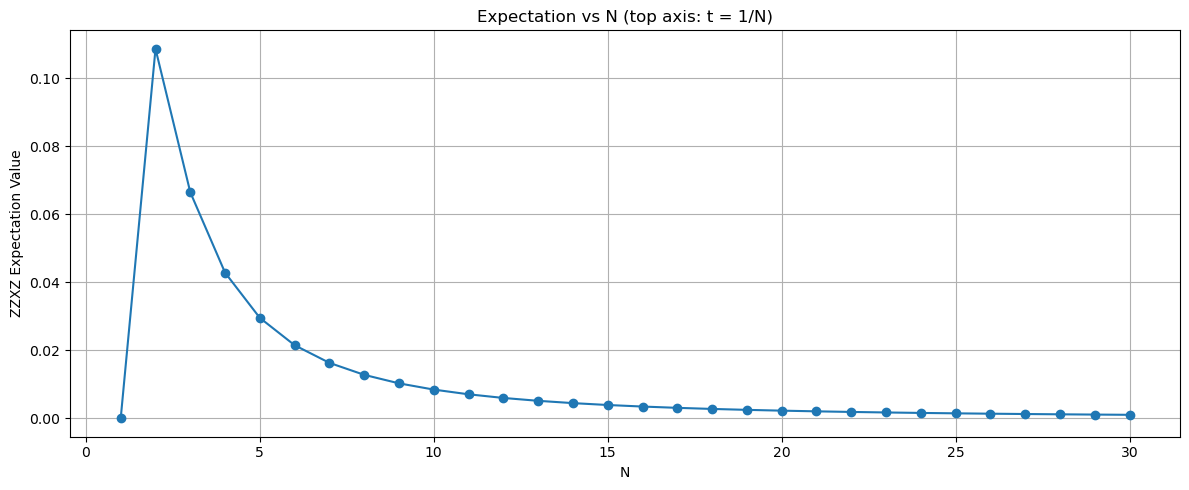

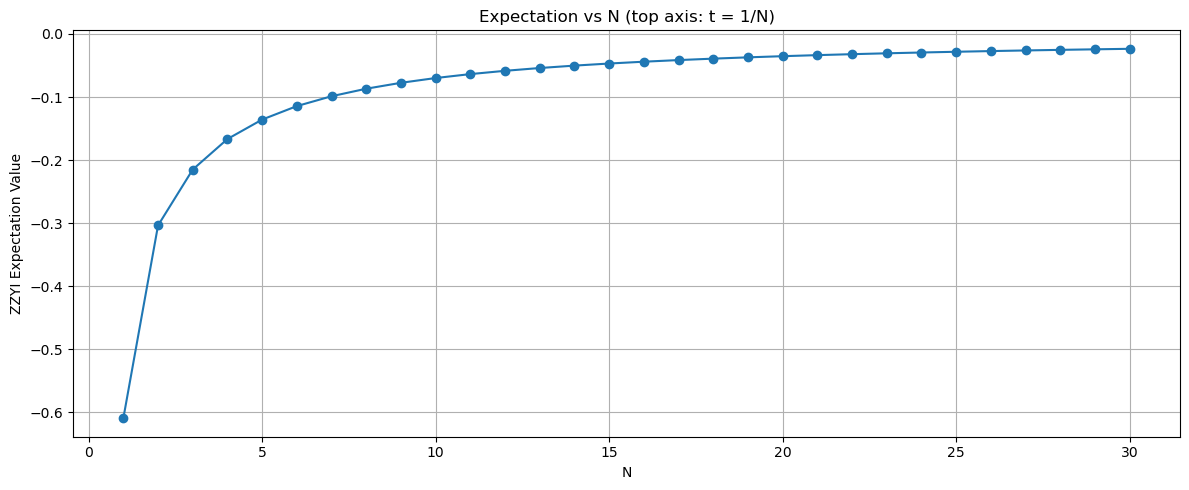

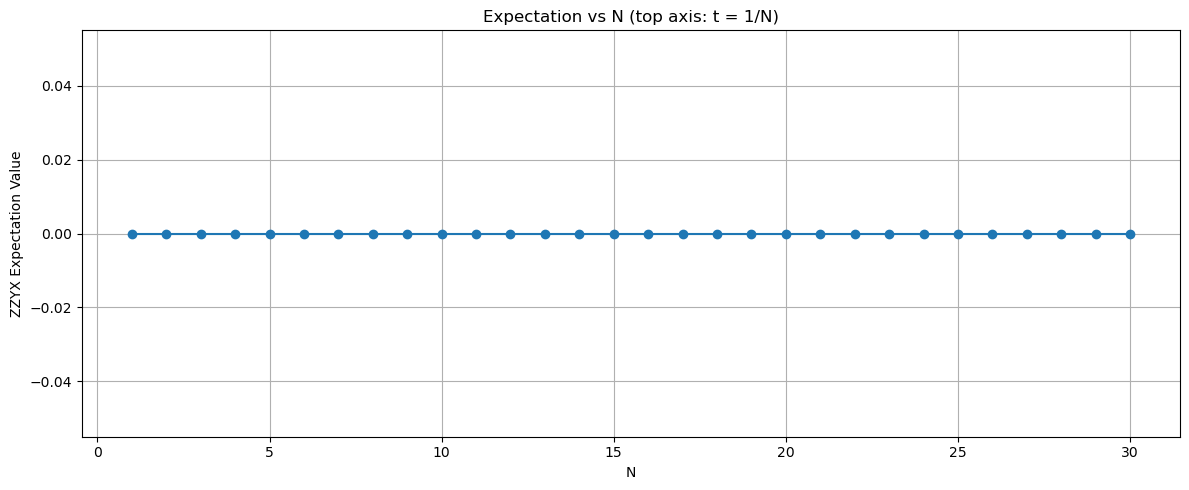

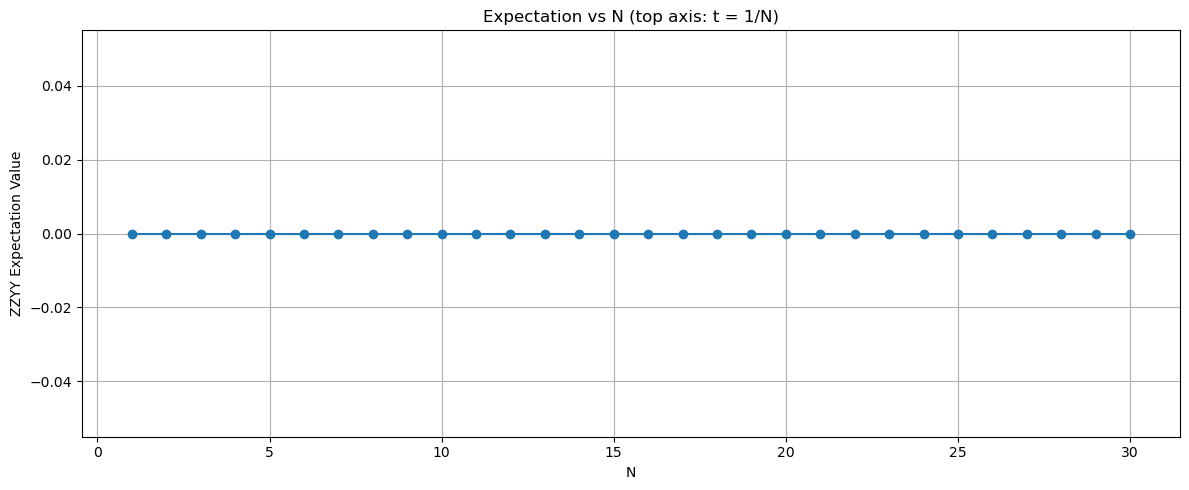

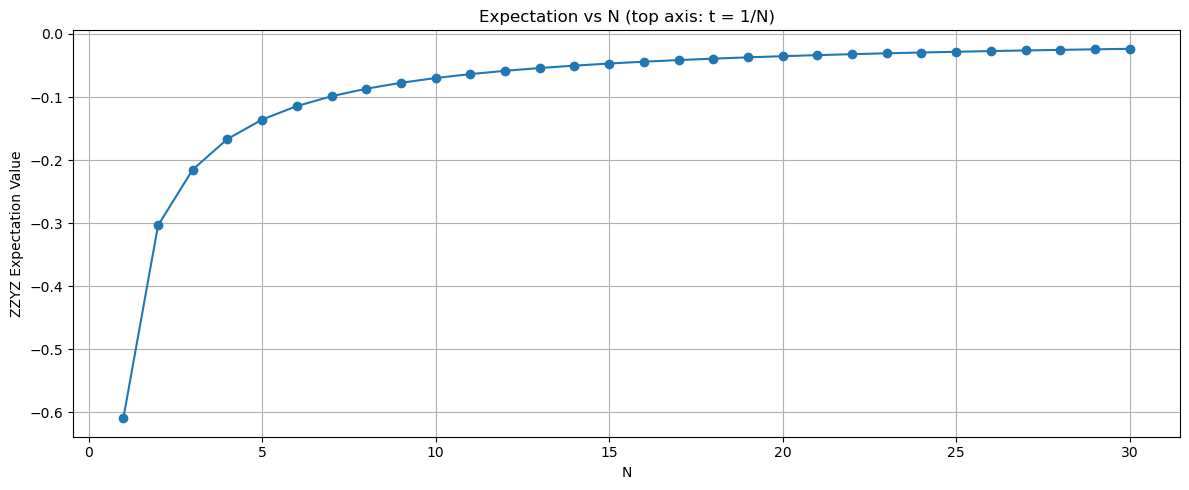

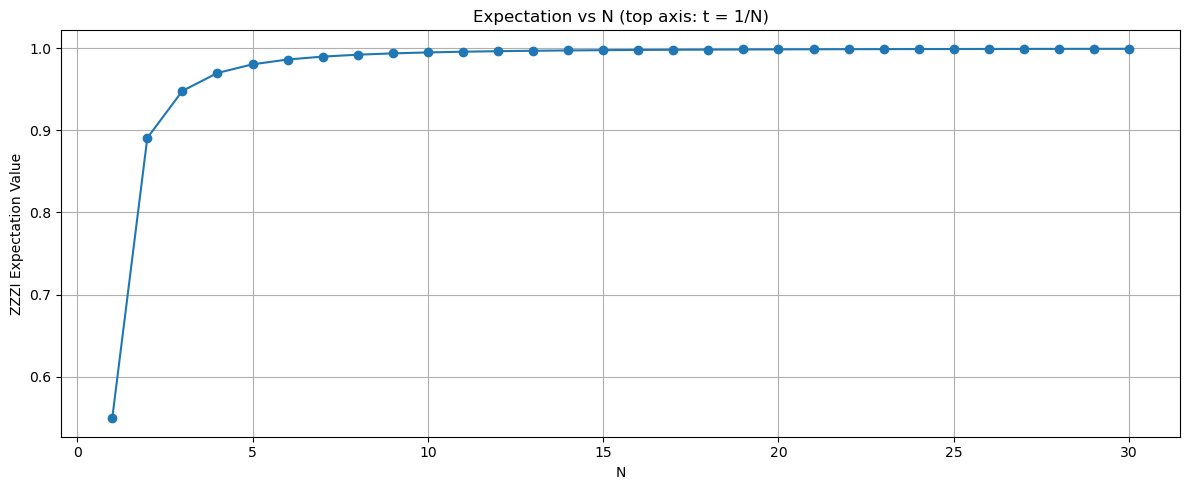

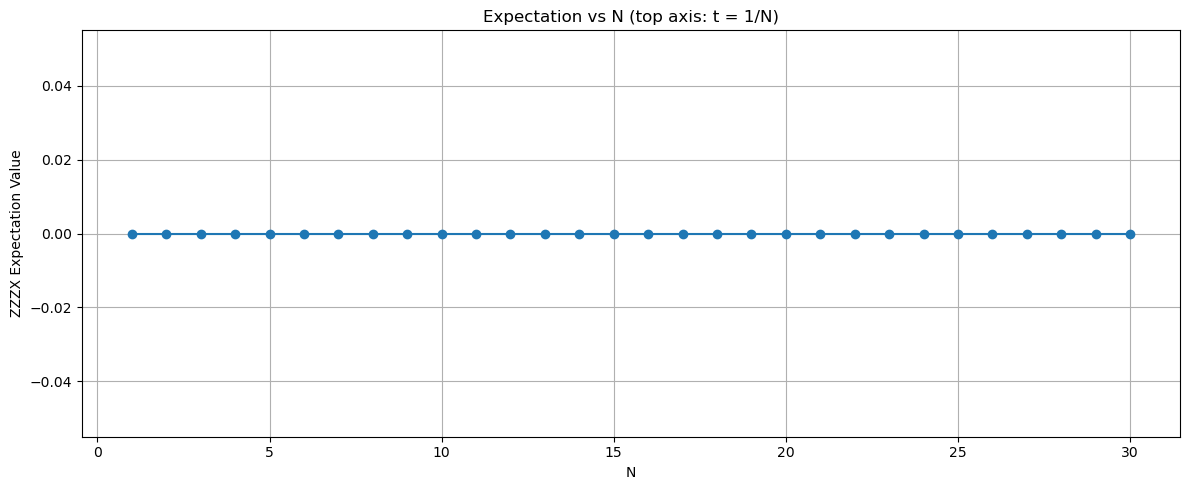

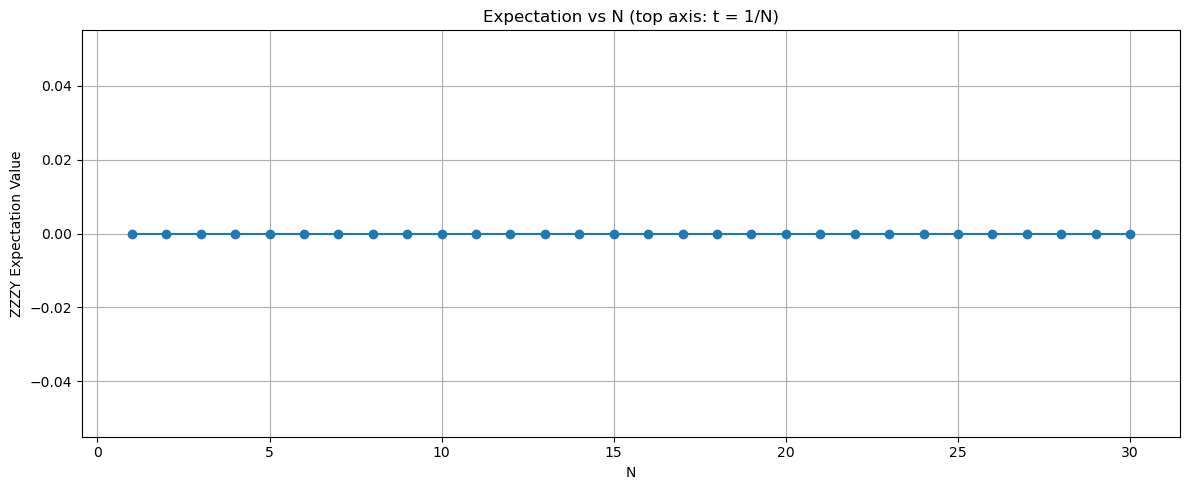

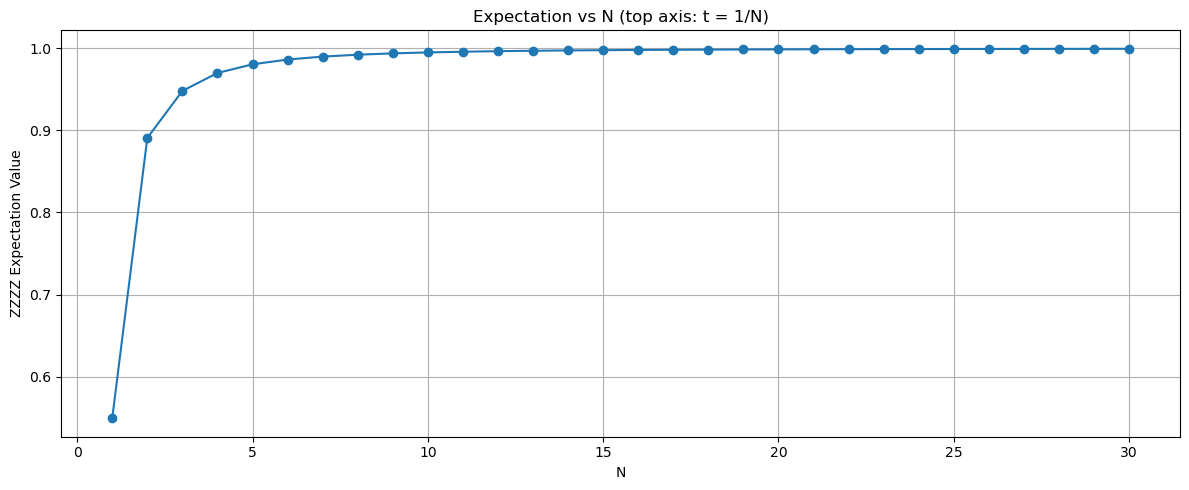

In [13]:
for observable in observables:
    exp_val_given_T_one_axis(N=30, observable=observable, save_fig=False)

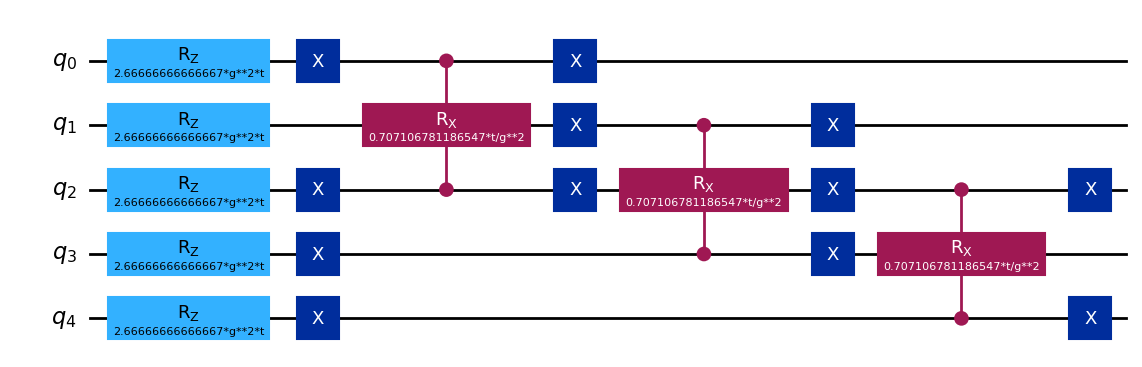

In [23]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step_new(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(theta_E/N, q)

    for i in range(1, n - 1):       
        qc.x(i - 1)
        qc.x(i + 1)
        
        controlled_rx = RXGate(theta_B/N).control(2)  # 2 control qubits
        qc.append(controlled_rx, [i - 1, i + 1, i])

        qc.x(i - 1)
        qc.x(i + 1)
        
    return qc

def N_steps_compose_new(n, N):
    one_step_circuit = one_step_new(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

n = 5
N = 1
circuit = N_steps_compose_new(n, N)
circuit.draw("mpl")

In [41]:
pauli_ops = ['I', 'X', 'Y', 'Z']
observables = [''.join(p) for p in itertools.product(pauli_ops, repeat=4)]
print(len(observables))

256


In [43]:
from matplotlib.backends.backend_pdf import PdfPages

with PdfPages("all_observables.pdf") as pdf:
    for observable in observables:
        fig = plt.figure(figsize=(12, 5))

        # your expectation value computation
        exp_vals = []
        N_s = np.arange(1, 31)
        t_s = 1.0 / N_s
        for t, N in zip(t_s, N_s):
            exp_val = plot_measurement_loop_one_observable(n=4, N=N, observable=observable, t=t)[1][0]
            exp_vals.append(exp_val)

        plt.plot(N_s, exp_vals, "o-")
        plt.xlabel("N")
        plt.ylabel(f"{observable} Expectation Value")
        plt.xticks(np.arange(0, 31, 5))
        plt.title(f"Expectation vs N (top axis: t = 1/N) for {observable}")
        plt.grid(True)
        plt.tight_layout()

        pdf.savefig(fig)  # Save current figure into PDF
        plt.close(fig)    # Close the figure to free memory

error: Error -2 while flushing: inconsistent stream state

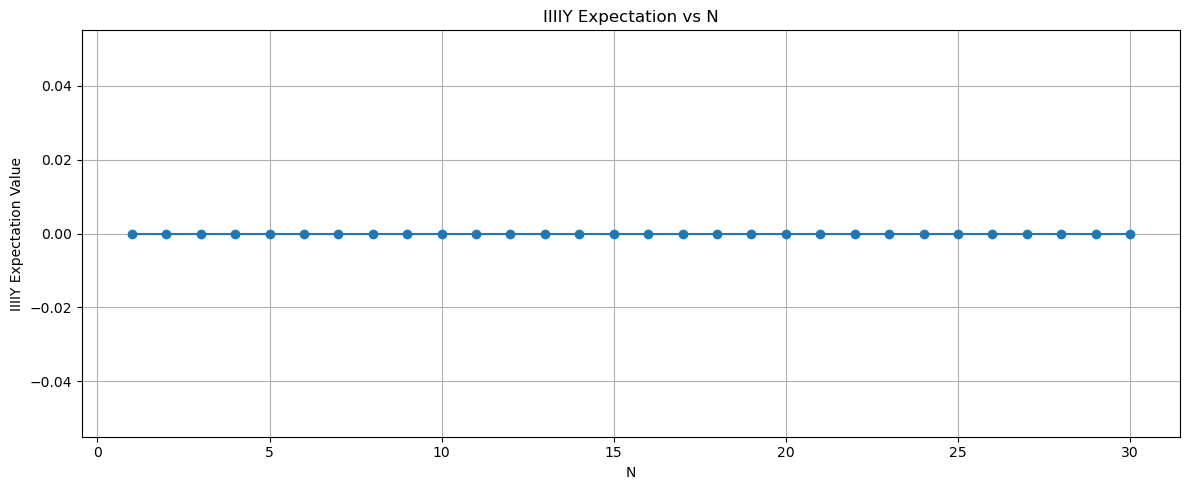

In [49]:
group_size = 400
n = 5

pauli_ops = ['I', 'X', 'Y', 'Z']
observables = [''.join(p) for p in itertools.product(pauli_ops, repeat=5)]

for i in range(0, len(observables), group_size):
    
    chunk = observables[i:i+group_size]
    with PdfPages(f"{n}_qubit_observables_part_{i//group_size + 1}.pdf") as pdf:
        for observable in chunk:
            fig = plt.figure(figsize=(12, 5))
            N_s = np.arange(1, 31)
            t_s = 1.0 / N_s
            exp_vals = [plot_measurement_loop_one_observable(n, N, observable, t)[1][0]
                        for t, N in zip(t_s, N_s)]
            plt.plot(N_s, exp_vals, "o-")
            plt.xlabel("N")
            plt.ylabel(f"{observable} Expectation Value")
            plt.title(f"{observable} Expectation vs N")
            plt.xticks(np.arange(0, 31, 5))
            plt.grid(True)
            plt.tight_layout()
            pdf.savefig(fig)
            plt.close(fig)